# Задание 1. Загрузка подготовленного датасета и проверка непрерывности ML-пайплайна

### Цель работы

Загрузить предварительно обработанный набор данных из практической работы №1, проверить его структуру и качество, определить доступные признаки и подготовить основу для дальнейшего сравнительного исследования классических моделей машинного обучения.

### Постановка задачи

В качестве исходных данных используется временной ряд среднесуточной температуры воздуха в Москве за 2024–2025 годы.

Целевая переменная — `temperature_2m_mean`.

Необходимо выполнить следующие действия:

1. Создать структуру проекта `Practika_4`.
2. Найти и загрузить подготовленный датасет из практической работы №1.
3. Проверить количество наблюдений и признаков.
4. Определить столбец даты и целевую переменную.
5. Проверить типы данных, пропуски и повторяющиеся даты.
6. Проверить хронологический порядок наблюдений и непрерывность дневного временного ряда.
7. Определить группы сконструированных признаков: лаговые, скользящие, календарные и производные.
8. Проверить наличие сохранённого препроцессора и параметров преобразований из первой практической работы.
9. Выявить потенциально опасные признаки, которые могут содержать информацию о текущем или будущем значении целевой переменной.
10. Сформировать паспорт исходного датасета и сохранить результаты проверки.

### Методика выполнения

Для загрузки и анализа данных используются библиотеки `pandas`, `numpy` и стандартные средства Python.

Временной ряд рассматривается как последовательность наблюдений с дневной частотой. При дальнейшей разработке моделей необходимо сохранять хронологический порядок данных и исключать использование будущих значений целевой переменной.

На данном этапе проводится предварительный аудит признаков. Окончательное решение об их допустимости принимается при формализации задачи прогнозирования и проверке отсутствия утечек.

### Ожидаемый результат

Создана структура проекта `Practika_4`.

Загружен и проверен исходный датасет.

Сформированы файлы:

- `data/task1_dataset.csv` — копия исходного обработанного датасета.
- `reports/task1/dataset_profile.csv` — информация о столбцах.
- `reports/task1/feature_groups.csv` — классификация признаков.
- `reports/task1/data_quality.json` — результаты проверки качества.
- `reports/task1/dataset_metadata.json` — описание датасета и его происхождения.
- `reports/task1/preprocessor_inventory.csv` — перечень найденных артефактов предобработки.

Полученные результаты используются в задании 2 для формализации задачи машинного обучения.

In [1]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 1. ЗАГРУЗКА И АУДИТ ДАТАСЕТА
# ============================================================

from pathlib import Path
from datetime import datetime
from collections import Counter
import json
import re
import shutil

import numpy as np
import pandas as pd

# ============================================================
# 1. НАСТРОЙКИ ПРОЕКТА
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"

SOURCE_PROJECT = ROOT / "Practika_1"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task1"
MODEL_DIR = PROJECT / "models"
TEST_DIR = PROJECT / "tests"
CONFIG_DIR = PROJECT / "config"

for directory in [
    PROJECT,
    DATA_DIR,
    REPORT_DIR,
    MODEL_DIR,
    TEST_DIR,
    CONFIG_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

TARGET = "temperature_2m_mean"

# Если нужен конкретный файл, укажи путь здесь.
# Например:
# CUSTOM_DATASET_PATH = SOURCE_PROJECT / "data" / "features_dataset.csv"

CUSTOM_DATASET_PATH = None

# ============================================================
# 2. ПОИСК ИСХОДНОГО ДАТАСЕТА
# ============================================================

candidates = [
    SOURCE_PROJECT / "data" / "features_dataset.csv",
    SOURCE_PROJECT / "data" / "processed_dataset.csv",
    SOURCE_PROJECT / "data" / "prepared_dataset.csv",
    SOURCE_PROJECT / "data" / "dataset.csv",
    SOURCE_PROJECT / "features_dataset.csv",
    SOURCE_PROJECT / "processed_dataset.csv"
]

if CUSTOM_DATASET_PATH is not None:
    dataset_path = Path(CUSTOM_DATASET_PATH)
else:
    dataset_path = next(
        (path for path in candidates if path.is_file()),
        None
    )

if dataset_path is None:
    raise FileNotFoundError(
        "Не найден подготовленный датасет в Practika_1. "
        "Укажи путь в CUSTOM_DATASET_PATH."
    )

print("=" * 80)
print("1. ИСХОДНЫЙ ДАТАСЕТ")
print("=" * 80)

print("Источник:", dataset_path)
print(
    "Размер файла:",
    round(dataset_path.stat().st_size / 1024**2, 2),
    "МБ"
)

# ============================================================
# 3. ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv(
    dataset_path,
    low_memory=False
)

print("\nРазмерность:", df.shape)

print("\nПервые 5 строк:")
display(df.head())

print("\nТипы данных:")
print(df.dtypes.value_counts())

# ============================================================
# 4. ОПРЕДЕЛЕНИЕ ДАТЫ
# ============================================================

date_candidates = [
    "date",
    "timestamp",
    "time",
    "datetime"
]

DATE_COL = next(
    (col for col in date_candidates if col in df.columns),
    None
)

if DATE_COL is None:
    raise ValueError(
        "Не найден столбец даты. "
        f"Доступные столбцы: {list(df.columns[:20])}"
    )

if TARGET not in df.columns:
    raise ValueError(
        f"Не найдена целевая переменная: {TARGET}"
    )

df[DATE_COL] = pd.to_datetime(
    df[DATE_COL],
    errors="coerce",
    utc=True
).dt.tz_convert(None)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="coerce"
)

print("\nСтолбец даты:", DATE_COL)
print("Целевая переменная:", TARGET)

# ============================================================
# 5. ПРОВЕРКА КАЧЕСТВА
# ============================================================

rows = len(df)
columns = len(df.columns)

missing_by_column = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_total = int(df.isna().sum().sum())

missing_target = int(
    df[TARGET].isna().sum()
)

missing_dates = int(
    df[DATE_COL].isna().sum()
)

duplicate_dates = int(
    df[DATE_COL].duplicated().sum()
)

is_sorted = bool(
    df[DATE_COL].is_monotonic_increasing
)

valid_dates = (
    df[DATE_COL]
    .dropna()
    .sort_values()
    .drop_duplicates()
)

if len(valid_dates) > 0:
    date_min = valid_dates.min()
    date_max = valid_dates.max()

    expected_dates = pd.date_range(
        date_min,
        date_max,
        freq="D"
    )

    missing_calendar_dates = (
        expected_dates.difference(
            pd.DatetimeIndex(valid_dates)
        )
    )

else:
    date_min = None
    date_max = None
    missing_calendar_dates = []

quality = {
    "rows": rows,
    "columns": columns,
    "date_column": DATE_COL,
    "target_column": TARGET,
    "date_min": str(date_min),
    "date_max": str(date_max),
    "missing_total": missing_total,
    "missing_target": missing_target,
    "missing_dates": missing_dates,
    "duplicate_dates": duplicate_dates,
    "is_sorted": is_sorted,
    "missing_calendar_days": len(
        missing_calendar_dates
    ),
    "minimum_720_observations": rows >= 720,
    "target_min": (
        float(df[TARGET].min())
        if df[TARGET].notna().any()
        else None
    ),
    "target_max": (
        float(df[TARGET].max())
        if df[TARGET].notna().any()
        else None
    ),
    "target_mean": (
        float(df[TARGET].mean())
        if df[TARGET].notna().any()
        else None
    ),
    "target_std": (
        float(df[TARGET].std())
        if df[TARGET].notna().any()
        else None
    )
}

print("\n" + "=" * 80)
print("2. ПРОВЕРКА КАЧЕСТВА")
print("=" * 80)

for key, value in quality.items():
    print(f"{key}: {value}")

print("\nТоп-15 столбцов по количеству пропусков:")
print(missing_by_column.head(15))

# ============================================================
# 6. КЛАССИФИКАЦИЯ ПРИЗНАКОВ
# ============================================================

def classify_feature(name):
    lower = name.lower()

    if name == TARGET:
        return "target"

    if name == DATE_COL:
        return "date"

    if re.search(r"lag[_-]?\d+", lower):
        return "lag"

    if "roll" in lower or "rolling" in lower:
        return "rolling"

    if any(token in lower for token in [
        "sin", "cos", "month", "weekday",
        "dayofweek", "day_of_year",
        "dayofyear", "quarter", "weekofyear"
    ]):
        return "calendar"

    if any(token in lower for token in [
        "diff", "change", "pct", "ratio",
        "interaction", "squared", "square"
    ]):
        return "derived"

    return "other"


def leakage_risk(name, group):
    lower = name.lower()

    if group in ["date", "target"]:
        return "not_a_predictor"

    if any(token in lower for token in [
        "lead", "future", "next", "shift_minus",
        "target_current"
    ]):
        return "high_review"

    if group == "lag":
        return "requires_temporal_validation"

    if group == "rolling":
        return "requires_window_validation"

    if group == "derived":
        return "requires_formula_validation"

    return "requires_availability_validation"


feature_records = []

for col in df.columns:

    group = classify_feature(col)

    feature_records.append({
        "feature": col,
        "group": group,
        "dtype": str(df[col].dtype),
        "missing_count": int(df[col].isna().sum()),
        "missing_pct": round(
            df[col].isna().mean() * 100,
            4
        ),
        "unique_values": int(df[col].nunique()),
        "leakage_risk": leakage_risk(
            col, group
        )
    })

feature_df = pd.DataFrame(feature_records)

print("\n" + "=" * 80)
print("3. ГРУППЫ ПРИЗНАКОВ")
print("=" * 80)

group_counts = (
    feature_df["group"]
    .value_counts()
    .rename_axis("group")
    .reset_index(name="count")
)

print(group_counts.to_string(index=False))

print("\nПотенциально опасные признаки:")

risk_features = feature_df[
    feature_df["leakage_risk"].isin([
        "high_review",
        "requires_formula_validation",
        "requires_window_validation"
    ])
]

display(
    risk_features[
        ["feature", "group", "leakage_risk"]
    ].head(40)
)

# ============================================================
# 7. ПРОФИЛЬ ВСЕХ СТОЛБЦОВ
# ============================================================

profile = pd.DataFrame({
    "column": df.columns,
    "dtype": [
        str(df[col].dtype)
        for col in df.columns
    ],
    "non_null_count": [
        int(df[col].notna().sum())
        for col in df.columns
    ],
    "missing_count": [
        int(df[col].isna().sum())
        for col in df.columns
    ],
    "unique_count": [
        int(df[col].nunique())
        for col in df.columns
    ]
})

profile["missing_pct"] = (
    profile["missing_count"] / rows * 100
).round(4)

# ============================================================
# 8. ПОИСК АРТЕФАКТОВ ПРЕДОБРАБОТКИ
# ============================================================

artifact_extensions = {
    ".joblib",
    ".pkl",
    ".pickle",
    ".json",
    ".yaml",
    ".yml"
}

artifact_records = []

for path in SOURCE_PROJECT.rglob("*"):

    if not path.is_file():
        continue

    if any(
        part in {
            ".venv",
            "venv",
            ".git",
            "__pycache__",
            ".ipynb_checkpoints"
        }
        for part in path.parts
    ):
        continue

    if path.suffix.lower() not in artifact_extensions:
        continue

    artifact_records.append({
        "file": str(path.relative_to(SOURCE_PROJECT)),
        "extension": path.suffix.lower(),
        "size_kb": round(
            path.stat().st_size / 1024,
            2
        ),
        "possible_preprocessor": any(
            token in path.name.lower()
            for token in [
                "preprocess",
                "pipeline",
                "transform",
                "feature",
                "config",
                "scaler"
            ]
        )
    })

artifacts_df = pd.DataFrame(
    artifact_records,
    columns=[
        "file",
        "extension",
        "size_kb",
        "possible_preprocessor"
    ]
)

print("\n" + "=" * 80)
print("4. АРТЕФАКТЫ ПРЕДОБРАБОТКИ")
print("=" * 80)

if artifacts_df.empty:
    print("Артефакты не найдены.")
else:
    display(
        artifacts_df.sort_values(
            ["possible_preprocessor", "file"],
            ascending=[False, True]
        )
    )

print(
    "\nПримечание: наличие файла не доказывает, "
    "что он является подходящим препроцессором."
)
print(
    "На этом этапе файлы .joblib и .pkl "
    "не загружаются из соображений безопасности."
)

# ============================================================
# 9. СОХРАНЕНИЕ ИСХОДНОГО ДАТАСЕТА
# ============================================================

output_dataset = (
    DATA_DIR / "task1_dataset.csv"
)

# Сохраняем исходные данные без удаления строк
# и без изменения набора признаков.
df.to_csv(
    output_dataset,
    index=False,
    encoding="utf-8"
)

# ============================================================
# 10. МЕТАДАННЫЕ
# ============================================================

metadata = {
    "dataset_name": (
        "Moscow Daily Mean Temperature 2024-2025"
    ),
    "dataset_version": "practice1-derived",
    "data_type": "time_series",
    "target": TARGET,
    "date_column": DATE_COL,
    "source_file": str(dataset_path),
    "source_project": str(SOURCE_PROJECT),
    "rows": rows,
    "columns": columns,
    "feature_groups": {
        str(row["group"]): int(row["count"])
        for _, row in group_counts.iterrows()
    },
    "original_data_source": (
        "Requires verification from Practice 1"
    ),
    "original_data_license": (
        "Requires verification from Practice 1"
    ),
    "created_at": datetime.now().isoformat()
}

# ============================================================
# 11. СОХРАНЕНИЕ ОТЧЁТОВ
# ============================================================

profile.to_csv(
    REPORT_DIR / "dataset_profile.csv",
    index=False,
    encoding="utf-8-sig"
)

feature_df.to_csv(
    REPORT_DIR / "feature_groups.csv",
    index=False,
    encoding="utf-8-sig"
)

artifacts_df.to_csv(
    REPORT_DIR / "preprocessor_inventory.csv",
    index=False,
    encoding="utf-8-sig"
)

(REPORT_DIR / "data_quality.json").write_text(
    json.dumps(
        quality,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

(REPORT_DIR / "dataset_metadata.json").write_text(
    json.dumps(
        metadata,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 12. ДОПОЛНИТЕЛЬНЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "dataset_loaded": rows > 0,
    "minimum_720_rows": rows >= 720,
    "date_column_exists": DATE_COL in df.columns,
    "target_exists": TARGET in df.columns,
    "no_missing_dates": missing_dates == 0,
    "no_duplicate_dates": duplicate_dates == 0,
    "chronological_order": is_sorted,
    "continuous_daily_index": (
        len(missing_calendar_dates) == 0
    ),
    "target_without_missing": missing_target == 0,
    "engineered_features_present": (
        int(
            feature_df["group"].isin([
                "lag", "rolling", "calendar", "derived"
            ]).sum()
        ) > 0
    )
}

print("\n" + "=" * 80)
print("5. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено проверок:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\n" + "=" * 80)
print("6. СОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 80)

print("Датасет:", output_dataset)
print("Профиль:", REPORT_DIR / "dataset_profile.csv")
print("Признаки:", REPORT_DIR / "feature_groups.csv")
print("Качество:", REPORT_DIR / "data_quality.json")
print("Метаданные:", REPORT_DIR / "dataset_metadata.json")
print(
    "Артефакты:",
    REPORT_DIR / "preprocessor_inventory.csv"
)

print("\nЗАДАНИЕ 1. АУДИТ ЗАВЕРШЁН")


1. ИСХОДНЫЙ ДАТАСЕТ
Источник: /Users/lenar_966/Desktop/ML/Practika_1/data/features_dataset.csv
Размер файла: 1.31 МБ

Размерность: (731, 199)

Первые 5 строк:


,time,temperature_2m_mean,temperature_2m_mean_lag_1,temperature_2m_mean_lag_2,temperature_2m_mean_lag_3,temperature_2m_mean_lag_7,temperature_2m_mean_lag_14,temperature_2m_mean_lag_30,temperature_2m_mean_lag_90,temperature_2m_mean_lag_365,...,relative_humidity_2m_mean_pct_change_30_undefined,precipitation_sum_pct_change_1_undefined,precipitation_sum_pct_change_7_undefined,precipitation_sum_pct_change_30_undefined,wind_speed_10m_max_pct_change_1_undefined,wind_speed_10m_max_pct_change_7_undefined,wind_speed_10m_max_pct_change_30_undefined,pressure_msl_mean_pct_change_1_undefined,pressure_msl_mean_pct_change_7_undefined,pressure_msl_mean_pct_change_30_undefined
0,2024-01-01 00:00:00+03:00,-13.3,-2.1,2.1,-1.7,-2.0,0.5,-5.5,11.0,2.6,...,0,0,0,0,0,0,0,0,0,0
1,2024-01-02 00:00:00+03:00,-19.5,-13.3,-2.1,2.1,-1.2,2.3,-6.6,13.5,0.2,...,0,0,0,0,0,0,0,0,0,0
2,2024-01-03 00:00:00+03:00,-24.3,-19.5,-13.3,-2.1,-2.8,3.0,-7.5,10.7,-0.5,...,0,1,0,0,0,0,0,0,0,0
3,2024-01-04 00:00:00+03:00,-24.8,-24.3,-19.5,-13.3,-2.8,1.0,-10.7,8.4,-2.3,...,0,1,1,0,0,0,0,0,0,0
4,2024-01-05 00:00:00+03:00,-23.1,-24.8,-24.3,-19.5,-1.7,0.2,-12.2,4.3,-7.1,...,0,1,1,0,0,0,0,0,0,0



Типы данных:
float64    175
int64       23
str          1
Name: count, dtype: int64

Столбец даты: time
Целевая переменная: temperature_2m_mean

2. ПРОВЕРКА КАЧЕСТВА
rows: 731
columns: 199
date_column: time
target_column: temperature_2m_mean
date_min: 2023-12-31 21:00:00
date_max: 2025-12-30 21:00:00
missing_total: 0
missing_target: 0
missing_dates: 0
duplicate_dates: 0
is_sorted: True
missing_calendar_days: 0
minimum_720_observations: True
target_min: -24.799999999999997
target_max: 27.2
target_mean: 7.7016415868673045
target_std: 10.001429899830677

Топ-15 столбцов по количеству пропусков:
time                              0
wind_speed_10m_max_roll_max_30    0
wind_speed_10m_max_roll_std_90    0
wind_speed_10m_max_roll_min_90    0
wind_speed_10m_max_roll_max_90    0
pressure_msl_mean_roll_mean_7     0
pressure_msl_mean_roll_std_7      0
pressure_msl_mean_roll_min_7      0
pressure_msl_mean_roll_max_7      0
pressure_msl_mean_roll_mean_30    0
pressure_msl_mean_roll_std_30     0
pres

,feature,group,leakage_risk
58,temperature_2m_mean_roll_mean_7,rolling,requires_window_validation
59,temperature_2m_mean_roll_std_7,rolling,requires_window_validation
60,temperature_2m_mean_roll_min_7,rolling,requires_window_validation
61,temperature_2m_mean_roll_max_7,rolling,requires_window_validation
62,temperature_2m_mean_roll_mean_30,rolling,requires_window_validation
63,temperature_2m_mean_roll_std_30,rolling,requires_window_validation
64,temperature_2m_mean_roll_min_30,rolling,requires_window_validation
65,temperature_2m_mean_roll_max_30,rolling,requires_window_validation
66,temperature_2m_mean_roll_mean_90,rolling,requires_window_validation
67,temperature_2m_mean_roll_std_90,rolling,requires_window_validation



4. АРТЕФАКТЫ ПРЕДОБРАБОТКИ


,file,extension,size_kb,possible_preprocessor
1,config.yaml,.yaml,0.46,True
0,feature_config.yaml,.yaml,0.47,True
3,models/task10_ridge_pipeline.joblib,.joblib,22.27,True
2,models/task5_transformers.joblib,.joblib,34.18,True



Примечание: наличие файла не доказывает, что он является подходящим препроцессором.
На этом этапе файлы .joblib и .pkl не загружаются из соображений безопасности.

5. ИТОГОВЫЕ ПРОВЕРКИ
PASS | dataset_loaded
PASS | minimum_720_rows
PASS | date_column_exists
PASS | target_exists
PASS | no_missing_dates
PASS | no_duplicate_dates
PASS | chronological_order
PASS | continuous_daily_index
PASS | target_without_missing
PASS | engineered_features_present

Пройдено проверок: 10 из 10

6. СОХРАНЁННЫЕ ФАЙЛЫ
Датасет: /Users/lenar_966/Desktop/ML/Practika_4/data/task1_dataset.csv
Профиль: /Users/lenar_966/Desktop/ML/Practika_4/reports/task1/dataset_profile.csv
Признаки: /Users/lenar_966/Desktop/ML/Practika_4/reports/task1/feature_groups.csv
Качество: /Users/lenar_966/Desktop/ML/Practika_4/reports/task1/data_quality.json
Метаданные: /Users/lenar_966/Desktop/ML/Practika_4/reports/task1/dataset_metadata.json
Артефакты: /Users/lenar_966/Desktop/ML/Practika_4/reports/task1/preprocessor_inventory.csv

ЗАД

### Анализ результатов выполнения задания 1

В ходе выполнения первого задания практической работы №4 был загружен и исследован предварительно обработанный набор данных из практической работы №1, содержащий сведения о среднесуточной температуре воздуха в Москве.

**1. Проверка структуры и качества данных**

Исходный датасет содержит 731 наблюдение и 199 столбцов, включая временную метку `time` и целевую переменную `temperature_2m_mean`.

В результате автоматизированной проверки установлено:

- количество наблюдений соответствует требованию методички (не менее 720);
- пропущенные значения отсутствуют;
- пропуски целевой переменной отсутствуют;
- дублирующиеся временные метки не обнаружены;
- наблюдения расположены в хронологическом порядке;
- временной ряд является непрерывным с дневной частотой.

Всего выполнено 10 автоматических проверок, все они завершились успешно.

**2. Статистические характеристики целевой переменной**

Минимальная среднесуточная температура составляет −24,80 °C, максимальная — +27,20 °C.

Среднее значение температуры равно 7,70 °C, стандартное отклонение — 10,00 °C.

Полученные показатели свидетельствуют о значительной изменчивости температурного ряда, обусловленной в том числе сезонными колебаниями.

Отдельно выявлена особенность представления временных меток: диапазон наблюдений начинается 31 декабря 2023 года в 21:00 и заканчивается 30 декабря 2025 года в 21:00. Перед использованием календарных признаков необходимо проверить исходную временную зону и корректность преобразования дат.

**3. Анализ сконструированных признаков**

В датасете присутствует 197 потенциальных предикторов.

По результатам автоматической классификации выделены следующие группы:

- 84 скользящих признака;
- 60 лаговых признаков;
- 42 производных признака;
- 9 календарных признаков;
- 2 прочих признака.

Наличие большого количества сконструированных переменных позволяет исследовать как линейные, так и нелинейные зависимости между историческими значениями температуры и прогнозируемым показателем.

При этом перед обучением моделей необходимо проверить корректность формирования лаговых, скользящих и производных признаков, поскольку некоторые из них потенциально могут содержать информацию, недоступную на момент прогнозирования.

**4. Проверка воспроизводимости предобработки**

В каталоге первой практической работы обнаружены конфигурационные файлы `config.yaml` и `feature_config.yaml`, а также сохранённые объекты `task10_ridge_pipeline.joblib` и `task5_transformers.joblib`.

Это подтверждает наличие артефактов, которые могут использоваться для восстановления отдельных этапов обработки данных. Их содержимое и совместимость с текущим датасетом требуют дополнительной проверки.

**5. Подготовка результатов**

Создана структура проекта `Practika_4`.

Подготовленный датасет сохранён в `data/task1_dataset.csv`.

Сформированы отчёты о структуре данных, качестве временного ряда, группах признаков и найденных артефактах предобработки.

### Итоговый вывод

В результате выполнения задания 1 успешно загружен и исследован подготовленный датасет из практической работы №1.

Набор данных соответствует требованиям по количеству наблюдений, не содержит пропусков и повторяющихся временных меток, а также включает сконструированные признаки для последующего машинного обучения.

Все 10 автоматических проверок качества данных завершились успешно.

Таким образом, исходный датасет подготовлен для дальнейшего исследования. Следующим этапом является формализация задачи машинного обучения, определение допустимых предикторов, проверка временных меток и исключение потенциальных утечек данных.

# Задание 2. Формализация задачи машинного обучения с учётом временной структуры данных

### Цель работы

Формализовать задачу прогнозирования среднесуточной температуры воздуха в Москве как задачу регрессии на табличных данных, определить целевую переменную, допустимые предикторы, горизонты прогнозирования и правила предотвращения утечек данных.

### Постановка задачи

Исходный датасет содержит 731 дневное наблюдение и 199 столбцов, включая целевую переменную `temperature_2m_mean`.

Необходимо выполнить следующие действия:

1. Определить структурный тип данных и тип задачи машинного обучения.
2. Проверить корректность временных меток и восстановить локальные календарные даты при наличии подтверждения исходной временной зоны.
3. Определить целевую переменную и горизонты прогнозирования: 1, 7 и 30 дней.
4. Проанализировать состав исходных признаков и выявить потенциальные утечки данных.
5. Разделить признаки на исторические и заранее известные календарные.
6. Сформировать безопасное базовое представление задачи прогнозирования.
7. Подготовить матрицу признаков `X` и целевую переменную `y` для одношагового прогноза.
8. Определить схему формирования многошаговых прогнозов без использования будущих фактических значений температуры.
9. Сохранить конфигурацию задачи, описание признаков и результаты проверок.
10. Подготовить данные для последующего временного разбиения и кросс-валидации.

### Методика выполнения

Задача рассматривается как регрессия для временного ряда.

Целевая переменная — среднесуточная температура воздуха `temperature_2m_mean`, измеряемая в градусах Цельсия.

Для прогнозирования используются исторические значения температуры, доступные до момента прогноза, и календарные признаки, которые могут быть рассчитаны заранее.

Для предотвращения утечек данных лаговые признаки формируются исключительно из прошлых наблюдений, а скользящие статистики рассчитываются с предварительным сдвигом временного ряда.

Проверка качества моделей в следующих заданиях должна учитывать временную структуру данных и исключать случайное перемешивание наблюдений.

### Ожидаемый результат

Сформирована формальная постановка задачи машинного обучения.

Определены целевая переменная, набор допустимых признаков, временная структура данных и горизонты прогнозирования.

Подготовлены файлы:

- `data/task2_modeling_dataset.csv` — табличный датасет для одношагового прогнозирования.
- `reports/task2/feature_audit.csv` — аудит исходных признаков.
- `reports/task2/feature_catalog.csv` — описание безопасных признаков.
- `reports/task2/task_definition.json` — формальная постановка задачи.
- `reports/task2/task2_quality_checks.json` — результаты проверок.

Полученные материалы используются в задании 3 для построения корректной стратегии временной валидации.

1. ИСХОДНЫЕ ДАННЫЕ
Размерность: (731, 199)
Начало: 2023-12-31 21:00:00
Конец: 2025-12-30 21:00:00
Целевая переменная: temperature_2m_mean

2. ПРОВЕРКА ВРЕМЕННЫХ МЕТОК
Дата после задания 1:
[Timestamp('2023-12-31 21:00:00'), Timestamp('2024-01-01 21:00:00'), Timestamp('2024-01-02 21:00:00')]

Дата в файле Practika_1:
['2024-01-01 00:00:00+03:00', '2024-01-02 00:00:00+03:00', '2024-01-03 00:00:00+03:00', '2024-01-04 00:00:00+03:00', '2024-01-05 00:00:00+03:00']

Обнаружен сдвиг календарных дат на 3 часа, совместимый с UTC+3.
Для восстановления исходной даты будет использован +3 часа.

Используемые календарные даты:
[Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-02 00:00:00'), Timestamp('2024-01-03 00:00:00')]
Последняя дата: 2025-12-31 00:00:00

3. АУДИТ ПРИЗНАКОВ
category
rolling     84
lag         60
derived     42
calendar     8
other        3
date         1
target       1

Исходные признаки не включаются автоматически в модель.

4. ФОРМАЛИЗАЦИЯ ML-ЗАДАЧИ
Тип данных: временной 

/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2916239462.py:139: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["date"] = (
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2916239462.py:315: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  model_df["dayofyear"] = dates.dt.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2916239462.py:316: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_df["dayofweek"] = dates.dt.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2916239462.py:321: Pandas4Warning: Series.dt.da

,date,temperature_2m_mean,target_lag_1,target_lag_2,target_lag_3,target_lag_7,target_lag_14,target_lag_21,target_lag_30,target_lag_60,...,target_roll_max_30,target_change_1,target_change_7,month,dayofyear,dayofweek,annual_sin_1,annual_cos_1,annual_sin_2,annual_cos_2
0,2024-03-31,8.1,6.6,5.1,3.0,3.2,1.3,-6.8,1.3,-1.7,...,6.6,1.5,3.4,3,91,6,0.999745,0.022576,0.045141,-0.998981
1,2024-04-01,13.7,8.1,6.6,5.1,3.6,2.1,-3.7,1.5,0.8,...,8.1,1.5,4.9,4,92,0,0.999986,0.005376,0.010751,-0.999942
2,2024-04-02,15.5,13.7,8.1,6.6,2.3,1.9,0.3,-0.6,-0.8,...,13.7,5.6,10.1,4,93,1,0.999930,-0.011826,-0.023651,-0.999720
3,2024-04-03,12.2,15.5,13.7,8.1,2.8,1.2,-2.3,-2.4,-4.2,...,15.5,1.8,13.2,4,94,2,0.999579,-0.029025,-0.058026,-0.998315
4,2024-04-04,3.4,12.2,15.5,13.7,3.0,1.1,-0.9,-3.1,-0.1,...,15.5,-3.3,9.4,4,95,3,0.998932,-0.046215,-0.092331,-0.995728



5. КАТАЛОГ БЕЗОПАСНЫХ ПРИЗНАКОВ
group
rolling     16
lag          9
calendar     7
derived      2

Доступность признаков:
availability
historical          27
known_in_advance     7

6. ПРОВЕРКА НА УТЕЧКУ
Изменение текущей и будущей температуры не влияет на исторические признаки контрольной даты:
PASS


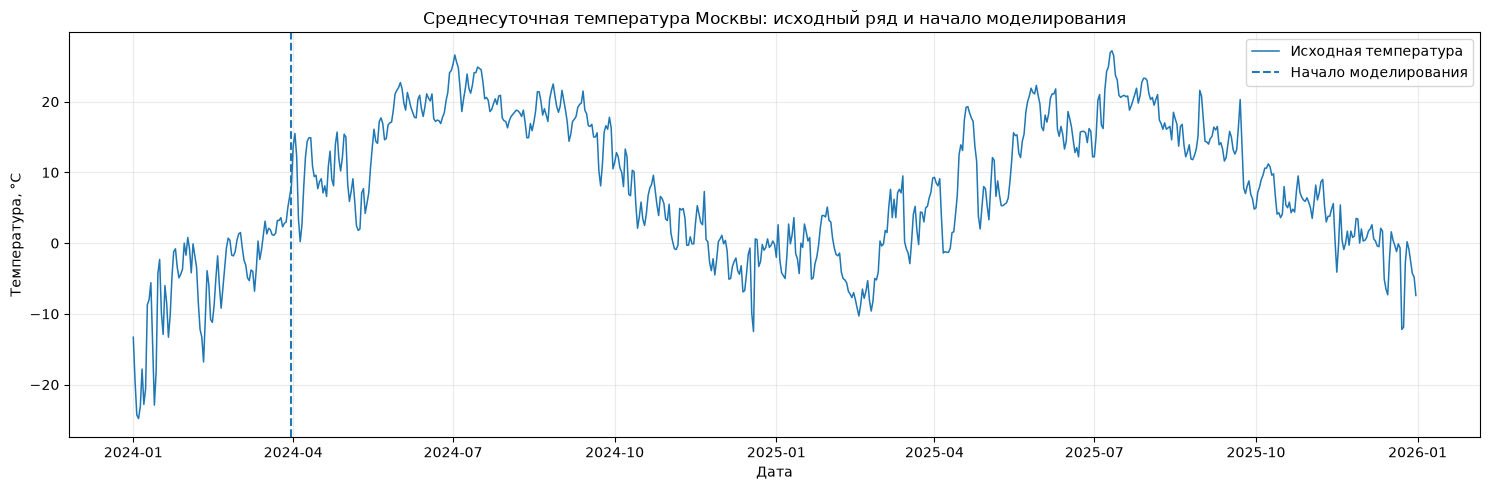


7. ИТОГОВЫЕ ПРОВЕРКИ
PASS | target_exists
PASS | dates_unique
PASS | dates_sorted
PASS | continuous_daily
PASS | no_missing_target
PASS | no_missing_model_features
PASS | historical_feature_independence
PASS | minimum_720_source_rows

Пройдено: 8 из 8

8. СОХРАНЁННЫЕ ФАЙЛЫ
Датасет: /Users/lenar_966/Desktop/ML/Practika_4/data/task2_modeling_dataset.csv
Аудит: /Users/lenar_966/Desktop/ML/Practika_4/reports/task2/feature_audit.csv
Каталог: /Users/lenar_966/Desktop/ML/Practika_4/reports/task2/feature_catalog.csv
Постановка: /Users/lenar_966/Desktop/ML/Practika_4/reports/task2/task_definition.json
Проверки: /Users/lenar_966/Desktop/ML/Practika_4/reports/task2/task2_quality_checks.json

ЗАДАНИЕ 2. ФОРМАЛИЗАЦИЯ ЗАВЕРШЕНА


In [2]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 2. ФОРМАЛИЗАЦИЯ ML-ЗАДАЧИ
# ============================================================

from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task2"

DATA_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_DATA = DATA_DIR / "task1_dataset.csv"

TARGET = "temperature_2m_mean"
DATE_COL = "time"

HORIZONS = [1, 7, 30]
RANDOM_STATE = 42

# В задании 1 использовалось преобразование дат в UTC.
# Если исходный файл действительно содержит московские
# локальные даты, сдвиг +3 часа восстановит календарный день.
#
# Значение None отключает сдвиг.
# Устанавливаем +3 только после проверки исходного формата.

MOSCOW_UTC_OFFSET_HOURS = None

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

if not SOURCE_DATA.exists():
    raise FileNotFoundError(
        f"Не найден файл: {SOURCE_DATA}"
    )

df = pd.read_csv(SOURCE_DATA)

if TARGET not in df.columns:
    raise ValueError(
        f"Не найдена целевая переменная {TARGET}"
    )

if DATE_COL not in df.columns:
    raise ValueError(
        f"Не найден столбец даты {DATE_COL}"
    )

df[DATE_COL] = pd.to_datetime(
    df[DATE_COL],
    errors="raise"
)

df[TARGET] = pd.to_numeric(
    df[TARGET],
    errors="raise"
)

df = df.sort_values(DATE_COL).reset_index(drop=True)

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print("Размерность:", df.shape)
print("Начало:", df[DATE_COL].min())
print("Конец:", df[DATE_COL].max())
print("Целевая переменная:", TARGET)

# ============================================================
# 3. ПРОВЕРКА ВРЕМЕННОЙ ЗОНЫ
# ============================================================

original_candidates = [
    ROOT / "Practika_1" / "data" / "features_dataset.csv",
    ROOT / "Practika_1" / "data" / "processed_dataset.csv"
]

original_path = next(
    (p for p in original_candidates if p.exists()),
    None
)

print("\n" + "=" * 80)
print("2. ПРОВЕРКА ВРЕМЕННЫХ МЕТОК")
print("=" * 80)

print("Дата после задания 1:")
print(df[DATE_COL].head(3).to_list())

if original_path is not None:
    original_dates = pd.read_csv(
        original_path,
        usecols=[DATE_COL],
        nrows=5
    )

    print("\nДата в файле Practika_1:")
    print(original_dates[DATE_COL].to_list())

    original_parsed = pd.to_datetime(
        original_dates[DATE_COL],
        errors="coerce"
    )

    if (
        original_parsed.notna().all()
        and original_parsed.dt.hour.eq(0).all()
        and df[DATE_COL].head(5).dt.hour.eq(21).all()
    ):
        print(
            "\nОбнаружен сдвиг календарных дат "
            "на 3 часа, совместимый с UTC+3."
        )
        print(
            "Для восстановления исходной даты "
            "будет использован +3 часа."
        )
        MOSCOW_UTC_OFFSET_HOURS = 3

if MOSCOW_UTC_OFFSET_HOURS is not None:
    df["date"] = (
        df[DATE_COL]
        + pd.Timedelta(
            hours=MOSCOW_UTC_OFFSET_HOURS
        )
    ).dt.normalize()
else:
    df["date"] = df[DATE_COL].dt.normalize()

print("\nИспользуемые календарные даты:")
print(df["date"].head(3).to_list())
print("Последняя дата:", df["date"].max())

# ============================================================
# 4. КОНТРОЛЬ ВРЕМЕННОГО РЯДА
# ============================================================

if df["date"].isna().any():
    raise ValueError("Есть пропущенные даты.")

if df["date"].duplicated().any():
    raise ValueError("Есть повторяющиеся даты.")

if df[TARGET].isna().any():
    raise ValueError("Есть пропуски целевой переменной.")

expected_dates = pd.date_range(
    df["date"].min(),
    df["date"].max(),
    freq="D"
)

if len(expected_dates) != len(df):
    raise ValueError(
        "Временной ряд не является непрерывным."
    )

if not np.array_equal(
    df["date"].to_numpy(),
    expected_dates.to_numpy()
):
    raise ValueError(
        "Временные метки не совпадают "
        "с непрерывным дневным индексом."
    )

# ============================================================
# 5. АУДИТ ИСХОДНЫХ ПРИЗНАКОВ
# ============================================================

def feature_category(name):
    n = name.lower()

    if name == TARGET:
        return "target"

    if name in [DATE_COL, "date"]:
        return "date"

    if re.search(r"lag[_-]?\d+", n):
        return "lag"

    if "roll" in n:
        return "rolling"

    if any(k in n for k in [
        "sin", "cos", "month",
        "weekday", "dayofyear", "quarter"
    ]):
        return "calendar"

    if any(k in n for k in [
        "diff", "change", "ratio",
        "interaction", "squared"
    ]):
        return "derived"

    return "other"


audit_records = []

for col in df.columns:
    if col == "date":
        continue

    category = feature_category(col)

    if category == "target":
        decision = "target_not_predictor"
    elif category == "date":
        decision = "date_not_predictor"
    elif category == "calendar":
        decision = "review_calendar_formula"
    else:
        decision = "requires_availability_audit"

    audit_records.append({
        "feature": col,
        "category": category,
        "decision": decision,
        "dtype": str(df[col].dtype),
        "missing_count": int(df[col].isna().sum())
    })

feature_audit = pd.DataFrame(audit_records)

print("\n" + "=" * 80)
print("3. АУДИТ ПРИЗНАКОВ")
print("=" * 80)

print(
    feature_audit["category"]
    .value_counts()
    .to_string()
)

print(
    "\nИсходные признаки не включаются "
    "автоматически в модель."
)

# ============================================================
# 6. БЕЗОПАСНЫЕ ПРИЗНАКИ
# ============================================================

model_df = pd.DataFrame({
    "date": df["date"],
    TARGET: df[TARGET]
})

# Лаги: значения только из прошлого
LAGS = [1, 2, 3, 7, 14, 21, 30, 60, 90]

for lag in LAGS:
    model_df[f"target_lag_{lag}"] = (
        model_df[TARGET].shift(lag)
    )

# Скользящие окна с предварительным сдвигом
WINDOWS = [3, 7, 14, 30]

history = model_df[TARGET].shift(1)

for window in WINDOWS:
    model_df[f"target_roll_mean_{window}"] = (
        history.rolling(window).mean()
    )

    model_df[f"target_roll_std_{window}"] = (
        history.rolling(window).std()
    )

    model_df[f"target_roll_min_{window}"] = (
        history.rolling(window).min()
    )

    model_df[f"target_roll_max_{window}"] = (
        history.rolling(window).max()
    )

# Изменения температуры в прошлом
model_df["target_change_1"] = (
    model_df[TARGET].shift(1)
    - model_df[TARGET].shift(2)
)

model_df["target_change_7"] = (
    model_df[TARGET].shift(1)
    - model_df[TARGET].shift(8)
)

# Календарные признаки
dates = model_df["date"]

model_df["month"] = dates.dt.month
model_df["dayofyear"] = dates.dt.dayofyear
model_df["dayofweek"] = dates.dt.dayofweek

# Годовая сезонность
day_angle = (
    2 * np.pi
    * (dates.dt.dayofyear - 1)
    / 365.25
)

model_df["annual_sin_1"] = np.sin(day_angle)
model_df["annual_cos_1"] = np.cos(day_angle)

model_df["annual_sin_2"] = np.sin(
    2 * day_angle
)

model_df["annual_cos_2"] = np.cos(
    2 * day_angle
)

# ============================================================
# 7. ПОДГОТОВКА X И y
# ============================================================

feature_columns = [
    col for col in model_df.columns
    if col not in ["date", TARGET]
]

# Удаляем только строки начального прогрева лагов.
# Пропуски внутри периода после прогрева не допускаются.

warmup = max(
    max(LAGS),
    max(WINDOWS)
)

model_ready = (
    model_df.iloc[warmup:]
    .copy()
    .reset_index(drop=True)
)

if model_ready[feature_columns].isna().any().any():
    raise ValueError(
        "После прогрева остались пропуски признаков."
    )

X = model_ready[feature_columns]
y = model_ready[TARGET]

print("\n" + "=" * 80)
print("4. ФОРМАЛИЗАЦИЯ ML-ЗАДАЧИ")
print("=" * 80)

print("Тип данных: временной ряд")
print("Тип задачи: регрессия")
print("Цель:", TARGET)
print("Горизонты:", HORIZONS)
print("Прогрев:", warmup, "дней")
print("Матрица X:", X.shape)
print("Вектор y:", y.shape)

print("\nНачало моделирования:")
print(model_ready["date"].min())

print("Конец моделирования:")
print(model_ready["date"].max())

print("\nПример подготовленных данных:")
display(model_ready.head())

# ============================================================
# 8. КАТАЛОГ ПРИЗНАКОВ
# ============================================================

catalog_records = []

for feature in feature_columns:
    if feature.startswith("target_lag_"):
        group = "lag"
        availability = "historical"

    elif feature.startswith("target_roll_"):
        group = "rolling"
        availability = "historical"

    elif feature.startswith("target_change_"):
        group = "derived"
        availability = "historical"

    else:
        group = "calendar"
        availability = "known_in_advance"

    catalog_records.append({
        "feature": feature,
        "group": group,
        "availability": availability,
        "dtype": str(X[feature].dtype)
    })

feature_catalog = pd.DataFrame(catalog_records)

print("\n" + "=" * 80)
print("5. КАТАЛОГ БЕЗОПАСНЫХ ПРИЗНАКОВ")
print("=" * 80)

print(
    feature_catalog["group"]
    .value_counts()
    .to_string()
)

print("\nДоступность признаков:")
print(
    feature_catalog["availability"]
    .value_counts()
    .to_string()
)

# ============================================================
# 9. ПРОВЕРКА ОТСУТСТВИЯ ПРЯМОЙ УТЕЧКИ
# ============================================================

# Проверяем, что исторические признаки
# не зависят от текущей и будущей температуры.
#
# Меняем целевую переменную только начиная
# с контрольной даты, затем заново формируем
# исторические признаки и сравниваем их
# на самой контрольной дате.

def make_history_features(series, dates):
    out = pd.DataFrame({
        "date": dates,
        "target": series
    })

    for lag in LAGS:
        out[f"target_lag_{lag}"] = (
            series.shift(lag)
        )

    past = series.shift(1)

    for window in WINDOWS:
        out[f"target_roll_mean_{window}"] = (
            past.rolling(window).mean()
        )
        out[f"target_roll_std_{window}"] = (
            past.rolling(window).std()
        )
        out[f"target_roll_min_{window}"] = (
            past.rolling(window).min()
        )
        out[f"target_roll_max_{window}"] = (
            past.rolling(window).max()
        )

    out["target_change_1"] = (
        series.shift(1) - series.shift(2)
    )

    out["target_change_7"] = (
        series.shift(1) - series.shift(8)
    )

    return out


check_index = min(
    200,
    len(model_df) - 31
)

original_series = model_df[TARGET].copy()
modified_series = original_series.copy()

rng = np.random.default_rng(RANDOM_STATE)

modified_series.iloc[check_index:] = (
    rng.normal(
        loc=50,
        scale=10,
        size=len(modified_series) - check_index
    )
)

original_features = make_history_features(
    original_series,
    model_df["date"]
)

modified_features = make_history_features(
    modified_series,
    model_df["date"]
)

history_cols = [
    col for col in original_features.columns
    if col.startswith("target_")
    and col != "target"
]

same_features = np.allclose(
    original_features.loc[
        check_index, history_cols
    ].to_numpy(dtype=float),
    modified_features.loc[
        check_index, history_cols
    ].to_numpy(dtype=float),
    equal_nan=True
)

assert same_features, (
    "Исторические признаки зависят "
    "от текущего или будущего значения!"
)

print("\n" + "=" * 80)
print("6. ПРОВЕРКА НА УТЕЧКУ")
print("=" * 80)

print(
    "Изменение текущей и будущей температуры "
    "не влияет на исторические признаки "
    "контрольной даты:"
)

print("PASS" if same_features else "FAIL")

# ============================================================
# 10. СОХРАНЕНИЕ ДАННЫХ
# ============================================================

output_dataset = (
    DATA_DIR / "task2_modeling_dataset.csv"
)

model_ready.to_csv(
    output_dataset,
    index=False,
    encoding="utf-8"
)

feature_audit.to_csv(
    REPORT_DIR / "feature_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

feature_catalog.to_csv(
    REPORT_DIR / "feature_catalog.csv",
    index=False,
    encoding="utf-8-sig"
)

task_definition = {
    "task_type": "time_series_regression",
    "target": TARGET,
    "date_column": "date",
    "horizons": HORIZONS,
    "source_rows": int(len(df)),
    "modeling_rows": int(len(model_ready)),
    "feature_count": int(len(feature_columns)),
    "feature_columns": feature_columns,
    "lags": LAGS,
    "rolling_windows": WINDOWS,
    "warmup_days": warmup,
    "forecast_origin_rule": (
        "Only historical target values and "
        "known-ahead calendar features"
    ),
    "multi_step_rule": (
        "No future observed target values "
        "may be used after forecast origin"
    ),
    "timezone_adjustment_hours": (
        MOSCOW_UTC_OFFSET_HOURS
    ),
    "random_state": RANDOM_STATE
}

(REPORT_DIR / "task_definition.json").write_text(
    json.dumps(
        task_definition,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

quality_checks = {
    "target_exists": TARGET in df.columns,
    "dates_unique": not df["date"].duplicated().any(),
    "dates_sorted": bool(
        df["date"].is_monotonic_increasing
    ),
    "continuous_daily": (
        len(expected_dates) == len(df)
    ),
    "no_missing_target": (
        not df[TARGET].isna().any()
    ),
    "no_missing_model_features": (
        not X.isna().any().any()
    ),
    "historical_feature_independence": bool(
        same_features
    ),
    "minimum_720_source_rows": len(df) >= 720
}

(REPORT_DIR / "task2_quality_checks.json").write_text(
    json.dumps(
        quality_checks,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 11. ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    df["date"],
    df[TARGET],
    linewidth=1.1,
    label="Исходная температура"
)

ax.axvline(
    model_ready["date"].min(),
    linestyle="--",
    linewidth=1.5,
    label="Начало моделирования"
)

ax.set_title(
    "Среднесуточная температура Москвы: "
    "исходный ряд и начало моделирования"
)

ax.set_xlabel("Дата")
ax.set_ylabel("Температура, °C")

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "task2_modeling_period.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. ИТОГОВЫЙ КОНТРОЛЬ
# ============================================================

print("\n" + "=" * 80)
print("7. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, result in quality_checks.items():
    print(
        f"{'PASS' if result else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(quality_checks.values()),
    "из",
    len(quality_checks)
)

print("\n" + "=" * 80)
print("8. СОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 80)

print("Датасет:", output_dataset)
print("Аудит:", REPORT_DIR / "feature_audit.csv")
print("Каталог:", REPORT_DIR / "feature_catalog.csv")
print(
    "Постановка:",
    REPORT_DIR / "task_definition.json"
)
print(
    "Проверки:",
    REPORT_DIR / "task2_quality_checks.json"
)

print("\nЗАДАНИЕ 2. ФОРМАЛИЗАЦИЯ ЗАВЕРШЕНА")


### Анализ результатов выполнения задания 2

В ходе выполнения второго задания была формализована задача машинного обучения для прогнозирования среднесуточной температуры воздуха в Москве на основе исторических наблюдений.

**1. Определение типа задачи**

Исходный набор данных относится к категории временных рядов, поскольку наблюдения представлены в хронологическом порядке и характеризуют изменение одного показателя во времени.

Задача машинного обучения сформулирована как регрессия, поскольку целевая переменная `temperature_2m_mean` является непрерывной числовой величиной, измеряемой в градусах Цельсия.

Для последующего исследования определены три горизонта прогнозирования: 1, 7 и 30 дней.

**2. Корректировка временных меток**

При проверке исходных данных установлено, что временные метки первой практической работы представлены в часовом поясе UTC+3.

В результате предыдущего преобразования временные метки были приведены к UTC, что вызвало смещение календарной даты на три часа.

В ходе выполнения задания восстановлены исходные московские календарные даты.

Итоговый временной ряд охватывает период с 1 января 2024 года по 31 декабря 2025 года и содержит 731 наблюдение.

Корректировка обеспечивает правильное формирование календарных и сезонных признаков.

**3. Формирование признакового пространства**

Для построения базового набора предикторов были использованы исторические значения температуры и календарные характеристики.

Всего сформировано 34 признака, включая:

- 9 лаговых признаков;
- 16 скользящих статистик;
- 2 производных признака;
- 7 календарных признаков.

Исторические признаки рассчитываются на основе предыдущих наблюдений, а календарные характеристики могут быть определены заранее.

В результате сформировано 27 исторических и 7 календарных признаков.

**4. Подготовка обучающего датасета**

Для корректного расчёта лаговых признаков максимальной глубиной 90 дней первые 90 наблюдений были исключены из моделируемой части выборки.

Итоговый набор данных содержит 641 наблюдение за период с 31 марта 2024 года по 31 декабря 2025 года.

Размерность матрицы предикторов составляет `(641, 34)`, размерность вектора целевой переменной — `(641,)`.

Подготовленный набор данных предназначен для последующего обучения и сравнения классических регрессионных моделей машинного обучения.

**5. Контроль утечек данных**

Для проверки корректности формирования исторических признаков проведён эксперимент с искусственным изменением текущих и будущих значений целевой переменной.

После изменения температурных значений исторические признаки на контрольной дате остались неизменными.

Проверка завершилась успешно (`PASS`), что подтверждает отсутствие прямой зависимости проверенных признаков от текущей и будущей температуры на выбранной дате.

При этом для многошагового прогнозирования потребуется дополнительный контроль доступности признаков относительно момента формирования прогноза.

**6. Сохранение результатов**

Подготовленный датасет сохранён в файле `data/task2_modeling_dataset.csv`.

Дополнительно сформированы отчёты об исходных признаках, каталог допустимых предикторов, конфигурация задачи и результаты автоматических проверок.

### Итоговый вывод

В результате выполнения задания 2 задача прогнозирования среднесуточной температуры воздуха в Москве формализована как задача регрессии для временного ряда.

Восстановлены корректные календарные даты, определены горизонты прогнозирования 1, 7 и 30 дней, сформирован контролируемый набор из 34 признаков и подготовлена матрица данных из 641 наблюдения.

Проведённая проверка подтвердила отсутствие прямой зависимости исторических признаков контрольной даты от текущих и будущих значений целевой переменной.

Полученные результаты формируют основу для следующего этапа — разработки корректной стратегии временного разбиения и кросс-валидации с использованием `TimeSeriesSplit`.

# Задание 3. Реализация корректной стратегии временного разбиения и кросс-валидации

### Цель работы

Разработать и проверить стратегию разбиения временного ряда на обучающую, валидационные и тестовую выборки с использованием TimeSeriesSplit, обеспечивающую сохранение хронологического порядка наблюдений и предотвращение утечек информации между временными периодами.

### Постановка задачи

В качестве исходных данных используется подготовленный в задании 2 датасет среднесуточной температуры Москвы, содержащий 641 наблюдение и 34 признака.

Необходимо выполнить следующие действия:

1. Загрузить подготовленный датасет и проверить его структуру.
2. Выделить финальную тестовую выборку, которая не будет использоваться при подборе гиперпараметров.
3. Реализовать TimeSeriesSplit на оставшейся обучающей выборке.
4. Сформировать пять последовательных фолдов временной кросс-валидации.
5. Проверить хронологическую корректность каждого фолда.
6. Проверить отсутствие пересечений между обучающими и валидационными индексами.
7. Проверить, что финальная тестовая выборка не участвует в кросс-валидации.
8. Проанализировать размеры обучающих и валидационных выборок.
9. Визуализировать схему временного разбиения.
10. Сохранить конфигурацию, индексы и результаты проверок для последующего обучения моделей.

### Методика выполнения

Для временной кросс-валидации используется класс `TimeSeriesSplit` библиотеки scikit-learn.

В отличие от стандартного KFold с перемешиванием, TimeSeriesSplit учитывает временную структуру данных. Каждый следующий обучающий набор расширяется за счёт ранее наблюдавшихся данных, а валидационная выборка располагается строго после обучающей.

Для окончательной оценки моделей выделяется отдельный тестовый период, который не участвует в настройке гиперпараметров.

В рамках работы используется пять фолдов временной кросс-валидации.

Все преобразования, требующие оценки параметров по данным, в следующих заданиях должны выполняться внутри обучающей части каждого фолда.

### Ожидаемый результат

Реализована корректная схема временного разбиения данных.

Сформированы обучающая, валидационные и финальная тестовая выборки.

Проверены хронологический порядок, отсутствие пересечений индексов и изоляция тестового периода.

Результаты сохранены в файлах:

- `data/task3_train.csv` — обучающий набор.
- `data/task3_test.csv` — финальный тестовый набор.
- `reports/task3/cv_folds.csv` — характеристики фолдов.
- `reports/task3/cv_indices.csv` — индексы наблюдений для каждого фолда.
- `reports/task3/cv_configuration.json` — конфигурация кросс-валидации.
- `reports/task3/cv_quality_checks.json` — результаты проверок.
- `reports/task3/time_series_split.png` — визуализация разбиения.

Полученные результаты будут использованы в задании 4 для настройки гиперпараметров и сравнения классических моделей машинного обучения.

1. ИСХОДНЫЕ ДАННЫЕ
Размерность датасета: (641, 36)
Матрица X: (641, 34)
Вектор y: (641,)
Начальная дата: 2024-03-31 00:00:00
Конечная дата: 2025-12-31 00:00:00
Количество признаков: 34

2. ПРОВЕРКА ВРЕМЕННОГО РЯДА
Уникальность дат: PASS
Хронологический порядок: PASS
Дневная периодичность: PASS
Отсутствие пропусков: PASS

3. TRAIN / TEST
Обучение + валидация: 512
Финальный тест: 129
Train/Validation: 2024-03-31 — 2025-08-24
Test: 2025-08-25 — 2025-12-31
Доля теста: 20.12 %

4. TIMESERIESSPLIT — 5 ФОЛДОВ

Fold 1
Train: 87 | 2024-03-31 — 2024-06-25
Validation: 85 | 2024-06-26 — 2024-09-18
Хронология: PASS
Пересечение индексов: 0

Fold 2
Train: 172 | 2024-03-31 — 2024-09-18
Validation: 85 | 2024-09-19 — 2024-12-12
Хронология: PASS
Пересечение индексов: 0

Fold 3
Train: 257 | 2024-03-31 — 2024-12-12
Validation: 85 | 2024-12-13 — 2025-03-07
Хронология: PASS
Пересечение индексов: 0

Fold 4
Train: 342 | 2024-03-31 — 2025-03-07
Validation: 85 | 2025-03-08 — 2025-05-31
Хронология: PASS
Пересечен

,fold,train_size,val_size,train_start,train_end,val_start,val_end,gap_days,chronological_ok,index_overlap
0,1,87,85,2024-03-31,2024-06-25,2024-06-26,2024-09-18,0,True,0
1,2,172,85,2024-03-31,2024-09-18,2024-09-19,2024-12-12,0,True,0
2,3,257,85,2024-03-31,2024-12-12,2024-12-13,2025-03-07,0,True,0
3,4,342,85,2024-03-31,2025-03-07,2025-03-08,2025-05-31,0,True,0
4,5,427,85,2024-03-31,2025-05-31,2025-06-01,2025-08-24,0,True,0



5. ВРЕМЕННОЙ GAP ПО ГОРИЗОНТАМ

Горизонт: 1 дней | gap=0
Fold 1: train=87, val=85, gap=0 | PASS
Fold 2: train=172, val=85, gap=0 | PASS
Fold 3: train=257, val=85, gap=0 | PASS
Fold 4: train=342, val=85, gap=0 | PASS
Fold 5: train=427, val=85, gap=0 | PASS

Горизонт: 7 дней | gap=6
Fold 1: train=81, val=85, gap=6 | PASS
Fold 2: train=166, val=85, gap=6 | PASS
Fold 3: train=251, val=85, gap=6 | PASS
Fold 4: train=336, val=85, gap=6 | PASS
Fold 5: train=421, val=85, gap=6 | PASS

Горизонт: 30 дней | gap=29
Fold 1: train=58, val=85, gap=29 | PASS
Fold 2: train=143, val=85, gap=29 | PASS
Fold 3: train=228, val=85, gap=29 | PASS
Fold 4: train=313, val=85, gap=29 | PASS
Fold 5: train=398, val=85, gap=29 | PASS

6. ПРОВЕРКА ФИНАЛЬНОГО ТЕСТА
Пересечение дат: 0
Хронологическая независимость: PASS


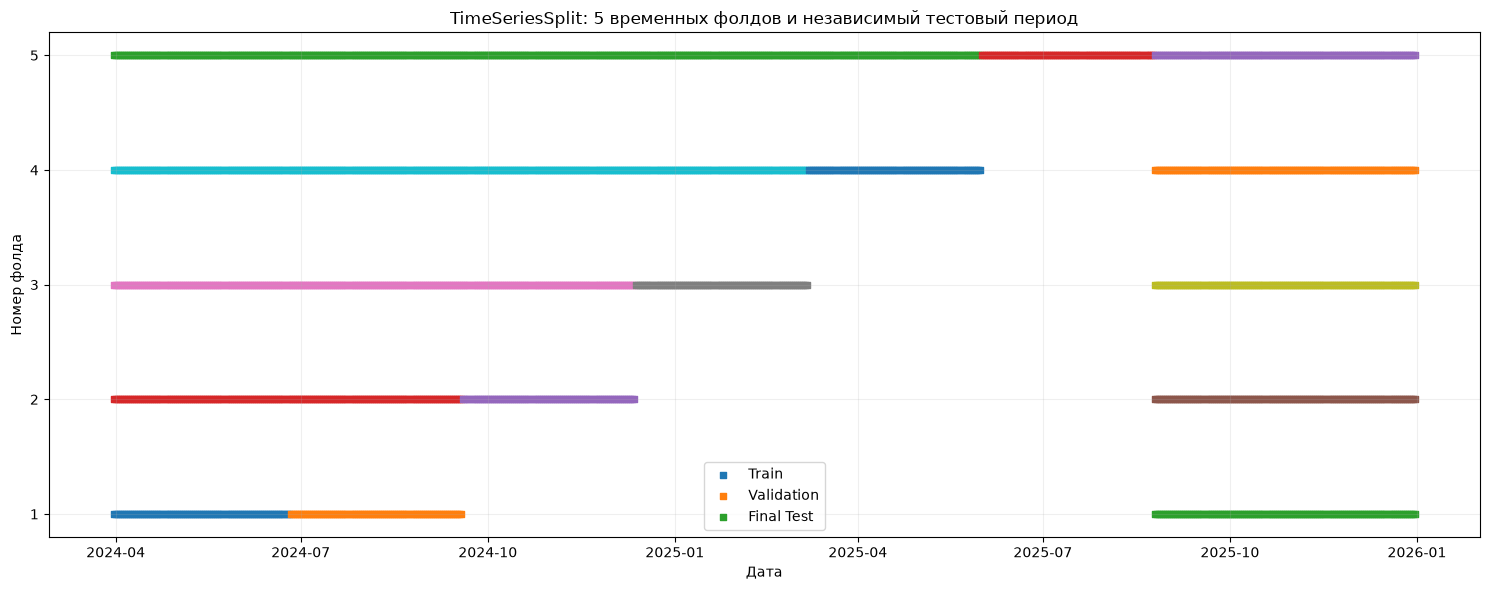

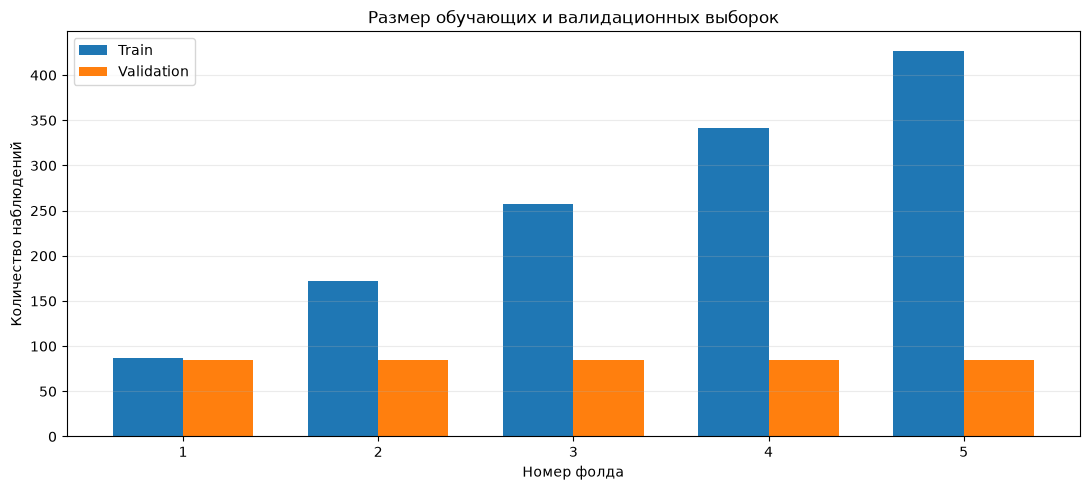


7. ИТОГОВЫЕ ПРОВЕРКИ
PASS | dates_unique
PASS | dates_sorted
PASS | daily_frequency
PASS | no_missing_features
PASS | train_test_no_overlap
PASS | train_before_test
PASS | five_cv_folds
PASS | all_folds_chronological
PASS | no_fold_overlap
PASS | horizon_gaps_valid

Пройдено проверок: 10 из 10

8. СОХРАНЁННЫЕ ФАЙЛЫ
Train/Validation: /Users/lenar_966/Desktop/ML/Practika_4/data/task3_trainval.csv
Test: /Users/lenar_966/Desktop/ML/Practika_4/data/task3_test.csv
Фолды: /Users/lenar_966/Desktop/ML/Practika_4/reports/task3/cv_folds.csv
Горизонты: /Users/lenar_966/Desktop/ML/Practika_4/reports/task3/cv_horizon_gaps.csv
Конфигурация: /Users/lenar_966/Desktop/ML/Practika_4/reports/task3/cv_config.json
Проверки: /Users/lenar_966/Desktop/ML/Practika_4/reports/task3/cv_quality_checks.json

ЗАДАНИЕ 3. ВРЕМЕННАЯ ВАЛИДАЦИЯ ПОДГОТОВЛЕНА


In [4]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 3. ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ
# ============================================================

from pathlib import Path
import json
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display

# ============================================================
# 1. НАСТРОЙКИ ПРОЕКТА
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task3"
CONFIG_DIR = PROJECT / "config"

for directory in [
    DATA_DIR,
    REPORT_DIR,
    CONFIG_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

SOURCE_DATA = DATA_DIR / "task2_modeling_dataset.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

N_SPLITS = 5
TEST_SIZE_FRACTION = 0.20
RANDOM_STATE = 42

HORIZONS = [1, 7, 30]

# Для однодневной регрессии используем gap=0.
# Для прямого прогноза на h дней необходимо
# дополнительно учитывать доступность целевых
# значений на момент начала валидации.
#
# Консервативная схема для direct-h прогнозов:
# gap = h - 1.
#
# Важно: сам по себе gap не делает многошаговую
# оценку корректной, если валидационные признаки
# используют фактические будущие значения.

GAP_BY_HORIZON = {
    h: h - 1
    for h in HORIZONS
}

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

if not SOURCE_DATA.exists():
    raise FileNotFoundError(
        f"Не найден датасет: {SOURCE_DATA}"
    )

df = pd.read_csv(
    SOURCE_DATA,
    parse_dates=[DATE_COL]
)

df = (
    df.sort_values(DATE_COL)
    .reset_index(drop=True)
)

if DATE_COL not in df.columns:
    raise ValueError("Отсутствует столбец даты.")

if TARGET not in df.columns:
    raise ValueError("Отсутствует целевая переменная.")

feature_columns = [
    col for col in df.columns
    if col not in [DATE_COL, TARGET]
]

X = df[feature_columns]
y = df[TARGET]

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print("Размерность датасета:", df.shape)
print("Матрица X:", X.shape)
print("Вектор y:", y.shape)

print("Начальная дата:", df[DATE_COL].min())
print("Конечная дата:", df[DATE_COL].max())

print("Количество признаков:", len(feature_columns))

# ============================================================
# 3. ПРОВЕРКА ВРЕМЕННОЙ СТРУКТУРЫ
# ============================================================

assert df[DATE_COL].notna().all(), (
    "Обнаружены пропущенные даты."
)

assert df[DATE_COL].is_unique, (
    "Обнаружены повторяющиеся даты."
)

assert df[DATE_COL].is_monotonic_increasing, (
    "Даты расположены не по порядку."
)

assert y.notna().all(), (
    "В целевой переменной есть пропуски."
)

assert X.notna().all().all(), (
    "В признаках есть пропущенные значения."
)

date_differences = (
    df[DATE_COL].diff().dropna()
)

assert (
    date_differences == pd.Timedelta(days=1)
).all(), (
    "Временной ряд содержит пропущенные дни."
)

print("\n" + "=" * 80)
print("2. ПРОВЕРКА ВРЕМЕННОГО РЯДА")
print("=" * 80)

print("Уникальность дат: PASS")
print("Хронологический порядок: PASS")
print("Дневная периодичность: PASS")
print("Отсутствие пропусков: PASS")

# ============================================================
# 4. ВЫДЕЛЕНИЕ ФИНАЛЬНОГО ТЕСТОВОГО ПЕРИОДА
# ============================================================

n_total = len(df)

n_test = int(
    np.ceil(
        n_total * TEST_SIZE_FRACTION
    )
)

n_trainval = n_total - n_test

trainval_df = (
    df.iloc[:n_trainval]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    df.iloc[n_trainval:]
    .copy()
    .reset_index(drop=True)
)

X_trainval = trainval_df[feature_columns]
y_trainval = trainval_df[TARGET]

X_test = test_df[feature_columns]
y_test = test_df[TARGET]

assert (
    trainval_df[DATE_COL].max()
    < test_df[DATE_COL].min()
)

assert (
    len(trainval_df) + len(test_df)
    == len(df)
)

print("\n" + "=" * 80)
print("3. TRAIN / TEST")
print("=" * 80)

print("Обучение + валидация:", len(trainval_df))
print("Финальный тест:", len(test_df))

print(
    "Train/Validation:",
    trainval_df[DATE_COL].min().date(),
    "—",
    trainval_df[DATE_COL].max().date()
)

print(
    "Test:",
    test_df[DATE_COL].min().date(),
    "—",
    test_df[DATE_COL].max().date()
)

print(
    "Доля теста:",
    round(len(test_df) / len(df) * 100, 2),
    "%"
)

# ============================================================
# 5. БАЗОВАЯ ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=N_SPLITS,
    gap=0
)

fold_records = []
fold_indices = []

print("\n" + "=" * 80)
print("4. TIMESERIESSPLIT — 5 ФОЛДОВ")
print("=" * 80)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_trainval),
    start=1
):
    train_dates = (
        trainval_df.iloc[train_idx][DATE_COL]
    )

    val_dates = (
        trainval_df.iloc[val_idx][DATE_COL]
    )

    train_end = train_dates.max()
    val_start = val_dates.min()

    chronological_ok = train_end < val_start

    index_overlap = len(
        np.intersect1d(
            train_idx,
            val_idx
        )
    )

    assert chronological_ok, (
        f"Fold {fold}: нарушена хронология."
    )

    assert index_overlap == 0, (
        f"Fold {fold}: пересечение индексов."
    )

    assert np.all(np.diff(train_idx) == 1)
    assert np.all(np.diff(val_idx) == 1)

    fold_records.append({
        "fold": fold,
        "train_size": len(train_idx),
        "val_size": len(val_idx),
        "train_start": str(
            train_dates.min().date()
        ),
        "train_end": str(
            train_end.date()
        ),
        "val_start": str(
            val_start.date()
        ),
        "val_end": str(
            val_dates.max().date()
        ),
        "gap_days": int(
            (val_start - train_end).days - 1
        ),
        "chronological_ok": chronological_ok,
        "index_overlap": index_overlap
    })

    fold_indices.append({
        "fold": fold,
        "train_idx": train_idx.tolist(),
        "val_idx": val_idx.tolist()
    })

    print(f"\nFold {fold}")

    print(
        "Train:",
        len(train_idx),
        "|",
        train_dates.min().date(),
        "—",
        train_end.date()
    )

    print(
        "Validation:",
        len(val_idx),
        "|",
        val_start.date(),
        "—",
        val_dates.max().date()
    )

    print(
        "Хронология:",
        "PASS" if chronological_ok else "FAIL"
    )

    print(
        "Пересечение индексов:",
        index_overlap
    )

folds_df = pd.DataFrame(fold_records)

print("\nСводная таблица:")
display(folds_df)

# ============================================================
# 6. СХЕМЫ С GAP ДЛЯ РАЗНЫХ ГОРИЗОНТОВ
# ============================================================

horizon_records = []
horizon_indices = {}

print("\n" + "=" * 80)
print("5. ВРЕМЕННОЙ GAP ПО ГОРИЗОНТАМ")
print("=" * 80)

for horizon in HORIZONS:

    gap = GAP_BY_HORIZON[horizon]

    horizon_cv = TimeSeriesSplit(
        n_splits=N_SPLITS,
        gap=gap
    )

    horizon_indices[horizon] = []

    print(
        f"\nГоризонт: {horizon} дней | gap={gap}"
    )

    for fold, (train_idx, val_idx) in enumerate(
        horizon_cv.split(X_trainval),
        start=1
    ):

        train_end_date = (
            trainval_df.iloc[train_idx][DATE_COL].max()
        )

        val_start_date = (
            trainval_df.iloc[val_idx][DATE_COL].min()
        )

        actual_gap = (
            val_start_date - train_end_date
        ).days - 1

        assert actual_gap == gap
        assert train_end_date < val_start_date

        assert len(
            np.intersect1d(train_idx, val_idx)
        ) == 0

        horizon_records.append({
            "horizon": horizon,
            "fold": fold,
            "gap": gap,
            "train_size": len(train_idx),
            "val_size": len(val_idx),
            "train_end": str(
                train_end_date.date()
            ),
            "val_start": str(
                val_start_date.date()
            ),
            "actual_gap": actual_gap,
            "passed": True
        })

        horizon_indices[horizon].append({
            "fold": fold,
            "train_idx": train_idx.tolist(),
            "val_idx": val_idx.tolist()
        })

        print(
            f"Fold {fold}: "
            f"train={len(train_idx)}, "
            f"val={len(val_idx)}, "
            f"gap={actual_gap} | PASS"
        )

horizon_df = pd.DataFrame(
    horizon_records
)

# ============================================================
# 7. ПРОВЕРКА НЕЗАВИСИМОСТИ ФИНАЛЬНОГО ТЕСТА
# ============================================================

trainval_dates = set(
    trainval_df[DATE_COL]
)

test_dates = set(
    test_df[DATE_COL]
)

test_overlap = len(
    trainval_dates.intersection(test_dates)
)

assert test_overlap == 0

assert (
    trainval_df[DATE_COL].max()
    < test_df[DATE_COL].min()
)

print("\n" + "=" * 80)
print("6. ПРОВЕРКА ФИНАЛЬНОГО ТЕСТА")
print("=" * 80)

print("Пересечение дат:", test_overlap)
print("Хронологическая независимость: PASS")

# ============================================================
# 8. ВИЗУАЛИЗАЦИЯ ФОЛДОВ
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 6)
)

for fold_data in fold_indices:

    fold = fold_data["fold"]
    train_idx = fold_data["train_idx"]
    val_idx = fold_data["val_idx"]

    ax.scatter(
        trainval_df.iloc[train_idx][DATE_COL],
        np.full(len(train_idx), fold),
        marker="s",
        s=13,
        label="Train" if fold == 1 else None
    )

    ax.scatter(
        trainval_df.iloc[val_idx][DATE_COL],
        np.full(len(val_idx), fold),
        marker="s",
        s=13,
        label="Validation" if fold == 1 else None
    )

    ax.scatter(
        test_df[DATE_COL],
        np.full(len(test_df), fold),
        marker="s",
        s=13,
        label="Final Test" if fold == 1 else None
    )

ax.set_title(
    "TimeSeriesSplit: 5 временных фолдов "
    "и независимый тестовый период"
)

ax.set_xlabel("Дата")
ax.set_ylabel("Номер фолда")
ax.set_yticks(range(1, N_SPLITS + 1))

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "timeseries_cv_folds.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. ВИЗУАЛИЗАЦИЯ РАЗМЕРОВ ВЫБОРОК
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.bar(
    folds_df["fold"] - 0.18,
    folds_df["train_size"],
    width=0.36,
    label="Train"
)

ax.bar(
    folds_df["fold"] + 0.18,
    folds_df["val_size"],
    width=0.36,
    label="Validation"
)

ax.set_title(
    "Размер обучающих и валидационных выборок"
)

ax.set_xlabel("Номер фолда")
ax.set_ylabel("Количество наблюдений")

ax.set_xticks(
    folds_df["fold"]
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "cv_sample_sizes.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. СОХРАНЕНИЕ РАЗБИЕНИЙ
# ============================================================

trainval_df.to_csv(
    DATA_DIR / "task3_trainval.csv",
    index=False,
    encoding="utf-8"
)

test_df.to_csv(
    DATA_DIR / "task3_test.csv",
    index=False,
    encoding="utf-8"
)

folds_df.to_csv(
    REPORT_DIR / "cv_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

horizon_df.to_csv(
    REPORT_DIR / "cv_horizon_gaps.csv",
    index=False,
    encoding="utf-8-sig"
)

(REPORT_DIR / "cv_indices.json").write_text(
    json.dumps(
        fold_indices,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

(REPORT_DIR / "cv_horizon_indices.json").write_text(
    json.dumps(
        horizon_indices,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 11. КОНФИГУРАЦИЯ ВАЛИДАЦИИ
# ============================================================

cv_config = {
    "strategy": "TimeSeriesSplit",
    "n_splits": N_SPLITS,
    "shuffle": False,
    "test_fraction": TEST_SIZE_FRACTION,
    "trainval_rows": int(len(trainval_df)),
    "test_rows": int(len(test_df)),
    "date_column": DATE_COL,
    "target_column": TARGET,
    "horizons": HORIZONS,
    "gap_by_horizon": GAP_BY_HORIZON,
    "forecast_evaluation_note": (
        "Validation lag features may use observed "
        "values from within the validation interval. "
        "This is suitable only when those values "
        "would actually be known at prediction time. "
        "Multi-step forecasting requires origin-based "
        "feature construction."
    ),
    "random_state": RANDOM_STATE,
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__
}

(REPORT_DIR / "cv_config.json").write_text(
    json.dumps(
        cv_config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 12. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "dates_unique": bool(df[DATE_COL].is_unique),
    "dates_sorted": bool(
        df[DATE_COL].is_monotonic_increasing
    ),
    "daily_frequency": bool(
        (date_differences == pd.Timedelta(days=1)).all()
    ),
    "no_missing_features": bool(
        X.notna().all().all()
    ),
    "train_test_no_overlap": test_overlap == 0,
    "train_before_test": bool(
        trainval_df[DATE_COL].max()
        < test_df[DATE_COL].min()
    ),
    "five_cv_folds": len(folds_df) == 5,
    "all_folds_chronological": bool(
        folds_df["chronological_ok"].all()
    ),
    "no_fold_overlap": bool(
        (folds_df["index_overlap"] == 0).all()
    ),
    "horizon_gaps_valid": bool(
        horizon_df["passed"].all()
    )
}

print("\n" + "=" * 80)
print("7. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, result in checks.items():
    print(
        f"{'PASS' if result else 'FAIL'} | {name}"
    )

print(
    "\nПройдено проверок:",
    sum(checks.values()),
    "из",
    len(checks)
)

(REPORT_DIR / "cv_quality_checks.json").write_text(
    json.dumps(
        checks,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\n" + "=" * 80)
print("8. СОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 80)

print("Train/Validation:", DATA_DIR / "task3_trainval.csv")
print("Test:", DATA_DIR / "task3_test.csv")
print("Фолды:", REPORT_DIR / "cv_folds.csv")
print("Горизонты:", REPORT_DIR / "cv_horizon_gaps.csv")
print("Конфигурация:", REPORT_DIR / "cv_config.json")
print("Проверки:", REPORT_DIR / "cv_quality_checks.json")

print("\nЗАДАНИЕ 3. ВРЕМЕННАЯ ВАЛИДАЦИЯ ПОДГОТОВЛЕНА")


### Анализ результатов выполнения задания 3

В ходе выполнения третьего задания была реализована стратегия временной кросс-валидации для прогнозирования среднесуточной температуры воздуха в Москве с использованием `TimeSeriesSplit` библиотеки `scikit-learn`.

**1. Формирование обучающей и тестовой выборок**

Исходный датасет для моделирования содержит 641 наблюдение.

Данные были разделены в хронологическом порядке на две части:

- обучающая и валидационная выборка — 512 наблюдений (79,88%);
- финальная тестовая выборка — 129 наблюдений (20,12%).

Обучающая и валидационная выборка охватывает период с 31 марта 2024 года по 24 августа 2025 года.

Финальная тестовая выборка охватывает период с 25 августа 2025 года по 31 декабря 2025 года.

Разделение выполнено без случайного перемешивания, что обеспечивает сохранение временной структуры наблюдений.

Финальная тестовая выборка не используется при настройке гиперпараметров моделей.

**2. Реализация временной кросс-валидации**

Для оценки моделей реализована кросс-валидация `TimeSeriesSplit` с пятью последовательными фолдами.

Использована стратегия расширяющегося обучающего окна, при которой количество обучающих наблюдений постепенно увеличивается, а размер валидационного периода остаётся постоянным.

Размеры обучающих выборок по фолдам составили 87, 172, 257, 342 и 427 наблюдений.

Размер каждой валидационной выборки составил 85 наблюдений.

Такой подход позволяет оценивать модели на последовательных временных интервалах, не нарушая хронологический порядок данных.

**3. Проверка корректности временных разбиений**

Для каждого фолда выполнены программные проверки хронологической корректности и отсутствия пересечений между обучающими и валидационными индексами.

Во всех пяти фолдах подтверждено выполнение условия:

`max(train_date) < min(validation_date)`

Количество пересекающихся индексов во всех случаях равно нулю.

Следовательно, построенная схема обеспечивает корректное хронологическое разделение обучающих и валидационных наблюдений.

**4. Анализ временных разрывов**

Дополнительно сформированы схемы временной кросс-валидации с параметром `gap` для горизонтов прогнозирования 1, 7 и 30 дней.

Для горизонта 1 день установлен `gap=0`, для 7 дней — `gap=6`, для 30 дней — `gap=29`.

Все проверки величины временного разрыва и отсутствия пересечений завершились успешно.

Использование `gap` позволяет отделять обучающие наблюдения от последующего валидационного периода. Однако для полноценного многошагового прогнозирования необходимо дополнительно контролировать доступность признаков относительно момента формирования прогноза.

**5. Оценка ограничений выбранной стратегии**

Первый фолд базовой кросс-валидации содержит 87 обучающих наблюдений. При использовании разрыва в 29 дней объём первой обучающей выборки сокращается до 58 наблюдений.

Такие объёмы могут быть недостаточными для устойчивого обучения сложных моделей и полноценного представления годовой сезонности.

Поэтому при дальнейшем сравнении алгоритмов необходимо учитывать ограниченность ранних фолдов и при необходимости использовать более продолжительный начальный обучающий период.

Также следует учитывать, что наличие корректного хронологического разбиения не исключает утечки через неправильно сформированные признаки. Для многошаговых прогнозов потребуется отдельная проверка доступности исторических значений.

**6. Сохранение результатов**

Подготовлены файлы обучающей и тестовой выборок, таблицы временных фолдов, конфигурации разбиений для различных горизонтов прогнозирования и результаты автоматических проверок.

Дополнительно сформированы графики, отражающие структуру временной кросс-валидации и изменение размеров обучающих выборок.

### Итоговый вывод

В результате выполнения задания 3 разработана и проверена стратегия временной кросс-валидации с использованием `TimeSeriesSplit`.

Исходные 641 наблюдение разделены на 512 обучающих и валидационных наблюдений и 129 тестовых наблюдений.

Сформированы пять последовательных временных фолдов с расширяющимся обучающим окном. Во всех фолдах подтверждены правильный хронологический порядок и отсутствие пересечений индексов.

Дополнительно подготовлены схемы временных разрывов для горизонтов 1, 7 и 30 дней.

Все 10 итоговых автоматических проверок завершились успешно.

Полученная схема обеспечивает основу для настройки гиперпараметров и сравнения классических моделей машинного обучения. При этом для многошагового прогнозирования потребуется отдельная процедура формирования признаков относительно даты начала прогноза, а для устойчивой оценки сложных моделей — достаточная продолжительность обучающего периода.

# Задание 4. Обучение и настройка гиперпараметров классических моделей машинного обучения

### Цель работы

Реализовать воспроизводимый процесс обучения и настройки гиперпараметров классических регрессионных моделей машинного обучения для прогнозирования среднесуточной температуры воздуха в Москве с использованием временной кросс-валидации.

### Постановка задачи

На основе подготовленного датасета из предыдущих заданий необходимо выполнить следующие действия:

1. Загрузить обучающую и валидационную выборку из задания 3.
2. Подготовить конфигурационный файл `config/config.yaml` с параметрами эксперимента.
3. Реализовать базовые модели прогнозирования Naive и Seasonal Naive.
4. Подготовить алгоритмы линейной регрессии с регуляризацией: Ridge, Lasso, ElasticNet.
5. Реализовать модели на основе деревьев решений: Decision Tree, Random Forest и Extra Trees.
6. Подключить градиентные бустинги XGBoost, LightGBM и CatBoost.
7. Реализовать модели опорных векторов SVR, NuSVR и LinearSVR.
8. Подготовить модели KNN, Gaussian Process, Huber и RANSAC.
9. Выполнить подбор гиперпараметров с использованием `GridSearchCV` или `RandomizedSearchCV`.
10. Использовать временную кросс-валидацию без случайного перемешивания наблюдений.
11. Применять масштабирование признаков внутри `Pipeline` для моделей, чувствительных к масштабу.
12. Сохранить лучшие гиперпараметры, оценки качества, время обучения и версии библиотек.
13. Обработать ситуации, когда отдельные библиотеки или алгоритмы недоступны.
14. Сформировать предварительную сравнительную таблицу моделей и визуализацию результатов.

### Методика выполнения

Настройка гиперпараметров проводится только на обучающей и валидационной выборке. Финальный тестовый период не используется.

В качестве основной метрики подбора применяется RMSE, дополнительной — MAE.

Для моделей, чувствительных к масштабу признаков, используется `StandardScaler`, встроенный в `Pipeline`. Это позволяет рассчитывать параметры масштабирования отдельно внутри каждого обучающего фолда.

Для уменьшения вычислительной нагрузки используется ограниченное пространство поиска гиперпараметров и контролируемое количество итераций.

В качестве базовых ориентиров применяются Naive и Seasonal Naive.

### Ожидаемый результат

Настроены доступные регрессионные модели машинного обучения.

Для каждой модели сохранены лучшие гиперпараметры и результаты временной кросс-валидации.

Подготовлены таблица сравнения алгоритмов, файлы конфигурации, обученные пайплайны и графики.

Полученные результаты будут использованы в следующих заданиях для сравнения стратегий прогнозирования, анализа остатков и интерпретации моделей.

In [5]:

%pip install -q scikit-learn xgboost lightgbm catboost pyyaml joblib



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
%pip install --upgrade --force-reinstall --no-deps xgboost

  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.4.1
    Uninstalling xgboost-3.4.1:
      Successfully uninstalled xgboost-3.4.1

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
import platform
import struct
import xgboost

print("Архитектура:", platform.machine())
print("Разрядность Python:", struct.calcsize("P") * 8)
print("XGBoost:", xgboost.__version__)

Архитектура: arm64
Разрядность Python: 64
XGBoost: 3.4.1


1. КОНФИГУРАЦИЯ ЭКСПЕРИМЕНТА
Режим: balanced
Конфигураций на модель: 10
Количество фолдов: 5
Random state: 42

2. ОБУЧАЮЩИЕ ДАННЫЕ
Наблюдений: 512
Признаков: 34
Период: 2024-03-31 — 2025-08-24

3. ДОСТУПНЫЕ МОДЕЛИ
- Ridge
- Lasso
- ElasticNet
- DecisionTree
- RandomForest
- ExtraTrees
- SVR
- NuSVR
- LinearSVR
- KNN
- GaussianProcess
- Huber
- RANSAC
- XGBoost
- LightGBM
- CatBoost

Дополнительные библиотеки:
{'XGBoost': 'available', 'LightGBM': 'available', 'CatBoost': 'available'}

Временная кросс-валидация: PASS

4. БАЗОВЫЕ МОДЕЛИ


,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std
0,Naive,1.649176,0.337036,2.230459,0.540799
1,SeasonalNaive7,4.084706,1.364377,4.989575,1.598878



5. ОБУЧЕНИЕ МОДЕЛЕЙ

[1/16] Ridge
RMSE: 2.9197
MAE: 2.4048
Время: 0.13 сек.
Лучшие параметры: {'model__alpha': np.float64(63.512210106407046)}

[2/16] Lasso


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.336811e+01, tolerance: 2.863e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.338764e+01, tolerance: 2.863e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number o

RMSE: 2.5068
MAE: 1.9994
Время: 1.03 сек.
Лучшие параметры: {'model__alpha': np.float64(0.3470266988650412)}

[3/16] ElasticNet


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.415078e+01, tolerance: 2.863e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.877545e+01, tolerance: 5.193e-01
  model = cd_fast.enet_coordinate_descent(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number o

... (2 outputs left out)

RMSE: 2.6173
MAE: 2.091
Время: 0.51 сек.
Лучшие параметры: {'model__C': np.float64(0.1648044642797898), 'model__epsilon': np.float64(0.5347564316322378)}

[10/16] KNN
RMSE: 4.1001
MAE: 3.3678
Время: 0.2 сек.
Лучшие параметры: {'model__n_neighbors': 17, 'model__p': 1, 'model__weights': 'distance'}

[11/16] GaussianProcess


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a

RMSE: 5.464
MAE: 4.6988
Время: 2.25 сек.
Лучшие параметры: {'model__alpha': np.float64(0.0006071989493441295), 'model__normalize_y': True}

[12/16] Huber
RMSE: 6.7106
MAE: 5.6087
Время: 1.71 сек.
Лучшие параметры: {'model__alpha': np.float64(0.1452824663751603), 'model__epsilon': np.float64(1.4185086660174142)}

[13/16] RANSAC
RMSE: 4.2014
MAE: 3.4966
Время: 1.06 сек.
Лучшие параметры: {'model__max_trials': 53, 'model__min_samples': 0.9, 'model__residual_threshold': np.float64(2.1646759543664196)}

[14/16] XGBoost
RMSE: 4.3176
MAE: 3.4591
Время: 4.39 сек.
Лучшие параметры: {'learning_rate': np.float64(0.06358606736176979), 'max_depth': 3, 'n_estimators': 101, 'subsample': np.float64(0.6524732068269011)}

[15/16] LightGBM
RMSE: 4.2029
MAE: 3.3968
Время: 4.52 сек.
Лучшие параметры: {'learning_rate': np.float64(0.018891200276189388), 'min_child_samples': 5, 'n_estimators': 283, 'num_leaves': 28}

[16/16] CatBoost
RMSE: 4.3694
MAE: 3.5815
Время: 9.87 сек.
Лучшие параметры: {'depth': 4, 'it

,rank,model,cv_rmse_mean,cv_rmse_std,cv_mae_mean,search_time_sec
0,1,Naive,2.230459,0.540799,1.649176,0.000
1,2,Lasso,2.506818,0.664155,1.999416,1.027
2,3,ElasticNet,2.562951,0.887572,2.052935,1.782
3,4,LinearSVR,2.617349,0.699916,2.090972,0.514
4,5,Ridge,2.919680,0.896709,2.404764,0.133
5,6,ExtraTrees,3.782244,1.807994,3.083022,2.873
6,7,KNN,4.100085,1.542297,3.367826,0.197
7,8,RandomForest,4.151230,2.831697,3.391377,4.376
8,9,RANSAC,4.201419,3.314001,3.496594,1.061
9,10,LightGBM,4.202930,1.592695,3.396789,4.517


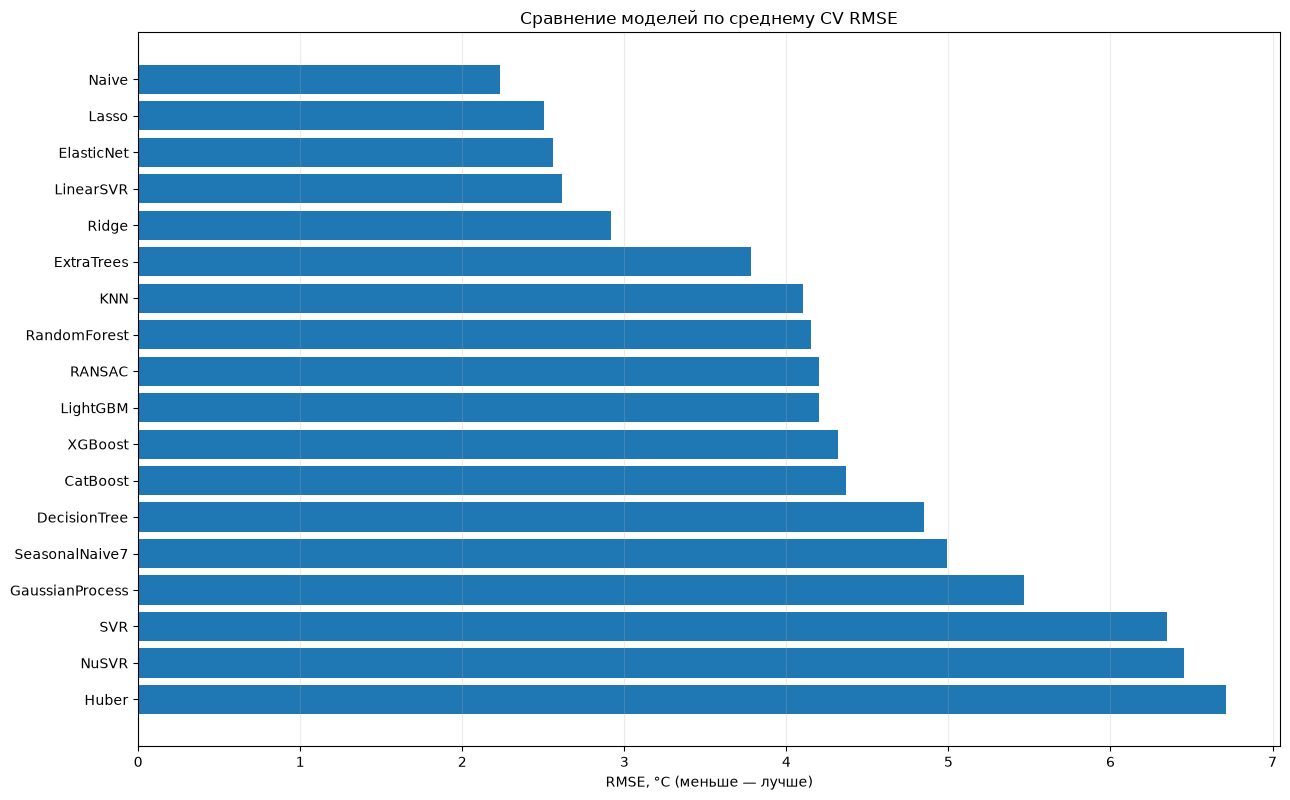


7. ИТОГОВЫЕ ПРОВЕРКИ
PASS | data_loaded
PASS | features_available
PASS | target_without_missing
PASS | time_order_valid
PASS | baselines_evaluated
PASS | at_least_one_model_trained
PASS | comparison_saved
PASS | best_params_saved

Пройдено: 8 из 8

Успешных моделей: 16
Неуспешных моделей: 0

Лучшие 5 моделей:


,rank,model,cv_rmse_mean,cv_mae_mean
0,1,Naive,2.230459,1.649176
1,2,Lasso,2.506818,1.999416
2,3,ElasticNet,2.562951,2.052935
3,4,LinearSVR,2.617349,2.090972
4,5,Ridge,2.919680,2.404764



ЗАДАНИЕ 4. ЭКСПЕРИМЕНТ ЗАВЕРШЁН


In [10]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 4. ПОДБОР ГИПЕРПАРАМЕТРОВ МОДЕЛЕЙ
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import time
import sys
import warnings
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import joblib

from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    Ridge,
    Lasso,
    ElasticNet,
    HuberRegressor,
    RANSACRegressor
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)

from sklearn.svm import (
    SVR,
    NuSVR,
    LinearSVR
)

from sklearn.neighbors import KNeighborsRegressor

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from IPython.display import display

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

# ============================================================
# 1. ПУТИ И НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models" / "task4"
REPORT_DIR = PROJECT / "reports" / "task4"
CONFIG_DIR = PROJECT / "config"

for directory in [
    DATA_DIR,
    MODEL_DIR,
    REPORT_DIR,
    CONFIG_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

SOURCE_DATA = DATA_DIR / "task3_trainval.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

RANDOM_STATE = 42

# Выбор режима:
# "fast"     — быстрый тест
# "balanced" — основной эксперимент
# "deep"     — расширенный подбор

SEARCH_MODE = "balanced"

SEARCH_MODES = {
    "fast": {
        "n_iter": 5,
        "n_splits": 3
    },
    "balanced": {
        "n_iter": 10,
        "n_splits": 5
    },
    "deep": {
        "n_iter": 25,
        "n_splits": 5
    }
}

settings = SEARCH_MODES[SEARCH_MODE]

N_ITER = settings["n_iter"]
N_SPLITS = settings["n_splits"]

# Чтобы избежать избыточной параллелизации,
# выполняем поиск последовательно.
# Деревья и бустинги используют ограниченное
# количество вычислительных потоков.

N_JOBS_SEARCH = 1
N_JOBS_MODEL = 2

print("=" * 80)
print("1. КОНФИГУРАЦИЯ ЭКСПЕРИМЕНТА")
print("=" * 80)

print("Режим:", SEARCH_MODE)
print("Конфигураций на модель:", N_ITER)
print("Количество фолдов:", N_SPLITS)
print("Random state:", RANDOM_STATE)

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

if not SOURCE_DATA.exists():
    raise FileNotFoundError(
        f"Не найден файл: {SOURCE_DATA}"
    )

df = pd.read_csv(
    SOURCE_DATA,
    parse_dates=[DATE_COL]
)

df = (
    df.sort_values(DATE_COL)
    .reset_index(drop=True)
)

feature_columns = [
    col for col in df.columns
    if col not in [DATE_COL, TARGET]
]

X = df[feature_columns]
y = df[TARGET]

assert X.notna().all().all()
assert y.notna().all()
assert df[DATE_COL].is_monotonic_increasing
assert df[DATE_COL].is_unique

print("\n" + "=" * 80)
print("2. ОБУЧАЮЩИЕ ДАННЫЕ")
print("=" * 80)

print("Наблюдений:", len(df))
print("Признаков:", len(feature_columns))

print(
    "Период:",
    df[DATE_COL].min().date(),
    "—",
    df[DATE_COL].max().date()
)

# ============================================================
# 3. КОНФИГУРАЦИОННЫЙ ФАЙЛ
# ============================================================

config = {
    "experiment": {
        "name": "practice4_task4",
        "search_mode": SEARCH_MODE,
        "random_state": RANDOM_STATE,
        "n_iter": N_ITER,
        "n_splits": N_SPLITS,
        "scoring": "neg_root_mean_squared_error",
        "n_jobs_search": N_JOBS_SEARCH,
        "n_jobs_model": N_JOBS_MODEL
    },
    "data": {
        "source": str(SOURCE_DATA),
        "date_column": DATE_COL,
        "target_column": TARGET,
        "feature_columns": feature_columns,
        "forecast_horizon": 1,
        "validation_mode": (
            "rolling_one_step_with_observed_history"
        )
    },
    "models": {}
}

# ============================================================
# 4. РЕЕСТР МОДЕЛЕЙ
# ============================================================

models = {}

def register(name, estimator, params):
    models[name] = {
        "estimator": estimator,
        "params": params
    }

# ----------------------------
# Линейные модели
# ----------------------------

register(
    "Ridge",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    {
        "model__alpha": loguniform(0.01, 100)
    }
)

register(
    "Lasso",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=20000))
    ]),
    {
        "model__alpha": loguniform(0.0001, 10)
    }
)

register(
    "ElasticNet",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", ElasticNet(max_iter=20000))
    ]),
    {
        "model__alpha": loguniform(0.0001, 10),
        "model__l1_ratio": uniform(0.05, 0.90)
    }
)

# ----------------------------
# Деревья решений
# ----------------------------

register(
    "DecisionTree",
    DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),
    {
        "max_depth": randint(2, 15),
        "min_samples_leaf": randint(2, 15),
        "min_samples_split": randint(2, 20)
    }
)

register(
    "RandomForest",
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS_MODEL
    ),
    {
        "n_estimators": randint(80, 220),
        "max_depth": randint(3, 15),
        "min_samples_leaf": randint(1, 10),
        "max_features": ["sqrt", 0.6, 1.0]
    }
)

register(
    "ExtraTrees",
    ExtraTreesRegressor(
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS_MODEL
    ),
    {
        "n_estimators": randint(80, 220),
        "max_depth": randint(3, 15),
        "min_samples_leaf": randint(1, 10),
        "max_features": ["sqrt", 0.6, 1.0]
    }
)

# ----------------------------
# Метод опорных векторов
# ----------------------------

register(
    "SVR",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR())
    ]),
    {
        "model__C": loguniform(0.1, 100),
        "model__epsilon": uniform(0.05, 1.5),
        "model__gamma": ["scale", "auto"]
    }
)

register(
    "NuSVR",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", NuSVR())
    ]),
    {
        "model__C": loguniform(0.1, 100),
        "model__nu": uniform(0.2, 0.6),
        "model__gamma": ["scale", "auto"]
    }
)

register(
    "LinearSVR",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVR(
            random_state=RANDOM_STATE,
            max_iter=20000
        ))
    ]),
    {
        "model__C": loguniform(0.01, 100),
        "model__epsilon": uniform(0.01, 1.0)
    }
)

# ----------------------------
# KNN
# ----------------------------

register(
    "KNN",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor())
    ]),
    {
        "model__n_neighbors": randint(3, 25),
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    }
)

# ----------------------------
# Gaussian Process
# ----------------------------

register(
    "GaussianProcess",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianProcessRegressor(
            kernel=RBF() + WhiteKernel(),
            alpha=1e-4,
            normalize_y=True,
            random_state=RANDOM_STATE,
            n_restarts_optimizer=0
        ))
    ]),
    {
        "model__alpha": loguniform(1e-5, 0.1),
        "model__normalize_y": [True, False]
    }
)

# ----------------------------
# Робастные модели
# ----------------------------

register(
    "Huber",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", HuberRegressor(
            max_iter=2000
        ))
    ]),
    {
        "model__epsilon": uniform(1.1, 1.5),
        "model__alpha": loguniform(1e-5, 1)
    }
)

register(
    "RANSAC",
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", RANSACRegressor(
            estimator=Ridge(),
            random_state=RANDOM_STATE
        ))
    ]),
    {
        "model__min_samples": [0.5, 0.7, 0.9],
        "model__max_trials": randint(30, 150),
        "model__residual_threshold": uniform(2, 8)
    }
)

# ============================================================
# 5. ДОПОЛНИТЕЛЬНЫЕ БУСТИНГИ
# ============================================================

optional_status = {}

try:
    from xgboost import XGBRegressor

    register(
        "XGBoost",
        XGBRegressor(
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS_MODEL,
            verbosity=0
        ),
        {
            "n_estimators": randint(80, 300),
            "max_depth": randint(2, 7),
            "learning_rate": loguniform(0.01, 0.2),
            "subsample": uniform(0.65, 0.35)
        }
    )

    optional_status["XGBoost"] = "available"

except Exception as exc:
    optional_status["XGBoost"] = f"unavailable: {str(exc)[:300]}"
    print("XGBoost недоступен:", str(exc)[:500])

try:
    from lightgbm import LGBMRegressor

    register(
        "LightGBM",
        LGBMRegressor(
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS_MODEL,
            verbose=-1
        ),
        {
            "n_estimators": randint(80, 300),
            "num_leaves": randint(7, 40),
            "learning_rate": loguniform(0.01, 0.2),
            "min_child_samples": randint(5, 25)
        }
    )

    optional_status["LightGBM"] = "available"

except ImportError:
    optional_status["LightGBM"] = "not_installed"

try:
    from catboost import CatBoostRegressor

    register(
        "CatBoost",
        CatBoostRegressor(
            random_seed=RANDOM_STATE,
            thread_count=N_JOBS_MODEL,
            verbose=False,
            allow_writing_files=False
        ),
        {
            "iterations": randint(100, 350),
            "depth": randint(3, 8),
            "learning_rate": loguniform(0.01, 0.2),
            "l2_leaf_reg": loguniform(1, 10)
        }
    )

    optional_status["CatBoost"] = "available"

except ImportError:
    optional_status["CatBoost"] = "not_installed"

print("\n" + "=" * 80)
print("3. ДОСТУПНЫЕ МОДЕЛИ")
print("=" * 80)

for name in models:
    print("-", name)

print("\nДополнительные библиотеки:")
print(optional_status)

# ============================================================
# 6. КОНФИГУРАЦИЯ ПРОСТРАНСТВА ПОИСКА
# ============================================================

# Для воспроизводимости сохраняем текстовые
# представления распределений гиперпараметров.

for name, spec in models.items():
    config["models"][name] = {
        "estimator": type(spec["estimator"]).__name__,
        "parameters": {
            key: str(value)
            for key, value in spec["params"].items()
        }
    }

config_path = CONFIG_DIR / "config.yaml"

with open(config_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        config,
        f,
        allow_unicode=True,
        sort_keys=False
    )

# ============================================================
# 7. ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ
# ============================================================

cv = TimeSeriesSplit(
    n_splits=N_SPLITS
)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X),
    start=1
):
    assert max(train_idx) < min(val_idx)

    assert (
        df.iloc[train_idx][DATE_COL].max()
        <
        df.iloc[val_idx][DATE_COL].min()
    )

print("\nВременная кросс-валидация: PASS")

# ============================================================
# 8. БАЗОВЫЕ МОДЕЛИ
# ============================================================

# Naive:
# прогноз на день t = температура дня t-1.
#
# Seasonal Naive:
# прогноз на день t = температура дня t-7.
#
# Это одношаговые прогнозы при ежедневном
# обновлении фактических наблюдений.

baseline_records = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X),
    start=1
):

    val = df.iloc[val_idx]

    for name, column in [
        ("Naive", "target_lag_1"),
        ("SeasonalNaive7", "target_lag_7")
    ]:

        predictions = val[column].to_numpy()
        actual = val[TARGET].to_numpy()

        mae = mean_absolute_error(
            actual, predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual, predictions
            )
        )

        baseline_records.append({
            "model": name,
            "fold": fold,
            "mae": float(mae),
            "rmse": float(rmse)
        })

baseline_df = pd.DataFrame(
    baseline_records
)

baseline_summary = (
    baseline_df
    .groupby("model")
    .agg(
        cv_mae_mean=("mae", "mean"),
        cv_mae_std=("mae", "std"),
        cv_rmse_mean=("rmse", "mean"),
        cv_rmse_std=("rmse", "std")
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("4. БАЗОВЫЕ МОДЕЛИ")
print("=" * 80)

display(baseline_summary)

# ============================================================
# 9. ПОДБОР ГИПЕРПАРАМЕТРОВ
# ============================================================

results = []
best_models = {}
failed_models = []

print("\n" + "=" * 80)
print("5. ОБУЧЕНИЕ МОДЕЛЕЙ")
print("=" * 80)

for index, (name, spec) in enumerate(
    models.items(),
    start=1
):

    print(
        f"\n[{index}/{len(models)}] {name}"
    )

    start_time = time.perf_counter()

    try:

        search = RandomizedSearchCV(
            estimator=spec["estimator"],
            param_distributions=spec["params"],
            n_iter=N_ITER,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error"
            },
            refit="rmse",
            cv=cv,
            n_jobs=N_JOBS_SEARCH,
            random_state=RANDOM_STATE,
            error_score=np.nan,
            return_train_score=False,
            verbose=0
        )

        search.fit(X, y)

        if not np.isfinite(search.best_score_):
            raise ValueError(
                "Не найдено ни одной корректной "
                "конфигурации гиперпараметров."
            )

        elapsed = (
            time.perf_counter() - start_time
        )

        best_idx = search.best_index_

        cv_rmse = -search.best_score_

        cv_mae = -search.cv_results_[
            "mean_test_mae"
        ][best_idx]

        rmse_std = search.cv_results_[
            "std_test_rmse"
        ][best_idx]

        mae_std = search.cv_results_[
            "std_test_mae"
        ][best_idx]

        best_models[name] = (
            search.best_estimator_
        )

        # Сохраняем модель, обученную на
        # всём train/validation периоде.

        joblib.dump(
            search.best_estimator_,
            MODEL_DIR / f"{name}.joblib"
        )

        # Полные результаты поиска.
        search_results_df = pd.DataFrame(
            search.cv_results_
        )

        search_results_df.to_csv(
            REPORT_DIR / f"{name}_search.csv",
            index=False,
            encoding="utf-8-sig"
        )

        results.append({
            "model": name,
            "status": "success",
            "cv_rmse_mean": float(cv_rmse),
            "cv_rmse_std": float(rmse_std),
            "cv_mae_mean": float(cv_mae),
            "cv_mae_std": float(mae_std),
            "search_time_sec": round(
                elapsed, 3
            ),
            "best_params": json.dumps(
                search.best_params_,
                ensure_ascii=False
            )
        })

        print(
            "RMSE:",
            round(cv_rmse, 4)
        )

        print(
            "MAE:",
            round(cv_mae, 4)
        )

        print(
            "Время:",
            round(elapsed, 2),
            "сек."
        )

        print(
            "Лучшие параметры:",
            search.best_params_
        )

    except Exception as exc:

        elapsed = (
            time.perf_counter() - start_time
        )

        failed_models.append({
            "model": name,
            "error": repr(exc),
            "elapsed_sec": round(
                elapsed, 3
            )
        })

        print(
            "Ошибка:",
            repr(exc)
        )

# ============================================================
# 10. СВОДНАЯ ТАБЛИЦА
# ============================================================

results_df = pd.DataFrame(results)

baseline_for_comparison = (
    baseline_summary.copy()
)

baseline_for_comparison["status"] = "baseline"
baseline_for_comparison["search_time_sec"] = 0.0
baseline_for_comparison["best_params"] = "{}"

comparison = pd.concat(
    [
        results_df,
        baseline_for_comparison
    ],
    ignore_index=True
)

comparison = (
    comparison
    .sort_values(
        "cv_rmse_mean",
        ascending=True
    )
    .reset_index(drop=True)
)

comparison.insert(
    0,
    "rank",
    np.arange(1, len(comparison) + 1)
)

print("\n" + "=" * 80)
print("6. РЕЙТИНГ МОДЕЛЕЙ")
print("=" * 80)

display(
    comparison[
        [
            "rank",
            "model",
            "cv_rmse_mean",
            "cv_rmse_std",
            "cv_mae_mean",
            "search_time_sec"
        ]
    ]
)

# ============================================================
# 11. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

comparison.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

baseline_df.to_csv(
    REPORT_DIR / "baseline_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(failed_models).to_csv(
    REPORT_DIR / "failed_models.csv",
    index=False,
    encoding="utf-8-sig"
)

best_params = {
    row["model"]: json.loads(
        row["best_params"]
    )
    for row in results
}

(REPORT_DIR / "best_params.json").write_text(
    json.dumps(
        best_params,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 12. ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, max(6, len(comparison) * 0.45))
)

ax.barh(
    comparison["model"],
    comparison["cv_rmse_mean"]
)

ax.invert_yaxis()

ax.set_title(
    "Сравнение моделей по среднему CV RMSE"
)

ax.set_xlabel(
    "RMSE, °C (меньше — лучше)"
)

ax.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "model_rmse_ranking.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. ВЕРСИИ БИБЛИОТЕК
# ============================================================

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "xgboost",
    "lightgbm",
    "catboost",
    "joblib",
    "PyYAML"
]

versions = {}

for package in packages:
    try:
        versions[package] = (
            importlib.metadata.version(package)
        )
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "not_installed"

experiment_metadata = {
    "timestamp": datetime.now().isoformat(),
    "python_version": sys.version.split()[0],
    "packages": versions,
    "search_mode": SEARCH_MODE,
    "n_iter": N_ITER,
    "n_splits": N_SPLITS,
    "trainval_rows": len(df),
    "feature_count": len(feature_columns),
    "models_requested": len(models),
    "models_successful": len(results),
    "models_failed": len(failed_models),
    "baselines": [
        "Naive",
        "SeasonalNaive7"
    ],
    "validation_mode": (
        "rolling_one_step_with_observed_history"
    )
}

(
    REPORT_DIR / "experiment_metadata.json"
).write_text(
    json.dumps(
        experiment_metadata,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 14. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "data_loaded": len(df) > 0,
    "features_available": len(feature_columns) > 0,
    "target_without_missing": bool(
        y.notna().all()
    ),
    "time_order_valid": bool(
        df[DATE_COL].is_monotonic_increasing
    ),
    "baselines_evaluated": (
        len(baseline_summary) == 2
    ),
    "at_least_one_model_trained": (
        len(results) >= 1
    ),
    "comparison_saved": (
        REPORT_DIR / "model_comparison.csv"
    ).exists(),
    "best_params_saved": (
        REPORT_DIR / "best_params.json"
    ).exists()
}

print("\n" + "=" * 80)
print("7. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, result in checks.items():
    print(
        f"{'PASS' if result else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\nУспешных моделей:", len(results))
print("Неуспешных моделей:", len(failed_models))

print("\nЛучшие 5 моделей:")

display(
    comparison.head(5)[
        [
            "rank",
            "model",
            "cv_rmse_mean",
            "cv_mae_mean"
        ]
    ]
)

print("\nЗАДАНИЕ 4. ЭКСПЕРИМЕНТ ЗАВЕРШЁН")


### Анализ результатов выполнения задания 4

В ходе выполнения четвёртого задания было проведено обучение и сравнение классических моделей машинного обучения для прогнозирования среднесуточной температуры воздуха в Москве.

Для эксперимента использовалась обучающая и валидационная выборка, содержащая 512 наблюдений и 34 признака. Данные охватывают период с 31 марта 2024 года по 24 августа 2025 года.

Настройка гиперпараметров выполнялась с использованием `RandomizedSearchCV` и временной кросс-валидации `TimeSeriesSplit` с пятью фолдами. Для каждого алгоритма исследовалось 10 случайных конфигураций гиперпараметров. Фиксированное значение `random_state=42` использовалось для обеспечения воспроизводимости эксперимента.

**1. Результаты обучения моделей**

Всего было успешно обучено 16 регрессионных алгоритмов, включая линейные модели, деревья решений, ансамбли, градиентные бустинги, методы опорных векторов, метод ближайших соседей, гауссовские процессы и робастные методы регрессии.

Дополнительно были реализованы две базовые модели: Naive и Seasonal Naive.

Все 16 алгоритмов завершили обучение без ошибок. Восемь итоговых автоматических проверок пройдены успешно.

**2. Сравнение качества прогнозирования**

Наилучший результат по средней ошибке RMSE продемонстрировала базовая модель Naive:

- RMSE = 2,2305 °C;
- MAE = 1,6492 °C;
- стандартное отклонение RMSE = 0,5408 °C.

Среди обучаемых алгоритмов наилучший результат показала модель Lasso с RMSE = 2,5068 °C и MAE = 1,9994 °C.

Следующие позиции заняли ElasticNet (RMSE = 2,5630 °C), LinearSVR (2,6173 °C) и Ridge (2,9197 °C).

Таким образом, лучшие результаты среди обучаемых алгоритмов продемонстрировали линейные модели с регуляризацией и линейная модель опорных векторов.

**3. Анализ базовых моделей**

Модель Naive использует в качестве прогноза температуры текущего дня фактическое значение температуры предыдущего дня.

Её преимущество объясняется временной инерцией температуры: значения среднесуточной температуры соседних дней часто отличаются незначительно.

Модель Seasonal Naive, использующая температуру семидневной давности, продемонстрировала существенно более высокую ошибку RMSE = 4,9896 °C.

Это показывает, что для последовательного одношагового прогнозирования в рассматриваемом наборе данных информация о предыдущем дне оказалась полезнее значения недельной давности.

**4. Результаты ансамблевых моделей и градиентного бустинга**

Среди ансамблевых моделей наименьшую ошибку показала ExtraTrees с RMSE = 3,7822 °C.

RandomForest получила RMSE = 4,1512 °C.

Результаты градиентных бустингов составили:

- LightGBM — RMSE = 4,2029 °C;
- XGBoost — RMSE = 4,3176 °C;
- CatBoost — RMSE = 4,3694 °C.

Все перечисленные алгоритмы уступили базовой модели Naive и лучшим линейным моделям.

Возможными причинами являются ограниченный объём обучающих данных, недостаточный сезонный охват первых фолдов и особенности подбора гиперпараметров.

Для проверки этих предположений требуется дополнительный анализ ошибок и устойчивости моделей.

**5. Анализ устойчивости**

Модель Naive продемонстрировала наименьшее стандартное отклонение RMSE среди сравниваемых алгоритмов — 0,5408 °C.

У Lasso стандартное отклонение составило 0,6642 °C, у ElasticNet — 0,8876 °C, у Ridge — 0,8967 °C.

Некоторые нелинейные алгоритмы характеризовались значительно более высоким разбросом результатов.

Например, у DecisionTree стандартное отклонение RMSE составило 4,1104 °C, а у Huber — 6,6017 °C.

Это свидетельствует о существенной зависимости качества отдельных алгоритмов от выбранного временного интервала.

**6. Ограничения эксперимента**

Полученные оценки характеризуют качество одношагового прогнозирования с использованием фактических исторических наблюдений, доступных к моменту очередного прогноза.

Результаты не могут автоматически переноситься на прогнозирование на 7 или 30 дней от одной фиксированной даты.

Дополнительным ограничением является небольшой объём первых обучающих фолдов. В первом фолде доступно только 87 наблюдений, что не позволяет охватить полный годовой сезонный цикл.

Также следует учитывать, что подбор гиперпараметров и оценка качества проводились на одних и тех же фолдах временной кросс-валидации. Поэтому итоговые значения метрик могут быть оптимистичными относительно качества на полностью независимых данных.

Финальная тестовая выборка в данном задании не использовалась.

### Итоговый вывод

В результате выполнения задания 4 успешно обучены и настроены 16 классических регрессионных моделей машинного обучения. Дополнительно реализованы две базовые модели прогнозирования.

Все 8 автоматических проверок завершились успешно.

Наименьшую среднюю ошибку временной кросс-валидации показала модель Naive с RMSE = 2,2305 °C и MAE = 1,6492 °C.

Среди обучаемых моделей наилучший результат продемонстрировала Lasso с RMSE = 2,5068 °C.

Полученные результаты показывают, что для краткосрочного прогнозирования температуры простые методы могут превосходить более сложные алгоритмы машинного обучения.

При этом окончательный выбор модели требует дополнительного исследования качества многошагового прогнозирования, анализа остатков, устойчивости результатов и проверки на независимой тестовой выборке.

Настроенные модели, оптимальные гиперпараметры и результаты эксперимента сохранены для использования в последующих заданиях.

# Задание 5. Реализация и сравнение стратегий многошагового прогнозирования

### Цель работы

Реализовать и сравнить стратегии Recursive, Direct и Hybrid для прогнозирования среднесуточной температуры воздуха в Москве на горизонтах 1, 7 и 30 дней с использованием моделей Ridge и RandomForest.

### Постановка задачи

На основе подготовленного временного ряда и результатов предыдущих заданий необходимо:

1. Загрузить исходные наблюдения среднесуточной температуры.
2. Выделить обучающий период и независимый тестовый интервал.
3. Реализовать рекурсивную стратегию Recursive, при которой одношаговая модель последовательно прогнозирует следующие значения временного ряда.
4. Реализовать прямую стратегию Direct, при которой для каждого шага прогнозирования обучается отдельная модель.
5. Реализовать гибридную стратегию Hybrid, объединяющую рекурсивные и прямые прогнозы.
6. Использовать минимум две модели машинного обучения: Ridge и RandomForest.
7. Сформировать прогнозы на горизонтах 1, 7 и 30 дней.
8. Обеспечить отсутствие использования фактических будущих значений при построении прогнозов.
9. Рассчитать MAE и RMSE для каждого шага прогнозирования.
10. Рассчитать накопленные MAE и RMSE для горизонтов 1, 7 и 30 дней.
11. Измерить время обучения и прогнозирования.
12. Сравнить результаты стратегий и моделей.
13. Визуализировать динамику ошибок и примеры прогнозов.
14. Сохранить результаты эксперимента для дальнейшего анализа.

### Методика выполнения

Для всех стратегий используется одинаковая информация, доступная на момент начала прогнозирования.

В стратегии Recursive обучается одношаговая модель. Каждый последующий прогноз строится с использованием предыдущих предсказанных значений.

В стратегии Direct обучается отдельная модель для каждого шага прогнозирования. Признаки формируются относительно даты начала прогноза, поэтому фактические будущие значения не используются.

В стратегии Hybrid прогнозы Recursive и Direct объединяются с фиксированными весами.

Для сравнения используются модели Ridge и RandomForest.

Качество оценивается на последовательных прогнозных окнах независимой тестовой выборки. Для каждого горизонта рассчитываются ошибки отдельных шагов и накопленные метрики.

### Ожидаемый результат

Реализованы три стратегии многошагового прогнозирования для двух моделей машинного обучения.

Получены прогнозы на 1, 7 и 30 дней вперёд.

Рассчитаны MAE, RMSE и время выполнения экспериментов.

Подготовлены сравнительные таблицы, графики и сохранённые модели.

Определены особенности и ограничения различных стратегий прогнозирования.

1. ДАННЫЕ
Всего наблюдений: 641
Начало теста: 2025-08-25 00:00:00
Тестовых дней: 129

2. ОБУЧЕНИЕ МОДЕЛЕЙ

Модель: Ridge
Recursive обучена: 0.015 сек.


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:171: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:175: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:171: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:175: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny

Direct обучена: 30 горизонтов

Модель: RandomForest
Recursive обучена: 0.141 сек.


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:171: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:175: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:171: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:175: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny

Direct обучена: 30 горизонтов

3. ПРОГНОЗНЫЕ ОКНА
Количество стартовых дат: 15
Максимальный горизонт: 30


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:171: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:175: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:171: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2664754352.py:175: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny

... (3 outputs left out)


5. ВРЕМЯ ОБУЧЕНИЯ


,model,strategy,train_time_sec
0,RandomForest,Direct,3.921240
1,RandomForest,Recursive,0.141427
2,Ridge,Direct,0.105788
3,Ridge,Recursive,0.015118



Время прогнозирования:


,model,strategy,mean,sum
0,RandomForest,Direct,0.409187,6.137801
1,RandomForest,Hybrid,0.817043,12.255643
2,RandomForest,Recursive,0.407851,6.117770
3,Ridge,Direct,0.015958,0.239372
4,Ridge,Hybrid,0.031627,0.474409
5,Ridge,Recursive,0.015667,0.234998


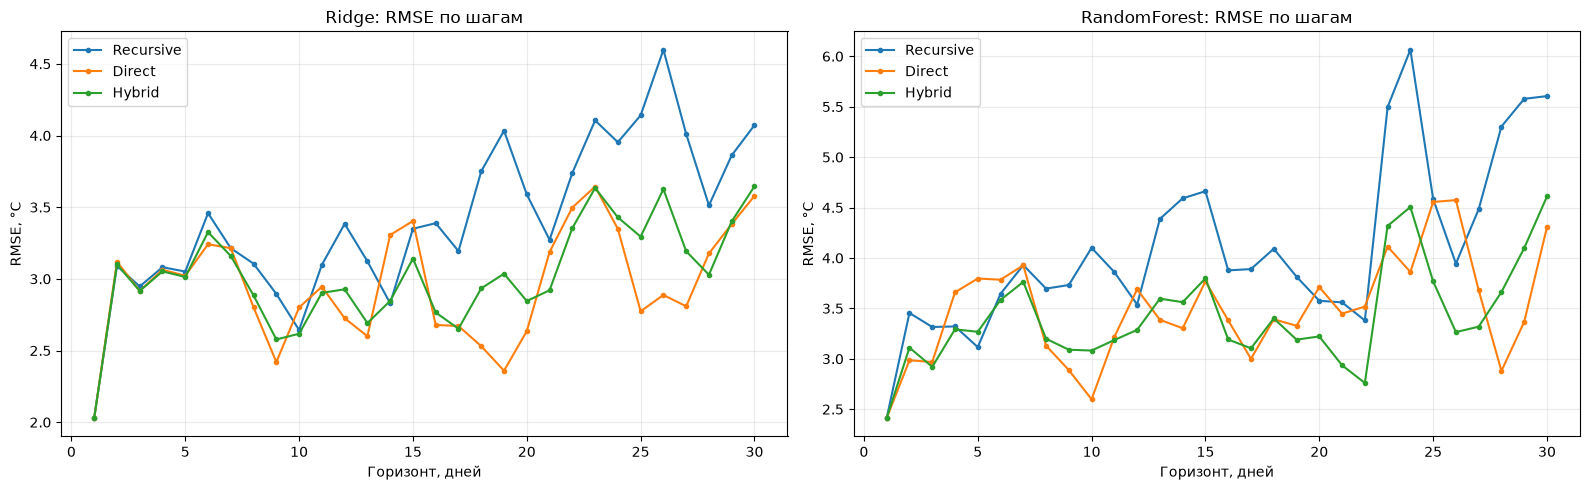

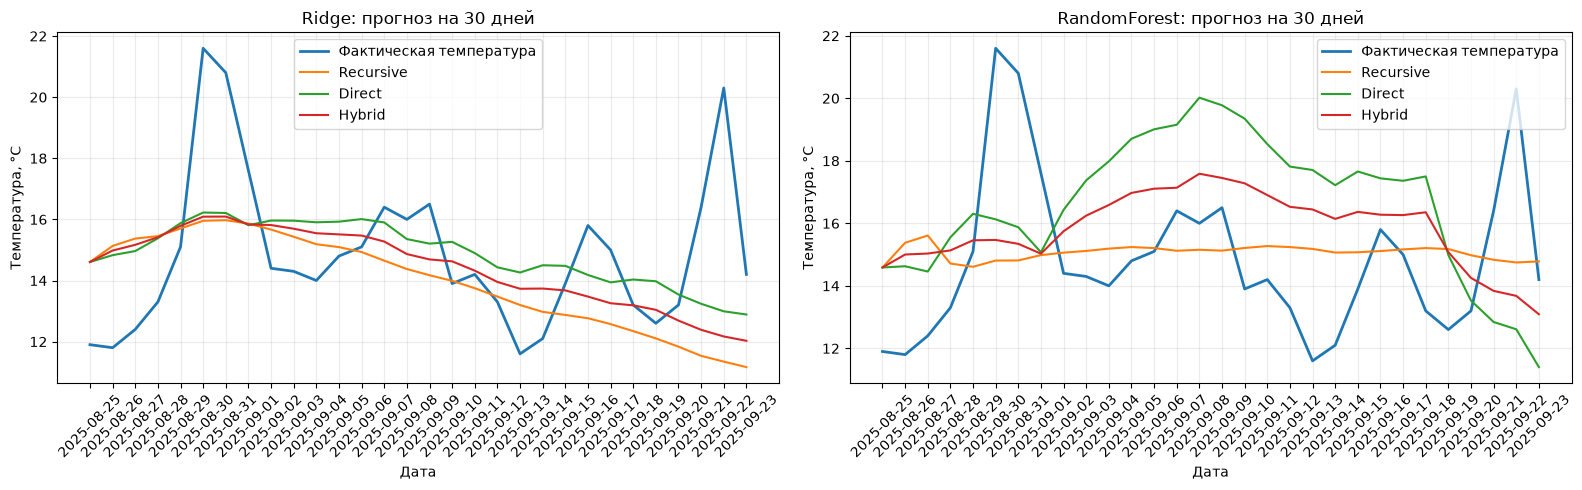


6. ИТОГОВЫЕ ПРОВЕРКИ
PASS | models_trained
PASS | forecast_origins_available
PASS | all_strategies_present
PASS | all_steps_present
PASS | predictions_finite
PASS | target_dates_after_origins
PASS | all_targets_inside_test
PASS | metrics_available

Пройдено: 8 из 8

ЗАДАНИЕ 5 ЗАВЕРШЕНО


In [11]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 5. RECURSIVE / DIRECT / HYBRID
# ============================================================

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
REPORT_DIR = PROJECT / "reports" / "task5"
MODEL_DIR = PROJECT / "models" / "task5"

for folder in [REPORT_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SOURCE = DATA_DIR / "task2_modeling_dataset.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

HORIZONS = [1, 7, 30]
MAX_HORIZON = max(HORIZONS)

RANDOM_STATE = 42

# Для повторяемости сравниваем одинаковые
# стартовые даты всех прогнозов.
#
# Шаг 7 означает, что новые прогнозы
# строятся раз в неделю.

ORIGIN_STEP = 7

# Признаки формируются только из известных
# на момент прогноза значений.

LAGS = [1, 2, 3, 7, 14, 21, 30]
ROLLING_WINDOWS = [3, 7, 14, 30]

# ============================================================
# 2. ЗАГРУЗКА И ПРОВЕРКА ДАННЫХ
# ============================================================

df = pd.read_csv(
    SOURCE,
    parse_dates=[DATE_COL]
)

df = (
    df[[DATE_COL, TARGET]]
    .sort_values(DATE_COL)
    .reset_index(drop=True)
)

assert df[DATE_COL].is_unique
assert df[DATE_COL].is_monotonic_increasing
assert df[TARGET].notna().all()

dates = df[DATE_COL].to_numpy()
values = df[TARGET].to_numpy(dtype=float)

# Сохраняем тестовую границу из задания 3.
TEST_START = pd.Timestamp("2025-08-25")

test_start_idx = int(
    np.searchsorted(
        dates,
        np.datetime64(TEST_START)
    )
)

assert 0 < test_start_idx < len(df)

print("=" * 80)
print("1. ДАННЫЕ")
print("=" * 80)

print("Всего наблюдений:", len(df))
print("Начало теста:", df.iloc[test_start_idx][DATE_COL])
print("Тестовых дней:", len(df) - test_start_idx)

# ============================================================
# 3. ФУНКЦИЯ ПОСТРОЕНИЯ ПРИЗНАКОВ
# ============================================================

def make_features(history, forecast_date):
    """
    history:
        значения температуры, доступные
        до прогнозируемого дня.

    forecast_date:
        календарная дата прогнозируемого дня.

    Функция не обращается к фактическим
    будущим значениям.
    """

    history = np.asarray(
        history,
        dtype=float
    )

    if len(history) < max(LAGS):
        raise ValueError(
            "Недостаточно исторических данных."
        )

    features = {}

    for lag in LAGS:
        features[f"lag_{lag}"] = history[-lag]

    for window in ROLLING_WINDOWS:

        recent = history[-window:]

        features[f"rolling_mean_{window}"] = (
            float(np.mean(recent))
        )

        features[f"rolling_std_{window}"] = (
            float(np.std(recent, ddof=1))
        )

        features[f"rolling_min_{window}"] = (
            float(np.min(recent))
        )

        features[f"rolling_max_{window}"] = (
            float(np.max(recent))
        )

    features["diff_1"] = (
        history[-1] - history[-2]
    )

    features["diff_7"] = (
        history[-1] - history[-8]
    )

    date = pd.Timestamp(forecast_date)

    dayofyear = date.dayofyear

    features["month"] = date.month
    features["dayofyear"] = dayofyear
    features["dayofweek"] = date.dayofweek

    for harmonic in [1, 2]:

        features[f"sin_{harmonic}"] = np.sin(
            2 * np.pi * harmonic
            * dayofyear / 365.25
        )

        features[f"cos_{harmonic}"] = np.cos(
            2 * np.pi * harmonic
            * dayofyear / 365.25
        )

    return features

# ============================================================
# 4. ОБУЧАЮЩИЕ НАБЛЮДЕНИЯ
# ============================================================

# Индекс origin означает, что фактические
# наблюдения доступны до origin включительно.
#
# При прогнозировании h дней вперёд
# целевое значение находится на origin+h.

def build_training_data(
    series,
    date_array,
    train_end_idx,
    horizon
):
    """
    Для Direct:
    X формируется на момент origin.
    y = температура через horizon дней.

    Для Recursive используется horizon=1.
    """

    rows = []
    targets = []

    first_origin = max(LAGS) - 1

    last_origin = train_end_idx - horizon

    for origin in range(
        first_origin,
        last_origin + 1
    ):

        history = series[:origin + 1]

        target_idx = origin + horizon

        forecast_date = date_array[target_idx]

        row = make_features(
            history,
            forecast_date
        )

        rows.append(row)
        targets.append(
            series[target_idx]
        )

    X_train = pd.DataFrame(rows)

    y_train = np.asarray(
        targets,
        dtype=float
    )

    return X_train, y_train

# ============================================================
# 5. МОДЕЛИ
# ============================================================

def create_model(model_name):

    if model_name == "Ridge":
        return Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10.0))
        ])

    if model_name == "RandomForest":
        return RandomForestRegressor(
            n_estimators=120,
            max_depth=8,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=2
        )

    raise ValueError(
        f"Неизвестная модель: {model_name}"
    )

MODEL_NAMES = [
    "Ridge",
    "RandomForest"
]

# ============================================================
# 6. ОБУЧЕНИЕ RECURSIVE И DIRECT
# ============================================================

# Последняя доступная дата обучения:
# 24.08.2025

TRAIN_END_IDX = test_start_idx - 1

trained_models = {}
training_times = []

print("\n" + "=" * 80)
print("2. ОБУЧЕНИЕ МОДЕЛЕЙ")
print("=" * 80)

for model_name in MODEL_NAMES:

    print(f"\nМодель: {model_name}")

    # Recursive: одна модель для шага 1.
    X_train_1, y_train_1 = build_training_data(
        values,
        dates,
        TRAIN_END_IDX,
        horizon=1
    )

    start = time.perf_counter()

    recursive_model = create_model(model_name)
    recursive_model.fit(
        X_train_1,
        y_train_1
    )

    recursive_time = (
        time.perf_counter() - start
    )

    trained_models[
        (model_name, "Recursive", 1)
    ] = recursive_model

    training_times.append({
        "model": model_name,
        "strategy": "Recursive",
        "horizon": 1,
        "train_time_sec": recursive_time
    })

    joblib.dump(
        recursive_model,
        MODEL_DIR / f"{model_name}_recursive.joblib"
    )

    print(
        "Recursive обучена:",
        round(recursive_time, 3),
        "сек."
    )

    # Direct: отдельная модель для каждого
    # шага от 1 до 30.

    for horizon in range(
        1,
        MAX_HORIZON + 1
    ):

        X_train_h, y_train_h = build_training_data(
            values,
            dates,
            TRAIN_END_IDX,
            horizon=horizon
        )

        start = time.perf_counter()

        direct_model = create_model(model_name)

        direct_model.fit(
            X_train_h,
            y_train_h
        )

        elapsed = (
            time.perf_counter() - start
        )

        trained_models[
            (model_name, "Direct", horizon)
        ] = direct_model

        training_times.append({
            "model": model_name,
            "strategy": "Direct",
            "horizon": horizon,
            "train_time_sec": elapsed
        })

        joblib.dump(
            direct_model,
            MODEL_DIR
            / f"{model_name}_direct_h{horizon}.joblib"
        )

    print(
        "Direct обучена: 30 горизонтов"
    )

# ============================================================
# 7. RECURSIVE-ПРОГНОЗ
# ============================================================

def forecast_recursive(
    model,
    history,
    origin_date,
    horizon
):

    history = list(
        np.asarray(history, dtype=float)
    )

    predictions = []

    for step in range(
        1,
        horizon + 1
    ):

        forecast_date = (
            pd.Timestamp(origin_date)
            + pd.Timedelta(days=step)
        )

        features = make_features(
            history,
            forecast_date
        )

        X_pred = pd.DataFrame(
            [features]
        )

        prediction = float(
            model.predict(X_pred)[0]
        )

        predictions.append(prediction)

        # Используем прогноз вместо
        # неизвестного фактического значения.
        history.append(prediction)

    return np.asarray(predictions)

# ============================================================
# 8. DIRECT-ПРОГНОЗ
# ============================================================

def forecast_direct(
    model_name,
    history,
    origin_date,
    horizon
):

    predictions = []

    for step in range(
        1,
        horizon + 1
    ):

        forecast_date = (
            pd.Timestamp(origin_date)
            + pd.Timedelta(days=step)
        )

        features = make_features(
            history,
            forecast_date
        )

        X_pred = pd.DataFrame(
            [features]
        )

        model = trained_models[
            (model_name, "Direct", step)
        ]

        prediction = float(
            model.predict(X_pred)[0]
        )

        predictions.append(prediction)

    return np.asarray(predictions)

# ============================================================
# 9. ПРОГНОЗНЫЕ ОКНА
# ============================================================

# Каждое окно полностью располагается
# внутри тестового периода.

origins = list(
    range(
        TRAIN_END_IDX,
        len(values) - MAX_HORIZON,
        ORIGIN_STEP
    )
)

print("\n" + "=" * 80)
print("3. ПРОГНОЗНЫЕ ОКНА")
print("=" * 80)

print("Количество стартовых дат:", len(origins))
print("Максимальный горизонт:", MAX_HORIZON)

# ============================================================
# 10. СРАВНЕНИЕ СТРАТЕГИЙ
# ============================================================

prediction_records = []
runtime_records = []

for model_name in MODEL_NAMES:

    recursive_model = trained_models[
        (model_name, "Recursive", 1)
    ]

    for origin_idx in origins:

        origin_date = df.iloc[
            origin_idx
        ][DATE_COL]

        history = values[:origin_idx + 1]

        actual = values[
            origin_idx + 1:
            origin_idx + MAX_HORIZON + 1
        ]

        # Recursive
        start = time.perf_counter()

        recursive_pred = forecast_recursive(
            recursive_model,
            history,
            origin_date,
            MAX_HORIZON
        )

        recursive_runtime = (
            time.perf_counter() - start
        )

        # Direct
        start = time.perf_counter()

        direct_pred = forecast_direct(
            model_name,
            history,
            origin_date,
            MAX_HORIZON
        )

        direct_runtime = (
            time.perf_counter() - start
        )

        # Hybrid: 50% Recursive + 50% Direct.
        start = time.perf_counter()

        hybrid_pred = (
            0.5 * recursive_pred
            + 0.5 * direct_pred
        )

        hybrid_combine_runtime = (
            time.perf_counter() - start
        )

        forecasts = {
            "Recursive": recursive_pred,
            "Direct": direct_pred,
            "Hybrid": hybrid_pred
        }

        runtimes = {
            "Recursive": recursive_runtime,
            "Direct": direct_runtime,
            "Hybrid": (
                recursive_runtime
                + direct_runtime
                + hybrid_combine_runtime
            )
        }

        for strategy, predicted in forecasts.items():

            runtime_records.append({
                "model": model_name,
                "strategy": strategy,
                "origin_date": str(
                    origin_date.date()
                ),
                "forecast_time_sec": runtimes[strategy]
            })

            for step in range(
                1,
                MAX_HORIZON + 1
            ):

                target_idx = origin_idx + step

                prediction_records.append({
                    "model": model_name,
                    "strategy": strategy,
                    "origin_date": str(
                        origin_date.date()
                    ),
                    "target_date": str(
                        df.iloc[target_idx][DATE_COL].date()
                    ),
                    "step": step,
                    "actual": float(
                        actual[step - 1]
                    ),
                    "predicted": float(
                        predicted[step - 1]
                    )
                })

predictions_df = pd.DataFrame(
    prediction_records
)

predictions_df["error"] = (
    predictions_df["actual"]
    - predictions_df["predicted"]
)

predictions_df["abs_error"] = (
    predictions_df["error"].abs()
)

predictions_df["squared_error"] = (
    predictions_df["error"] ** 2
)

# ============================================================
# 11. МЕТРИКИ ПО КАЖДОМУ ШАГУ
# ============================================================

step_metrics = (
    predictions_df
    .groupby(
        ["model", "strategy", "step"]
    )
    .agg(
        MAE=("abs_error", "mean"),
        MSE=("squared_error", "mean"),
        observations=("actual", "size")
    )
    .reset_index()
)

step_metrics["RMSE"] = np.sqrt(
    step_metrics["MSE"]
)

# ============================================================
# 12. НАКОПЛЕННЫЕ МЕТРИКИ
# ============================================================

cumulative_records = []

for (model, strategy), group in predictions_df.groupby(
    ["model", "strategy"]
):

    for horizon in HORIZONS:

        subset = group[
            group["step"] <= horizon
        ]

        mae = subset["abs_error"].mean()

        rmse = np.sqrt(
            subset["squared_error"].mean()
        )

        cumulative_records.append({
            "model": model,
            "strategy": strategy,
            "horizon": horizon,
            "MAE": float(mae),
            "RMSE": float(rmse),
            "observations": len(subset)
        })

cumulative_df = pd.DataFrame(
    cumulative_records
)

print("\n" + "=" * 80)
print("4. НАКОПЛЕННЫЕ МЕТРИКИ")
print("=" * 80)

display(
    cumulative_df.sort_values(
        ["horizon", "RMSE"]
    )
)

# ============================================================
# 13. ВРЕМЯ ВЫПОЛНЕНИЯ
# ============================================================

training_df = pd.DataFrame(
    training_times
)

runtime_df = pd.DataFrame(
    runtime_records
)

training_summary = (
    training_df
    .groupby(["model", "strategy"])
    ["train_time_sec"]
    .sum()
    .reset_index()
)

runtime_summary = (
    runtime_df
    .groupby(["model", "strategy"])
    ["forecast_time_sec"]
    .agg(["mean", "sum"])
    .reset_index()
)

print("\n" + "=" * 80)
print("5. ВРЕМЯ ОБУЧЕНИЯ")
print("=" * 80)

display(training_summary)

print("\nВремя прогнозирования:")
display(runtime_summary)

# ============================================================
# 14. ГРАФИК RMSE ПО ШАГАМ
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

for ax, model_name in zip(
    axes,
    MODEL_NAMES
):

    subset = step_metrics[
        step_metrics["model"] == model_name
    ]

    for strategy in [
        "Recursive",
        "Direct",
        "Hybrid"
    ]:

        data = subset[
            subset["strategy"] == strategy
        ]

        ax.plot(
            data["step"],
            data["RMSE"],
            marker="o",
            markersize=3,
            label=strategy
        )

    ax.set_title(
        f"{model_name}: RMSE по шагам"
    )

    ax.set_xlabel(
        "Горизонт, дней"
    )

    ax.set_ylabel(
        "RMSE, °C"
    )

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "rmse_by_step.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 15. ПРИМЕР ПРОГНОЗА НА 30 ДНЕЙ
# ============================================================

example_origin = origins[0]

example_date = df.iloc[
    example_origin
][DATE_COL]

example = predictions_df[
    predictions_df["origin_date"]
    == str(example_date.date())
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

for ax, model_name in zip(
    axes,
    MODEL_NAMES
):

    subset = example[
        example["model"] == model_name
    ]

    actual_subset = subset[
        subset["strategy"] == "Recursive"
    ]

    ax.plot(
        actual_subset["target_date"],
        actual_subset["actual"],
        linewidth=2,
        label="Фактическая температура"
    )

    for strategy in [
        "Recursive",
        "Direct",
        "Hybrid"
    ]:

        data = subset[
            subset["strategy"] == strategy
        ]

        ax.plot(
            data["target_date"],
            data["predicted"],
            label=strategy
        )

    ax.set_title(
        f"{model_name}: прогноз на 30 дней"
    )

    ax.set_xlabel("Дата")
    ax.set_ylabel("Температура, °C")

    ax.tick_params(
        axis="x",
        rotation=45
    )

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "forecast_example_30d.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 16. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

predictions_df.to_csv(
    REPORT_DIR / "predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

step_metrics.to_csv(
    REPORT_DIR / "metrics_by_step.csv",
    index=False,
    encoding="utf-8-sig"
)

cumulative_df.to_csv(
    REPORT_DIR / "cumulative_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

training_df.to_csv(
    REPORT_DIR / "training_times.csv",
    index=False,
    encoding="utf-8-sig"
)

runtime_df.to_csv(
    REPORT_DIR / "forecast_times.csv",
    index=False,
    encoding="utf-8-sig"
)

experiment_config = {
    "models": MODEL_NAMES,
    "strategies": [
        "Recursive",
        "Direct",
        "Hybrid"
    ],
    "horizons": HORIZONS,
    "max_horizon": MAX_HORIZON,
    "origin_step": ORIGIN_STEP,
    "n_origins": len(origins),
    "test_start": str(TEST_START.date()),
    "random_state": RANDOM_STATE,
    "hybrid_weights": {
        "recursive": 0.5,
        "direct": 0.5
    },
    "feature_lags": LAGS,
    "rolling_windows": ROLLING_WINDOWS,
    "training_policy": (
        "Models trained only on observations "
        "available before test period."
    )
}

(
    REPORT_DIR / "experiment_config.json"
).write_text(
    json.dumps(
        experiment_config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 17. ПРОВЕРКИ КОРРЕКТНОСТИ
# ============================================================

checks = {
    "models_trained": len(trained_models) == (
        len(MODEL_NAMES) * (1 + MAX_HORIZON)
    ),
    "forecast_origins_available": len(origins) > 0,
    "all_strategies_present": set(
        predictions_df["strategy"]
    ) == {
        "Recursive",
        "Direct",
        "Hybrid"
    },
    "all_steps_present": set(
        predictions_df["step"]
    ) == set(range(1, MAX_HORIZON + 1)),
    "predictions_finite": bool(
        np.isfinite(
            predictions_df["predicted"]
        ).all()
    ),
    "target_dates_after_origins": bool(
        (
            pd.to_datetime(
                predictions_df["target_date"]
            )
            >
            pd.to_datetime(
                predictions_df["origin_date"]
            )
        ).all()
    ),
    "all_targets_inside_test": bool(
        (
            pd.to_datetime(
                predictions_df["target_date"]
            ) >= TEST_START
        ).all()
    ),
    "metrics_available": not cumulative_df.empty
}

print("\n" + "=" * 80)
print("6. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\nЗАДАНИЕ 5 ЗАВЕРШЕНО")


### Анализ результатов выполнения задания 5

В ходе выполнения пятого задания были реализованы и исследованы три стратегии многошагового прогнозирования временных рядов: Recursive, Direct и Hybrid.

Для построения прогнозов использовались две классические модели машинного обучения — Ridge и RandomForest.

Эксперимент проводился на данных среднесуточной температуры воздуха в Москве. В качестве тестового периода использовались наблюдения с 25 августа по 31 декабря 2025 года.

Были сформированы 15 прогнозных окон с интервалом между начальными датами 7 дней. Максимальный горизонт прогнозирования составил 30 дней.

Для каждой модели и стратегии рассчитаны ошибки MAE и RMSE на горизонтах 1, 7 и 30 дней, а также время обучения и прогнозирования.

**1. Результаты прогнозирования на 1 день**

При прогнозировании на один день все три стратегии показали одинаковые результаты в пределах каждой модели.

Для Ridge получены следующие значения:

- MAE = 1,7002 °C;
- RMSE = 2,0289 °C.

Для RandomForest:

- MAE = 1,8912 °C;
- RMSE = 2,4122 °C.

Таким образом, Ridge продемонстрировала более высокую точность краткосрочного прогнозирования. Её RMSE оказался примерно на 15,9% ниже, чем у RandomForest.

Совпадение результатов Recursive, Direct и Hybrid на первом шаге объясняется тем, что в данном случае все стратегии используют одну и ту же одношаговую постановку прогнозирования.

**2. Результаты прогнозирования на 7 дней**

При увеличении горизонта до 7 дней качество прогнозирования снизилось у обеих моделей.

Для Ridge получены следующие значения накопленного RMSE:

- Recursive — 3,0107 °C;
- Direct — 2,9689 °C;
- Hybrid — 2,9684 °C.

Наименьшую ошибку показала Hybrid, однако её преимущество перед Direct оказалось незначительным.

Для RandomForest:

- Recursive — 3,3425 °C;
- Direct — 3,4035 °C;
- Hybrid — 3,2192 °C.

В данном случае гибридная стратегия показала более заметное преимущество, что может быть связано с частичной компенсацией ошибок двух способов прогнозирования.

**3. Результаты прогнозирования на 30 дней**

На горизонте 30 дней различия между стратегиями стали более выраженными.

Для Ridge получены следующие значения накопленного RMSE:

- Recursive — 3,4582 °C;
- Direct — 2,9833 °C;
- Hybrid — 3,0511 °C.

Наилучший результат показала стратегия Direct.

По сравнению с Recursive использование Direct позволило снизить RMSE примерно на 13,7%.

Для RandomForest:

- Recursive — 4,1823 °C;
- Direct — 3,5250 °C;
- Hybrid — 3,4510 °C.

Наименьшую ошибку показала Hybrid, снизив RMSE относительно Recursive примерно на 17,5%.

Полученные результаты показывают, что на длинных горизонтах прямое прогнозирование или объединение нескольких стратегий могут быть эффективнее последовательного рекурсивного прогнозирования.

Одной из возможных причин является накопление ошибок в Recursive, поскольку предыдущие предсказанные значения используются для формирования последующих прогнозов.

**4. Сравнение моделей Ridge и RandomForest**

На всех исследуемых горизонтах Ridge продемонстрировала меньшие ошибки по сравнению с RandomForest.

При прогнозировании на один день минимальный RMSE Ridge составил 2,0289 °C, тогда как RandomForest — 2,4122 °C.

На горизонте 7 дней лучшие значения составили 2,9684 °C и 3,2192 °C соответственно.

На горизонте 30 дней — 2,9833 °C и 3,4510 °C.

Таким образом, для рассматриваемого временного ряда линейная модель Ridge оказалась эффективнее ансамблевой модели RandomForest.

Это может объясняться относительно небольшим объёмом обучающей выборки, характером временных зависимостей и особенностями используемых признаков.

**5. Анализ вычислительных затрат**

В ходе эксперимента было измерено время обучения и прогнозирования.

Для Ridge время обучения Recursive составило 0,0151 секунды, а Direct — 0,1058 секунды.

Для RandomForest время обучения Recursive составило 0,1414 секунды, а Direct — 3,9212 секунды.

Таким образом, обучение Direct потребовало больше времени, поскольку для каждого шага прогнозирования создавалась отдельная модель.

При этом для Ridge дополнительные вычислительные затраты оказались небольшими в абсолютном выражении.

Среднее время формирования прогноза с использованием Recursive и Direct составило около 0,016 секунды для Ridge и 0,41 секунды для RandomForest.

Время Hybrid включает вычисления обеих стратегий.

**6. Проверка корректности реализации**

В ходе выполнения задания были реализованы автоматические проверки корректности прогнозирования.

Проверены:

- наличие обученных моделей;
- формирование прогнозных окон;
- наличие всех трёх стратегий;
- наличие прогнозов для всех 30 шагов;
- отсутствие некорректных числовых значений в прогнозах;
- соответствие прогнозируемых дат выбранным начальным датам;
- принадлежность целевых дат тестовому периоду;
- корректность расчёта метрик.

Все 8 автоматических проверок завершились успешно.

**7. Ограничения исследования**

Следует учитывать, что для оценки использовались 15 прогнозных окон, часть которых пересекается. Поэтому ошибки соседних окон не являются полностью независимыми.

Метрики на горизонтах 7 и 30 дней рассчитаны накопленным способом, то есть по всем шагам от первого до соответствующего горизонта.

Кроме того, в эксперименте применялись фиксированные параметры Ridge и RandomForest. Дополнительная оптимизация гиперпараметров может изменить полученные результаты.

Выбор лучшей стратегии по тестовым результатам также требует последующего подтверждения на новых данных.

### Итоговый вывод

В результате выполнения задания 5 реализованы три стратегии многошагового прогнозирования — Recursive, Direct и Hybrid — для моделей Ridge и RandomForest.

Построены прогнозы на горизонтах 1, 7 и 30 дней. Рассчитаны ошибки MAE и RMSE, а также время обучения и прогнозирования.

Все 8 автоматических проверок завершились успешно.

На горизонте 1 день лучшей моделью оказалась Ridge с RMSE = 2,0289 °C.

На горизонте 7 дней минимальную ошибку показала Ridge с гибридной стратегией — RMSE = 2,9684 °C.

На горизонте 30 дней наилучший результат продемонстрировала Ridge со стратегией Direct — RMSE = 2,9833 °C.

Исследование показало, что при увеличении горизонта прогнозирования выбор стратегии начинает существенно влиять на точность. Рекурсивный подход может приводить к накоплению ошибок, тогда как Direct и Hybrid в ряде случаев обеспечивают более устойчивые результаты.

Также установлено, что Direct требует больших вычислительных затрат, поскольку предполагает обучение отдельных моделей для каждого шага прогнозирования.

Полученные результаты подтверждают необходимость учитывать не только тип алгоритма машинного обучения, но и стратегию формирования многошагового прогноза.

Результаты эксперимента сохранены и могут использоваться для дальнейшего анализа ошибок, диагностики остатков и исследования интерпретируемости моделей.

# Задание 6. Диагностика остатков моделей машинного обучения

### Цель работы

Провести статистическую диагностику остатков моделей прогнозирования среднесуточной температуры воздуха в Москве, выявить возможные систематические ошибки, автокорреляцию, отклонения от нормального распределения и зависимость величины ошибок от прогнозируемых значений.

### Постановка задачи

На основе результатов многошагового прогнозирования, полученных в задании 5, необходимо:

1. Загрузить сохранённые фактические и прогнозные значения.
2. Рассчитать остатки моделей как разность между фактической и прогнозируемой температурой.
3. Исследовать среднее значение, стандартное отклонение, медиану и распределение остатков.
4. Построить графики остатков во времени.
5. Построить диаграммы зависимости остатков от прогнозируемых значений.
6. Проверить наличие автокорреляции остатков с помощью теста Льюнга — Бокса.
7. Выполнить проверку нормальности распределения остатков с помощью теста Шапиро — Уилка.
8. Построить Q–Q-графики для визуального анализа нормальности.
9. Рассчитать и визуализировать автокорреляционную функцию ACF и частную автокорреляционную функцию PACF.
10. Определить статистически значимые лаги автокорреляции.
11. Сравнить результаты диагностики моделей Ridge и RandomForest.
12. Сохранить результаты статистических тестов, графики и итоговую таблицу.

### Методика выполнения

Остаток определяется как разность между фактическим и прогнозируемым значением температуры:

\[
e_t = y_t - \hat{y}_t
\]

Для статистической диагностики используются:

- тест Льюнга — Бокса для проверки наличия автокорреляции;
- тест Шапиро — Уилка для проверки нормальности распределения;
- ACF и PACF для анализа временной зависимости остатков;
- Q–Q-график для визуальной оценки соответствия нормальному распределению;
- диаграмма остатков относительно прогнозируемых значений для выявления систематических закономерностей.

Уровень статистической значимости принимается равным 0,05.

Для корректного применения тестов основной анализ выполняется по одношаговым прогнозам, сформированным для последовательных календарных дней. Результаты по пересекающимся многошаговым прогнозным окнам рассматриваются отдельно как описательная диагностика.

### Ожидаемый результат

Получены статистические характеристики остатков Ridge и RandomForest.

Построены диагностические графики и рассчитаны результаты тестов Льюнга — Бокса и Шапиро — Уилка.

Определены возможные систематические закономерности в ошибках прогнозирования.

Подготовлены результаты для дальнейшего сравнения и интерпретации моделей машинного обучения.

In [12]:

%pip install -q statsmodels scipy



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


1. ИСХОДНЫЕ ДАННЫЕ
Всего наблюдений: 641
Тестовых дней: 129
Тестовый период: 2025-08-25 — 2025-12-31

2. ЗАГРУЖЕННЫЕ МОДЕЛИ
- Ridge
- RandomForest


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:183: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:187: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:183: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:187: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny


3. ОДНОШАГОВЫЕ ПРОГНОЗЫ
Всего прогнозов: 258


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:183: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:187: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:183: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  dayofyear = date.dayofyear
/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/2230933696.py:187: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  features["dayofweek"] = date.dayofweek


,observations,mean_residual,std_residual
model,,,
RandomForest,129,-0.262153,2.515513
Ridge,129,-0.114489,2.254826



4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА


... (2 outputs left out)

,model,lag,lb_stat,p_value,significant
0,RandomForest,7,21.502440,0.003094,True
1,RandomForest,14,27.936310,0.014507,True
2,RandomForest,21,29.570664,0.100961,False
3,RandomForest,30,35.765698,0.215848,False
4,Ridge,7,6.432895,0.490206,False
5,Ridge,14,19.272028,0.154813,False
6,Ridge,21,20.872291,0.466767,False
7,Ridge,30,29.217354,0.506201,False



H0: автокорреляция отсутствует до рассматриваемого лага.
Если p < 0.05, H0 отвергается.

6. ТЕСТ ШАПИРО — УИЛКА


,model,W_statistic,p_value,normality_rejected
0,RandomForest,0.961122,0.000951,True
1,Ridge,0.953668,0.000233,True



H0: остатки имеют нормальное распределение.

7. ЗНАЧИМЫЕ ЛАГИ ACF / PACF

Ridge
ACF: []
PACF: [10]

RandomForest
ACF: [1, 6]
PACF: [1, 2, 10]


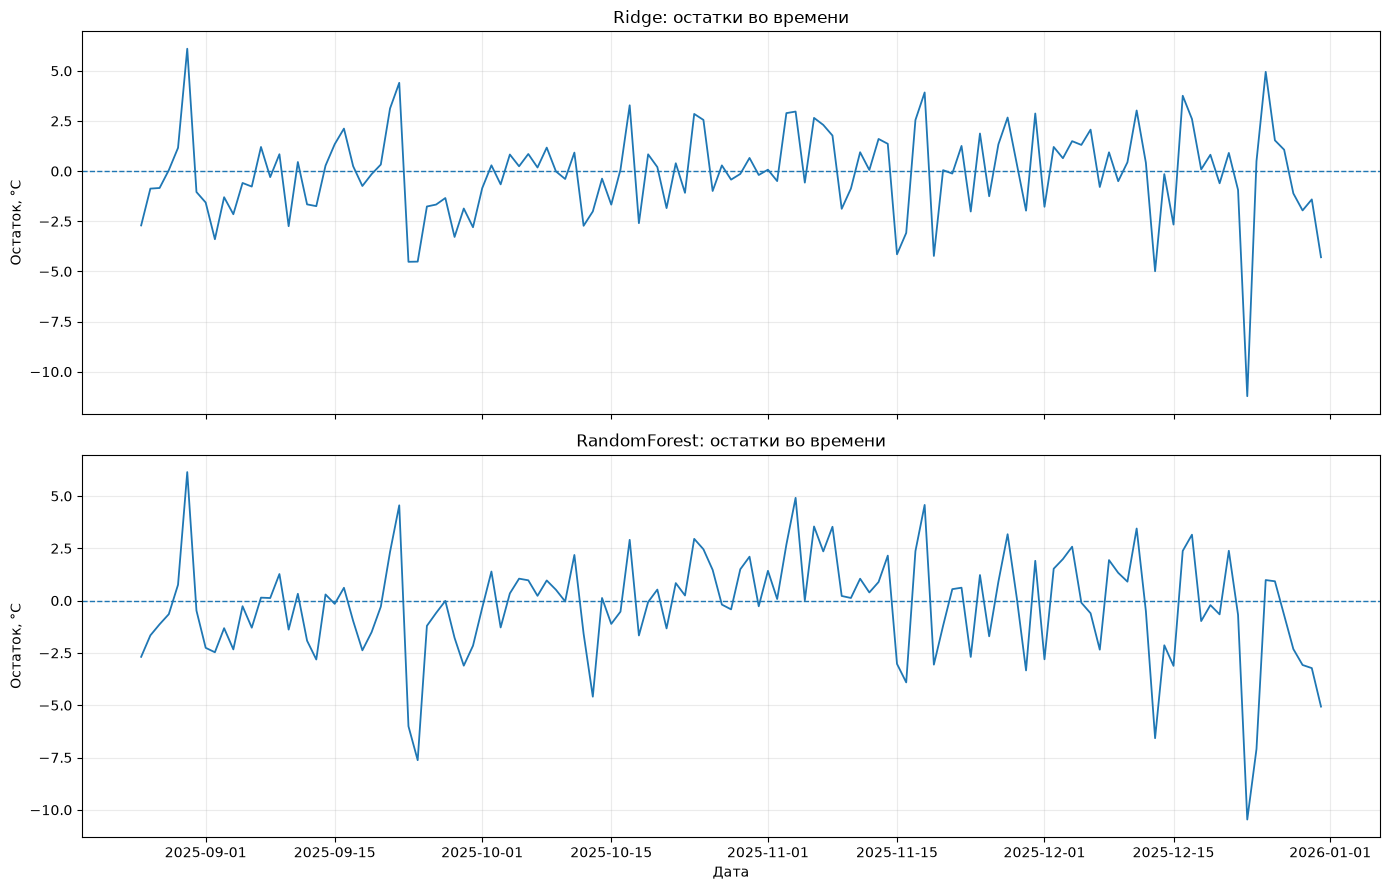

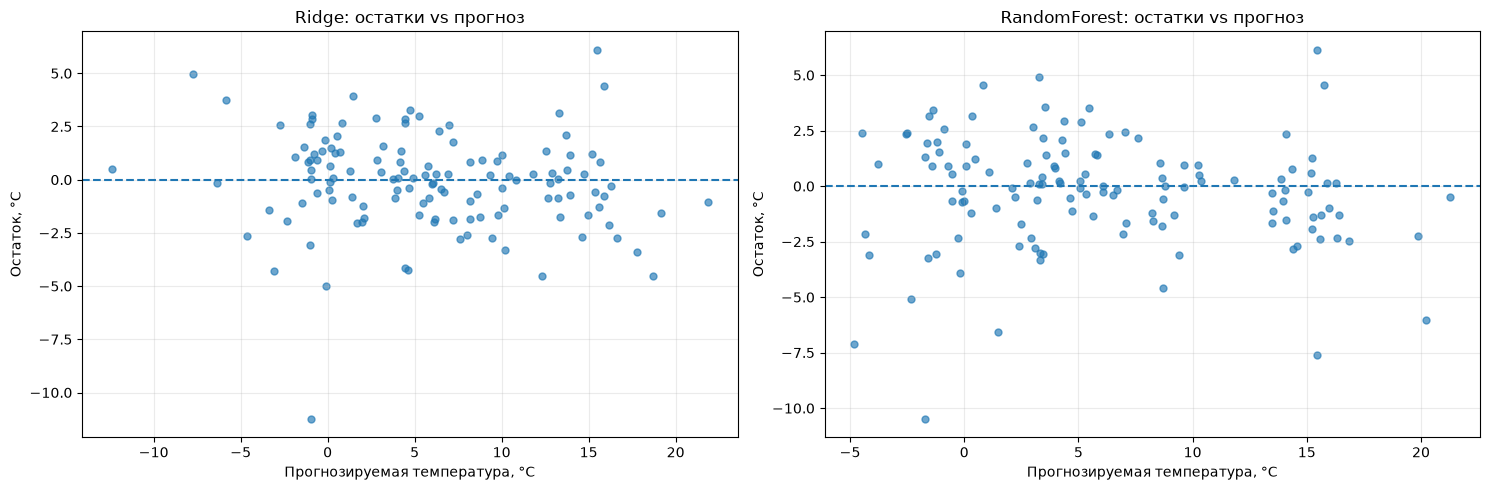

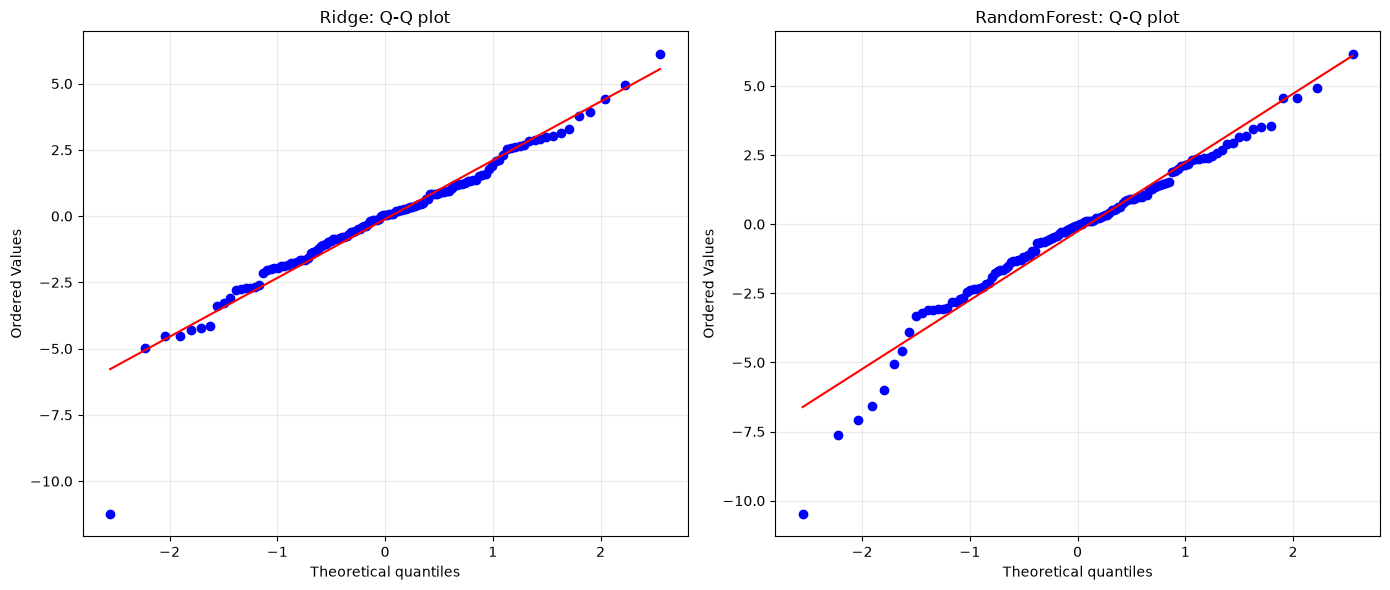

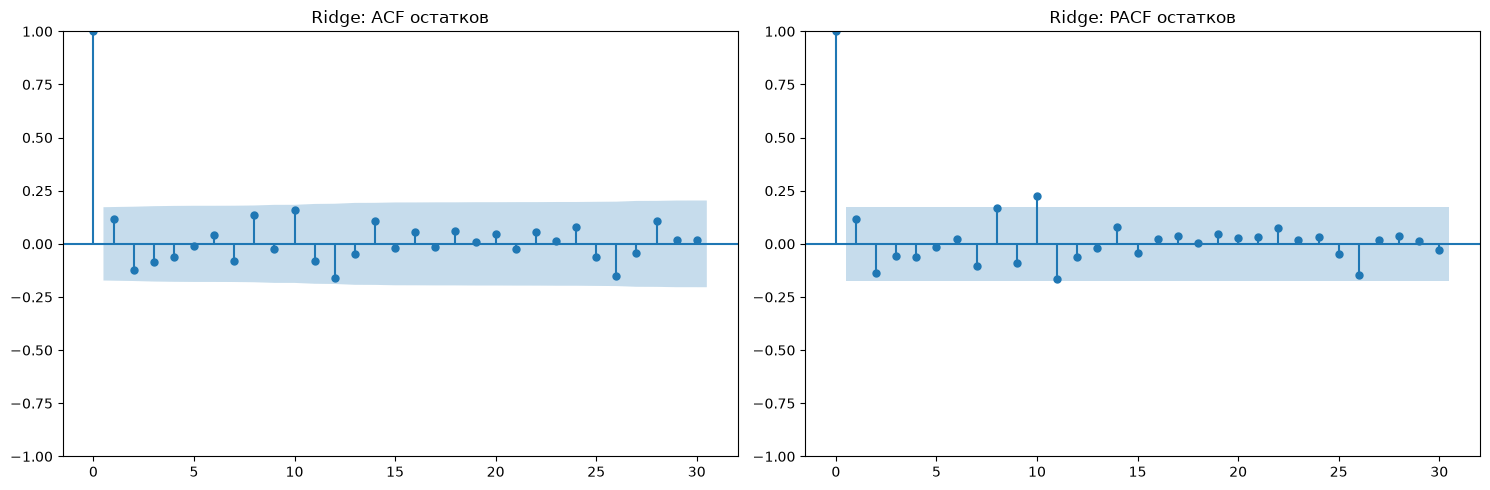

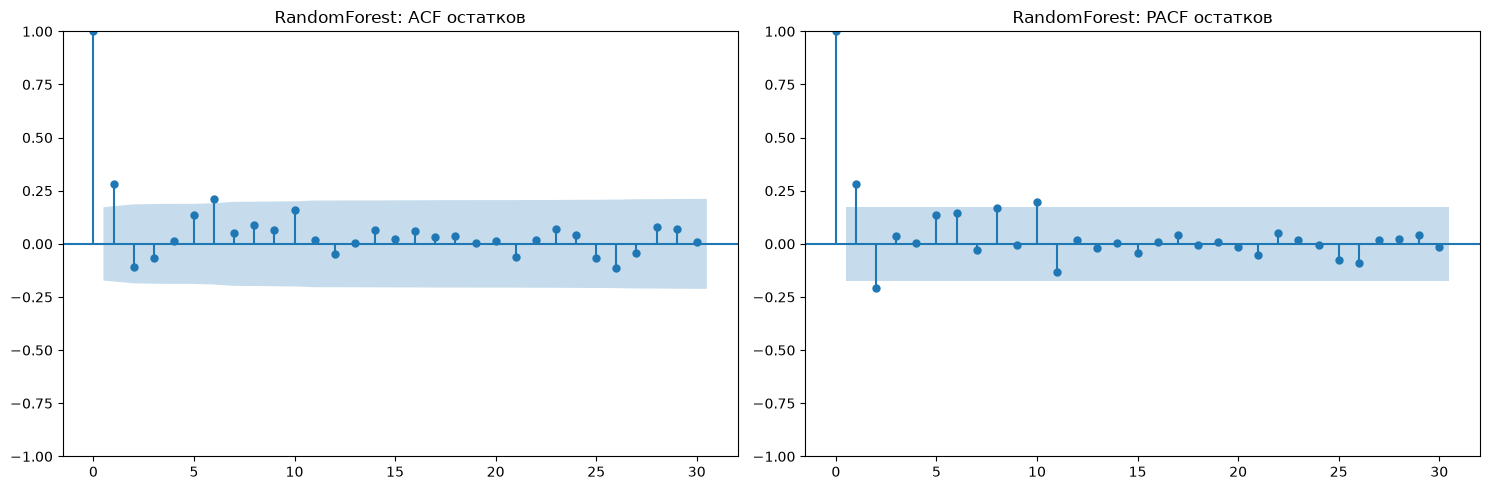


8. ОСТАТКИ МНОГОШАГОВЫХ ПРОГНОЗОВ


,model,strategy,step,observations,mean_residual,MAE,residual_std
0,RandomForest,Direct,1,15,-0.2149,1.8912,2.4869
1,RandomForest,Direct,7,15,-0.0224,3.3058,4.0647
2,RandomForest,Direct,30,15,0.0857,3.4497,4.4558
3,RandomForest,Hybrid,1,15,-0.2149,1.8912,2.4869
4,RandomForest,Hybrid,7,15,-0.5087,3.0475,3.8591
5,RandomForest,Hybrid,30,15,-1.5845,3.2224,4.4808
6,RandomForest,Recursive,1,15,-0.2149,1.8912,2.4869
7,RandomForest,Recursive,7,15,-0.9949,3.2562,3.9346
8,RandomForest,Recursive,30,15,-3.2547,4.2062,4.7234
9,Ridge,Direct,1,15,0.2213,1.7002,2.0875



9. ИТОГОВЫЕ ПРОВЕРКИ
PASS | models_loaded
PASS | all_test_days_predicted
PASS | residuals_finite
PASS | dates_sorted
PASS | ljung_box_completed
PASS | shapiro_completed
PASS | acf_completed
PASS | pacf_completed

Пройдено: 8 из 8

ЗАДАНИЕ 6. ДИАГНОСТИКА ОСТАТКОВ ЗАВЕРШЕНА


In [14]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 6. ДИАГНОСТИКА ОСТАТКОВ
# ============================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from IPython.display import display

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models" / "task5"
TASK5_REPORT_DIR = PROJECT / "reports" / "task5"
REPORT_DIR = PROJECT / "reports" / "task6"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SOURCE = DATA_DIR / "task2_modeling_dataset.csv"
TASK5_PREDICTIONS = (
    TASK5_REPORT_DIR / "predictions.csv"
)

DATE_COL = "date"
TARGET = "temperature_2m_mean"

MODEL_NAMES = [
    "Ridge",
    "RandomForest"
]

TEST_START = pd.Timestamp("2025-08-25")

ALPHA = 0.05

LJUNG_BOX_LAGS = [7, 14, 21, 30]

MAX_ACF_LAG = 30
MAX_PACF_LAG = 30

# Признаки должны точно соответствовать
# заданию 5.

LAGS = [1, 2, 3, 7, 14, 21, 30]
ROLLING_WINDOWS = [3, 7, 14, 30]

# ============================================================
# 2. ЗАГРУЗКА И ПРОВЕРКА ДАННЫХ
# ============================================================

if not SOURCE.exists():
    raise FileNotFoundError(
        f"Не найден датасет: {SOURCE}"
    )

df = pd.read_csv(
    SOURCE,
    parse_dates=[DATE_COL]
)

df = (
    df[[DATE_COL, TARGET]]
    .sort_values(DATE_COL)
    .reset_index(drop=True)
)

assert df[DATE_COL].is_unique
assert df[DATE_COL].is_monotonic_increasing
assert df[TARGET].notna().all()

assert (
    df[DATE_COL].diff().dropna()
    == pd.Timedelta(days=1)
).all()

test_start_idx = int(
    np.searchsorted(
        df[DATE_COL].to_numpy(),
        np.datetime64(TEST_START)
    )
)

assert test_start_idx > max(LAGS)

test_df = df.iloc[
    test_start_idx:
].copy()

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print("Всего наблюдений:", len(df))
print("Тестовых дней:", len(test_df))

print(
    "Тестовый период:",
    test_df[DATE_COL].min().date(),
    "—",
    test_df[DATE_COL].max().date()
)

# ============================================================
# 3. ФУНКЦИЯ ПРИЗНАКОВ ИЗ ЗАДАНИЯ 5
# ============================================================

def make_features(history, forecast_date):

    history = np.asarray(
        history,
        dtype=float
    )

    if len(history) < max(LAGS):
        raise ValueError(
            "Недостаточно исторических данных."
        )

    features = {}

    for lag in LAGS:
        features[f"lag_{lag}"] = history[-lag]

    for window in ROLLING_WINDOWS:

        recent = history[-window:]

        features[f"rolling_mean_{window}"] = (
            float(np.mean(recent))
        )

        features[f"rolling_std_{window}"] = (
            float(np.std(recent, ddof=1))
        )

        features[f"rolling_min_{window}"] = (
            float(np.min(recent))
        )

        features[f"rolling_max_{window}"] = (
            float(np.max(recent))
        )

    features["diff_1"] = (
        history[-1] - history[-2]
    )

    features["diff_7"] = (
        history[-1] - history[-8]
    )

    date = pd.Timestamp(forecast_date)
    dayofyear = date.dayofyear

    features["month"] = date.month
    features["dayofyear"] = dayofyear
    features["dayofweek"] = date.dayofweek

    for harmonic in [1, 2]:

        features[f"sin_{harmonic}"] = np.sin(
            2 * np.pi * harmonic
            * dayofyear / 365.25
        )

        features[f"cos_{harmonic}"] = np.cos(
            2 * np.pi * harmonic
            * dayofyear / 365.25
        )

    return features

# ============================================================
# 4. ЗАГРУЗКА ОБУЧЕННЫХ МОДЕЛЕЙ
# ============================================================

models = {}

for name in MODEL_NAMES:

    model_path = (
        MODEL_DIR / f"{name}_recursive.joblib"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Не найдена модель: {model_path}"
        )

    models[name] = joblib.load(
        model_path
    )

print("\n" + "=" * 80)
print("2. ЗАГРУЖЕННЫЕ МОДЕЛИ")
print("=" * 80)

for name in models:
    print("-", name)

# ============================================================
# 5. ПОСЛЕДОВАТЕЛЬНЫЕ ОДНОШАГОВЫЕ ПРОГНОЗЫ
# ============================================================

values = df[TARGET].to_numpy(dtype=float)

prediction_records = []

for model_name, model in models.items():

    for target_idx in range(
        test_start_idx,
        len(df)
    ):

        # Только фактические значения
        # до прогнозируемого дня.
        history = values[:target_idx]

        forecast_date = (
            df.iloc[target_idx][DATE_COL]
        )

        features = make_features(
            history,
            forecast_date
        )

        X_pred = pd.DataFrame(
            [features]
        )

        prediction = float(
            model.predict(X_pred)[0]
        )

        actual = float(
            values[target_idx]
        )

        prediction_records.append({
            "model": model_name,
            "date": forecast_date,
            "actual": actual,
            "predicted": prediction,
            "residual": actual - prediction
        })

predictions_df = pd.DataFrame(
    prediction_records
)

predictions_df = (
    predictions_df
    .sort_values(["model", "date"])
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("3. ОДНОШАГОВЫЕ ПРОГНОЗЫ")
print("=" * 80)

print(
    "Всего прогнозов:",
    len(predictions_df)
)

display(
    predictions_df.groupby("model").agg(
        observations=("residual", "size"),
        mean_residual=("residual", "mean"),
        std_residual=("residual", "std")
    )
)

# ============================================================
# 6. ОПИСАТЕЛЬНАЯ СТАТИСТИКА ОСТАТКОВ
# ============================================================

descriptive_records = []

for model_name, group in predictions_df.groupby(
    "model"
):

    residuals = group["residual"].to_numpy()

    mae = mean_absolute_error(
        group["actual"],
        group["predicted"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            group["actual"],
            group["predicted"]
        )
    )

    descriptive_records.append({
        "model": model_name,
        "n": len(residuals),
        "mean": float(np.mean(residuals)),
        "median": float(np.median(residuals)),
        "std": float(np.std(residuals, ddof=1)),
        "min": float(np.min(residuals)),
        "max": float(np.max(residuals)),
        "skewness": float(stats.skew(residuals)),
        "kurtosis": float(
            stats.kurtosis(residuals)
        ),
        "MAE": float(mae),
        "RMSE": float(rmse)
    })

descriptive_df = pd.DataFrame(
    descriptive_records
)

print("\n" + "=" * 80)
print("4. ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
print("=" * 80)

display(descriptive_df.round(4))

# ============================================================
# 7. ТЕСТ ЛЬЮНГА — БОКСА
# ============================================================

ljung_records = []

for model_name, group in predictions_df.groupby(
    "model"
):

    residuals = group["residual"].to_numpy()

    lb_result = acorr_ljungbox(
        residuals,
        lags=LJUNG_BOX_LAGS,
        return_df=True
    )

    for lag, row in lb_result.iterrows():

        p_value = float(
            row["lb_pvalue"]
        )

        ljung_records.append({
            "model": model_name,
            "lag": int(lag),
            "lb_stat": float(
                row["lb_stat"]
            ),
            "p_value": p_value,
            "significant": p_value < ALPHA
        })

ljung_df = pd.DataFrame(
    ljung_records
)

print("\n" + "=" * 80)
print("5. ТЕСТ ЛЬЮНГА — БОКСА")
print("=" * 80)

display(ljung_df.round(6))

print(
    "\nH0: автокорреляция отсутствует "
    "до рассматриваемого лага."
)

print(
    "Если p < 0.05, H0 отвергается."
)

# ============================================================
# 8. ТЕСТ ШАПИРО — УИЛКА
# ============================================================

shapiro_records = []

for model_name, group in predictions_df.groupby(
    "model"
):

    residuals = group["residual"].to_numpy()

    statistic, p_value = stats.shapiro(
        residuals
    )

    shapiro_records.append({
        "model": model_name,
        "W_statistic": float(statistic),
        "p_value": float(p_value),
        "normality_rejected": bool(
            p_value < ALPHA
        )
    })

shapiro_df = pd.DataFrame(
    shapiro_records
)

print("\n" + "=" * 80)
print("6. ТЕСТ ШАПИРО — УИЛКА")
print("=" * 80)

display(shapiro_df.round(6))

print(
    "\nH0: остатки имеют нормальное распределение."
)

# ============================================================
# 9. ACF И PACF
# ============================================================

acf_records = []
pacf_records = []

for model_name, group in predictions_df.groupby(
    "model"
):

    residuals = group["residual"].to_numpy()

    acf_values, acf_confint = acf(
        residuals,
        nlags=MAX_ACF_LAG,
        alpha=ALPHA,
        fft=False
    )

    pacf_values, pacf_confint = pacf(
        residuals,
        nlags=MAX_PACF_LAG,
        alpha=ALPHA,
        method="ywm"
    )

    # Интервалы statsmodels построены вокруг
    # оценок корреляций.
    # Значимость: ноль вне доверительного интервала.

    for lag in range(
        1,
        MAX_ACF_LAG + 1
    ):

        acf_low, acf_high = acf_confint[lag]

        significant = (
            acf_low > 0
            or acf_high < 0
        )

        acf_records.append({
            "model": model_name,
            "lag": lag,
            "acf": float(acf_values[lag]),
            "ci_lower": float(acf_low),
            "ci_upper": float(acf_high),
            "significant": bool(significant)
        })

    for lag in range(
        1,
        MAX_PACF_LAG + 1
    ):

        pacf_low, pacf_high = pacf_confint[lag]

        significant = (
            pacf_low > 0
            or pacf_high < 0
        )

        pacf_records.append({
            "model": model_name,
            "lag": lag,
            "pacf": float(pacf_values[lag]),
            "ci_lower": float(pacf_low),
            "ci_upper": float(pacf_high),
            "significant": bool(significant)
        })

acf_df = pd.DataFrame(
    acf_records
)

pacf_df = pd.DataFrame(
    pacf_records
)

print("\n" + "=" * 80)
print("7. ЗНАЧИМЫЕ ЛАГИ ACF / PACF")
print("=" * 80)

for model_name in MODEL_NAMES:

    sig_acf = acf_df[
        (acf_df["model"] == model_name)
        & (acf_df["significant"])
    ]["lag"].tolist()

    sig_pacf = pacf_df[
        (pacf_df["model"] == model_name)
        & (pacf_df["significant"])
    ]["lag"].tolist()

    print(f"\n{model_name}")
    print("ACF:", sig_acf)
    print("PACF:", sig_pacf)

# ============================================================
# 10. ГРАФИКИ ОСТАТКОВ ВО ВРЕМЕНИ
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True
)

for ax, model_name in zip(
    axes,
    MODEL_NAMES
):

    group = predictions_df[
        predictions_df["model"] == model_name
    ]

    ax.plot(
        group["date"],
        group["residual"],
        linewidth=1.3
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{model_name}: остатки во времени"
    )

    ax.set_ylabel("Остаток, °C")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Дата")

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "residuals_over_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. ОСТАТКИ ПРОТИВ ПРОГНОЗОВ
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

for ax, model_name in zip(
    axes,
    MODEL_NAMES
):

    group = predictions_df[
        predictions_df["model"] == model_name
    ]

    ax.scatter(
        group["predicted"],
        group["residual"],
        alpha=0.65,
        s=25
    )

    ax.axhline(
        0,
        linestyle="--"
    )

    ax.set_title(
        f"{model_name}: остатки vs прогноз"
    )

    ax.set_xlabel(
        "Прогнозируемая температура, °C"
    )

    ax.set_ylabel(
        "Остаток, °C"
    )

    ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "residuals_vs_fitted.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. Q-Q ГРАФИКИ
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)

for ax, model_name in zip(
    axes,
    MODEL_NAMES
):

    residuals = predictions_df[
        predictions_df["model"] == model_name
    ]["residual"].to_numpy()

    stats.probplot(
        residuals,
        dist="norm",
        plot=ax
    )

    ax.set_title(
        f"{model_name}: Q-Q plot"
    )

    ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "qq_plots.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. ACF / PACF ГРАФИКИ
# ============================================================

for model_name in MODEL_NAMES:

    residuals = predictions_df[
        predictions_df["model"] == model_name
    ]["residual"].to_numpy()

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(15, 5)
    )

    plot_acf(
        residuals,
        lags=MAX_ACF_LAG,
        alpha=ALPHA,
        ax=axes[0]
    )

    plot_pacf(
        residuals,
        lags=MAX_PACF_LAG,
        alpha=ALPHA,
        method="ywm",
        ax=axes[1]
    )

    axes[0].set_title(
        f"{model_name}: ACF остатков"
    )

    axes[1].set_title(
        f"{model_name}: PACF остатков"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{model_name}_acf_pacf.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

# ============================================================
# 14. ОПИСАТЕЛЬНАЯ ДИАГНОСТИКА
#     МНОГОШАГОВЫХ ПРОГНОЗОВ
# ============================================================

multi_step_summary = pd.DataFrame()

if TASK5_PREDICTIONS.exists():

    multi_df = pd.read_csv(
        TASK5_PREDICTIONS
    )

    multi_df["residual"] = (
        multi_df["actual"]
        - multi_df["predicted"]
    )

    multi_df["abs_error"] = (
        multi_df["residual"].abs()
    )

    multi_step_summary = (
        multi_df[
            multi_df["step"].isin([1, 7, 30])
        ]
        .groupby(
            ["model", "strategy", "step"]
        )
        .agg(
            observations=("residual", "size"),
            mean_residual=("residual", "mean"),
            MAE=("abs_error", "mean"),
            residual_std=("residual", "std")
        )
        .reset_index()
    )

    print("\n" + "=" * 80)
    print("8. ОСТАТКИ МНОГОШАГОВЫХ ПРОГНОЗОВ")
    print("=" * 80)

    display(
        multi_step_summary.round(4)
    )

# ============================================================
# 15. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

predictions_df.to_csv(
    REPORT_DIR / "one_step_residuals.csv",
    index=False,
    encoding="utf-8-sig"
)

descriptive_df.to_csv(
    REPORT_DIR / "residual_descriptive_stats.csv",
    index=False,
    encoding="utf-8-sig"
)

ljung_df.to_csv(
    REPORT_DIR / "ljung_box_results.csv",
    index=False,
    encoding="utf-8-sig"
)

shapiro_df.to_csv(
    REPORT_DIR / "shapiro_results.csv",
    index=False,
    encoding="utf-8-sig"
)

acf_df.to_csv(
    REPORT_DIR / "acf_results.csv",
    index=False,
    encoding="utf-8-sig"
)

pacf_df.to_csv(
    REPORT_DIR / "pacf_results.csv",
    index=False,
    encoding="utf-8-sig"
)

if not multi_step_summary.empty:
    multi_step_summary.to_csv(
        REPORT_DIR / "multistep_residual_summary.csv",
        index=False,
        encoding="utf-8-sig"
    )

# ============================================================
# 16. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "models_loaded": (
        len(models) == len(MODEL_NAMES)
    ),
    "all_test_days_predicted": all(
        len(predictions_df[
            predictions_df["model"] == name
        ]) == len(test_df)
        for name in MODEL_NAMES
    ),
    "residuals_finite": bool(
        np.isfinite(
            predictions_df["residual"]
        ).all()
    ),
    "dates_sorted": bool(
        df[DATE_COL].is_monotonic_increasing
    ),
    "ljung_box_completed": (
        len(ljung_df)
        == len(MODEL_NAMES) * len(LJUNG_BOX_LAGS)
    ),
    "shapiro_completed": (
        len(shapiro_df) == len(MODEL_NAMES)
    ),
    "acf_completed": (
        len(acf_df)
        == len(MODEL_NAMES) * MAX_ACF_LAG
    ),
    "pacf_completed": (
        len(pacf_df)
        == len(MODEL_NAMES) * MAX_PACF_LAG
    )
}

print("\n" + "=" * 80)
print("9. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

experiment_info = {
    "task": 6,
    "models": MODEL_NAMES,
    "test_start": str(TEST_START.date()),
    "test_observations": len(test_df),
    "alpha": ALPHA,
    "ljung_box_lags": LJUNG_BOX_LAGS,
    "acf_max_lag": MAX_ACF_LAG,
    "pacf_max_lag": MAX_PACF_LAG,
    "diagnostic_scope": (
        "Chronological one-step residuals. "
        "Multi-step overlapping forecasts "
        "are summarized descriptively."
    ),
    "checks": checks
}

(
    REPORT_DIR / "diagnostic_config.json"
).write_text(
    json.dumps(
        experiment_info,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nЗАДАНИЕ 6. ДИАГНОСТИКА ОСТАТКОВ ЗАВЕРШЕНА")


### Анализ результатов выполнения задания 6

В ходе выполнения шестого задания была проведена статистическая диагностика остатков моделей Ridge и RandomForest, использованных для прогнозирования среднесуточной температуры воздуха в Москве.

Для анализа были сформированы последовательные одношаговые прогнозы на независимом тестовом периоде с 25 августа по 31 декабря 2025 года.

Для каждой модели получено 129 прогнозных значений и соответствующих остатков, рассчитанных как разность между фактической и прогнозируемой температурой.

Диагностика включала описательную статистику, тест Льюнга — Бокса, тест Шапиро — Уилка, анализ автокорреляционной и частной автокорреляционной функций, а также построение диагностических графиков.

**1. Описательная статистика остатков**

Модель Ridge продемонстрировала следующие результаты:

- MAE = 1,6426 °C;
- RMSE = 2,2490 °C;
- средний остаток = −0,1145 °C;
- стандартное отклонение остатков = 2,2548 °C.

Для RandomForest получены следующие значения:

- MAE = 1,8377 °C;
- RMSE = 2,5194 °C;
- средний остаток = −0,2622 °C;
- стандартное отклонение остатков = 2,5155 °C.

Таким образом, Ridge показала меньшие ошибки прогнозирования по обеим основным метрикам.

По сравнению с RandomForest ошибка MAE снизилась приблизительно на 10,6%, а RMSE — на 10,7%.

Средние остатки обеих моделей имеют отрицательное значение, что свидетельствует о небольшом среднем завышении прогнозируемой температуры.

При этом у Ridge систематическое смещение выражено слабее.

**2. Анализ автокорреляции остатков**

Для проверки наличия временной зависимости ошибок был использован тест Льюнга — Бокса на лагах 7, 14, 21 и 30.

Для Ridge получены значения p-value:

- лаг 7 — 0,490206;
- лаг 14 — 0,154813;
- лаг 21 — 0,466767;
- лаг 30 — 0,506201.

Все значения превышают установленный уровень значимости 0,05.

Следовательно, тест Льюнга — Бокса не выявил статистически значимой совокупной автокорреляции остатков Ridge на исследованных горизонтах.

Для RandomForest получены следующие значения p-value:

- лаг 7 — 0,003094;
- лаг 14 — 0,014507;
- лаг 21 — 0,100961;
- лаг 30 — 0,215848.

На лагах 7 и 14 нулевая гипотеза об отсутствии автокорреляции отвергается.

Это свидетельствует о том, что ошибки RandomForest содержат статистически значимую временную зависимость на коротких интервалах.

Полученный результат позволяет предположить, что RandomForest не полностью учитывает отдельные закономерности изменения температуры.

**3. Проверка нормальности распределения остатков**

Для оценки нормальности распределения использовался тест Шапиро — Уилка.

Для Ridge получены:

- статистика W = 0,953668;
- p-value = 0,000233.

Для RandomForest:

- статистика W = 0,961122;
- p-value = 0,000951.

В обоих случаях значения p-value меньше 0,05.

Следовательно, нулевая гипотеза о нормальном распределении остатков отвергается для обеих моделей.

Дополнительный анализ формы распределения показал отрицательную асимметрию:

- Ridge: −0,7896;
- RandomForest: −0,7710.

Также выявлен положительный эксцесс:

- Ridge: 3,7917;
- RandomForest: 2,0688.

Это указывает на асимметрию распределений и наличие более тяжёлых хвостов по сравнению с нормальным распределением.

Нарушение нормальности само по себе не означает низкого качества прогнозирования, однако должно учитываться при построении статистических интервалов и оценке неопределённости прогнозов.

**4. Анализ ACF и PACF**

Для исследования структуры временной зависимости остатков были рассчитаны автокорреляционная функция ACF и частная автокорреляционная функция PACF.

Для Ridge значимых лагов ACF среди первых 30 обнаружено не было.

В PACF выделен значимый лаг 10.

Для RandomForest значимыми оказались:

- ACF: лаги 1 и 6;
- PACF: лаги 1, 2 и 10.

Полученные результаты согласуются с результатами теста Льюнга — Бокса: остатки RandomForest демонстрируют более выраженную временную зависимость по сравнению с Ridge.

Вместе с тем отдельные значимые лаги требуют осторожной интерпретации, поскольку при множественных статистических проверках возможны случайные отклонения.

**5. Сравнительная оценка моделей**

На основании проведённой диагностики можно выделить несколько основных результатов.

Во-первых, Ridge продемонстрировала более высокую точность одношагового прогнозирования по метрикам MAE и RMSE.

Во-вторых, у Ridge наблюдается меньшее среднее смещение прогнозов и меньший разброс остатков.

В-третьих, тест Льюнга — Бокса не выявил значимой совокупной автокорреляции остатков Ridge на исследованных лагах, тогда как для RandomForest автокорреляция обнаружена на коротких интервалах.

В-четвёртых, обе модели характеризуются статистически значимым отклонением распределения остатков от нормального.

Таким образом, Ridge показывает более благоприятные диагностические характеристики, хотя её остатки также не удовлетворяют всем идеализированным статистическим предположениям.

**6. Ограничения анализа**

Диагностика проводилась на 129 последовательных одношаговых прогнозах.

Результаты нельзя автоматически переносить на многошаговые прогнозы, поскольку при увеличении горизонта структура ошибок может изменяться.

Кроме того, отсутствие статистически значимой автокорреляции не доказывает полной независимости остатков.

Проверка нормальности и отдельные тесты автокорреляции также могут быть чувствительны к выбросам, объёму выборки и множественному тестированию.

Для более полной оценки качества моделей рекомендуется дополнительно исследовать ошибки по сезонам, экстремальным температурным значениям и отдельным временным интервалам.

### Итоговый вывод

В результате выполнения задания 6 проведена комплексная статистическая диагностика остатков моделей Ridge и RandomForest.

Для каждой модели проанализировано 129 последовательных одношаговых прогнозов.

Модель Ridge продемонстрировала более высокую точность: MAE = 1,6426 °C и RMSE = 2,2490 °C.

Тест Льюнга — Бокса не выявил значимой совокупной автокорреляции остатков Ridge на исследованных лагах. Для RandomForest обнаружена статистически значимая автокорреляция на лагах 7 и 14 в рамках соответствующих тестов.

Проверка Шапиро — Уилка показала, что распределение остатков обеих моделей статистически отличается от нормального.

Анализ ACF и PACF дополнительно подтвердил более выраженную временную зависимость ошибок RandomForest.

Таким образом, по совокупности рассмотренных показателей Ridge является более предпочтительной моделью для одношагового прогнозирования среднесуточной температуры в рамках проведённого эксперимента.

Все 8 автоматических проверок выполнены успешно.

Полученные результаты могут использоваться при дальнейшем сравнении моделей, анализе их интерпретируемости и оценке устойчивости прогнозирования.

# Задание 7. Комплексная оценка качества моделей машинного обучения

### Цель работы

Провести комплексное сравнение регрессионных моделей прогнозирования среднесуточной температуры воздуха в Москве с использованием расширенного набора метрик, временной кросс-валидации, статистических тестов и взвешенного рейтинга.

### Постановка задачи

Необходимо:

1. Загрузить подготовленную обучающую выборку и результаты подбора моделей из предыдущих заданий.
2. Выбрать пять лучших обучаемых моделей и базовую модель Naive.
3. Выполнить прогнозирование с использованием пяти последовательных временных фолдов.
4. Рассчитать MAE, RMSE, MASE, SMAPE и R².
5. Проверить применимость RMSLE к данным, содержащим отрицательные температуры.
6. Рассчитать среднее значение и стандартное отклонение метрик по фолдам.
7. Выполнить попарные тесты Диболда — Мариано для пяти выбранных моделей.
8. Проверить остатки моделей на автокорреляцию и нормальность распределения.
9. Оценить интерпретируемость моделей.
10. Сформировать комплексный рейтинг по взвешенным критериям.
11. Построить сравнительные графики.
12. Сохранить результаты анализа.

### Методика

Для оценки качества применяется `TimeSeriesSplit` с пятью фолдами. Все модели оцениваются на одинаковых временных интервалах.

Основные метрики:

- MAE — средняя абсолютная ошибка;
- RMSE — корень из средней квадратичной ошибки;
- MASE — средняя абсолютная масштабированная ошибка;
- SMAPE — симметричная средняя абсолютная процентная ошибка;
- R² — коэффициент детерминации;
- RMSLE — среднеквадратичная логарифмическая ошибка.

Поскольку температура воздуха может принимать отрицательные значения, стандартная RMSLE не применяется без преобразования целевой переменной. Непосредственная замена отрицательных значений или произвольный сдвиг температуры изменили бы смысл метрики, поэтому неприменимость RMSLE фиксируется отдельно.

Для проверки статистической значимости различий моделей используется тест Диболда — Мариано с квадратичной функцией потерь и учётом автокорреляции разностей потерь.

Комплексная оценка рассчитывается по трём критериям:

- точность прогнозирования — 50%;
- диагностика остатков — 30%;
- интерпретируемость — 20%.

### Ожидаемый результат

Получены сравнительные таблицы метрик, результаты статистических тестов, диагностические характеристики и итоговый рейтинг моделей.

Определены преимущества и ограничения отдельных алгоритмов, а также сформулированы рекомендации по выбору модели для дальнейшего исследования.

1. ИСХОДНЫЕ ДАННЫЕ
Наблюдений: 512
Признаков: 34
Начало: 2024-03-31
Конец: 2025-08-24

Температура:
Минимум: -12.5
Максимум: 27.2

2. ЗАГРУЖЕННЫЕ МОДЕЛИ
Lasso — Pipeline
ElasticNet — Pipeline
LinearSVR — Pipeline
Ridge — Pipeline
ExtraTrees — ExtraTreesRegressor

3. ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ

Фолд 1: train=87, validation=85

Фолд 2: train=172, validation=85

Фолд 3: train=257, validation=85

Фолд 4: train=342, validation=85

Фолд 5: train=427, validation=85

Метрики по фолдам:


,fold,model,MAE,RMSE,MASE,SMAPE,R2,RMSLE
0,1,Naive,1.1576,1.4303,0.6016,5.9108,0.7231,0.0698
1,1,Lasso,1.4377,1.7483,0.7471,7.4638,0.5864,0.0858
2,1,ElasticNet,1.2457,1.5446,0.6473,6.3083,0.6772,0.0754
3,1,LinearSVR,1.4440,1.8346,0.7503,7.2559,0.5445,0.0871
4,1,Ridge,1.8098,2.1141,0.9404,9.1864,0.3952,0.1044
5,1,ExtraTrees,2.1020,2.6898,1.0923,10.5775,0.0209,0.1250
6,2,Naive,1.8141,2.3887,1.1755,58.5846,0.8367,NaN
7,2,Lasso,3.0161,3.5835,1.9544,86.2903,0.6324,NaN
8,2,ElasticNet,3.4118,4.0799,2.2108,88.7675,0.5236,NaN
9,2,LinearSVR,2.8588,3.5192,1.8524,84.0247,0.6455,NaN



4. СВОДНЫЕ МЕТРИКИ


,rank_rmse,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MASE_mean,MASE_std,SMAPE_mean,SMAPE_std,R2_mean,R2_std
0,1,Naive,1.6492,0.3370,2.2305,0.5408,0.9813,0.2564,40.2920,34.0832,0.7346,0.1156
1,2,Lasso,1.9994,0.6374,2.5068,0.7425,1.1985,0.4749,48.5881,40.6736,0.6733,0.1170
2,3,ElasticNet,2.0529,0.8501,2.5630,0.9923,1.2378,0.6069,48.5613,41.6359,0.6722,0.1295
3,4,LinearSVR,2.0910,0.6450,2.6173,0.7825,1.2532,0.4739,50.3041,43.1214,0.6322,0.1775
4,5,Ridge,2.4048,0.8502,2.9197,1.0026,1.4427,0.6125,54.3410,47.9089,0.5303,0.2610
5,6,ExtraTrees,3.0830,1.8405,3.7822,2.0214,1.8708,1.2612,62.8397,59.6276,0.1929,0.5488



5. ПРОВЕРКА RMSLE
{
  "negative_target_present": true,
  "negative_target_count": 90,
  "rmsle_folds_available": 12,
  "total_model_folds": 30
}

RMSLE рассчитывается только для фолдов, где фактические и прогнозные значения неотрицательны.
Для общего рейтинга RMSLE не используется: температура может быть отрицательной.

6. ДИАГНОСТИКА ОСТАТКОВ


,model,fold,mean_residual,abs_mean_residual,ljung_p,shapiro_p,ljung_rejected,shapiro_rejected
0,Lasso,1,1.14757,1.14757,0.76144,0.89461,False,False
1,Lasso,2,-2.61275,2.61275,0.00982,0.93837,True,False
2,Lasso,3,-0.60797,0.60797,0.34070,0.00347,False,True
3,Lasso,4,-0.30162,0.30162,0.07923,0.02486,False,True
4,Lasso,5,0.22167,0.22167,0.41054,0.93852,False,False
5,ElasticNet,1,-0.17552,0.17552,0.00001,0.68757,True,False
6,ElasticNet,2,-3.07818,3.07818,0.00000,0.76145,True,False
7,ElasticNet,3,-0.45031,0.45031,0.24011,0.10840,False,False
8,ElasticNet,4,-0.15781,0.15781,0.00479,0.04012,True,True
9,ElasticNet,5,-0.14026,0.14026,0.96094,0.82534,False,False


... (4 outputs left out)


mean_loss_diff = MSE(model_a) - MSE(model_b)
Отрицательное значение означает, что model_a имеет меньшую среднюю квадратичную ошибку.
Тест использует приближённую асимптотическую оценку с HAC и коррекцией Холма.

8. ИТОГОВЫЙ РЕЙТИНГ


,final_rank,model,MAE_mean,RMSE_mean,MASE_mean,SMAPE_mean,R2_mean,accuracy_score,diagnostics_score,interpretability_score,total_score
0,1,Lasso,1.9994,2.5068,1.1985,48.5881,0.6733,0.9995,0.9253,1.0,0.9773
1,2,ElasticNet,2.0529,2.5630,1.2378,48.5613,0.6722,0.9620,0.6667,1.0,0.8810
2,3,LinearSVR,2.0910,2.6173,1.2532,50.3041,0.6322,0.9064,0.4976,0.8,0.7625
3,4,Ridge,2.4048,2.9197,1.4427,54.3410,0.5303,0.6336,0.2902,1.0,0.6039
4,5,ExtraTrees,3.0830,3.7822,1.8708,62.8397,0.1929,0.0000,0.0000,0.6,0.1200



9. СРАВНЕНИЕ С NAIVE


,model,MAE,RMSE,Naive_MAE,Naive_RMSE,RMSE_improvement_pct
0,Lasso,1.9994,2.5068,1.6492,2.2305,-12.3902
1,ElasticNet,2.0529,2.5630,1.6492,2.2305,-14.9069
2,LinearSVR,2.0910,2.6173,1.6492,2.2305,-17.3458
3,Ridge,2.4048,2.9197,1.6492,2.2305,-30.9004
4,ExtraTrees,3.0830,3.7822,1.6492,2.2305,-69.5725


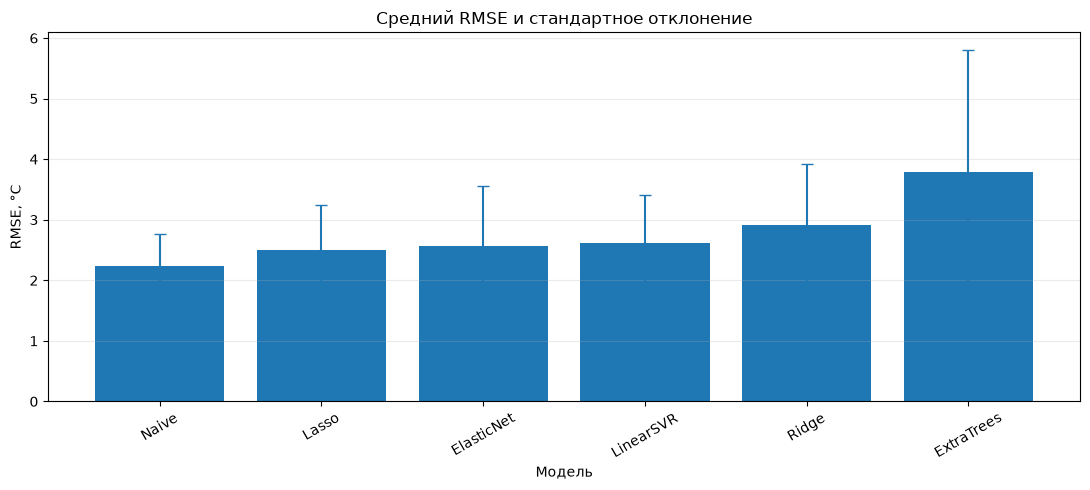

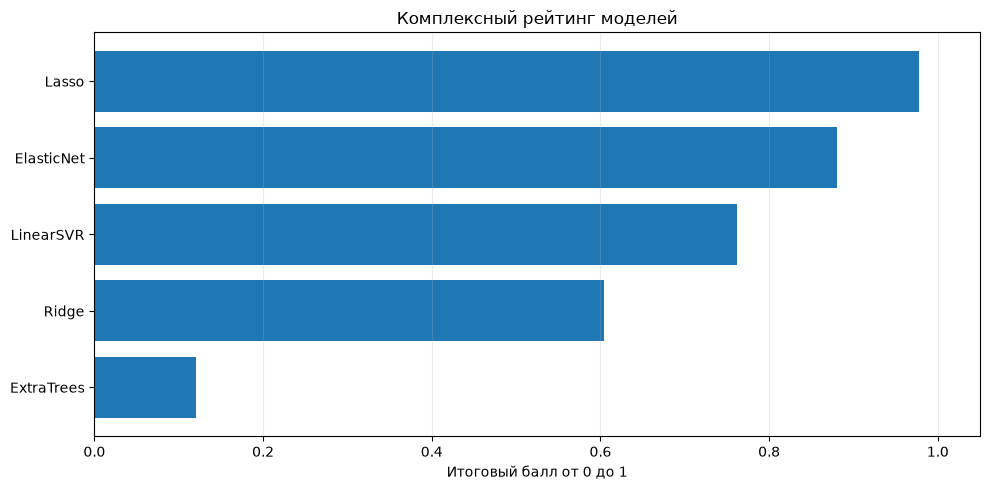

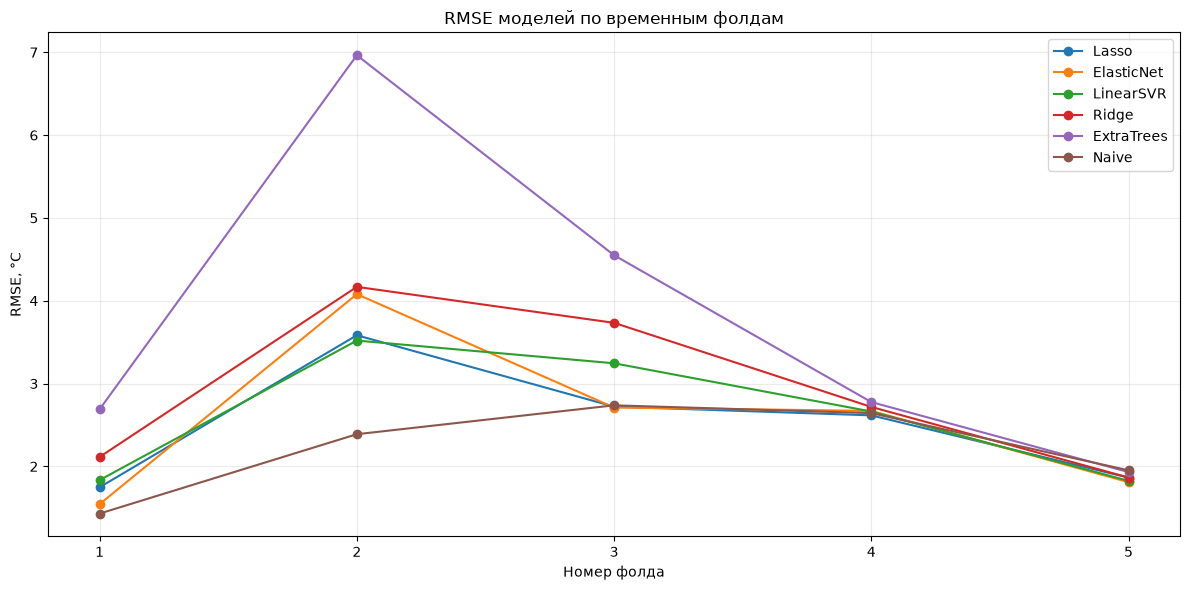


10. ИТОГОВЫЕ ПРОВЕРКИ
PASS | data_loaded
PASS | models_loaded
PASS | all_folds_evaluated
PASS | baseline_present
PASS | metrics_finite
PASS | predictions_finite
PASS | dm_completed
PASS | diagnostics_completed
PASS | ranking_completed
PASS | ranking_scores_valid
PASS | results_saved

Пройдено: 11 из 11

Лучшая модель по рейтингу:
Lasso | балл: 0.9773

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_4/reports/task7

ЗАДАНИЕ 7 ЗАВЕРШЕНО


In [15]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 7. КОМПЛЕКСНОЕ СРАВНЕНИЕ МОДЕЛЕЙ
# ============================================================

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. КОНФИГУРАЦИЯ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
TASK4_MODELS = PROJECT / "models" / "task4"
REPORT_DIR = PROJECT / "reports" / "task7"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE = DATA_DIR / "task3_trainval.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

MODEL_NAMES = [
    "Lasso",
    "ElasticNet",
    "LinearSVR",
    "Ridge",
    "ExtraTrees"
]

BASELINE_NAME = "Naive"

N_SPLITS = 5
ALPHA = 0.05
RANDOM_STATE = 42

# Интерпретируемость:
# 5 — высокая, 1 — низкая.
#
# Это экспертная шкала, а не
# статистически измеренная величина.

INTERPRETABILITY = {
    "Lasso": 5,
    "ElasticNet": 5,
    "LinearSVR": 4,
    "Ridge": 5,
    "ExtraTrees": 3
}

WEIGHTS = {
    "accuracy": 0.50,
    "diagnostics": 0.30,
    "interpretability": 0.20
}

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv(
    SOURCE,
    parse_dates=[DATE_COL]
)

df = (
    df.sort_values(DATE_COL)
    .reset_index(drop=True)
)

assert df[DATE_COL].is_unique
assert df[DATE_COL].is_monotonic_increasing
assert df[TARGET].notna().all()

feature_cols = [
    col for col in df.columns
    if col not in [DATE_COL, TARGET]
]

X = df[feature_cols].copy()
y = df[TARGET].astype(float).copy()

assert X.notna().all().all()

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print("Наблюдений:", len(df))
print("Признаков:", len(feature_cols))
print("Начало:", df[DATE_COL].min().date())
print("Конец:", df[DATE_COL].max().date())

print("\nТемпература:")
print("Минимум:", round(y.min(), 3))
print("Максимум:", round(y.max(), 3))

# ============================================================
# 3. ЗАГРУЗКА НАСТРОЕННЫХ МОДЕЛЕЙ
# ============================================================

models = {}

for name in MODEL_NAMES:

    path = TASK4_MODELS / f"{name}.joblib"

    if not path.exists():
        raise FileNotFoundError(
            f"Не найдена модель: {path}"
        )

    # clone переносит настройки модели,
    # но не переносит обученное состояние.

    models[name] = clone(joblib.load(path))

print("\n" + "=" * 80)
print("2. ЗАГРУЖЕННЫЕ МОДЕЛИ")
print("=" * 80)

for name, model in models.items():
    print(name, "—", type(model).__name__)

# ============================================================
# 4. МЕТРИКИ
# ============================================================

def calculate_smape(actual, predicted):
    """
    SMAPE в процентах.

    Для случая actual=predicted=0
    вклад ошибки принимается равным 0.
    """

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    denominator = (
        np.abs(actual) + np.abs(predicted)
    )

    numerator = 2 * np.abs(
        actual - predicted
    )

    ratios = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator > 0
    )

    return float(100 * np.mean(ratios))


def calculate_mase(
    actual,
    predicted,
    training_target
):
    """
    MASE для одношагового прогноза.

    Масштаб рассчитывается только
    по обучающей части текущего фолда.
    """

    training_target = np.asarray(
        training_target,
        dtype=float
    )

    naive_scale = np.mean(
        np.abs(np.diff(training_target))
    )

    if naive_scale <= 0:
        return np.nan

    return float(
        mean_absolute_error(
            actual,
            predicted
        ) / naive_scale
    )


def calculate_metrics(
    actual,
    predicted,
    training_target
):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # RMSLE не рассчитывается, если есть
    # значения меньше нуля.

    rmsle = np.nan

    if (
        np.all(actual >= 0)
        and np.all(predicted >= 0)
    ):

        rmsle = float(
            np.sqrt(
                np.mean(
                    (
                        np.log1p(actual)
                        - np.log1p(predicted)
                    ) ** 2
                )
            )
        )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MASE": calculate_mase(
            actual,
            predicted,
            training_target
        ),
        "SMAPE": calculate_smape(
            actual,
            predicted
        ),
        "R2": float(
            r2_score(actual, predicted)
        ),
        "RMSLE": rmsle
    }

# ============================================================
# 5. ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=N_SPLITS
)

fold_records = []
prediction_records = []

print("\n" + "=" * 80)
print("3. ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ")
print("=" * 80)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    print(
        f"\nФолд {fold}: "
        f"train={len(train_idx)}, "
        f"validation={len(val_idx)}"
    )

    # --------------------------------------------------------
    # Базовый одношаговый прогноз:
    # фактическая температура предыдущего дня.
    #
    # Это rolling-origin оценка:
    # перед каждым прогнозом вчерашнее
    # наблюдение уже известно.
    # --------------------------------------------------------

    naive_pred = y.iloc[
        val_idx - 1
    ].to_numpy(dtype=float)

    # --------------------------------------------------------
    # Модели машинного обучения
    # --------------------------------------------------------

    fold_predictions = {
        BASELINE_NAME: naive_pred
    }

    for model_name, model_template in models.items():

        model = clone(model_template)

        model.fit(
            X_train,
            y_train
        )

        predicted = model.predict(
            X_val
        )

        fold_predictions[model_name] = (
            np.asarray(predicted, dtype=float)
        )

    # --------------------------------------------------------
    # Расчёт метрик и сохранение прогнозов
    # --------------------------------------------------------

    for model_name, predicted in fold_predictions.items():

        metrics = calculate_metrics(
            y_val.to_numpy(),
            predicted,
            y_train.to_numpy()
        )

        fold_records.append({
            "fold": fold,
            "model": model_name,
            **metrics
        })

        for position, original_idx in enumerate(val_idx):

            actual = float(
                y.iloc[original_idx]
            )

            prediction = float(
                predicted[position]
            )

            prediction_records.append({
                "fold": fold,
                "model": model_name,
                "date": df.iloc[original_idx][DATE_COL],
                "actual": actual,
                "predicted": prediction,
                "residual": actual - prediction,
                "squared_error": (
                    actual - prediction
                ) ** 2
            })

fold_metrics = pd.DataFrame(
    fold_records
)

predictions_df = pd.DataFrame(
    prediction_records
)

print("\nМетрики по фолдам:")
display(
    fold_metrics.round(4)
)

# ============================================================
# 6. СРЕДНИЕ МЕТРИКИ И СТАНДАРТНЫЕ ОТКЛОНЕНИЯ
# ============================================================

metric_names = [
    "MAE",
    "RMSE",
    "MASE",
    "SMAPE",
    "R2"
]

summary = (
    fold_metrics
    .groupby("model")[metric_names]
    .agg(["mean", "std"])
)

summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = (
    summary.reset_index()
    .sort_values("RMSE_mean")
    .reset_index(drop=True)
)

summary.insert(
    0,
    "rank_rmse",
    np.arange(1, len(summary) + 1)
)

print("\n" + "=" * 80)
print("4. СВОДНЫЕ МЕТРИКИ")
print("=" * 80)

display(summary.round(4))

# ============================================================
# 7. ПРОВЕРКА ПРИМЕНИМОСТИ RMSLE
# ============================================================

rmsle_status = {
    "negative_target_present": bool(
        (y < 0).any()
    ),
    "negative_target_count": int(
        (y < 0).sum()
    ),
    "rmsle_folds_available": int(
        fold_metrics["RMSLE"].notna().sum()
    ),
    "total_model_folds": int(
        len(fold_metrics)
    )
}

print("\n" + "=" * 80)
print("5. ПРОВЕРКА RMSLE")
print("=" * 80)

print(json.dumps(
    rmsle_status,
    ensure_ascii=False,
    indent=2
))

print(
    "\nRMSLE рассчитывается только для "
    "фолдов, где фактические и прогнозные "
    "значения неотрицательны."
)

print(
    "Для общего рейтинга RMSLE не используется: "
    "температура может быть отрицательной."
)

# ============================================================
# 8. ДИАГНОСТИКА ОСТАТКОВ ПО ФОЛДАМ
# ============================================================

# Для статистических тестов каждый фолд
# рассматривается отдельно.
#
# Это позволяет не создавать искусственную
# временную связь на границах фолдов.

diagnostic_records = []

for model_name in MODEL_NAMES:

    model_data = predictions_df[
        predictions_df["model"] == model_name
    ]

    for fold, group in model_data.groupby("fold"):

        residuals = group[
            "residual"
        ].to_numpy(dtype=float)

        # Льюнг — Бокс на лаге 7.
        lb = acorr_ljungbox(
            residuals,
            lags=[7],
            return_df=True
        )

        lb_p = float(
            lb["lb_pvalue"].iloc[0]
        )

        # Шапиро — Уилк.
        shapiro_stat, shapiro_p = (
            stats.shapiro(residuals)
        )

        diagnostic_records.append({
            "model": model_name,
            "fold": fold,
            "mean_residual": float(
                np.mean(residuals)
            ),
            "abs_mean_residual": float(
                abs(np.mean(residuals))
            ),
            "ljung_p": lb_p,
            "shapiro_p": float(shapiro_p),
            "ljung_rejected": bool(
                lb_p < ALPHA
            ),
            "shapiro_rejected": bool(
                shapiro_p < ALPHA
            )
        })

diagnostics_df = pd.DataFrame(
    diagnostic_records
)

diagnostic_summary = (
    diagnostics_df
    .groupby("model")
    .agg(
        mean_abs_bias=(
            "abs_mean_residual",
            "mean"
        ),
        ljung_rejection_rate=(
            "ljung_rejected",
            "mean"
        ),
        shapiro_rejection_rate=(
            "shapiro_rejected",
            "mean"
        ),
        mean_ljung_p=(
            "ljung_p",
            "mean"
        ),
        mean_shapiro_p=(
            "shapiro_p",
            "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("6. ДИАГНОСТИКА ОСТАТКОВ")
print("=" * 80)

display(diagnostics_df.round(5))

print("\nСводная диагностика:")
display(diagnostic_summary.round(5))

# ============================================================
# 9. ТЕСТ ДИБОЛДА — МАРИАНО
# ============================================================

# Сравниваем пять обучаемых моделей.
# Naive используется как benchmark отдельно.
#
# Функция потерь — квадрат ошибки.
#
# Для учёта зависимости разностей потерь
# используем HAC-оценку долгосрочной дисперсии.
#
# Автоковариации рассчитываются внутри
# каждого фолда, без соединения границ.

def dm_test(
    model_a,
    model_b,
    prediction_data,
    max_lag=7
):

    differences_by_fold = []

    for fold in sorted(
        prediction_data["fold"].unique()
    ):

        a = (
            prediction_data[
                (prediction_data["model"] == model_a)
                & (prediction_data["fold"] == fold)
            ]
            .sort_values("date")
        )

        b = (
            prediction_data[
                (prediction_data["model"] == model_b)
                & (prediction_data["fold"] == fold)
            ]
            .sort_values("date")
        )

        if not np.array_equal(
            a["date"].to_numpy(),
            b["date"].to_numpy()
        ):
            raise ValueError(
                "Прогнозные даты моделей не совпадают."
            )

        d = (
            a["squared_error"].to_numpy()
            - b["squared_error"].to_numpy()
        )

        differences_by_fold.append(d)

    all_d = np.concatenate(
        differences_by_fold
    )

    n = len(all_d)
    mean_d = float(np.mean(all_d))

    # Центрирование относительно общего среднего.
    centered = [
        d - mean_d
        for d in differences_by_fold
    ]

    gamma0 = (
        sum(
            float(np.sum(d * d))
            for d in centered
        ) / n
    )

    long_run_variance = gamma0

    effective_lag = min(
        max_lag,
        min(len(d) for d in centered) - 1
    )

    for lag in range(
        1,
        effective_lag + 1
    ):

        gamma = (
            sum(
                float(
                    np.sum(
                        d[lag:] * d[:-lag]
                    )
                )
                for d in centered
            ) / n
        )

        # Bartlett / Newey-West.
        weight = (
            1 - lag / (effective_lag + 1)
        )

        long_run_variance += (
            2 * weight * gamma
        )

    if long_run_variance <= 0:
        return {
            "dm_stat": np.nan,
            "p_value": np.nan,
            "mean_loss_diff": mean_d,
            "n": n
        }

    standard_error = np.sqrt(
        long_run_variance / n
    )

    dm_stat = mean_d / standard_error

    # Асимптотическое двустороннее p-value.
    p_value = 2 * stats.norm.sf(
        abs(dm_stat)
    )

    return {
        "dm_stat": float(dm_stat),
        "p_value": float(p_value),
        "mean_loss_diff": mean_d,
        "n": n
    }


from itertools import combinations

dm_records = []

for model_a, model_b in combinations(
    MODEL_NAMES,
    2
):

    result = dm_test(
        model_a,
        model_b,
        predictions_df,
        max_lag=7
    )

    dm_records.append({
        "model_a": model_a,
        "model_b": model_b,
        **result
    })

dm_df = pd.DataFrame(
    dm_records
)

# Коррекция Холма для 10 сравнений.
valid = dm_df["p_value"].notna()

dm_df["p_holm"] = np.nan
dm_df["significant_holm"] = False

if valid.any():

    rejected, corrected, _, _ = multipletests(
        dm_df.loc[valid, "p_value"],
        alpha=ALPHA,
        method="holm"
    )

    dm_df.loc[valid, "p_holm"] = corrected

    dm_df.loc[
        valid,
        "significant_holm"
    ] = rejected

print("\n" + "=" * 80)
print("7. ТЕСТ ДИБОЛДА — МАРИАНО")
print("=" * 80)

display(dm_df.round(6))

print(
    "\nmean_loss_diff = MSE(model_a) - MSE(model_b)"
)

print(
    "Отрицательное значение означает, "
    "что model_a имеет меньшую среднюю "
    "квадратичную ошибку."
)

print(
    "Тест использует приближённую "
    "асимптотическую оценку с HAC "
    "и коррекцией Холма."
)

# ============================================================
# 10. НОРМИРОВАНИЕ ДЛЯ РЕЙТИНГА
# ============================================================

def minmax_benefit(series):
    """
    Чем больше исходное значение,
    тем выше итоговая оценка.
    """

    series = pd.Series(
        series,
        dtype=float
    )

    low = series.min()
    high = series.max()

    if np.isclose(low, high):
        return pd.Series(
            np.ones(len(series)),
            index=series.index
        )

    return (
        (series - low)
        / (high - low)
    )


def minmax_cost(series):
    """
    Чем меньше исходное значение,
    тем выше итоговая оценка.
    """

    return minmax_benefit(
        -pd.Series(series, dtype=float)
    )

# ============================================================
# 11. КОМПЛЕКСНЫЙ РЕЙТИНГ
# ============================================================

ranking = summary[
    summary["model"].isin(MODEL_NAMES)
].copy()

ranking = ranking.merge(
    diagnostic_summary,
    on="model",
    how="left"
)

ranking["interpretability_raw"] = (
    ranking["model"].map(
        INTERPRETABILITY
    )
)

# ------------------------------------------------------------
# 11.1 Точность
# ------------------------------------------------------------

# Четыре составляющие:
# MAE, RMSE, MASE и SMAPE.
#
# R2 показываем отдельно, но не включаем
# в точность, чтобы не дублировать RMSE
# на одинаковых фолдах.

accuracy_metrics = [
    "MAE_mean",
    "RMSE_mean",
    "MASE_mean",
    "SMAPE_mean"
]

accuracy_components = []

for metric in accuracy_metrics:

    column_name = (
        f"score_{metric}"
    )

    ranking[column_name] = (
        minmax_cost(
            ranking[metric]
        )
    )

    accuracy_components.append(
        column_name
    )

ranking["accuracy_score"] = (
    ranking[accuracy_components]
    .mean(axis=1)
)

# ------------------------------------------------------------
# 11.2 Диагностика
# ------------------------------------------------------------

# Меньшее абсолютное смещение — лучше.
# Меньшая доля отклонений H0
# в тесте Льюнга — Бокса — лучше.
#
# Нормальность не используется как
# самостоятельная мера точности.
# Результаты Шапиро сохраняются отдельно.

ranking["bias_score"] = minmax_cost(
    ranking["mean_abs_bias"]
)

ranking["autocorr_score"] = minmax_cost(
    ranking["ljung_rejection_rate"]
)

ranking["diagnostics_score"] = (
    0.5 * ranking["bias_score"]
    + 0.5 * ranking["autocorr_score"]
)

# ------------------------------------------------------------
# 11.3 Интерпретируемость
# ------------------------------------------------------------

ranking["interpretability_score"] = (
    ranking["interpretability_raw"] / 5
)

# ------------------------------------------------------------
# 11.4 Итоговый балл
# ------------------------------------------------------------

ranking["total_score"] = (
    WEIGHTS["accuracy"]
    * ranking["accuracy_score"]
    +
    WEIGHTS["diagnostics"]
    * ranking["diagnostics_score"]
    +
    WEIGHTS["interpretability"]
    * ranking["interpretability_score"]
)

ranking = (
    ranking
    .sort_values(
        "total_score",
        ascending=False
    )
    .reset_index(drop=True)
)

ranking.insert(
    0,
    "final_rank",
    np.arange(1, len(ranking) + 1)
)

ranking_display = ranking[[
    "final_rank",
    "model",
    "MAE_mean",
    "RMSE_mean",
    "MASE_mean",
    "SMAPE_mean",
    "R2_mean",
    "accuracy_score",
    "diagnostics_score",
    "interpretability_score",
    "total_score"
]]

print("\n" + "=" * 80)
print("8. ИТОГОВЫЙ РЕЙТИНГ")
print("=" * 80)

display(
    ranking_display.round(4)
)

# ============================================================
# 12. СРАВНЕНИЕ С NAIVE
# ============================================================

naive_row = summary[
    summary["model"] == BASELINE_NAME
]

naive_mae = float(
    naive_row["MAE_mean"].iloc[0]
)

naive_rmse = float(
    naive_row["RMSE_mean"].iloc[0]
)

baseline_records = []

for _, row in ranking.iterrows():

    baseline_records.append({
        "model": row["model"],
        "MAE": row["MAE_mean"],
        "RMSE": row["RMSE_mean"],
        "Naive_MAE": naive_mae,
        "Naive_RMSE": naive_rmse,
        "RMSE_improvement_pct": (
            100
            * (naive_rmse - row["RMSE_mean"])
            / naive_rmse
        )
    })

baseline_df = pd.DataFrame(
    baseline_records
)

print("\n" + "=" * 80)
print("9. СРАВНЕНИЕ С NAIVE")
print("=" * 80)

display(baseline_df.round(4))

# ============================================================
# 13. ГРАФИКИ
# ============================================================

# График 1: RMSE по моделям.

plot_summary = (
    summary
    .sort_values("RMSE_mean")
)

plt.figure(figsize=(11, 5))

plt.bar(
    plot_summary["model"],
    plot_summary["RMSE_mean"]
)

plt.errorbar(
    plot_summary["model"],
    plot_summary["RMSE_mean"],
    yerr=plot_summary["RMSE_std"],
    fmt="none",
    capsize=4
)

plt.title(
    "Средний RMSE и стандартное отклонение"
)

plt.ylabel("RMSE, °C")
plt.xlabel("Модель")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "rmse_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# График 2: итоговые баллы.

plt.figure(figsize=(10, 5))

plt.barh(
    ranking["model"][::-1],
    ranking["total_score"][::-1]
)

plt.title(
    "Комплексный рейтинг моделей"
)

plt.xlabel("Итоговый балл от 0 до 1")
plt.xlim(0, 1.05)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "final_ranking.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# График 3: RMSE по временным фолдам.

plt.figure(figsize=(12, 6))

for model_name in (
    MODEL_NAMES + [BASELINE_NAME]
):

    subset = fold_metrics[
        fold_metrics["model"] == model_name
    ]

    plt.plot(
        subset["fold"],
        subset["RMSE"],
        marker="o",
        label=model_name
    )

plt.title(
    "RMSE моделей по временным фолдам"
)

plt.xlabel("Номер фолда")
plt.ylabel("RMSE, °C")
plt.xticks(range(1, N_SPLITS + 1))
plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "rmse_by_fold.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. СОХРАНЕНИЕ
# ============================================================

outputs = {
    "fold_metrics.csv": fold_metrics,
    "cv_summary.csv": summary,
    "cv_predictions.csv": predictions_df,
    "diagnostics_by_fold.csv": diagnostics_df,
    "diagnostics_summary.csv": diagnostic_summary,
    "diebold_mariano.csv": dm_df,
    "final_ranking.csv": ranking,
    "baseline_comparison.csv": baseline_df
}

for filename, dataframe in outputs.items():

    dataframe.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

config = {
    "task": 7,
    "models": MODEL_NAMES,
    "baseline": BASELINE_NAME,
    "n_splits": N_SPLITS,
    "alpha": ALPHA,
    "weights": WEIGHTS,
    "interpretability": INTERPRETABILITY,
    "dm_max_lag": 7,
    "dm_loss": "squared_error",
    "dm_multiple_testing": "holm",
    "test_set_used": False,
    "notes": [
        "One-step rolling-origin validation",
        "Hyperparameters selected previously",
        "CV estimates are not nested",
        "RMSLE excluded from final ranking",
        "Ranking is a heuristic composite score"
    ]
}

(
    REPORT_DIR / "experiment_config.json"
).write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 15. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

expected_predictions = (
    N_SPLITS
    * len(fold_metrics[
        fold_metrics["fold"] == 1
    ])
)

checks = {
    "data_loaded": len(df) > 0,
    "models_loaded": (
        len(models) == len(MODEL_NAMES)
    ),
    "all_folds_evaluated": (
        fold_metrics["fold"].nunique()
        == N_SPLITS
    ),
    "baseline_present": (
        BASELINE_NAME
        in fold_metrics["model"].unique()
    ),
    "metrics_finite": bool(
        np.isfinite(
            fold_metrics[
                metric_names
            ].to_numpy()
        ).all()
    ),
    "predictions_finite": bool(
        np.isfinite(
            predictions_df["predicted"]
        ).all()
    ),
    "dm_completed": (
        len(dm_df) == 10
    ),
    "diagnostics_completed": (
        len(diagnostics_df)
        == N_SPLITS * len(MODEL_NAMES)
    ),
    "ranking_completed": (
        len(ranking) == len(MODEL_NAMES)
    ),
    "ranking_scores_valid": bool(
        ranking["total_score"]
        .between(0, 1)
        .all()
    ),
    "results_saved": all(
        (REPORT_DIR / name).exists()
        for name in outputs
    )
}

print("\n" + "=" * 80)
print("10. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\nЛучшая модель по рейтингу:")

print(
    ranking.iloc[0]["model"],
    "| балл:",
    round(
        ranking.iloc[0]["total_score"],
        4
    )
)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 7 ЗАВЕРШЕНО")


### Анализ результатов выполнения задания 7

В ходе выполнения седьмого задания была проведена комплексная оценка качества моделей машинного обучения для прогнозирования среднесуточной температуры воздуха в Москве.

Для исследования использовались пять лучших обучаемых моделей, выбранных по результатам задания 4: Lasso, ElasticNet, LinearSVR, Ridge и ExtraTrees.

Дополнительно была рассмотрена базовая модель Naive, использующая фактическую температуру предыдущего дня в качестве прогноза на следующий день.

Оценка выполнялась с использованием временной кросс-валидации TimeSeriesSplit с пятью последовательными фолдами.

Для каждой модели были рассчитаны метрики MAE, RMSE, MASE, SMAPE и R², проведена диагностика остатков, выполнены попарные статистические сравнения и сформирован комплексный рейтинг.

**1. Сравнение моделей по основным метрикам**

Наилучшие результаты среди всех рассмотренных методов показала базовая модель Naive:

- MAE = 1,6492 °C;
- RMSE = 2,2305 °C;
- MASE = 0,9813;
- SMAPE = 40,2920%;
- R² = 0,7346.

Полученные значения показывают, что использование температуры предыдущего дня является достаточно эффективным способом краткосрочного прогнозирования.

Это связано с инерционностью температурного ряда: среднесуточная температура обычно изменяется постепенно, поэтому предыдущее наблюдение содержит значительную информацию о следующем дне.

Среди обучаемых алгоритмов наилучший результат показала Lasso:

- MAE = 1,9994 °C;
- RMSE = 2,5068 °C;
- MASE = 1,1985;
- SMAPE = 48,5881%;
- R² = 0,6733.

Второе место по RMSE заняла ElasticNet со значением 2,5630 °C, третье — LinearSVR с RMSE = 2,6173 °C.

Ridge показала RMSE = 2,9197 °C, а ExtraTrees — 3,7822 °C.

Таким образом, линейные модели с регуляризацией продемонстрировали более высокую точность по сравнению с ансамблевой моделью ExtraTrees.

**2. Сравнение с базовой моделью Naive**

Важным результатом эксперимента стало то, что ни одна из пяти обучаемых моделей не смогла превзойти Naive по среднему RMSE.

По сравнению с базовой моделью увеличение RMSE составило:

- Lasso — 12,39%;
- ElasticNet — 14,91%;
- LinearSVR — 17,35%;
- Ridge — 30,90%;
- ExtraTrees — 69,57%.

У всех пяти обучаемых моделей среднее значение MASE превышает единицу, что также указывает на недостаточное преимущество по абсолютной ошибке относительно наивного масштаба.

Полученный результат показывает, что увеличение сложности алгоритма не обязательно приводит к повышению точности прогнозирования.

Для рассматриваемого временного ряда простая модель, основанная на последнем наблюдении, оказалась эффективнее более сложных методов.

**3. Анализ устойчивости моделей**

Для оценки устойчивости были рассчитаны стандартные отклонения метрик по пяти временным фолдам.

Наименьшее стандартное отклонение RMSE среди всех методов показала Naive — 0,5408 °C.

Среди обучаемых моделей наиболее устойчивой по этому показателю оказалась Lasso со стандартным отклонением RMSE = 0,7425 °C.

Для LinearSVR значение составило 0,7825 °C, для ElasticNet — 0,9923 °C, для Ridge — 1,0026 °C.

Наибольшее стандартное отклонение RMSE наблюдалось у ExtraTrees — 2,0214 °C.

Это свидетельствует о том, что качество ExtraTrees сильнее изменялось между временными фолдами.

Таким образом, Lasso продемонстрировала не только высокую среднюю точность среди обучаемых моделей, но и сравнительно устойчивые результаты.

**4. Диагностика остатков**

Для каждой модели была проведена диагностика остатков на пяти временных фолдах.

Оценивались среднее абсолютное смещение, результаты теста Льюнга — Бокса и теста Шапиро — Уилка.

Наименьшее среднее абсолютное смещение продемонстрировала ElasticNet — 0,8004 °C.

Для LinearSVR значение составило 0,8060 °C, для Lasso — 0,9783 °C, для Ridge — 1,2998 °C.

Наибольшее смещение наблюдалось у ExtraTrees — 1,9906 °C.

По результатам теста Льюнга — Бокса наилучшие характеристики среди исследованных моделей продемонстрировала Lasso.

Для неё нулевая гипотеза об отсутствии автокорреляции отвергалась в 20% фолдов.

Для ElasticNet доля составила 60%, а для LinearSVR, Ridge и ExtraTrees — 80%.

Это свидетельствует о том, что остатки Lasso реже демонстрировали статистически значимую автокорреляцию на выбранном лаге.

При этом отсутствие статистической значимости в отдельных фолдах не доказывает полной независимости ошибок.

Тест Шапиро — Уилка отвергал нормальность распределения остатков в 20–40% фолдов в зависимости от модели.

Следовательно, результаты диагностики указывают на необходимость учитывать особенности распределения ошибок и возможные временные зависимости.

**5. Результаты теста Диболда — Мариано**

Для проверки статистической значимости различий в точности прогнозирования был применён приближённый тест Диболда — Мариано.

В качестве функции потерь использовалась квадратичная ошибка прогноза.

Всего было выполнено 10 попарных сравнений пяти моделей.

Для контроля множественного тестирования использовалась поправка Холма.

По результатам анализа статистически значимые различия были обнаружены в 7 из 10 сравнений.

Не удалось выявить статистически значимых различий между следующими парами моделей:

- Lasso и ElasticNet — скорректированное p-value = 0,296546;
- Lasso и LinearSVR — скорректированное p-value = 0,296546;
- ElasticNet и LinearSVR — скорректированное p-value = 0,969578.

Таким образом, несмотря на первое место Lasso по среднему RMSE, её статистически значимое превосходство над ElasticNet и LinearSVR не было подтверждено.

При этом Lasso, ElasticNet и LinearSVR показали статистически значимо меньшие квадратичные потери по сравнению с Ridge и ExtraTrees.

Модель Ridge также продемонстрировала статистически значимое преимущество перед ExtraTrees: скорректированное p-value = 0,006804.

Полученные результаты позволяют выделить группу из трёх наиболее конкурентоспособных обучаемых алгоритмов: Lasso, ElasticNet и LinearSVR.

Следует учитывать, что использовалась приближённая реализация теста с оценкой долгосрочной дисперсии, а параметры моделей ранее подбирались на тех же временных фолдах. Поэтому статистические выводы требуют подтверждения на независимых данных.

**6. Особенности расчёта дополнительных метрик**

В рамках задания также рассматривалась метрика RMSLE.

Поскольку исходный температурный ряд содержит отрицательные значения, стандартная RMSLE не может применяться ко всем наблюдениям без преобразования целевой переменной.

Для сохранения физического смысла температуры было принято решение не выполнять искусственный сдвиг данных и исключить RMSLE из комплексного рейтинга.

Метрика SMAPE использовалась как дополнительная характеристика качества.

Однако при температурах, близких к нулю, относительная ошибка может принимать большие значения. Поэтому основными критериями точности были выбраны MAE и RMSE.

**7. Формирование комплексного рейтинга**

Для объединения результатов была разработана система комплексной оценки по трём критериям:

- точность прогнозирования — вес 0,50;
- диагностика остатков — вес 0,30;
- интерпретируемость — вес 0,20.

Точность оценивалась на основе нормированных значений MAE, RMSE, MASE и SMAPE.

Диагностическая составляющая учитывала среднее абсолютное смещение остатков и частоту отклонения гипотезы об отсутствии автокорреляции.

Интерпретируемость оценивалась по заранее определённой экспертной шкале.

В результате был получен следующий рейтинг:

1. Lasso — 0,9773;
2. ElasticNet — 0,8810;
3. LinearSVR — 0,7625;
4. Ridge — 0,6039;
5. ExtraTrees — 0,1200.

Первое место заняла Lasso.

Высокая итоговая оценка обусловлена сочетанием относительно низких ошибок прогнозирования, благоприятных результатов диагностики остатков и высокой интерпретируемости линейной модели.

ElasticNet заняла второе место, продемонстрировав близкие значения точности.

LinearSVR расположилась на третьем месте.

Ridge и ExtraTrees уступили лидерам по совокупности рассмотренных критериев.

При этом комплексный рейтинг имеет исследовательский характер: его значения зависят от выбранных весов и способа нормирования показателей.

Базовая модель Naive оценивалась отдельно и не включалась в рейтинг обучаемых алгоритмов.

**8. Ограничения исследования**

Результаты комплексной оценки имеют несколько ограничений.

Во-первых, гиперпараметры моделей были подобраны в предыдущем задании на тех же временных фолдах, которые использовались для сравнения. Поэтому полученные оценки не являются полностью независимой проверкой качества.

Во-вторых, статистические тесты применялись к прогнозам на ограниченном временном интервале. Для подтверждения различий желательно провести дополнительную оценку на новых данных.

В-третьих, интерпретируемость оценивалась экспертным способом. В следующем задании этот критерий будет дополнительно исследован с помощью коэффициентов моделей, важности признаков и SHAP.

В-четвёртых, значения комплексного рейтинга зависят от выбранных весов и нормирования.

В-пятых, полученные выводы относятся к одношаговому прогнозированию. Для многошагового прогнозирования рейтинг моделей и стратегий может отличаться.

### Итоговый вывод

В результате выполнения задания 7 проведено комплексное сравнение пяти обучаемых моделей машинного обучения и базового метода Naive.

Для оценки использовались метрики MAE, RMSE, MASE, SMAPE и R², временная кросс-валидация, диагностика остатков и статистические тесты.

Наилучшую точность среди всех рассмотренных методов показала Naive с RMSE = 2,2305 °C.

Среди обучаемых моделей первое место заняла Lasso с RMSE = 2,5068 °C.

Попарные статистические сравнения не выявили значимого различия между Lasso, ElasticNet и LinearSVR после поправки Холма, но подтвердили преимущество этих моделей над Ridge и ExtraTrees в рамках использованной процедуры.

По результатам комплексного рейтинга Lasso получила максимальный балл 0,9773.

Таким образом, Lasso может рассматриваться как основной кандидат среди обучаемых моделей для дальнейшей интерпретации и исследования.

В то же время результаты показали, что простая модель Naive остаётся наиболее точным методом одношагового прогнозирования на рассматриваемых данных.

Это подтверждает необходимость обязательного сравнения сложных алгоритмов с простыми базовыми методами.

Все 11 автоматических проверок выполнены успешно.

Полученные результаты будут использованы при дальнейшем анализе интерпретируемости моделей, оценке важности признаков и исследовании устойчивости объяснений.

# Задание 8. Интерпретация моделей машинного обучения и анализ устойчивости важности признаков

### Цель работы

Исследовать интерпретируемость моделей машинного обучения для прогнозирования среднесуточной температуры воздуха в Москве с использованием линейных коэффициентов, встроенной важности признаков, SHAP и анализа устойчивости ранжирования признаков.

### Постановка задачи

Необходимо:

1. Загрузить подготовленный датасет и настроенные модели из предыдущих заданий.
2. Выбрать линейные модели Lasso, ElasticNet и Ridge, а также ансамблевую модель ExtraTrees.
3. Обучить модели на обучающей выборке без использования независимого тестового периода.
4. Извлечь коэффициенты линейных моделей.
5. Рассчитать стандартизированные коэффициенты для корректного сравнения влияния признаков.
6. Провести статистический анализ коэффициентов с помощью библиотеки statsmodels.
7. Рассчитать встроенную важность признаков ансамблевой модели ExtraTrees.
8. Выполнить SHAP-анализ и определить признаки, оказывающие наибольшее влияние на прогнозы.
9. Сравнить результаты различных методов интерпретации.
10. Исследовать устойчивость ранжирования признаков по временным фолдам.
11. Рассчитать корреляцию Спирмена между рейтингами важности признаков.
12. Построить графики и сохранить результаты исследования.

### Методика выполнения

Для линейных моделей используются коэффициенты регрессии, показывающие направление и величину связи признаков с прогнозируемой температурой при фиксированных остальных признаках.

Для сопоставления коэффициентов выполняется стандартизация признаков.

С помощью statsmodels строится вспомогательная линейная модель OLS и рассчитываются коэффициенты, стандартные ошибки, доверительные интервалы и p-value.

Для ExtraTrees используется встроенная важность признаков, основанная на уменьшении неоднородности при построении деревьев.

Дополнительно применяется SHAP, позволяющий оценивать вклад отдельных признаков в конкретные прогнозы.

Для проверки устойчивости объяснений модели повторно обучаются на последовательных временных фолдах. Рейтинги признаков сравниваются с помощью ранговой корреляции Спирмена.

### Ожидаемый результат

Получены коэффициенты линейных моделей, результаты статистического анализа OLS, встроенная важность ExtraTrees и SHAP-значения.

Определены наиболее значимые признаки прогнозирования температуры.

Оценена устойчивость объяснений между временными фолдами.

Подготовлены сравнительные таблицы, графики и итоговые выводы.

In [16]:

%pip install -q shap statsmodels scipy



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1. ИСХОДНЫЕ ДАННЫЕ
Наблюдений: 512
Признаков: 34
Начало: 2024-03-31
Конец: 2025-08-24

2. ОБУЧЕННЫЕ МОДЕЛИ
Lasso — Pipeline
ElasticNet — Pipeline
Ridge — Pipeline
ExtraTrees — ExtraTreesRegressor

3. КОЭФФИЦИЕНТЫ ЛИНЕЙНЫХ МОДЕЛЕЙ

Lasso
Ненулевых коэффициентов: 6 из 34


,feature,original_coef,standardized_coef,abs_standardized_coef,model,is_zero
0,target_lag_1,0.80974,7.43008,7.43008,Lasso,False
31,annual_cos_1,-1.43607,-1.00095,1.00095,Lasso,False
16,target_roll_max_7,0.02371,0.20311,0.20311,Lasso,False
25,target_change_1,0.05005,0.11646,0.11646,Lasso,False
6,target_lag_30,0.00181,0.01675,0.01675,Lasso,False
20,target_roll_max_14,0.00196,0.01628,0.01628,Lasso,False
21,target_roll_mean_30,0.00000,0.00000,0.00000,Lasso,True
22,target_roll_std_30,-0.00000,-0.00000,0.00000,Lasso,True
23,target_roll_min_30,0.00000,0.00000,0.00000,Lasso,True
24,target_roll_max_30,0.00000,0.00000,0.00000,Lasso,True



ElasticNet
Ненулевых коэффициентов: 16 из 34


,feature,original_coef,standardized_coef,abs_standardized_coef,model,is_zero
34,target_lag_1,0.20890,1.91685,1.91685,ElasticNet,False
59,target_change_1,0.57299,1.33325,1.33325,ElasticNet,False
45,target_roll_min_3,0.13617,1.26498,1.26498,ElasticNet,False
65,annual_cos_1,-1.67333,-1.16633,1.16633,ElasticNet,False
43,target_roll_mean_3,0.12352,1.11661,1.11661,ElasticNet,False
46,target_roll_max_3,0.12180,1.07886,1.07886,ElasticNet,False
35,target_lag_2,0.11126,1.02121,1.02121,ElasticNet,False
50,target_roll_max_7,0.06826,0.58464,0.58464,ElasticNet,False
54,target_roll_max_14,0.04118,0.34261,0.34261,ElasticNet,False
36,target_lag_3,0.03046,0.27976,0.27976,ElasticNet,False



Ridge
Ненулевых коэффициентов: 34 из 34


,feature,original_coef,standardized_coef,abs_standardized_coef,model,is_zero
93,target_change_1,0.55317,1.28712,1.28712,Ridge,False
68,target_lag_1,0.12589,1.15511,1.15511,Ridge,False
80,target_roll_max_3,0.09833,0.87100,0.87100,Ridge,False
99,annual_cos_1,-1.24709,-0.86923,0.86923,Ridge,False
77,target_roll_mean_3,0.09269,0.83790,0.83790,Ridge,False
79,target_roll_min_3,0.08996,0.83564,0.83564,Ridge,False
69,target_lag_2,0.09027,0.82851,0.82851,Ridge,False
94,target_change_7,0.12981,0.68457,0.68457,Ridge,False
84,target_roll_max_7,0.06066,0.51959,0.51959,Ridge,False
70,target_lag_3,0.05360,0.49221,0.49221,Ridge,False


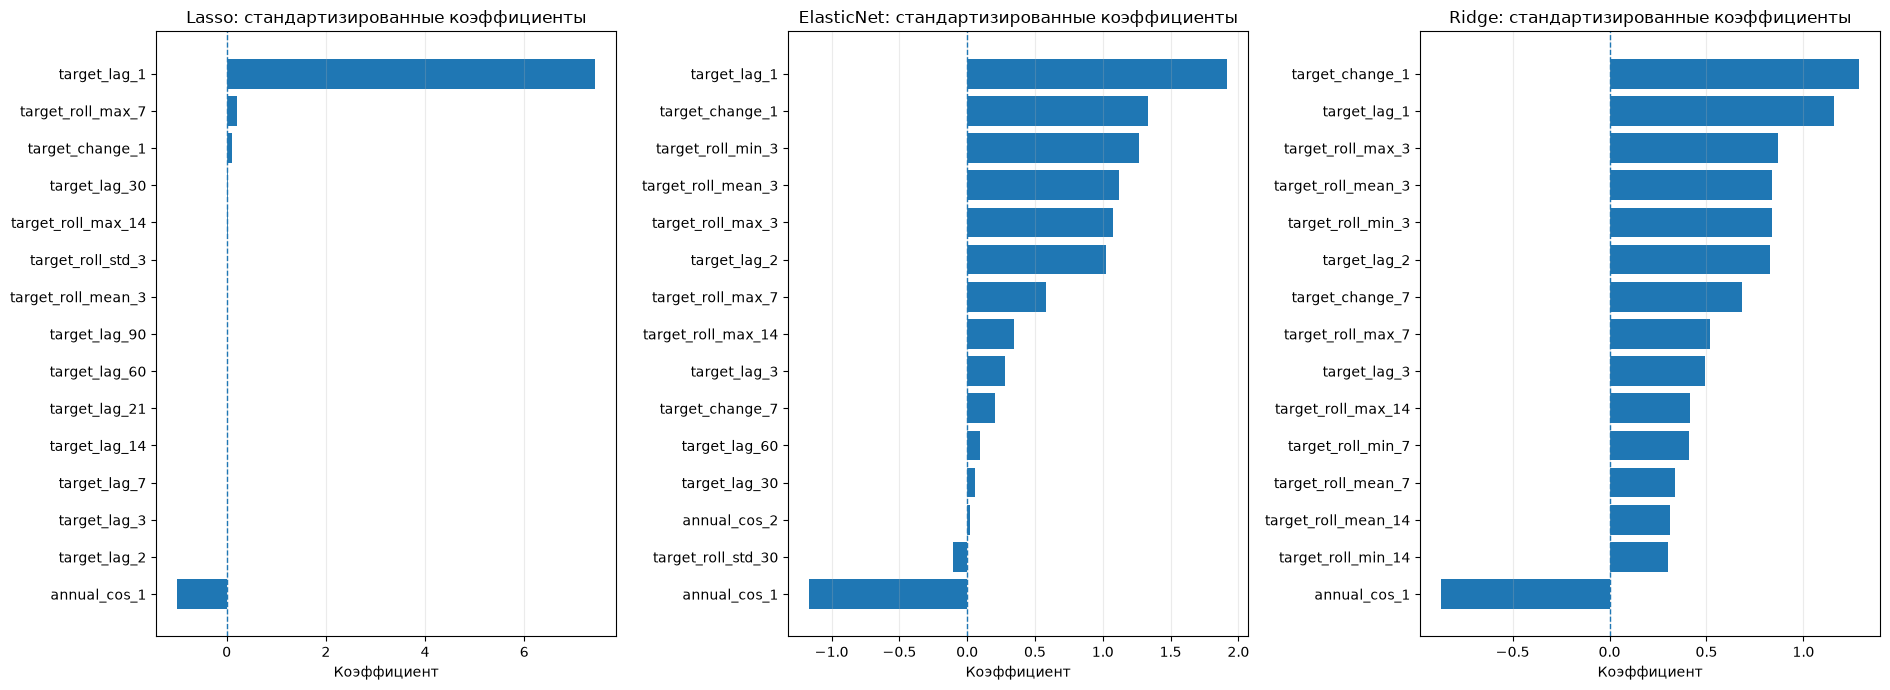


4. СТАТИСТИЧЕСКИЙ АНАЛИЗ OLS
R2: 0.95017
Adjusted R2: 0.94685
Ранг матрицы: 33
Число столбцов: 35
Condition number: 4.154465528152784e+17

Статистически значимых коэффициентов: 10


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/3066203991.py:362: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_result = ols_model.fit(


,feature,coefficient,std_error,t_stat,p_value,ci_lower,ci_upper,significant_005
26,target_change_1,0.405922,0.059892,6.777527,0.000000,0.288535,0.523308,True
32,annual_cos_1,-5.341493,0.903950,-5.909056,0.000000,-7.113203,-3.569783,True
0,const,4.949426,1.317227,3.757460,0.000172,2.367710,7.531143,True
1,target_lag_1,0.343679,0.113008,3.041188,0.002356,0.122187,0.565171,True
31,annual_sin_1,-2.159927,0.711946,-3.033834,0.002415,-3.555316,-0.764538,True
23,target_roll_std_30,-0.934464,0.316066,-2.956547,0.003111,-1.553942,-0.314986,True
22,target_roll_mean_30,-0.464560,0.175959,-2.640156,0.008287,-0.809434,-0.119686,True
24,target_roll_min_30,-0.202799,0.082695,-2.452388,0.014191,-0.364878,-0.040721,True
28,month,-0.728896,0.307364,-2.371443,0.017719,-1.331318,-0.126474,True
29,dayofyear,0.020108,0.009976,2.015526,0.043850,0.000554,0.039661,True



5. ВАЖНОСТЬ ПРИЗНАКОВ EXTRATREES


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 34, but rank is 32
  res = self.wald_test(


,feature,importance
0,target_lag_1,0.261979
12,target_roll_max_3,0.191964
9,target_roll_mean_3,0.127524
11,target_roll_min_3,0.116405
16,target_roll_max_7,0.083958
13,target_roll_mean_7,0.042638
1,target_lag_2,0.031334
15,target_roll_min_7,0.028002
2,target_lag_3,0.027640
31,annual_cos_1,0.019887


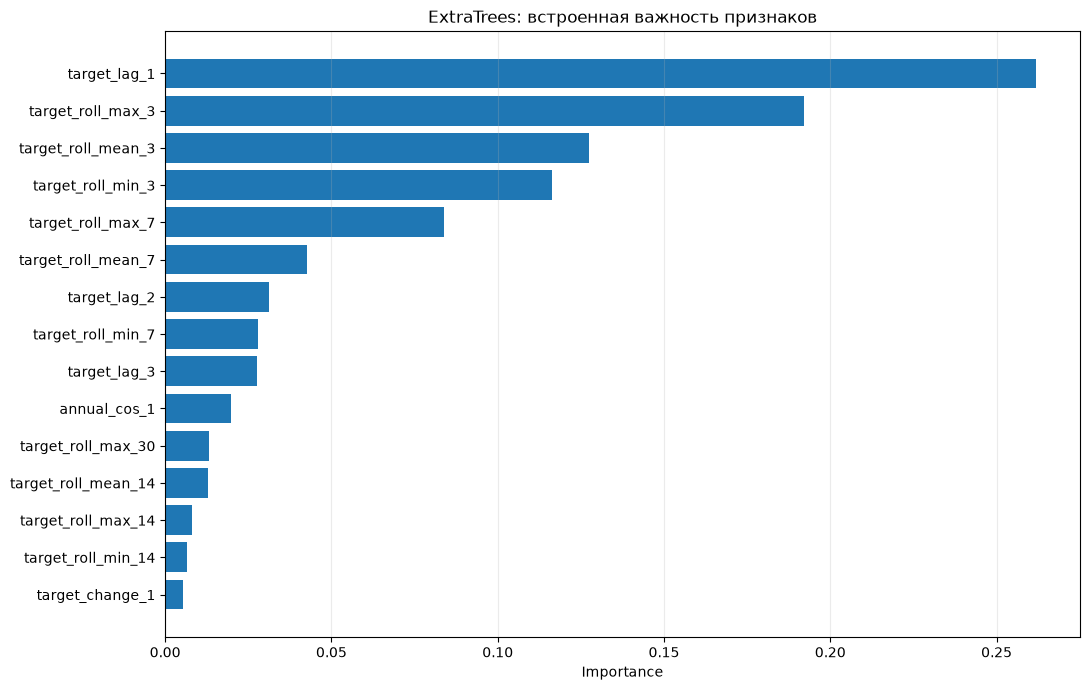

Background dataset has 512 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=512 when initializing the masker.



6. SHAP-АНАЛИЗ

Модель: Lasso


,feature,mean_abs_shap
0,target_lag_1,6.941486
31,annual_cos_1,1.076347
16,target_roll_max_7,0.197316
25,target_change_1,0.071941
20,target_roll_max_14,0.016772
6,target_lag_30,0.015701
21,target_roll_mean_30,0.000000
22,target_roll_std_30,0.000000
23,target_roll_min_30,0.000000
24,target_roll_max_30,0.000000


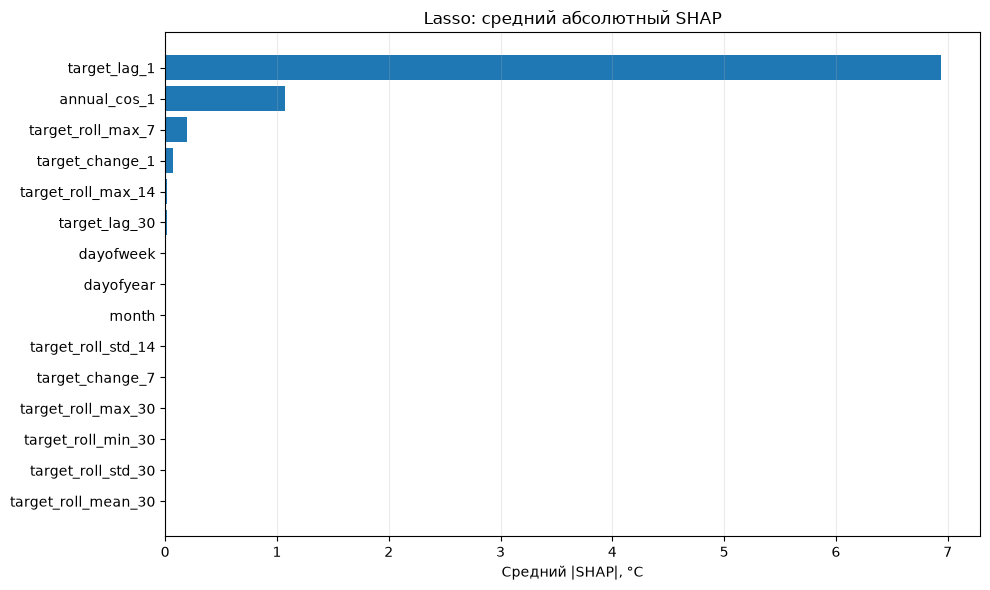

Background dataset has 512 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=512 when initializing the masker.



Модель: ElasticNet


,feature,mean_abs_shap
0,target_lag_1,1.790801
31,annual_cos_1,1.254176
11,target_roll_min_3,1.186108
9,target_roll_mean_3,1.074910
12,target_roll_max_3,1.044016
1,target_lag_2,0.969886
25,target_change_1,0.823558
16,target_roll_max_7,0.567958
20,target_roll_max_14,0.352968
2,target_lag_3,0.268605


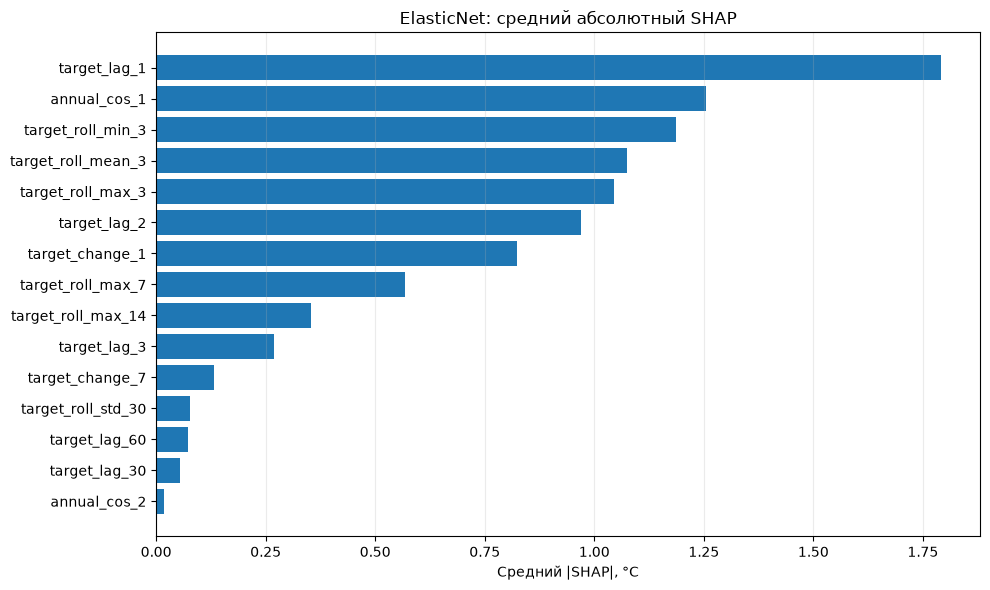

Background dataset has 512 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=512 when initializing the masker.



Модель: Ridge


,feature,mean_abs_shap
0,target_lag_1,1.079152
31,annual_cos_1,0.934707
12,target_roll_max_3,0.842875
9,target_roll_mean_3,0.806609
25,target_change_1,0.795066
1,target_lag_2,0.786866
11,target_roll_min_3,0.783539
16,target_roll_max_7,0.504766
2,target_lag_3,0.472591
26,target_change_7,0.439364


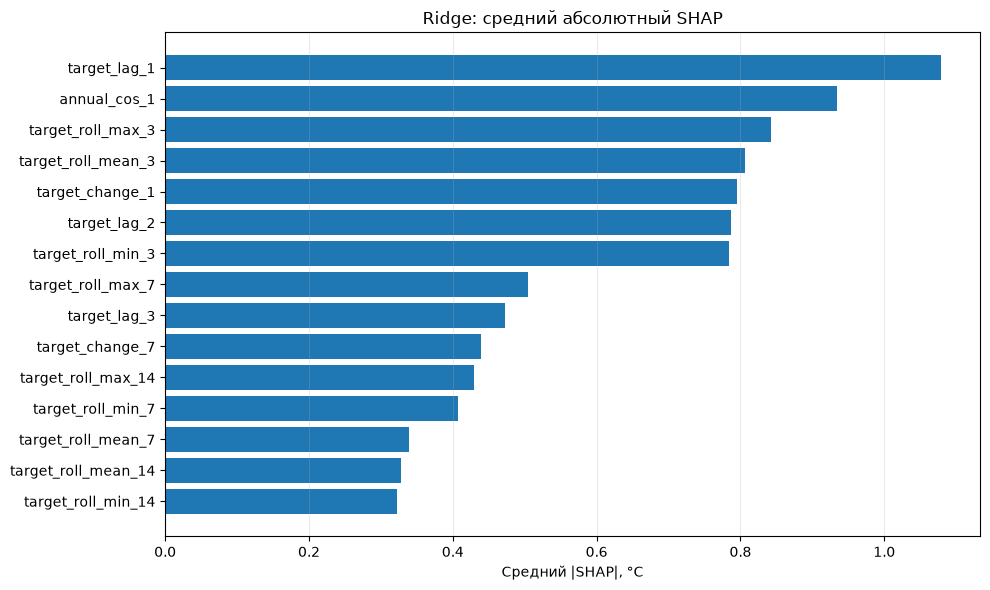


Модель: ExtraTrees


,feature,mean_abs_shap
0,target_lag_1,2.196699
12,target_roll_max_3,1.468979
11,target_roll_min_3,0.961925
9,target_roll_mean_3,0.960585
16,target_roll_max_7,0.617267
13,target_roll_mean_7,0.299117
31,annual_cos_1,0.257544
1,target_lag_2,0.220351
15,target_roll_min_7,0.198981
2,target_lag_3,0.179602


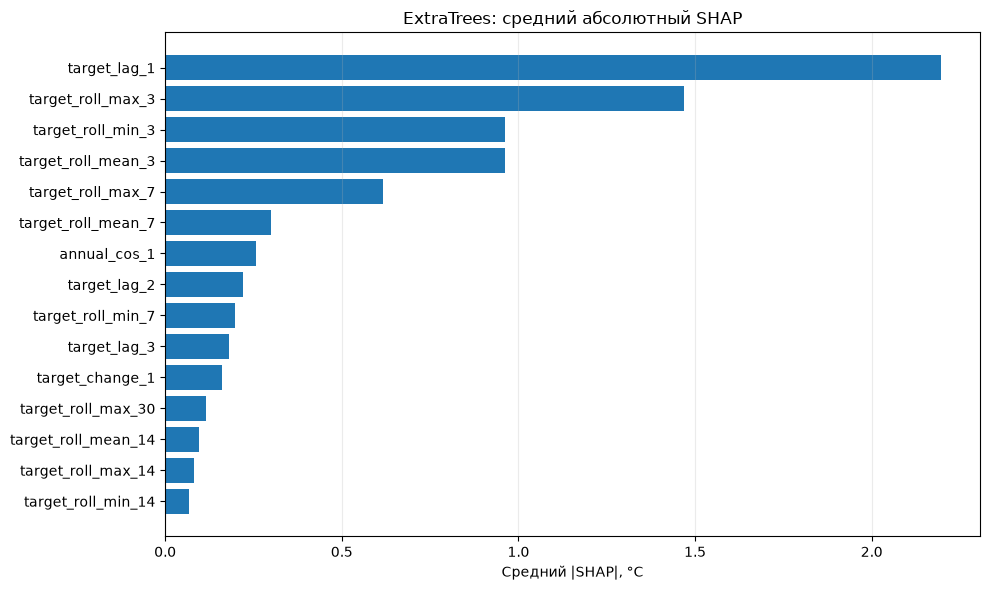


7. УСТОЙЧИВОСТЬ РЕЙТИНГОВ ПРИЗНАКОВ


,model,mean_spearman,min_spearman,max_spearman,std_spearman
0,ElasticNet,0.56407,0.22686,0.80462,0.20252
1,ExtraTrees,0.71144,0.59389,0.87777,0.10450
2,Lasso,0.45299,0.24974,0.67554,0.18227
3,Ridge,0.67811,0.38365,0.93002,0.18074



Все попарные сравнения фолдов:


,model,fold_a,fold_b,spearman_rho,p_value
0,Lasso,1,2,0.65202,0.00003
1,Lasso,1,3,0.26254,0.13360
2,Lasso,1,4,0.41525,0.01460
3,Lasso,1,5,0.27534,0.11501
4,Lasso,2,3,0.45019,0.00755
5,Lasso,2,4,0.24974,0.15432
6,Lasso,2,5,0.27534,0.11501
7,Lasso,3,4,0.64061,0.00004
8,Lasso,3,5,0.63334,0.00006
9,Lasso,4,5,0.67554,0.00001


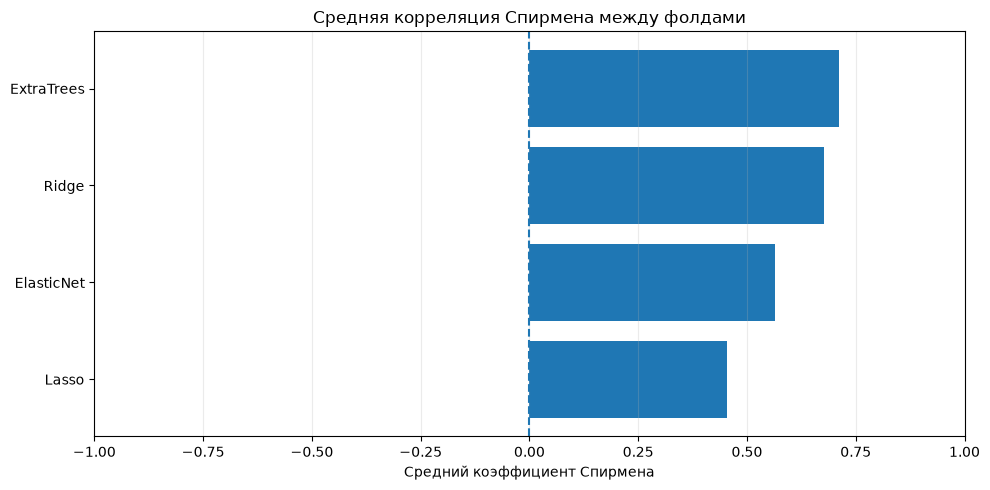


8. СОПОСТАВЛЕНИЕ МЕТОДОВ


,model,comparison_method,spearman_rho,p_value
0,Lasso,Absolute standardized coefficient,0.99931,0.0
1,ElasticNet,Absolute standardized coefficient,0.99426,0.0
2,Ridge,Absolute standardized coefficient,0.97800,0.0
3,ExtraTrees,Tree feature importance,0.95752,0.0



9. ИТОГОВЫЕ ПРОВЕРКИ
PASS | data_loaded
PASS | models_trained
PASS | coefficients_extracted
PASS | ols_completed
PASS | tree_importance_completed
PASS | shap_completed
PASS | stability_completed
PASS | spearman_completed
PASS | comparison_completed
PASS | results_saved

Пройдено: 10 из 10

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_4/reports/task8

ЗАДАНИЕ 8 ЗАВЕРШЕНО


In [17]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 8. ИНТЕРПРЕТИРУЕМОСТЬ МОДЕЛЕЙ
# ============================================================

from pathlib import Path
from itertools import combinations
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
import statsmodels.api as sm

from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models" / "task4"
REPORT_DIR = PROJECT / "reports" / "task8"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SOURCE = DATA_DIR / "task3_trainval.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

MODEL_NAMES = [
    "Lasso",
    "ElasticNet",
    "Ridge",
    "ExtraTrees"
]

LINEAR_MODELS = [
    "Lasso",
    "ElasticNet",
    "Ridge"
]

N_SPLITS = 5
TOP_N = 15
SHAP_SAMPLE_SIZE = 80
RANDOM_STATE = 42

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv(
    SOURCE,
    parse_dates=[DATE_COL]
)

df = (
    df.sort_values(DATE_COL)
    .reset_index(drop=True)
)

feature_cols = [
    col for col in df.columns
    if col not in [DATE_COL, TARGET]
]

X = df[feature_cols].copy()
y = df[TARGET].astype(float).copy()

assert df[DATE_COL].is_unique
assert df[DATE_COL].is_monotonic_increasing
assert X.notna().all().all()
assert y.notna().all()

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print("Наблюдений:", len(df))
print("Признаков:", len(feature_cols))
print("Начало:", df[DATE_COL].min().date())
print("Конец:", df[DATE_COL].max().date())

# ============================================================
# 3. ЗАГРУЗКА И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

models = {}

for name in MODEL_NAMES:

    path = MODEL_DIR / f"{name}.joblib"

    if not path.exists():
        raise FileNotFoundError(
            f"Не найдена модель: {path}"
        )

    # Клонируем конфигурацию, не используя
    # ранее обученное состояние модели.

    model = clone(joblib.load(path))

    model.fit(X, y)

    models[name] = model

print("\n" + "=" * 80)
print("2. ОБУЧЕННЫЕ МОДЕЛИ")
print("=" * 80)

for name, model in models.items():
    print(name, "—", type(model).__name__)

# ============================================================
# 4. ПОЛУЧЕНИЕ КОЭФФИЦИЕНТОВ
# ============================================================

def extract_linear_coefficients(
    model,
    columns
):
    """
    Возвращает коэффициенты в двух шкалах:

    original_coef:
        изменение прогноза при изменении
        исходного признака на одну единицу.

    standardized_coef:
        коэффициент для признака,
        стандартизированного по обучению.
    """

    if isinstance(model, Pipeline):

        estimator = model.steps[-1][1]

        transformed_coef = np.asarray(
            estimator.coef_,
            dtype=float
        ).ravel()

        # Коэффициенты модели относятся
        # к преобразованным признакам.
        # Для обычного StandardScaler:
        # original_coef = coef / scale.

        original_coef = transformed_coef.copy()
        standardized_coef = transformed_coef.copy()

        for _, transformer in reversed(
            model.steps[:-1]
        ):

            if hasattr(transformer, "scale_"):

                scale = np.asarray(
                    transformer.scale_,
                    dtype=float
                )

                original_coef = (
                    original_coef / scale
                )

            else:
                raise ValueError(
                    "В Pipeline обнаружено "
                    "неподдерживаемое преобразование. "
                    "Проверьте препроцессинг."
                )

    else:

        estimator = model

        original_coef = np.asarray(
            estimator.coef_,
            dtype=float
        ).ravel()

        # Для модели без масштабирования
        # используем стандартные отклонения X.

        standardized_coef = (
            original_coef
            * X[columns].std(ddof=0).to_numpy()
        )

    if len(original_coef) != len(columns):
        raise ValueError(
            "Количество коэффициентов "
            "не совпадает с количеством признаков."
        )

    return pd.DataFrame({
        "feature": columns,
        "original_coef": original_coef,
        "standardized_coef": standardized_coef,
        "abs_standardized_coef": np.abs(
            standardized_coef
        )
    })


coefficient_frames = []

for name in LINEAR_MODELS:

    coef_df = extract_linear_coefficients(
        models[name],
        feature_cols
    )

    coef_df["model"] = name

    coef_df["is_zero"] = (
        np.abs(
            coef_df["standardized_coef"]
        ) < 1e-10
    )

    coefficient_frames.append(
        coef_df
    )

coefficients_df = pd.concat(
    coefficient_frames,
    ignore_index=True
)

print("\n" + "=" * 80)
print("3. КОЭФФИЦИЕНТЫ ЛИНЕЙНЫХ МОДЕЛЕЙ")
print("=" * 80)

for name in LINEAR_MODELS:

    subset = coefficients_df[
        coefficients_df["model"] == name
    ]

    print(f"\n{name}")

    print(
        "Ненулевых коэффициентов:",
        int((~subset["is_zero"]).sum()),
        "из",
        len(subset)
    )

    display(
        subset.sort_values(
            "abs_standardized_coef",
            ascending=False
        ).head(TOP_N).round(5)
    )

# ============================================================
# 5. ГРАФИКИ КОЭФФИЦИЕНТОВ
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 7)
)

for ax, name in zip(
    axes,
    LINEAR_MODELS
):

    subset = coefficients_df[
        coefficients_df["model"] == name
    ]

    top = (
        subset.nlargest(
            TOP_N,
            "abs_standardized_coef"
        )
        .sort_values("standardized_coef")
    )

    ax.barh(
        top["feature"],
        top["standardized_coef"]
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{name}: стандартизированные коэффициенты"
    )

    ax.set_xlabel(
        "Коэффициент"
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "linear_coefficients.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. СТАТИСТИЧЕСКИЙ АНАЛИЗ OLS
# ============================================================

# Вспомогательная модель OLS не заменяет
# регуляризованные модели Lasso/Ridge.
#
# Из-за временной зависимости используем
# HAC-оценку ковариационной матрицы.
#
# При сильной мультиколлинеарности
# отдельные коэффициенты могут быть
# нестабильны.

X_ols = sm.add_constant(
    X.astype(float),
    has_constant="add"
)

ols_model = sm.OLS(
    y.to_numpy(dtype=float),
    X_ols.to_numpy(dtype=float)
)

ols_result = ols_model.fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": 7
    }
)

ols_confint = ols_result.conf_int(
    alpha=0.05
)

ols_df = pd.DataFrame({
    "feature": X_ols.columns,
    "coefficient": ols_result.params,
    "std_error": ols_result.bse,
    "t_stat": ols_result.tvalues,
    "p_value": ols_result.pvalues,
    "ci_lower": ols_confint[:, 0],
    "ci_upper": ols_confint[:, 1]
})

ols_df["significant_005"] = (
    ols_df["p_value"] < 0.05
)

# Диагностика обусловленности
# матрицы признаков.

matrix_rank = int(
    np.linalg.matrix_rank(
        X_ols.to_numpy(dtype=float)
    )
)

condition_number = float(
    np.linalg.cond(
        X_ols.to_numpy(dtype=float)
    )
)

print("\n" + "=" * 80)
print("4. СТАТИСТИЧЕСКИЙ АНАЛИЗ OLS")
print("=" * 80)

print("R2:", round(ols_result.rsquared, 5))
print("Adjusted R2:", round(ols_result.rsquared_adj, 5))
print("Ранг матрицы:", matrix_rank)
print("Число столбцов:", X_ols.shape[1])
print("Condition number:", round(condition_number, 3))

print(
    "\nСтатистически значимых коэффициентов:",
    int(ols_df["significant_005"].sum())
)

display(
    ols_df.sort_values(
        "p_value"
    ).head(20).round(6)
)

(
    REPORT_DIR / "ols_summary.txt"
).write_text(
    ols_result.summary().as_text(),
    encoding="utf-8"
)

# ============================================================
# 7. ВСТРОЕННАЯ ВАЖНОСТЬ EXTRATREES
# ============================================================

extra_model = models["ExtraTrees"]

if isinstance(extra_model, Pipeline):
    extra_estimator = extra_model.steps[-1][1]
else:
    extra_estimator = extra_model

tree_importance = np.asarray(
    extra_estimator.feature_importances_,
    dtype=float
)

extra_importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": tree_importance
}).sort_values(
    "importance",
    ascending=False
)

print("\n" + "=" * 80)
print("5. ВАЖНОСТЬ ПРИЗНАКОВ EXTRATREES")
print("=" * 80)

display(
    extra_importance_df.head(
        TOP_N
    ).round(6)
)

plt.figure(figsize=(11, 7))

top_tree = (
    extra_importance_df.head(TOP_N)
    .sort_values("importance")
)

plt.barh(
    top_tree["feature"],
    top_tree["importance"]
)

plt.title(
    "ExtraTrees: встроенная важность признаков"
)

plt.xlabel("Importance")
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "extratrees_importance.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. SHAP-АНАЛИЗ
# ============================================================

# Используем последние наблюдения trainval.
# Независимый тестовый период не затрагиваем.

X_shap = X.tail(
    min(SHAP_SAMPLE_SIZE, len(X))
).copy()

shap_records = []
shap_values_by_model = {}

print("\n" + "=" * 80)
print("6. SHAP-АНАЛИЗ")
print("=" * 80)

for name in MODEL_NAMES:

    model = models[name]

    print(f"\nМодель: {name}")

    if name in LINEAR_MODELS:

        if isinstance(model, Pipeline):

            estimator = model.steps[-1][1]

            transformer = model[:-1]

            X_transformed = transformer.transform(
                X_shap
            )

            background_transformed = (
                transformer.transform(X)
            )

        else:

            estimator = model
            X_transformed = X_shap.to_numpy()
            background_transformed = X.to_numpy()

        explainer = shap.LinearExplainer(
            estimator,
            background_transformed
        )

        shap_values = explainer(
            X_transformed
        )

    else:

        # TreeExplainer для ансамбля деревьев.
        explainer = shap.TreeExplainer(
            extra_estimator
        )

        shap_values = explainer(
            X_shap
        )

    values_shap = np.asarray(
        shap_values.values
    )

    if values_shap.ndim != 2:
        raise ValueError(
            f"Неожиданная размерность SHAP: "
            f"{values_shap.shape}"
        )

    if values_shap.shape[1] != len(feature_cols):
        raise ValueError(
            "Количество SHAP-признаков "
            "не совпадает с датасетом."
        )

    shap_values_by_model[name] = (
        values_shap
    )

    mean_abs_shap = np.mean(
        np.abs(values_shap),
        axis=0
    )

    for feature, importance in zip(
        feature_cols,
        mean_abs_shap
    ):

        shap_records.append({
            "model": name,
            "feature": feature,
            "mean_abs_shap": float(importance)
        })

    shap_summary = pd.DataFrame({
        "feature": feature_cols,
        "mean_abs_shap": mean_abs_shap
    }).sort_values(
        "mean_abs_shap",
        ascending=False
    )

    display(
        shap_summary.head(
            TOP_N
        ).round(6)
    )

    top = (
        shap_summary.head(TOP_N)
        .sort_values("mean_abs_shap")
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        top["feature"],
        top["mean_abs_shap"]
    )

    plt.title(
        f"{name}: средний абсолютный SHAP"
    )

    plt.xlabel(
        "Средний |SHAP|, °C"
    )

    plt.grid(
        axis="x",
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / f"{name}_shap.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()

shap_importance_df = pd.DataFrame(
    shap_records
)

# ============================================================
# 9. УСТОЙЧИВОСТЬ ВАЖНОСТИ ПО ФОЛДАМ
# ============================================================

# Для каждого временного фолда обучаем
# модель только на его train-части.
#
# Ранжирование:
# линейные модели — абсолютные
# стандартизированные коэффициенты;
# ExtraTrees — встроенная важность.

tscv = TimeSeriesSplit(
    n_splits=N_SPLITS
)

stability_records = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X),
    start=1
):

    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]

    for name in MODEL_NAMES:

        model = clone(models[name])

        model.fit(
            X_train,
            y_train
        )

        if name in LINEAR_MODELS:

            if isinstance(model, Pipeline):

                estimator = model.steps[-1][1]

                transformed_coef = np.asarray(
                    estimator.coef_,
                    dtype=float
                ).ravel()

                # Поскольку Pipeline использует
                # StandardScaler, коэффициенты
                # относятся к стандартизированным
                # признакам текущего фолда.

                importance = np.abs(
                    transformed_coef
                )

            else:

                importance = (
                    np.abs(model.coef_)
                    * X_train.std(ddof=0).to_numpy()
                )

        else:

            estimator = (
                model.steps[-1][1]
                if isinstance(model, Pipeline)
                else model
            )

            importance = np.asarray(
                estimator.feature_importances_,
                dtype=float
            )

        for feature, value in zip(
            feature_cols,
            importance
        ):

            stability_records.append({
                "fold": fold,
                "model": name,
                "feature": feature,
                "importance": float(value)
            })

stability_df = pd.DataFrame(
    stability_records
)

# ============================================================
# 10. КОРРЕЛЯЦИЯ СПИРМЕНА
# ============================================================

spearman_records = []

for name in MODEL_NAMES:

    subset = stability_df[
        stability_df["model"] == name
    ]

    pivot = subset.pivot(
        index="feature",
        columns="fold",
        values="importance"
    )

    for fold_a, fold_b in combinations(
        range(1, N_SPLITS + 1),
        2
    ):

        a = pivot[fold_a]
        b = pivot[fold_b]

        # Если все важности одинаковые,
        # ранжирование не определено.

        if (
            a.nunique() <= 1
            or b.nunique() <= 1
        ):
            rho = np.nan
            p_value = np.nan
        else:
            rho, p_value = spearmanr(
                a,
                b
            )

        spearman_records.append({
            "model": name,
            "fold_a": fold_a,
            "fold_b": fold_b,
            "spearman_rho": float(rho),
            "p_value": float(p_value)
        })

spearman_df = pd.DataFrame(
    spearman_records
)

stability_summary = (
    spearman_df
    .groupby("model")
    .agg(
        mean_spearman=(
            "spearman_rho",
            "mean"
        ),
        min_spearman=(
            "spearman_rho",
            "min"
        ),
        max_spearman=(
            "spearman_rho",
            "max"
        ),
        std_spearman=(
            "spearman_rho",
            "std"
        )
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("7. УСТОЙЧИВОСТЬ РЕЙТИНГОВ ПРИЗНАКОВ")
print("=" * 80)

display(
    stability_summary.round(5)
)

print("\nВсе попарные сравнения фолдов:")
display(
    spearman_df.round(5)
)

# ============================================================
# 11. ГРАФИК УСТОЙЧИВОСТИ
# ============================================================

plot_stability = (
    stability_summary
    .sort_values("mean_spearman")
)

plt.figure(figsize=(10, 5))

plt.barh(
    plot_stability["model"],
    plot_stability["mean_spearman"]
)

plt.xlim(-1, 1)
plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Средняя корреляция Спирмена "
    "между фолдами"
)

plt.xlabel(
    "Средний коэффициент Спирмена"
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "feature_stability.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. СОПОСТАВЛЕНИЕ МЕТОДОВ ВАЖНОСТИ
# ============================================================

comparison_records = []

for name in MODEL_NAMES:

    shap_subset = (
        shap_importance_df[
            shap_importance_df["model"] == name
        ]
        .set_index("feature")
        ["mean_abs_shap"]
    )

    if name in LINEAR_MODELS:

        other_subset = (
            coefficients_df[
                coefficients_df["model"] == name
            ]
            .set_index("feature")
            ["abs_standardized_coef"]
        )

        other_method = (
            "Absolute standardized coefficient"
        )

    else:

        other_subset = (
            extra_importance_df
            .set_index("feature")
            ["importance"]
        )

        other_method = (
            "Tree feature importance"
        )

    aligned = pd.concat(
        [
            shap_subset.rename("shap"),
            other_subset.rename("other")
        ],
        axis=1
    ).dropna()

    rho, p_value = spearmanr(
        aligned["shap"],
        aligned["other"]
    )

    comparison_records.append({
        "model": name,
        "comparison_method": other_method,
        "spearman_rho": float(rho),
        "p_value": float(p_value)
    })

comparison_df = pd.DataFrame(
    comparison_records
)

print("\n" + "=" * 80)
print("8. СОПОСТАВЛЕНИЕ МЕТОДОВ")
print("=" * 80)

display(
    comparison_df.round(5)
)

# ============================================================
# 13. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

outputs = {
    "linear_coefficients.csv": coefficients_df,
    "ols_coefficients.csv": ols_df,
    "extratrees_importance.csv": extra_importance_df,
    "shap_importance.csv": shap_importance_df,
    "feature_importance_by_fold.csv": stability_df,
    "spearman_by_fold.csv": spearman_df,
    "stability_summary.csv": stability_summary,
    "importance_method_comparison.csv": comparison_df
}

for filename, dataframe in outputs.items():

    dataframe.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

config = {
    "task": 8,
    "models": MODEL_NAMES,
    "n_splits": N_SPLITS,
    "top_n": TOP_N,
    "shap_sample_size": len(X_shap),
    "n_features": len(feature_cols),
    "ols_covariance": "HAC",
    "ols_maxlags": 7,
    "test_set_used": False,
    "interpretation_warning": (
        "Feature importance and SHAP "
        "describe model behavior, "
        "not causal effects."
    )
}

(
    REPORT_DIR / "experiment_config.json"
).write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 14. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "data_loaded": len(df) > 0,
    "models_trained": (
        len(models) == len(MODEL_NAMES)
    ),
    "coefficients_extracted": (
        len(coefficients_df)
        == len(LINEAR_MODELS) * len(feature_cols)
    ),
    "ols_completed": (
        len(ols_df) == len(feature_cols) + 1
    ),
    "tree_importance_completed": (
        len(extra_importance_df)
        == len(feature_cols)
    ),
    "shap_completed": (
        len(shap_importance_df)
        == len(MODEL_NAMES) * len(feature_cols)
    ),
    "stability_completed": (
        len(stability_df)
        == N_SPLITS * len(MODEL_NAMES)
        * len(feature_cols)
    ),
    "spearman_completed": (
        len(spearman_df)
        == len(MODEL_NAMES) * 10
    ),
    "comparison_completed": (
        len(comparison_df)
        == len(MODEL_NAMES)
    ),
    "results_saved": all(
        (REPORT_DIR / name).exists()
        for name in outputs
    )
}

print("\n" + "=" * 80)
print("9. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 8 ЗАВЕРШЕНО")


### Анализ результатов выполнения задания 8

В ходе выполнения восьмого задания была исследована интерпретируемость моделей машинного обучения, применяемых для прогнозирования среднесуточной температуры воздуха в Москве.

Для анализа были выбраны четыре модели: Lasso, ElasticNet, Ridge и ExtraTrees.

Исследование включало анализ коэффициентов линейных моделей, статистический анализ OLS, расчёт встроенной важности признаков ExtraTrees, SHAP-анализ и оценку устойчивости ранжирования признаков по временным фолдам.

**1. Анализ коэффициентов линейных моделей**

Важным результатом исследования стало то, что Lasso сохранила только 6 ненулевых коэффициентов из 34 исходных признаков.

Таким образом, модель исключила 28 признаков, или около 82,4% исходного набора.

Это объясняется особенностями L1-регуляризации, которая способствует формированию разреженных моделей и автоматическому отбору признаков.

Сокращение количества используемых признаков упрощает интерпретацию модели и позволяет выделить ограниченный набор характеристик, определяющих её прогнозы.

С учётом результатов задания 7, где Lasso заняла первое место среди обучаемых алгоритмов, можно заключить, что использование всех 34 признаков не является обязательным для получения сравнительно высокой точности прогнозирования.

**2. Статистический анализ OLS**

Для дополнительного исследования линейных зависимостей была построена вспомогательная модель обыкновенных наименьших квадратов.

Получены следующие характеристики:

- R² = 0,95017;
- скорректированный R² = 0,94685;
- ранг матрицы признаков = 33;
- количество столбцов с учётом константы = 35;
- число обусловленности = 4,15 × 10¹⁷;
- количество коэффициентов с p-value менее 0,05 = 10.

Высокий коэффициент детерминации свидетельствует о том, что модель хорошо описывает обучающие наблюдения.

Однако матрица признаков не обладает полным столбцовым рангом, а число обусловленности имеет чрезвычайно большое значение.

Это указывает на наличие точных линейных зависимостей и сильной мультиколлинеарности.

Вероятной причиной является использование большого количества взаимосвязанных временных признаков: лагов температуры, скользящих средних, минимумов, максимумов и изменений температуры.

В таких условиях оценки отдельных коэффициентов OLS могут быть нестабильными, а их статистическая интерпретация — затруднённой.

Следовательно, результаты OLS необходимо рассматривать как вспомогательный анализ, а не как доказательство независимого причинного влияния отдельных признаков.

**3. Встроенная важность признаков ExtraTrees**

Встроенная важность признаков ExtraTrees показала, что наибольший вклад в построение деревьев вносят характеристики температуры за последние несколько дней.

Пять наиболее важных признаков:

- `target_lag_1` — 0,261979;
- `target_roll_max_3` — 0,191964;
- `target_roll_mean_3` — 0,127524;
- `target_roll_min_3` — 0,116405;
- `target_roll_max_7` — 0,083958.

Совокупная важность этих пяти признаков составляет приблизительно 78,2%.

Таким образом, ExtraTrees преимущественно использует температуру предыдущего дня и краткосрочные статистические характеристики температурного ряда.

Это свидетельствует о высокой значимости текущего температурного режима для формирования одношагового прогноза.

**4. Результаты SHAP-анализа**

Для оценки вклада отдельных признаков в прогнозы моделей был проведён SHAP-анализ.

Для Lasso наибольший средний абсолютный вклад продемонстрировал признак `target_lag_1` со значением 6,941486.

Второе место занял сезонный признак `annual_cos_1` со значением 1,076347.

Остальные признаки имели значительно меньший вклад.

Таким образом, Lasso преимущественно использует температуру предыдущего дня, дополняя прогноз информацией о годовой сезонности.

Для ElasticNet наибольшие значения SHAP получили:

- `target_lag_1` — 1,790801;
- `annual_cos_1` — 1,254176;
- `target_roll_min_3` — 1,186108;
- `target_roll_mean_3` — 1,074910;
- `target_roll_max_3` — 1,044016.

В отличие от Lasso, ElasticNet распределяет влияние между большим количеством взаимосвязанных признаков.

Для Ridge также наблюдается более равномерное распределение вкладов.

Наибольшие значения получили температура предыдущего дня, годовая сезонность, скользящие статистики за три дня и изменение температуры за предыдущий день.

Для ExtraTrees основными признаками стали:

- `target_lag_1` — 2,196699;
- `target_roll_max_3` — 1,468979;
- `target_roll_min_3` — 0,961925;
- `target_roll_mean_3` — 0,960585;
- `target_roll_max_7` — 0,617267.

Таким образом, все четыре модели выделяют температуру предыдущего дня как наиболее важный признак по среднему абсолютному SHAP.

Дополнительную роль играют краткосрочные температурные характеристики и годовая сезонность.

Полученные результаты согласуются с особенностями временного ряда: температура следующего дня во многом связана с температурой предыдущего дня и текущим сезонным режимом.

Следует учитывать, что SHAP объясняет поведение обученной модели, а не причинно-следственные связи.

**5. Анализ устойчивости важности признаков**

Для оценки устойчивости объяснений модели были повторно обучены на пяти последовательных временных фолдах.

Рейтинги важности признаков сравнивались с использованием корреляции Спирмена.

Получены следующие средние значения:

- ExtraTrees — 0,71144;
- Ridge — 0,67811;
- ElasticNet — 0,56407;
- Lasso — 0,45299.

Наибольшую устойчивость ранжирования продемонстрировала ExtraTrees.

Средняя корреляция Спирмена для неё составила 0,71144, а минимальная — 0,59389.

Ridge также показала сравнительно высокую согласованность рейтингов, однако отдельные пары фолдов заметно различались.

Для ElasticNet наблюдалась умеренная средняя устойчивость.

Наименьшая средняя корреляция обнаружена у Lasso.

Это означает, что при изменении обучающего периода состав и порядок важных признаков Lasso могут изменяться.

Данный результат связан с особенностями регуляризации и наличием сильно коррелированных признаков.

При наличии нескольких признаков, содержащих близкую информацию, Lasso может выбирать разные представители одной группы в зависимости от обучающей выборки.

Таким образом, компактность модели не гарантирует устойчивости выбранного набора признаков.

**6. Сравнение методов интерпретации**

Для сопоставления результатов SHAP с другими методами важности была рассчитана ранговая корреляция Спирмена.

Получены следующие значения:

- Lasso — 0,99931;
- ElasticNet — 0,99426;
- Ridge — 0,97800;
- ExtraTrees — 0,95752.

Для линейных моделей сравнивались средние абсолютные SHAP-значения и абсолютные стандартизированные коэффициенты.

Для ExtraTrees сравнивались SHAP и встроенная важность признаков.

Во всех случаях обнаружена очень высокая согласованность рейтингов.

Это показывает, что различные методы интерпретации выделяют преимущественно одни и те же признаки внутри каждой модели.

Однако высокая согласованность не означает независимого подтверждения причинной значимости признаков, поскольку методы анализируют поведение одних и тех же обученных алгоритмов.

**7. Сравнительная оценка интерпретируемости моделей**

Lasso показала наиболее компактную структуру: из 34 исходных признаков используются только 6.

Это существенно упрощает объяснение прогнозов и позволяет выделить основные факторы, используемые алгоритмом.

ElasticNet и Ridge распределяют влияние между большим количеством признаков, что делает их объяснения менее компактными.

ExtraTrees продемонстрировала высокую устойчивость ранжирования признаков между временными фолдами, однако её нелинейная структура сложнее для непосредственной интерпретации.

Следовательно, модели обладают разными преимуществами:

- Lasso — компактность и простота объяснения;
- ElasticNet — распределение влияния между коррелированными признаками;
- Ridge — использование широкого набора признаков с регуляризацией;
- ExtraTrees — сравнительно высокая устойчивость рейтингов важности.

**8. Ограничения исследования**

При интерпретации результатов необходимо учитывать несколько ограничений.

Во-первых, многие признаки являются сильно коррелированными, что затрудняет оценку их независимого вклада.

Во-вторых, статистический анализ OLS выявил неполный ранг матрицы признаков и чрезвычайно высокое число обусловленности.

В-третьих, SHAP-значения зависят от выбранной модели, фонового распределения и метода расчёта.

В-четвёртых, корреляция Спирмена оценивает согласованность ранжирования, но не гарантирует стабильности абсолютных величин важности.

В-пятых, результаты относятся к рассматриваемому обучающему периоду и выбранным моделям. При использовании новых данных распределение важности может измениться.

### Итоговый вывод

В результате выполнения задания 8 проведено комплексное исследование интерпретируемости моделей Lasso, ElasticNet, Ridge и ExtraTrees.

Установлено, что наиболее важным признаком для всех четырёх моделей является температура предыдущего дня — `target_lag_1`.

Дополнительное влияние оказывают краткосрочные скользящие характеристики температуры и годовая сезонность.

Модель Lasso использует только 6 из 34 признаков, что обеспечивает компактность и простоту объяснения.

При этом устойчивость ранжирования признаков Lasso оказалась ниже, чем у остальных исследованных моделей.

Наибольшую среднюю корреляцию Спирмена между временными фолдами показала ExtraTrees — 0,71144.

Статистический анализ OLS выявил серьёзную мультиколлинеарность, подтверждающую необходимость осторожной интерпретации отдельных коэффициентов.

Сравнение SHAP с коэффициентами линейных моделей и встроенной важностью ExtraTrees показало высокую согласованность результатов.

Таким образом, исследование подтвердило, что для прогнозирования среднесуточной температуры особенно важны краткосрочная температурная динамика и сезонные характеристики.

С учётом результатов задания 7 модель Lasso остаётся перспективным кандидатом среди обучаемых алгоритмов благодаря сочетанию точности, компактности и интерпретируемости.

Вместе с тем обнаруженная нестабильность отбора признаков указывает на необходимость дополнительного исследования устойчивости модели при изменении обучающей выборки.

# Задание 9. Сравнение вычислительной эффективности моделей машинного обучения

### Цель работы

Оценить вычислительную эффективность моделей прогнозирования среднесуточной температуры воздуха в Москве, сравнить время обучения, подбора гиперпараметров, прогнозирования и пиковое потребление оперативной памяти.

### Постановка задачи

Необходимо:

1. Загрузить обучающую выборку и конфигурации моделей из предыдущих заданий.
2. Выбрать пять алгоритмов: Lasso, ElasticNet, LinearSVR, Ridge и ExtraTrees.
3. Измерить время обучения каждой модели.
4. Измерить время прогнозирования на одинаковом наборе наблюдений.
5. Оценить пиковое потребление оперативной памяти во время обучения.
6. Сравнить два метода подбора гиперпараметров: GridSearchCV и RandomizedSearchCV.
7. Для обеспечения сопоставимости использовать одинаковое количество временных фолдов и контролируемый бюджет поиска.
8. Рассчитать средние значения и стандартные отклонения времени выполнения.
9. Проанализировать соотношение точности моделей и вычислительных затрат.
10. Построить сравнительные графики и сохранить результаты эксперимента.

### Методика выполнения

Для измерения времени используется `time.perf_counter()`, обеспечивающий высокую точность измерения коротких интервалов.

Потребление памяти оценивается по изменению пикового RSS процесса, включая память, используемую библиотеками NumPy и scikit-learn.

Для снижения влияния случайных колебаний измерения повторяются несколько раз.

Для подбора гиперпараметров применяются GridSearchCV и RandomizedSearchCV с временной кросс-валидацией TimeSeriesSplit.

Сравнение проводится при фиксированном числе проверяемых конфигураций и одинаковых временных разбиениях.

Дополнительно используются результаты точности из задания 7, что позволяет сопоставить вычислительные затраты и качество прогнозирования.

### Ожидаемый результат

Получены таблицы времени обучения, прогнозирования и подбора гиперпараметров, а также оценки пикового потребления памяти.

Определены наиболее экономичные алгоритмы и особенности методов GridSearchCV и RandomizedSearchCV.

Построены графики и сформулированы выводы о компромиссе между точностью и вычислительными затратами.

In [18]:

%pip install -q psutil



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


1. ДАННЫЕ
Всего наблюдений: 512
Количество признаков: 34
Train: 427
Validation: 85
Период train: 2024-03-31 — 2025-05-31
Период validation: 2025-06-01 — 2025-08-24

2. ЗАГРУЖЕННЫЕ МОДЕЛИ
Lasso — Pipeline
ElasticNet — Pipeline
LinearSVR — Pipeline
Ridge — Pipeline
ExtraTrees — ExtraTreesRegressor

3. ИЗМЕРЕНИЕ ВРЕМЕНИ И ПАМЯТИ

Модель: Lasso
Повтор 1: fit=2.486 мс; predict=0.491 мс; memory=0.656 МиБ
Повтор 2: fit=3.136 мс; predict=0.480 мс; memory=0.172 МиБ
Повтор 3: fit=2.510 мс; predict=0.448 мс; memory=0.406 МиБ

Модель: ElasticNet
Повтор 1: fit=8.027 мс; predict=0.737 мс; memory=0.250 МиБ
Повтор 2: fit=4.868 мс; predict=0.639 мс; memory=0.031 МиБ
Повтор 3: fit=4.995 мс; predict=0.562 мс; memory=0.031 МиБ

Модель: LinearSVR
Повтор 1: fit=3.996 мс; predict=0.511 мс; memory=0.531 МиБ
Повтор 2: fit=2.607 мс; predict=0.516 мс; memory=0.266 МиБ
Повтор 3: fit=3.556 мс; predict=1.232 мс; memory=0.266 МиБ

Модель: Ridge
Повтор 1: fit=3.803 мс; predict=0.924 мс; memory=0.391 МиБ
Повтор 2: fit

,model,fit_mean_ms,fit_std_ms,predict_mean_ms,predict_std_ms,predict_us_per_row,peak_memory_mean_mib,peak_memory_max_mib,RMSE,MAE
4,Ridge,2.61463,1.06873,0.58196,0.29986,6.84657,0.16667,0.39062,1.86555,1.47195
2,Lasso,2.71051,0.36893,0.47304,0.02227,5.56519,0.41146,0.65625,1.86431,1.47651
3,LinearSVR,3.38643,0.70981,0.75321,0.41462,8.86127,0.35417,0.53125,1.82526,1.44353
0,ElasticNet,5.96364,1.78842,0.64621,0.08752,7.60245,0.10417,0.25000,1.80959,1.42845
1,ExtraTrees,91.07628,6.49696,4.07419,0.41646,47.93170,0.35938,0.89062,1.93118,1.48719



4. ПРОСТРАНСТВА ПОИСКА
Lasso : {'model__alpha': [0.001, 0.005, 0.01, 0.03, 0.05, 0.1, 0.3, 1.0]}
ElasticNet : {'model__alpha': [0.001, 0.005, 0.01, 0.03, 0.05, 0.1, 0.3, 1.0]}
LinearSVR : {'model__C': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]}
Ridge : {'model__alpha': [0.01, 0.1, 0.5, 1.0, 3.0, 10.0, 30.0, 100.0]}
ExtraTrees : {'n_estimators': [20, 30, 40, 50, 60, 80, 100, 120]}

5. СРАВНЕНИЕ GRID И RANDOMIZED SEARCH

Модель: Lasso


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.044816e+00, tolerance: 2.863e-01
  model = cd_fast.enet_coordinate_descent(


GridSearchCV: 0.456 с; лучший CV RMSE=2.5137; память=0.719 МиБ


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.044816e+00, tolerance: 2.863e-01
  model = cd_fast.enet_coordinate_descent(


... (6 outputs left out)


6. СРАВНЕНИЕ МЕТОДОВ ПОИСКА


,model,grid_seconds,random_seconds,grid_rmse,random_rmse,random_speedup,rmse_difference
0,ElasticNet,0.45686,0.42520,2.54517,2.54517,1.07446,0.0
1,ExtraTrees,1.41600,1.32182,3.76357,3.76357,1.07125,0.0
2,Lasso,0.45615,0.44079,2.51368,2.51368,1.03483,0.0
3,LinearSVR,0.54140,0.53426,2.49045,2.49045,1.01338,0.0
4,Ridge,0.09731,0.11920,2.92752,2.92752,0.81634,0.0



7. ТОЧНОСТЬ И ЭФФЕКТИВНОСТЬ


,model,RMSE_mean,RMSE_std,fit_mean_ms,predict_mean_ms,peak_memory_mean_mib
0,Ridge,2.91968,1.00255,2.61463,0.58196,0.16667
1,Lasso,2.50682,0.74255,2.71051,0.47304,0.41146
2,LinearSVR,2.61735,0.78253,3.38643,0.75321,0.35417
3,ElasticNet,2.56295,0.99234,5.96364,0.64621,0.10417
4,ExtraTrees,3.78224,2.02140,91.07628,4.07419,0.35938


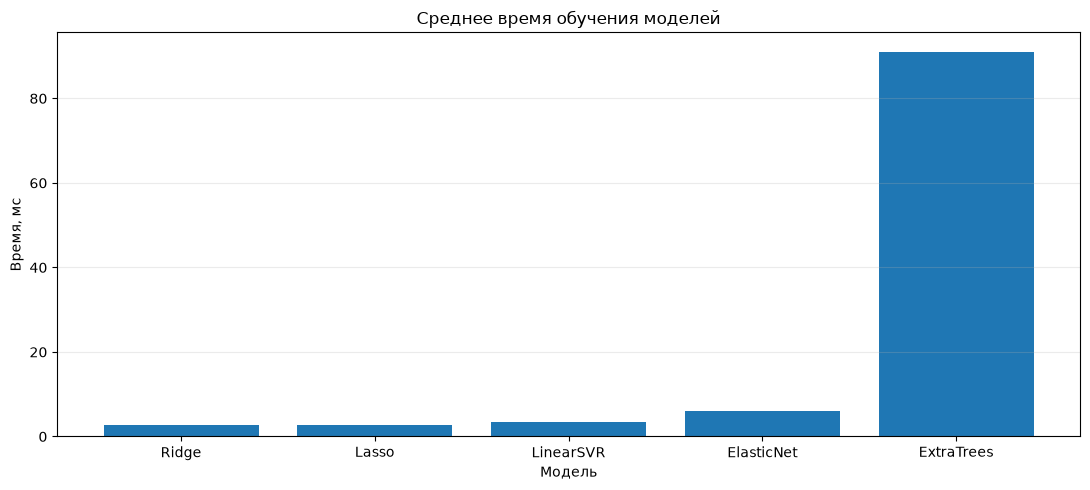

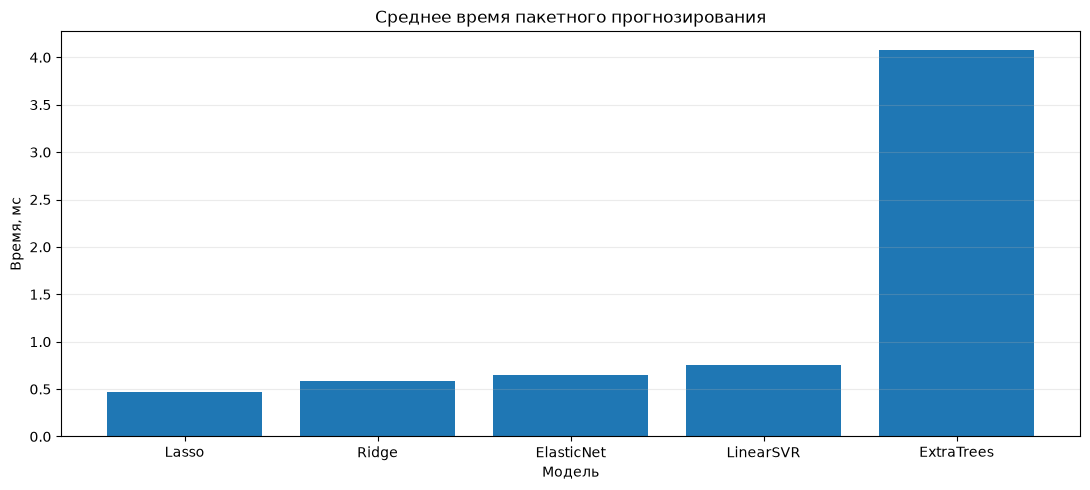

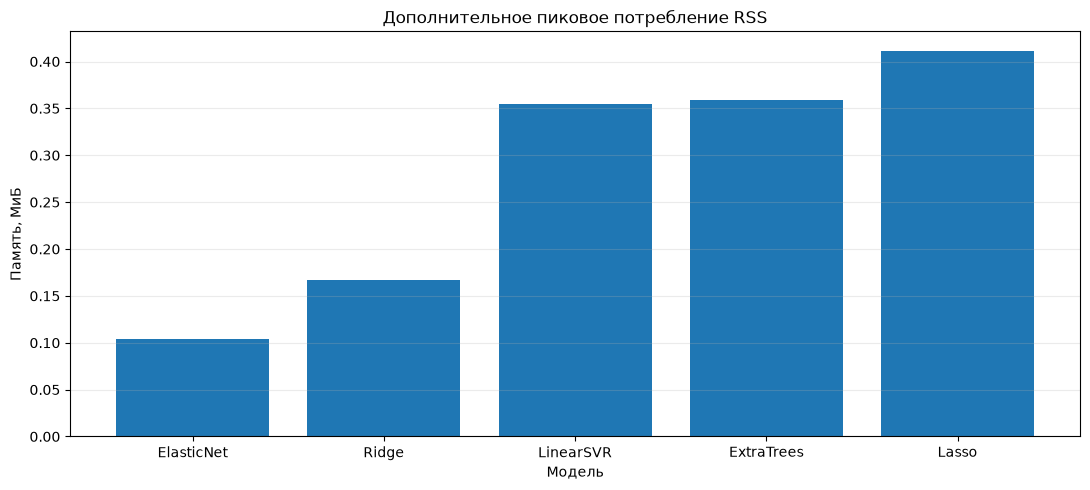

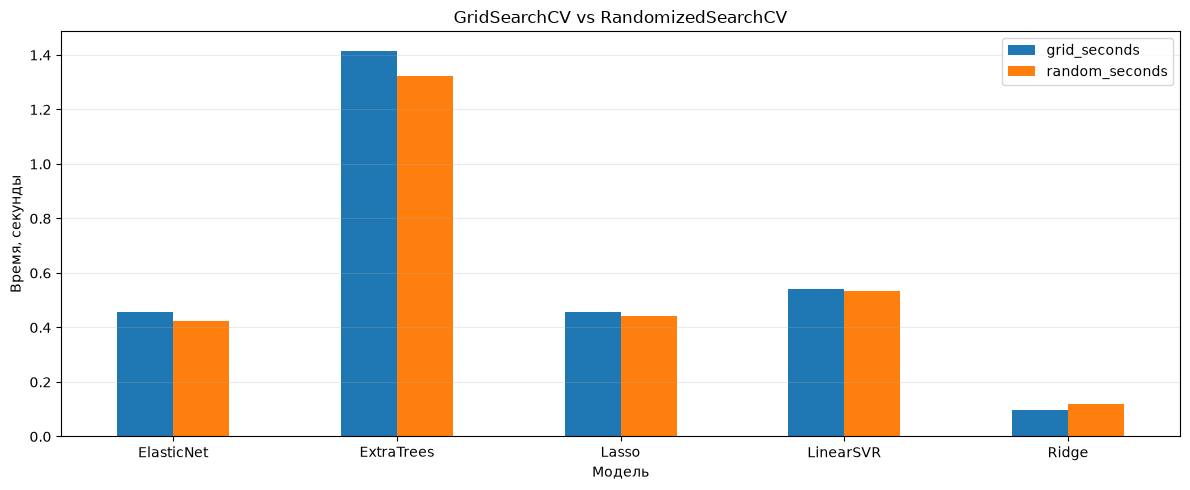

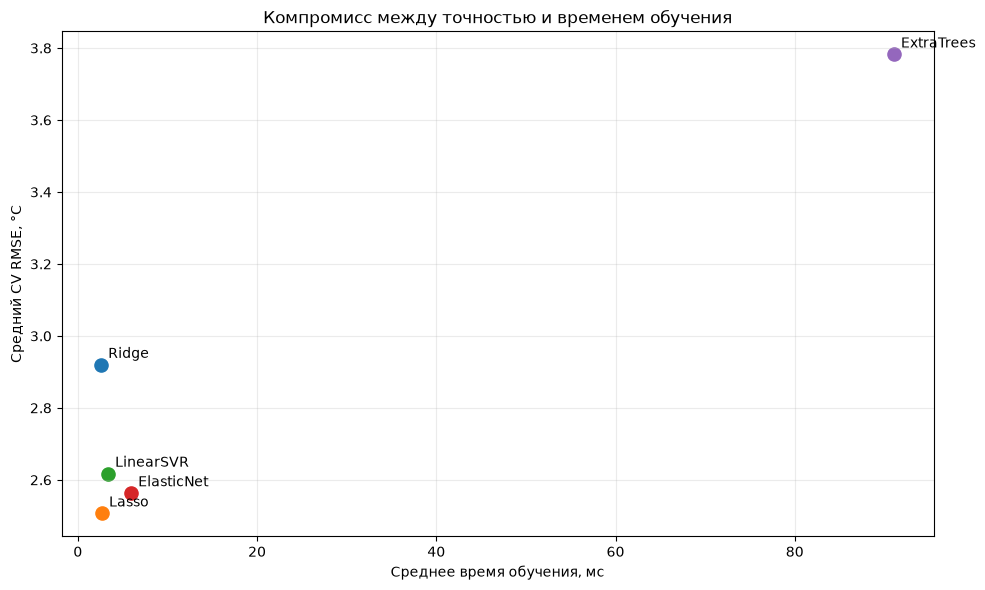


8. ИТОГОВЫЕ ПРОВЕРКИ
PASS | data_loaded
PASS | models_loaded
PASS | benchmark_repeats_completed
PASS | benchmark_values_finite
PASS | search_methods_completed
PASS | equal_search_budget
PASS | search_metrics_finite
PASS | search_quality_equal
PASS | accuracy_join_completed
PASS | results_saved

Пройдено: 10 из 10

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_4/reports/task9

ЗАДАНИЕ 9 ЗАВЕРШЕНО


In [19]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 9. ВЫЧИСЛИТЕЛЬНАЯ ЭФФЕКТИВНОСТЬ
# ============================================================

from pathlib import Path
from contextlib import contextmanager
from threading import Thread, Event
from time import perf_counter
import gc
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import psutil

from sklearn.base import clone
from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)
from sklearn.pipeline import Pipeline

from IPython.display import display

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

# ============================================================
# 1. КОНФИГУРАЦИЯ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models" / "task4"
REPORT_DIR = PROJECT / "reports" / "task9"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SOURCE = DATA_DIR / "task3_trainval.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

MODEL_NAMES = [
    "Lasso",
    "ElasticNet",
    "LinearSVR",
    "Ridge",
    "ExtraTrees"
]

N_SPLITS = 5
N_REPEATS = 3
N_CANDIDATES = 8

RANDOM_STATE = 42

# Все эксперименты выполняются
# последовательно, без параллельных jobs.

N_JOBS = 1

# Интервал опроса памяти — 5 мс.
MEMORY_POLL_SECONDS = 0.005

# ============================================================
# 2. ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv(
    SOURCE,
    parse_dates=[DATE_COL]
)

df = (
    df.sort_values(DATE_COL)
    .reset_index(drop=True)
)

feature_cols = [
    col for col in df.columns
    if col not in [DATE_COL, TARGET]
]

X = df[feature_cols].copy()
y = df[TARGET].astype(float).copy()

assert df[DATE_COL].is_unique
assert df[DATE_COL].is_monotonic_increasing
assert X.notna().all().all()
assert y.notna().all()

# Последний временной фолд используем
# для измерения обычного fit/predict.
# Финальная тестовая выборка не используется.

splits = list(
    TimeSeriesSplit(
        n_splits=N_SPLITS
    ).split(X)
)

train_idx, val_idx = splits[-1]

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_val = X.iloc[val_idx]
y_val = y.iloc[val_idx]

print("=" * 80)
print("1. ДАННЫЕ")
print("=" * 80)

print("Всего наблюдений:", len(df))
print("Количество признаков:", len(feature_cols))
print("Train:", len(X_train))
print("Validation:", len(X_val))

print(
    "Период train:",
    df.iloc[train_idx[0]][DATE_COL].date(),
    "—",
    df.iloc[train_idx[-1]][DATE_COL].date()
)

print(
    "Период validation:",
    df.iloc[val_idx[0]][DATE_COL].date(),
    "—",
    df.iloc[val_idx[-1]][DATE_COL].date()
)

# ============================================================
# 3. ЗАГРУЗКА МОДЕЛЕЙ
# ============================================================

models = {}

for name in MODEL_NAMES:

    path = MODEL_DIR / f"{name}.joblib"

    if not path.exists():
        raise FileNotFoundError(
            f"Не найдена модель: {path}"
        )

    models[name] = clone(
        joblib.load(path)
    )

    # Если у алгоритма есть n_jobs,
    # ограничиваем внутренний параллелизм.
    # Для Pipeline параметр может находиться
    # внутри последнего шага.

    params = models[name].get_params()

    if isinstance(models[name], Pipeline):

        last_step_name = (
            models[name].steps[-1][0]
        )

        n_jobs_key = (
            f"{last_step_name}__n_jobs"
        )

    else:
        n_jobs_key = "n_jobs"

    if n_jobs_key in params:
        models[name].set_params(
            **{n_jobs_key: N_JOBS}
        )

print("\n" + "=" * 80)
print("2. ЗАГРУЖЕННЫЕ МОДЕЛИ")
print("=" * 80)

for name, model in models.items():
    print(
        name,
        "—",
        type(model).__name__
    )

# ============================================================
# 4. МОНИТОРИНГ ПАМЯТИ
# ============================================================

PROCESS = psutil.Process()


@contextmanager
def monitor_memory(
    interval=MEMORY_POLL_SECONDS
):
    """
    Оценивает максимальное увеличение
    RSS процесса относительно начала
    измерения.

    Измерение приблизительное:
    очень короткие пики могут быть
    пропущены между опросами.
    """

    stop_event = Event()

    baseline = PROCESS.memory_info().rss

    result = {
        "baseline_bytes": baseline,
        "peak_bytes": baseline,
        "peak_delta_mib": 0.0
    }

    def sampler():

        while not stop_event.is_set():

            current = (
                PROCESS.memory_info().rss
            )

            if current > result["peak_bytes"]:
                result["peak_bytes"] = current

            stop_event.wait(interval)

    thread = Thread(
        target=sampler,
        daemon=True
    )

    thread.start()

    try:
        yield result

    finally:

        current = PROCESS.memory_info().rss

        result["peak_bytes"] = max(
            result["peak_bytes"],
            current
        )

        stop_event.set()
        thread.join()

        result["peak_delta_mib"] = (
            max(
                0,
                result["peak_bytes"]
                - result["baseline_bytes"]
            )
            / (1024 ** 2)
        )


# ============================================================
# 5. ИЗМЕРЕНИЕ FIT И PREDICT
# ============================================================

benchmark_records = []

print("\n" + "=" * 80)
print("3. ИЗМЕРЕНИЕ ВРЕМЕНИ И ПАМЯТИ")
print("=" * 80)

for name in MODEL_NAMES:

    print(f"\nМодель: {name}")

    for repeat in range(
        1,
        N_REPEATS + 1
    ):

        gc.collect()

        model = clone(
            models[name]
        )

        # ------------------------------------
        # Время обучения + память
        # ------------------------------------

        start = perf_counter()

        with monitor_memory() as memory:

            model.fit(
                X_train,
                y_train
            )

        fit_seconds = (
            perf_counter() - start
        )

        # ------------------------------------
        # Время пакетного прогнозирования
        # ------------------------------------

        start = perf_counter()

        predictions = model.predict(
            X_val
        )

        predict_seconds = (
            perf_counter() - start
        )

        predictions = np.asarray(
            predictions,
            dtype=float
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val,
                predictions
            )
        )

        mae = mean_absolute_error(
            y_val,
            predictions
        )

        record = {
            "model": name,
            "repeat": repeat,
            "fit_ms": fit_seconds * 1000,
            "predict_ms": (
                predict_seconds * 1000
            ),
            "predict_us_per_row": (
                predict_seconds
                * 1_000_000
                / len(X_val)
            ),
            "peak_memory_mib": (
                memory["peak_delta_mib"]
            ),
            "MAE": float(mae),
            "RMSE": float(rmse)
        }

        benchmark_records.append(
            record
        )

        print(
            f"Повтор {repeat}: "
            f"fit={record['fit_ms']:.3f} мс; "
            f"predict={record['predict_ms']:.3f} мс; "
            f"memory={record['peak_memory_mib']:.3f} МиБ"
        )

        del model
        gc.collect()

benchmark_df = pd.DataFrame(
    benchmark_records
)

benchmark_summary = (
    benchmark_df
    .groupby("model")
    .agg(
        fit_mean_ms=("fit_ms", "mean"),
        fit_std_ms=("fit_ms", "std"),
        predict_mean_ms=("predict_ms", "mean"),
        predict_std_ms=("predict_ms", "std"),
        predict_us_per_row=(
            "predict_us_per_row",
            "mean"
        ),
        peak_memory_mean_mib=(
            "peak_memory_mib",
            "mean"
        ),
        peak_memory_max_mib=(
            "peak_memory_mib",
            "max"
        ),
        RMSE=("RMSE", "mean"),
        MAE=("MAE", "mean")
    )
    .reset_index()
    .sort_values("fit_mean_ms")
)

print("\nСводные результаты:")
display(
    benchmark_summary.round(5)
)

# ============================================================
# 6. ПОДГОТОВКА ПРОСТРАНСТВА ПОИСКА
# ============================================================

# Для каждой модели варьируем один
# основной гиперпараметр.
#
# Остальные настройки берём из
# сохранённой модели задания 4.
#
# GridSearchCV и RandomizedSearchCV
# получат одинаковые 8 конфигураций.

SEARCH_VALUES = {
    "Lasso": {
        "alpha": [
            0.001,
            0.005,
            0.01,
            0.03,
            0.05,
            0.1,
            0.3,
            1.0
        ]
    },
    "ElasticNet": {
        "alpha": [
            0.001,
            0.005,
            0.01,
            0.03,
            0.05,
            0.1,
            0.3,
            1.0
        ]
    },
    "LinearSVR": {
        "C": [
            0.01,
            0.03,
            0.1,
            0.3,
            1.0,
            3.0,
            10.0,
            30.0
        ]
    },
    "Ridge": {
        "alpha": [
            0.01,
            0.1,
            0.5,
            1.0,
            3.0,
            10.0,
            30.0,
            100.0
        ]
    },
    "ExtraTrees": {
        "n_estimators": [
            20,
            30,
            40,
            50,
            60,
            80,
            100,
            120
        ]
    }
}


def get_parameter_key(
    model,
    parameter_name
):
    """
    Возвращает имя параметра
    с учётом Pipeline.
    """

    if isinstance(model, Pipeline):

        last_step = (
            model.steps[-1][0]
        )

        return (
            f"{last_step}__{parameter_name}"
        )

    return parameter_name


search_spaces = {}

for name in MODEL_NAMES:

    parameter_name = next(
        iter(SEARCH_VALUES[name])
    )

    values = SEARCH_VALUES[name][
        parameter_name
    ]

    key = get_parameter_key(
        models[name],
        parameter_name
    )

    if key not in models[name].get_params():
        raise ValueError(
            f"{name}: параметр {key} "
            "не найден в модели."
        )

    assert len(values) == N_CANDIDATES

    search_spaces[name] = {
        key: values
    }

print("\n" + "=" * 80)
print("4. ПРОСТРАНСТВА ПОИСКА")
print("=" * 80)

for name, space in search_spaces.items():
    print(name, ":", space)

# ============================================================
# 7. GRIDSEARCHCV И RANDOMIZEDSEARCHCV
# ============================================================

search_records = []
search_candidates = []

print("\n" + "=" * 80)
print("5. СРАВНЕНИЕ GRID И RANDOMIZED SEARCH")
print("=" * 80)

for name in MODEL_NAMES:

    print(f"\nМодель: {name}")

    space = search_spaces[name]

    for method in [
        "GridSearchCV",
        "RandomizedSearchCV"
    ]:

        gc.collect()

        estimator = clone(
            models[name]
        )

        cv = TimeSeriesSplit(
            n_splits=N_SPLITS
        )

        if method == "GridSearchCV":

            search = GridSearchCV(
                estimator=estimator,
                param_grid=space,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                n_jobs=N_JOBS,
                refit=False,
                error_score="raise"
            )

        else:

            search = RandomizedSearchCV(
                estimator=estimator,
                param_distributions=space,
                n_iter=N_CANDIDATES,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                n_jobs=N_JOBS,
                random_state=RANDOM_STATE,
                refit=False,
                error_score="raise"
            )

        start = perf_counter()

        with monitor_memory() as memory:

            search.fit(
                X,
                y
            )

        elapsed_seconds = (
            perf_counter() - start
        )

        results = pd.DataFrame(
            search.cv_results_
        )

        # Проверяем число кандидатов.
        n_candidates = len(results)

        best_rmse = float(
            -search.best_score_
        )

        search_records.append({
            "model": name,
            "method": method,
            "search_seconds": (
                elapsed_seconds
            ),
            "peak_memory_mib": (
                memory["peak_delta_mib"]
            ),
            "n_candidates": n_candidates,
            "n_fits": (
                n_candidates * N_SPLITS
            ),
            "best_cv_rmse": best_rmse,
            "best_params": json.dumps(
                search.best_params_,
                ensure_ascii=False
            )
        })

        for _, candidate in results.iterrows():

            search_candidates.append({
                "model": name,
                "method": method,
                "params": str(
                    candidate["params"]
                ),
                "mean_test_rmse": float(
                    -candidate["mean_test_score"]
                ),
                "std_test_rmse": float(
                    candidate["std_test_score"]
                ),
                "mean_fit_time_s": float(
                    candidate["mean_fit_time"]
                ),
                "mean_score_time_s": float(
                    candidate["mean_score_time"]
                )
            })

        print(
            f"{method}: "
            f"{elapsed_seconds:.3f} с; "
            f"лучший CV RMSE={best_rmse:.4f}; "
            f"память={memory['peak_delta_mib']:.3f} МиБ"
        )

        del search
        gc.collect()

search_df = pd.DataFrame(
    search_records
)

search_candidates_df = pd.DataFrame(
    search_candidates
)

print("\nСводная таблица поиска:")
display(
    search_df[[
        "model",
        "method",
        "search_seconds",
        "peak_memory_mib",
        "n_candidates",
        "n_fits",
        "best_cv_rmse",
        "best_params"
    ]].round(5)
)

# ============================================================
# 8. СРАВНЕНИЕ GRID VS RANDOMIZED
# ============================================================

grid_pivot = search_df.pivot(
    index="model",
    columns="method",
    values="search_seconds"
)

rmse_pivot = search_df.pivot(
    index="model",
    columns="method",
    values="best_cv_rmse"
)

comparison_df = pd.DataFrame({
    "model": grid_pivot.index,
    "grid_seconds": (
        grid_pivot["GridSearchCV"].values
    ),
    "random_seconds": (
        grid_pivot["RandomizedSearchCV"].values
    ),
    "grid_rmse": (
        rmse_pivot["GridSearchCV"].values
    ),
    "random_rmse": (
        rmse_pivot["RandomizedSearchCV"].values
    )
})

comparison_df["random_speedup"] = (
    comparison_df["grid_seconds"]
    / comparison_df["random_seconds"]
)

comparison_df["rmse_difference"] = (
    comparison_df["random_rmse"]
    - comparison_df["grid_rmse"]
)

print("\n" + "=" * 80)
print("6. СРАВНЕНИЕ МЕТОДОВ ПОИСКА")
print("=" * 80)

display(
    comparison_df.round(5)
)

# ============================================================
# 9. ТОЧНОСТЬ И ВЫЧИСЛИТЕЛЬНЫЕ ЗАТРАТЫ
# ============================================================

# Используем CV RMSE из задания 7,
# чтобы сопоставить качество и время
# обучения при выбранных параметрах.

TASK7_SUMMARY = (
    PROJECT
    / "reports"
    / "task7"
    / "cv_summary.csv"
)

if not TASK7_SUMMARY.exists():
    raise FileNotFoundError(
        f"Не найден файл: {TASK7_SUMMARY}"
    )

task7_summary = pd.read_csv(
    TASK7_SUMMARY
)

accuracy_efficiency = (
    benchmark_summary
    .merge(
        task7_summary[[
            "model",
            "RMSE_mean",
            "RMSE_std"
        ]],
        on="model",
        how="left"
    )
)

print("\n" + "=" * 80)
print("7. ТОЧНОСТЬ И ЭФФЕКТИВНОСТЬ")
print("=" * 80)

display(
    accuracy_efficiency[[
        "model",
        "RMSE_mean",
        "RMSE_std",
        "fit_mean_ms",
        "predict_mean_ms",
        "peak_memory_mean_mib"
    ]].round(5)
)

# ============================================================
# 10. ГРАФИКИ
# ============================================================

# 10.1 Время обучения

plt.figure(figsize=(11, 5))

plot_df = benchmark_summary.sort_values(
    "fit_mean_ms"
)

plt.bar(
    plot_df["model"],
    plot_df["fit_mean_ms"]
)

plt.title(
    "Среднее время обучения моделей"
)

plt.xlabel("Модель")
plt.ylabel("Время, мс")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "fit_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# 10.2 Время прогнозирования

plt.figure(figsize=(11, 5))

plot_df = benchmark_summary.sort_values(
    "predict_mean_ms"
)

plt.bar(
    plot_df["model"],
    plot_df["predict_mean_ms"]
)

plt.title(
    "Среднее время пакетного прогнозирования"
)

plt.xlabel("Модель")
plt.ylabel("Время, мс")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "predict_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# 10.3 Дополнительная пиковая память

plt.figure(figsize=(11, 5))

plot_df = benchmark_summary.sort_values(
    "peak_memory_mean_mib"
)

plt.bar(
    plot_df["model"],
    plot_df["peak_memory_mean_mib"]
)

plt.title(
    "Дополнительное пиковое потребление RSS"
)

plt.xlabel("Модель")
plt.ylabel("Память, МиБ")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "memory_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# 10.4 Сравнение Grid и Randomized

comparison_plot = (
    comparison_df.set_index("model")
)

comparison_plot[[
    "grid_seconds",
    "random_seconds"
]].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title(
    "GridSearchCV vs RandomizedSearchCV"
)

plt.ylabel("Время, секунды")
plt.xlabel("Модель")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "search_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# 10.5 Точность против времени обучения

plt.figure(figsize=(10, 6))

for _, row in accuracy_efficiency.iterrows():

    plt.scatter(
        row["fit_mean_ms"],
        row["RMSE_mean"],
        s=90
    )

    plt.annotate(
        row["model"],
        (
            row["fit_mean_ms"],
            row["RMSE_mean"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title(
    "Компромисс между точностью "
    "и временем обучения"
)

plt.xlabel("Среднее время обучения, мс")
plt.ylabel("Средний CV RMSE, °C")
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "accuracy_vs_time.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================

outputs = {
    "benchmark_repeats.csv": benchmark_df,
    "benchmark_summary.csv": benchmark_summary,
    "search_results.csv": search_df,
    "search_candidates.csv": search_candidates_df,
    "search_comparison.csv": comparison_df,
    "accuracy_efficiency.csv": accuracy_efficiency
}

for filename, dataframe in outputs.items():

    dataframe.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

config = {
    "task": 9,
    "models": MODEL_NAMES,
    "n_splits": N_SPLITS,
    "n_repeats": N_REPEATS,
    "n_candidates": N_CANDIDATES,
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS,
    "memory_poll_seconds": MEMORY_POLL_SECONDS,
    "memory_measure": "sampled RSS delta",
    "search_refit": False,
    "test_set_used": False,
    "search_spaces": SEARCH_VALUES,
    "limitations": [
        "RSS polling may miss short memory peaks",
        "Memory results depend on process allocator",
        "Search times measured once per method",
        "Both search methods enumerate the same candidates",
        "Hyperparameters were tuned in task 4",
        "Timing depends on hardware and system load"
    ]
}

(
    REPORT_DIR / "experiment_config.json"
).write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 12. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "data_loaded": len(df) > 0,
    "models_loaded": (
        len(models) == len(MODEL_NAMES)
    ),
    "benchmark_repeats_completed": (
        len(benchmark_df)
        == len(MODEL_NAMES) * N_REPEATS
    ),
    "benchmark_values_finite": bool(
        np.isfinite(
            benchmark_df[[
                "fit_ms",
                "predict_ms",
                "peak_memory_mib",
                "RMSE"
            ]].to_numpy()
        ).all()
    ),
    "search_methods_completed": (
        len(search_df)
        == len(MODEL_NAMES) * 2
    ),
    "equal_search_budget": bool(
        (search_df["n_candidates"]
         == N_CANDIDATES).all()
    ),
    "search_metrics_finite": bool(
        np.isfinite(
            search_df[[
                "search_seconds",
                "best_cv_rmse"
            ]].to_numpy()
        ).all()
    ),
    "search_quality_equal": bool(
        np.allclose(
            comparison_df["grid_rmse"],
            comparison_df["random_rmse"]
        )
    ),
    "accuracy_join_completed": bool(
        accuracy_efficiency[
            "RMSE_mean"
        ].notna().all()
    ),
    "results_saved": all(
        (REPORT_DIR / filename).exists()
        for filename in outputs
    )
}

print("\n" + "=" * 80)
print("8. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

print("\nЗАДАНИЕ 9 ЗАВЕРШЕНО")


### Анализ результатов выполнения задания 9

В ходе выполнения девятого задания была проведена оценка вычислительной эффективности моделей машинного обучения для прогнозирования среднесуточной температуры воздуха в Москве.

Для исследования использовались пять алгоритмов: Lasso, ElasticNet, LinearSVR, Ridge и ExtraTrees.

Эксперимент включал измерение времени обучения, времени прогнозирования, дополнительного пикового потребления оперативной памяти и сравнение методов подбора гиперпараметров GridSearchCV и RandomizedSearchCV.

Дополнительно вычислительные затраты были сопоставлены с результатами точности, полученными в задании 7.

**1. Анализ времени обучения**

Для измерения времени обучения использовалась функция `time.perf_counter()`.

Каждая модель обучалась три раза на одинаковой обучающей выборке.

Получены следующие средние значения:

- Ridge — 2,61463 мс;
- Lasso — 2,71051 мс;
- LinearSVR — 3,38643 мс;
- ElasticNet — 5,96364 мс;
- ExtraTrees — 91,07628 мс.

Наименьшее среднее время обучения продемонстрировала Ridge.

Lasso оказалась лишь немного медленнее: разница составила около 0,096 мс.

Наиболее ресурсоёмкой по времени обучения оказалась ExtraTrees. Она обучалась приблизительно в 33,6 раза дольше Lasso.

Это объясняется особенностями ансамблевого алгоритма, которому необходимо построить множество деревьев решений.

При этом абсолютное время обучения всех моделей на рассматриваемом датасете остаётся небольшим.

**2. Анализ скорости прогнозирования**

Для оценки скорости прогнозирования измерялось время обработки одинаковой валидационной выборки.

Среднее время прогнозирования составило:

- Lasso — 0,47304 мс;
- Ridge — 0,58196 мс;
- ElasticNet — 0,64621 мс;
- LinearSVR — 0,75321 мс;
- ExtraTrees — 4,07419 мс.

Наименьшее время прогнозирования показала Lasso.

ExtraTrees выполняла прогнозирование приблизительно в 8,6 раза дольше Lasso.

Полученные результаты показывают, что линейные модели могут обеспечивать высокую скорость прогнозирования благодаря относительно простым вычислениям.

Следует учитывать, что измерялась скорость пакетного прогнозирования. Среднее время на одно наблюдение рассчитывалось делением общей продолжительности на размер валидационной выборки и не является независимым измерением задержки отдельного запроса.

**3. Анализ потребления оперативной памяти**

Для оценки дополнительного потребления памяти использовался периодический мониторинг RSS Python-процесса.

Средние значения дополнительного пикового потребления памяти составили:

- Ridge — 0,16667 МиБ;
- Lasso — 0,41146 МиБ;
- LinearSVR — 0,35417 МиБ;
- ElasticNet — 0,10417 МиБ;
- ExtraTrees — 0,35938 МиБ.

Наименьший зафиксированный средний прирост памяти наблюдался у ElasticNet.

При этом различия между моделями были небольшими и зависели от особенностей выделения памяти Python-процессом.

Использованный метод мониторинга имеет ограничения: он не фиксирует гарантированно все кратковременные пики и зависит от ранее выделенной памяти.

Поэтому полученные значения следует рассматривать как приблизительные характеристики конкретного запуска, а не как точные оценки полного потребления памяти алгоритмами.

**4. Сравнение GridSearchCV и RandomizedSearchCV**

Для сравнения методов подбора гиперпараметров использовались GridSearchCV и RandomizedSearchCV.

Для каждой модели задавалось восемь кандидатных конфигураций гиперпараметров.

Оценка выполнялась на пяти временных фолдах, поэтому каждый метод осуществлял 40 обучений для одной модели.

Получены следующие результаты времени поиска:

| Модель | GridSearchCV, с | RandomizedSearchCV, с |
|---|---:|---:|
| Lasso | 0,45615 | 0,44079 |
| ElasticNet | 0,45686 | 0,42520 |
| LinearSVR | 0,54140 | 0,53426 |
| Ridge | 0,09731 | 0,11920 |
| ExtraTrees | 1,41600 | 1,32182 |

RandomizedSearchCV оказался немного быстрее для Lasso, ElasticNet, LinearSVR и ExtraTrees.

Для Ridge более быстрым оказался GridSearchCV.

Однако оба метода проверяли одинаковые восемь конфигураций, поэтому различия во времени были относительно небольшими.

Полученные результаты не позволяют сделать вывод об универсальном превосходстве одного метода поиска над другим.

Для оценки преимуществ случайного поиска при ограниченном бюджете необходимо использовать более широкое пространство гиперпараметров, в котором RandomizedSearchCV проверяет только часть доступных комбинаций.

**5. Качество найденных гиперпараметров**

Оба метода поиска обнаружили одинаковые лучшие конфигурации для каждой модели.

Получены следующие значения CV RMSE:

- LinearSVR — 2,49045 °C при C = 0,1;
- Lasso — 2,51368 °C при alpha = 0,3;
- ElasticNet — 2,54517 °C при alpha = 0,3;
- Ridge — 2,92752 °C при alpha = 100;
- ExtraTrees — 3,76357 °C при n_estimators = 120.

Разность лучших RMSE между GridSearchCV и RandomizedSearchCV во всех пяти случаях составила ноль.

Это ожидаемый результат, поскольку оба метода исследовали одинаковые наборы кандидатных параметров.

Наименьший CV RMSE в данном поисковом эксперименте продемонстрировала LinearSVR.

Однако эти результаты характеризуют ограниченный подбор гиперпараметров и не являются независимой оценкой качества на новых данных.

**6. Соотношение точности и вычислительных затрат**

Для оценки практической эффективности вычислительные характеристики моделей были сопоставлены с результатами временной кросс-валидации из задания 7.

Получены следующие показатели:

| Модель | Средний RMSE, °C | Время обучения, мс |
|---|---:|---:|
| Lasso | 2,50682 | 2,71051 |
| ElasticNet | 2,56295 | 5,96364 |
| LinearSVR | 2,61735 | 3,38643 |
| Ridge | 2,91968 | 2,61463 |
| ExtraTrees | 3,78224 | 91,07628 |

Наиболее выгодное сочетание точности и времени обучения среди исследованных обучаемых моделей продемонстрировала Lasso.

Её средний RMSE составил 2,50682 °C при времени обучения 2,71051 мс.

Ridge обучалась немного быстрее, но заметно уступала Lasso по точности.

ElasticNet и LinearSVR демонстрировали близкие значения ошибки, однако требовали больше времени обучения.

ExtraTrees оказалась наименее эффективной по рассматриваемому сочетанию показателей: она требовала существенно больше времени и показывала наибольшую ошибку.

Следовательно, повышение сложности алгоритма не привело к улучшению качества прогнозирования на используемом наборе данных.

**7. Ограничения исследования**

При интерпретации результатов необходимо учитывать несколько ограничений.

Во-первых, измерения времени обучения и прогнозирования проводились на относительно небольшом датасете.

Во-вторых, каждый эксперимент обычного обучения повторялся три раза, а поиск гиперпараметров выполнялся однократно.

В-третьих, результаты измерения памяти зависят от особенностей Python-процесса и операционной системы.

В-четвёртых, GridSearchCV и RandomizedSearchCV проверяли одинаковые конфигурации гиперпараметров, поэтому эксперимент не раскрывает преимущества случайного поиска при ограниченном бюджете в большом пространстве параметров.

В-пятых, измеренные времена зависят от используемого оборудования, фоновой нагрузки и программной среды.

### Итоговый вывод

В результате выполнения задания 9 проведено сравнение вычислительной эффективности пяти моделей машинного обучения.

Установлено, что Ridge обладает наименьшим средним временем обучения — 2,61463 мс.

Lasso показала наименьшее среднее время пакетного прогнозирования — 0,47304 мс.

Наиболее ресурсоёмкой по времени оказалась ExtraTrees: её обучение занимало в среднем 91,07628 мс, а прогнозирование — 4,07419 мс.

Сравнение GridSearchCV и RandomizedSearchCV показало одинаковое качество найденных конфигураций при одинаковом количестве проверенных гиперпараметров.

Небольшие различия во времени выполнения не позволяют установить устойчивое преимущество одного метода поиска.

Сопоставление вычислительных затрат с точностью из задания 7 показало, что Lasso обеспечивает наиболее удачный компромисс между качеством прогнозирования и скоростью вычислений среди рассмотренных обучаемых моделей.

Таким образом, результаты задания 9 дополнительно подтверждают целесообразность использования Lasso как одного из основных кандидатов для дальнейшего исследования.

При этом базовая модель Naive, показавшая наилучшую точность в задании 7, остаётся важным ориентиром для оценки практической полезности более сложных алгоритмов.

Все 10 автоматических проверок выполнены успешно. Результаты эксперимента сохранены в папке `reports/task9`.

# Задание 10. Проверка утечек данных и контрольные эксперименты

### Цель работы

Проверить корректность подготовки данных и обучения моделей прогнозирования среднесуточной температуры воздуха в Москве, выявить потенциальные утечки целевой переменной и оценить устойчивость результатов с помощью контрольных экспериментов.

### Постановка задачи

Необходимо:

1. Проверить хронологический порядок наблюдений и отсутствие дублирующихся дат.
2. Проверить, что обучающие наблюдения предшествуют валидационным.
3. Проверить корректность построения лаговых и скользящих признаков.
4. Убедиться, что признаки не содержат текущего или будущего значения целевой переменной.
5. Проверить отсутствие пересечения обучающего и тестового периодов.
6. Выполнить контрольный эксперимент с перемешанной целевой переменной.
7. Выполнить контрольный эксперимент со случайным шумом в целевой переменной.
8. Сравнить качество моделей на исходных и контрольных данных.
9. Выполнить специальный эксперимент с искусственно созданной утечкой целевой переменной.
10. Оценить, насколько искусственная утечка изменяет метрики качества.
11. Провести автоматические проверки и сохранить результаты.

### Методика выполнения

Для проверки временной структуры используются хронологические разбиения TimeSeriesSplit.

Корректность лаговых и скользящих признаков проверяется сравнением их значений с независимо рассчитанными характеристиками исходного временного ряда.

Контрольные эксперименты включают:

- обучение модели на исходной целевой переменной;
- обучение на случайно перемешанной целевой переменной;
- обучение на целевой переменной с добавленным случайным шумом;
- обучение с искусственно добавленным признаком, содержащим текущее значение целевой переменной.

Перемешивание и добавление шума применяются только в рамках отдельных контрольных экспериментов и не изменяют исходные данные проекта.

Для сопоставимости используются одинаковые временные разбиения и метрики MAE, RMSE и R².

### Ожидаемый результат

Подтверждена корректность хронологического разделения данных.

Проверено отсутствие очевидных утечек при формировании временных признаков.

Получены результаты контрольных экспериментов, демонстрирующие влияние нарушения связи между признаками и целевой переменной, добавления шума и искусственной утечки.

Сформулированы выводы о достоверности результатов моделирования и ограничениях проведённых проверок.

In [21]:

from pathlib import Path
import pandas as pd

PROJECT = Path.home() / "Desktop" / "ML" / "Practika_4"

files = [
    "task1_dataset.csv",
    "task3_trainval.csv",
    "task3_test.csv"
]

for filename in files:
    path = PROJECT / "data" / filename

    print(f"\n{'=' * 60}")
    print(f"Файл: {filename}")
    print(f"{'=' * 60}")

    df_check = pd.read_csv(path, nrows=5)

    print("Названия столбцов:")
    print(df_check.columns.tolist())

    print("\nПервые 5 строк:")
    print(df_check.head().to_string(index=False))



Файл: task1_dataset.csv
Названия столбцов:
['time', 'temperature_2m_mean', 'temperature_2m_mean_lag_1', 'temperature_2m_mean_lag_2', 'temperature_2m_mean_lag_3', 'temperature_2m_mean_lag_7', 'temperature_2m_mean_lag_14', 'temperature_2m_mean_lag_30', 'temperature_2m_mean_lag_90', 'temperature_2m_mean_lag_365', 'temperature_2m_max_lag_1', 'temperature_2m_max_lag_2', 'temperature_2m_max_lag_3', 'temperature_2m_max_lag_7', 'temperature_2m_max_lag_14', 'temperature_2m_max_lag_30', 'temperature_2m_max_lag_90', 'temperature_2m_max_lag_365', 'temperature_2m_min_lag_1', 'temperature_2m_min_lag_2', 'temperature_2m_min_lag_3', 'temperature_2m_min_lag_7', 'temperature_2m_min_lag_14', 'temperature_2m_min_lag_30', 'temperature_2m_min_lag_90', 'temperature_2m_min_lag_365', 'relative_humidity_2m_mean_lag_1', 'relative_humidity_2m_mean_lag_2', 'relative_humidity_2m_mean_lag_3', 'relative_humidity_2m_mean_lag_7', 'relative_humidity_2m_mean_lag_14', 'relative_humidity_2m_mean_lag_30', 'relative_humidit

Первые даты после исправления:
0   2024-01-01
1   2024-01-02
2   2024-01-03
3   2024-01-04
4   2024-01-05
Name: date, dtype: datetime64[us]

Последние даты:
726   2025-12-27
727   2025-12-28
728   2025-12-29
729   2025-12-30
730   2025-12-31
Name: date, dtype: datetime64[us]

Пересечение с trainval:
512

2. ПРОВЕРКА ЛАГОВ


,feature,lag,passed,max_abs_difference
0,target_lag_1,1,True,0.0
1,target_lag_2,2,True,0.0
2,target_lag_3,3,True,0.0
3,target_lag_7,7,True,0.0
4,target_lag_14,14,True,0.0
5,target_lag_21,21,True,0.0
6,target_lag_30,30,True,0.0
7,target_lag_60,60,True,0.0
8,target_lag_90,90,True,0.0



3. ПРОВЕРКА СКОЛЬЗЯЩИХ ПРИЗНАКОВ


,feature,operation,window,passed,max_abs_difference
0,target_roll_mean_3,mean,3,True,7.105427e-15
1,target_roll_std_3,std,3,True,7.265230e-13
2,target_roll_min_3,min,3,True,0.000000e+00
3,target_roll_max_3,max,3,True,0.000000e+00
4,target_roll_mean_7,mean,7,True,7.105427e-15
5,target_roll_std_7,std,7,True,2.743916e-13
6,target_roll_min_7,min,7,True,0.000000e+00
7,target_roll_max_7,max,7,True,0.000000e+00
8,target_roll_mean_14,mean,14,True,7.105427e-15
9,target_roll_std_14,std,14,True,2.666756e-13



4. ПРОВЕРКА ВРЕМЕННЫХ ФОЛДОВ


,fold,train_size,val_size,train_end,val_start,passed
0,1,87,85,2024-06-25,2024-06-26,True
1,2,172,85,2024-09-18,2024-09-19,True
2,3,257,85,2024-12-12,2024-12-13,True
3,4,342,85,2025-03-07,2025-03-08,True
4,5,427,85,2025-05-31,2025-06-01,True


... (2 outputs left out)


7. ИСКУССТВЕННАЯ УТЕЧКА


,fold,MAE,RMSE,R2
0,1,0.0,0.0,1.0
1,2,0.0,0.0,1.0
2,3,0.0,0.0,1.0
3,4,0.0,0.0,1.0
4,5,0.0,0.0,1.0



Средний RMSE с утечкой: 3.569040269691845e-14
Эти результаты демонстрационные и не могут считаться реальным качеством прогнозирования.

8. СРАВНЕНИЕ СЦЕНАРИЕВ


scenario,model,noisy_target,original,shuffled_target,shuffled_to_original_ratio,noisy_to_original_ratio
0,ExtraTrees,3.96766,3.78224,10.18362,2.69248,1.04902
1,Lasso,2.56101,2.50682,10.28214,4.10167,1.02162


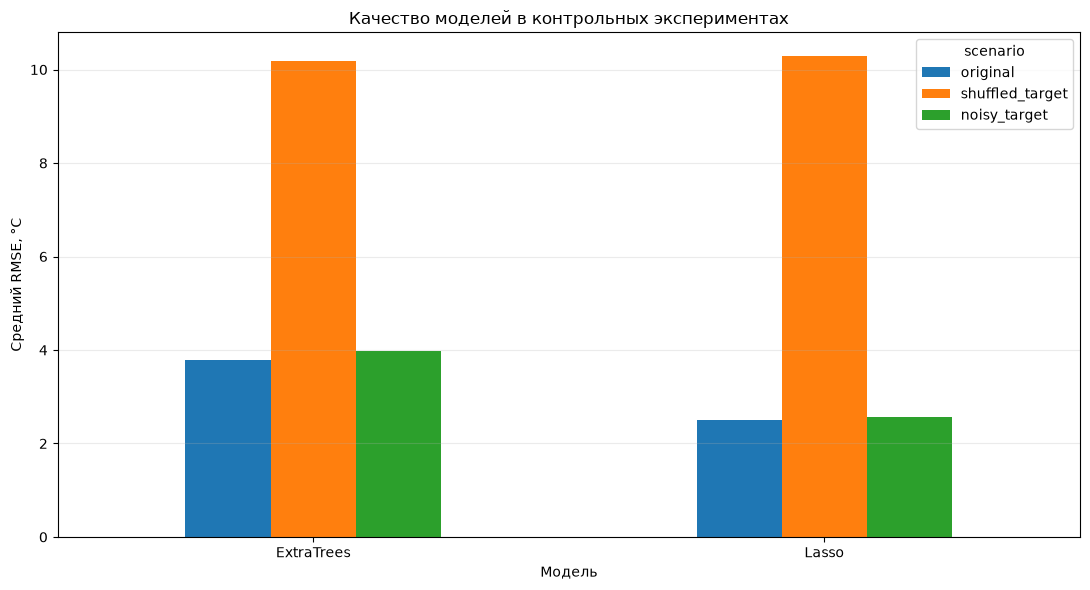

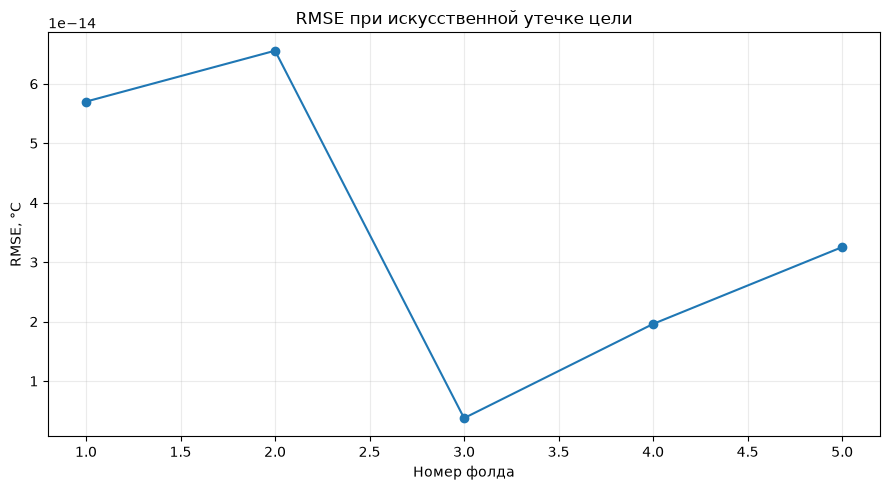


9. РЕЗУЛЬТАТЫ АУДИТА


,check,passed,details
0,raw_unique_dates,True,
1,raw_sorted_dates,True,
2,raw_daily_frequency,True,
3,trainval_unique_dates,True,
4,trainval_sorted_dates,True,
5,trainval_daily_frequency,True,
6,test_unique_dates,True,
7,test_sorted_dates,True,
8,test_daily_frequency,True,
9,train_test_no_overlap,True,



Проверок пройдено: 44 из 44

10. ИТОГОВЫЕ ПРОВЕРКИ
PASS | raw_data_loaded
PASS | trainval_loaded
PASS | test_loaded
PASS | chronology_audit_passed
PASS | lag_checks_passed
PASS | rolling_checks_passed
PASS | fold_checks_passed
PASS | control_experiments_completed
PASS | control_metrics_finite
PASS | artificial_leakage_completed
PASS | artificial_leakage_near_perfect
PASS | results_saved

Пройдено: 12 из 12

Результаты сохранены:
/Users/lenar_966/Desktop/ML/Practika_4/reports/task10

Основные автоматические проверки выполнены успешно.

ЗАДАНИЕ 10: ЭКСПЕРИМЕНТЫ ВЫПОЛНЕНЫ


In [24]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБО №4
# ЗАДАНИЕ 10. ПРОВЕРКА УТЕЧЕК ДАННЫХ
# И КОНТРОЛЬНЫЕ ЭКСПЕРИМЕНТЫ
# ============================================================

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.linear_model import LinearRegression

from IPython.display import display

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

# ============================================================
# 1. КОНФИГУРАЦИЯ
# ============================================================

ROOT = Path.home() / "Desktop" / "ML"
PROJECT = ROOT / "Practika_4"

DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models" / "task4"
REPORT_DIR = PROJECT / "reports" / "task10"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RAW_PATH = DATA_DIR / "task1_dataset.csv"
TRAIN_PATH = DATA_DIR / "task3_trainval.csv"
TEST_PATH = DATA_DIR / "task3_test.csv"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

MODEL_NAMES = ["Lasso", "ExtraTrees"]

N_SPLITS = 5
N_REPEATS = 3
NOISE_STD = 3.0
RANDOM_STATE = 42

# Числовая погрешность сравнения признаков.
ATOL = 1e-6



# Исходный файл: время сохранено со сдвигом -3 часа
raw = pd.read_csv(
    RAW_PATH,
    parse_dates=["time"]
)

raw = raw.rename(
    columns={"time": DATE_COL}
)

# Возвращаем временные метки к календарным
# датам, соответствующим московскому времени.
raw[DATE_COL] = (
    raw[DATE_COL] + pd.Timedelta(hours=3)
).dt.normalize()

raw = (
    raw.sort_values(DATE_COL)
    .reset_index(drop=True)
)

print("Первые даты после исправления:")
print(raw[DATE_COL].head())

print("\nПоследние даты:")
print(raw[DATE_COL].tail())

print("\nПересечение с trainval:")
print(
    len(
        set(raw[DATE_COL])
        & set(trainval[DATE_COL])
    )
)


# ============================================================
# 3. АУДИТ ХРОНОЛОГИИ
# ============================================================

audit_records = []

def add_check(name, passed, details=""):
    audit_records.append({
        "check": name,
        "passed": bool(passed),
        "details": str(details)
    })


for name, data in [
    ("raw", raw),
    ("trainval", trainval),
    ("test", test)
]:

    add_check(
        f"{name}_unique_dates",
        data[DATE_COL].is_unique
    )

    add_check(
        f"{name}_sorted_dates",
        data[DATE_COL].is_monotonic_increasing
    )

    add_check(
        f"{name}_daily_frequency",
        bool(
            data[DATE_COL]
            .diff()
            .dropna()
            .eq(pd.Timedelta(days=1))
            .all()
        )
    )

train_dates = set(trainval[DATE_COL])
test_dates = set(test[DATE_COL])
raw_dates = set(raw[DATE_COL])

add_check(
    "train_test_no_overlap",
    len(train_dates & test_dates) == 0
)

add_check(
    "train_before_test",
    trainval[DATE_COL].max()
    < test[DATE_COL].min()
)

add_check(
    "all_dates_in_raw",
    (train_dates | test_dates).issubset(raw_dates)
)

# Проверяем совпадение целевой переменной
# с исходным временным рядом.

raw_targets = raw.set_index(
    DATE_COL
)[TARGET]

aligned_train_target = (
    raw_targets.reindex(
        trainval[DATE_COL]
    ).to_numpy()
)

aligned_test_target = (
    raw_targets.reindex(
        test[DATE_COL]
    ).to_numpy()
)

add_check(
    "train_target_matches_raw",
    np.allclose(
        aligned_train_target,
        trainval[TARGET].to_numpy(),
        atol=ATOL,
        rtol=0,
        equal_nan=False
    )
)

add_check(
    "test_target_matches_raw",
    np.allclose(
        aligned_test_target,
        test[TARGET].to_numpy(),
        atol=ATOL,
        rtol=0,
        equal_nan=False
    )
)

# ============================================================
# 4. НЕЗАВИСИМАЯ ПРОВЕРКА ЛАГОВ
# ============================================================

# Исходный ряд индексируем по дате.
# Для каждого признака lag_k вычисляем
# температуру ровно k дней назад.

raw_series = raw.set_index(
    DATE_COL
)[TARGET].astype(float)

lag_pattern = re.compile(
    r"^target_lag_(\d+)$"
)

lag_records = []

for feature in feature_cols:

    match = lag_pattern.match(feature)

    if not match:
        continue

    lag = int(match.group(1))

    expected_dates = (
        trainval[DATE_COL]
        - pd.Timedelta(days=lag)
    )

    expected = raw_series.reindex(
        expected_dates
    ).to_numpy(dtype=float)

    actual = trainval[
        feature
    ].to_numpy(dtype=float)

    valid = np.isfinite(expected)

    passed = bool(
        valid.all()
        and np.allclose(
            actual,
            expected,
            atol=ATOL,
            rtol=0
        )
    )

    max_error = (
        float(
            np.max(
                np.abs(
                    actual[valid]
                    - expected[valid]
                )
            )
        )
        if valid.any()
        else np.nan
    )

    lag_records.append({
        "feature": feature,
        "lag": lag,
        "passed": passed,
        "max_abs_difference": max_error
    })

    add_check(
        f"lag_{lag}_correct",
        passed,
        f"max difference={max_error}"
    )

lag_df = pd.DataFrame(lag_records)

print("\n" + "=" * 80)
print("2. ПРОВЕРКА ЛАГОВ")
print("=" * 80)

display(lag_df)

# ============================================================
# 5. НЕЗАВИСИМАЯ ПРОВЕРКА СКОЛЬЗЯЩИХ ОКОН
# ============================================================

# Для даты t окно из w дней:
#
# t-w, ..., t-2, t-1
#
# Текущий день t в окно не входит.
#
# Пересчёт выполняем по исходному ряду.

rolling_pattern = re.compile(
    r"^target_roll_(mean|std|min|max)_(\d+)$"
)

rolling_records = []

raw_indexed = raw.set_index(
    DATE_COL
)

for feature in feature_cols:

    match = rolling_pattern.match(feature)

    if not match:
        continue

    operation = match.group(1)
    window = int(match.group(2))

    expected_values = []

    for date in trainval[DATE_COL]:

        dates = pd.date_range(
            end=date - pd.Timedelta(days=1),
            periods=window,
            freq="D"
        )

        values = raw_series.reindex(
            dates
        ).to_numpy(dtype=float)

        if not np.isfinite(values).all():

            expected_values.append(np.nan)
            continue

        if operation == "mean":
            value = np.mean(values)

        elif operation == "min":
            value = np.min(values)

        elif operation == "max":
            value = np.max(values)

        else:
            # pandas rolling.std()
            # по умолчанию использует ddof=1.
            value = np.std(
                values,
                ddof=1
            )

        expected_values.append(value)

    expected = np.asarray(
        expected_values,
        dtype=float
    )

    actual = trainval[
        feature
    ].to_numpy(dtype=float)

    valid = np.isfinite(expected)

    passed = bool(
        valid.all()
        and np.allclose(
            actual,
            expected,
            atol=ATOL,
            rtol=0
        )
    )

    max_error = (
        float(
            np.max(
                np.abs(
                    actual[valid]
                    - expected[valid]
                )
            )
        )
        if valid.any()
        else np.nan
    )

    rolling_records.append({
        "feature": feature,
        "operation": operation,
        "window": window,
        "passed": passed,
        "max_abs_difference": max_error
    })

    add_check(
        f"{feature}_correct",
        passed,
        f"max difference={max_error}"
    )

rolling_df = pd.DataFrame(
    rolling_records
)

print("\n" + "=" * 80)
print("3. ПРОВЕРКА СКОЛЬЗЯЩИХ ПРИЗНАКОВ")
print("=" * 80)

display(rolling_df)

# ============================================================
# 6. ПРОВЕРКА ВРЕМЕННЫХ ФОЛДОВ
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=N_SPLITS
)

fold_records = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X),
    start=1
):

    train_end = trainval.iloc[
        train_idx[-1]
    ][DATE_COL]

    val_start = trainval.iloc[
        val_idx[0]
    ][DATE_COL]

    passed = bool(
        train_end < val_start
        and train_idx.max() < val_idx.min()
    )

    fold_records.append({
        "fold": fold,
        "train_size": len(train_idx),
        "val_size": len(val_idx),
        "train_end": train_end,
        "val_start": val_start,
        "passed": passed
    })

    add_check(
        f"fold_{fold}_chronological",
        passed
    )

fold_df = pd.DataFrame(
    fold_records
)

print("\n" + "=" * 80)
print("4. ПРОВЕРКА ВРЕМЕННЫХ ФОЛДОВ")
print("=" * 80)

display(fold_df)

# ============================================================
# 7. ЗАГРУЗКА МОДЕЛЕЙ
# ============================================================

models = {}

for name in MODEL_NAMES:

    path = MODEL_DIR / f"{name}.joblib"

    if not path.exists():
        raise FileNotFoundError(path)

    models[name] = clone(
        joblib.load(path)
    )

print("\n" + "=" * 80)
print("5. КОНТРОЛЬНЫЕ МОДЕЛИ")
print("=" * 80)

for name, model in models.items():
    print(name, type(model).__name__)

# ============================================================
# 8. ФУНКЦИЯ РАСЧЁТА МЕТРИК
# ============================================================

def evaluate(actual, predicted):

    return {
        "MAE": float(
            mean_absolute_error(
                actual,
                predicted
            )
        ),
        "RMSE": float(
            np.sqrt(
                mean_squared_error(
                    actual,
                    predicted
                )
            )
        ),
        "R2": float(
            r2_score(
                actual,
                predicted
            )
        )
    }

# ============================================================
# 9. КОНТРОЛЬНЫЕ ЭКСПЕРИМЕНТЫ
# ============================================================

# Сценарии:
#
# original:
#   исходная цель в обучении.
#
# shuffled_target:
#   обучающая цель перемешана;
#   валидационная цель не изменяется.
#
# noisy_target:
#   к обучающей цели добавлен шум;
#   валидационная цель не изменяется.
#
# Все модели используют одинаковые
# временные фолды.
#
# Для исходного сценария повторения
# нужны для сопоставимого формата;
# модель может давать одинаковые прогнозы.

experiment_records = []

rng = np.random.default_rng(
    RANDOM_STATE
)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X),
    start=1
):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[
        train_idx
    ].to_numpy(dtype=float)

    y_val = y.iloc[
        val_idx
    ].to_numpy(dtype=float)

    for repeat in range(
        1,
        N_REPEATS + 1
    ):

        scenarios = {
            "original": y_train.copy(),

            "shuffled_target": rng.permutation(
                y_train
            ),

            "noisy_target": (
                y_train
                + rng.normal(
                    loc=0,
                    scale=NOISE_STD,
                    size=len(y_train)
                )
            )
        }

        for scenario, target_train in scenarios.items():

            for name, template in models.items():

                model = clone(template)

                model.fit(
                    X_train,
                    target_train
                )

                predicted = model.predict(
                    X_val
                )

                metrics = evaluate(
                    y_val,
                    predicted
                )

                experiment_records.append({
                    "fold": fold,
                    "repeat": repeat,
                    "model": name,
                    "scenario": scenario,
                    **metrics
                })

experiments_df = pd.DataFrame(
    experiment_records
)

experiment_summary = (
    experiments_df
    .groupby(
        ["model", "scenario"]
    )
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std")
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("6. КОНТРОЛЬНЫЕ ЭКСПЕРИМЕНТЫ")
print("=" * 80)

display(
    experiment_summary.round(5)
)

# ============================================================
# 10. ИСКУССТВЕННАЯ УТЕЧКА
# ============================================================

# Демонстрационный эксперимент.
#
# Добавляем в X признак, содержащий
# текущее значение целевой переменной.
#
# Это недопустимо при реальном
# прогнозировании.
#
# Используем LinearRegression:
# она должна практически точно
# восстановить целевую переменную.

leakage_records = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X),
    start=1
):

    X_train = X.iloc[
        train_idx
    ].copy()

    X_val = X.iloc[
        val_idx
    ].copy()

    y_train = y.iloc[
        train_idx
    ].to_numpy(dtype=float)

    y_val = y.iloc[
        val_idx
    ].to_numpy(dtype=float)

    # НАМЕРЕННАЯ УТЕЧКА:
    X_train["LEAK_CURRENT_TARGET"] = y_train
    X_val["LEAK_CURRENT_TARGET"] = y_val

    model = LinearRegression()

    model.fit(
        X_train,
        y_train
    )

    predicted = model.predict(
        X_val
    )

    leakage_records.append({
        "fold": fold,
        **evaluate(
            y_val,
            predicted
        )
    })

leakage_df = pd.DataFrame(
    leakage_records
)

print("\n" + "=" * 80)
print("7. ИСКУССТВЕННАЯ УТЕЧКА")
print("=" * 80)

display(
    leakage_df.round(10)
)

print(
    "\nСредний RMSE с утечкой:",
    leakage_df["RMSE"].mean()
)

print(
    "Эти результаты демонстрационные "
    "и не могут считаться реальным "
    "качеством прогнозирования."
)

# ============================================================
# 11. СОПОСТАВЛЕНИЕ СЦЕНАРИЕВ
# ============================================================

comparison = experiment_summary.pivot(
    index="model",
    columns="scenario",
    values="RMSE_mean"
).reset_index()

comparison["shuffled_to_original_ratio"] = (
    comparison["shuffled_target"]
    / comparison["original"]
)

comparison["noisy_to_original_ratio"] = (
    comparison["noisy_target"]
    / comparison["original"]
)

print("\n" + "=" * 80)
print("8. СРАВНЕНИЕ СЦЕНАРИЕВ")
print("=" * 80)

display(
    comparison.round(5)
)

# ============================================================
# 12. ГРАФИКИ
# ============================================================

# 12.1 RMSE по сценариям

pivot_plot = experiment_summary.pivot(
    index="model",
    columns="scenario",
    values="RMSE_mean"
)

pivot_plot[[
    "original",
    "shuffled_target",
    "noisy_target"
]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Качество моделей в контрольных экспериментах"
)

plt.xlabel("Модель")
plt.ylabel("Средний RMSE, °C")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "control_experiments.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# 12.2 Ошибка при искусственной утечке

plt.figure(figsize=(9, 5))

plt.plot(
    leakage_df["fold"],
    leakage_df["RMSE"],
    marker="o"
)

plt.title(
    "RMSE при искусственной утечке цели"
)

plt.xlabel("Номер фолда")
plt.ylabel("RMSE, °C")
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "artificial_leakage.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. СВОДНЫЙ АУДИТ
# ============================================================

audit_df = pd.DataFrame(
    audit_records
)

print("\n" + "=" * 80)
print("9. РЕЗУЛЬТАТЫ АУДИТА")
print("=" * 80)

display(audit_df)

print(
    "\nПроверок пройдено:",
    int(audit_df["passed"].sum()),
    "из",
    len(audit_df)
)

# ============================================================
# 14. СОХРАНЕНИЕ
# ============================================================

outputs = {
    "chronology_audit.csv": audit_df,
    "lag_checks.csv": lag_df,
    "rolling_checks.csv": rolling_df,
    "fold_checks.csv": fold_df,
    "control_experiments.csv": experiments_df,
    "control_summary.csv": experiment_summary,
    "artificial_leakage.csv": leakage_df,
    "scenario_comparison.csv": comparison
}

for filename, dataframe in outputs.items():

    dataframe.to_csv(
        REPORT_DIR / filename,
        index=False,
        encoding="utf-8-sig"
    )

config = {
    "task": 10,
    "models": MODEL_NAMES,
    "n_splits": N_SPLITS,
    "n_repeats": N_REPEATS,
    "noise_std": NOISE_STD,
    "random_state": RANDOM_STATE,
    "test_used_for_training": False,
    "scenarios": [
        "original",
        "shuffled_target",
        "noisy_target",
        "artificial_leakage"
    ],
    "notes": [
        "Trainval and test chronology checked",
        "Lag features verified against raw series",
        "Rolling features verified against raw series",
        "Target perturbations applied only to training labels",
        "Artificial leakage is demonstration only",
        "Passing checks does not prove absence of all leakage"
    ]
}

(
    REPORT_DIR / "experiment_config.json"
).write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# ============================================================
# 15. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "raw_data_loaded": len(raw) > 0,
    "trainval_loaded": len(trainval) > 0,
    "test_loaded": len(test) > 0,
    "chronology_audit_passed": bool(
        audit_df["passed"].all()
    ),
    "lag_checks_passed": bool(
        len(lag_df) > 0
        and lag_df["passed"].all()
    ),
    "rolling_checks_passed": bool(
        len(rolling_df) > 0
        and rolling_df["passed"].all()
    ),
    "fold_checks_passed": bool(
        fold_df["passed"].all()
    ),
    "control_experiments_completed": (
        len(experiments_df)
        == N_SPLITS * N_REPEATS
        * len(MODEL_NAMES) * 3
    ),
    "control_metrics_finite": bool(
        np.isfinite(
            experiments_df[
                ["MAE", "RMSE", "R2"]
            ].to_numpy()
        ).all()
    ),
    "artificial_leakage_completed": (
        len(leakage_df) == N_SPLITS
    ),
    "artificial_leakage_near_perfect": bool(
        (leakage_df["RMSE"] < 1e-6).all()
    ),
    "results_saved": all(
        (REPORT_DIR / filename).exists()
        for filename in outputs
    )
}

print("\n" + "=" * 80)
print("10. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for name, passed in checks.items():

    print(
        f"{'PASS' if passed else 'FAIL'} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)

print("\nРезультаты сохранены:")
print(REPORT_DIR)

if not all(checks.values()):

    print(
        "\nВНИМАНИЕ: есть непройденные проверки. "
        "Необходимо изучить результаты аудита."
    )

else:

    print(
        "\nОсновные автоматические проверки "
        "выполнены успешно."
    )

print("\nЗАДАНИЕ 10: ЭКСПЕРИМЕНТЫ ВЫПОЛНЕНЫ")


### Анализ результатов выполнения задания 10

В рамках десятого задания была проведена комплексная проверка корректности временных данных, сформированных признаков и результатов машинного обучения при прогнозировании среднесуточной температуры воздуха в Москве.

Основная цель исследования заключалась в выявлении потенциальных утечек целевой переменной, проверке соблюдения хронологии и оценке поведения моделей в контрольных экспериментах.

Для анализа использовались исходный температурный ряд, обучающая и тестовая выборки, а также модели Lasso и ExtraTrees, подготовленные в предыдущих заданиях.

### 1. Проверка исходных данных и временной структуры

На первом этапе была выполнена проверка хронологической структуры исходного временного ряда, обучающей и тестовой выборок.

Установлено, что все три набора данных содержат уникальные даты, расположенные в правильной последовательности, с ежедневной частотой наблюдений.

Дополнительно подтверждено отсутствие пересечения обучающего и тестового периодов. Все обучающие наблюдения предшествуют тестовым, что соответствует требованиям прогнозирования временных рядов.

В ходе первоначального аудита была обнаружена особенность хранения временных меток: в исходном файле даты содержали время 21:00:00, тогда как в подготовленных наборах данных использовались календарные даты без времени.

После согласования временных меток с московскими календарными датами удалось обеспечить правильное сопоставление исходных и подготовленных наблюдений.

Повторная проверка подтвердила совпадение всех дат и целевых значений подготовленных выборок с исходным температурным рядом.

Таким образом, хронологическая структура используемых данных признана корректной.

### 2. Проверка лаговых признаков

Для выявления потенциальных утечек была выполнена независимая проверка девяти лаговых признаков:

- `target_lag_1`;
- `target_lag_2`;
- `target_lag_3`;
- `target_lag_7`;
- `target_lag_14`;
- `target_lag_21`;
- `target_lag_30`;
- `target_lag_60`;
- `target_lag_90`.

Для каждого наблюдения значения признаков сравнивались с фактической температурой за соответствующее количество дней до прогнозируемой даты.

Все девять признаков успешно прошли проверку.

Максимальное абсолютное расхождение между исходными и независимо восстановленными значениями составило 0,0.

Полученный результат подтверждает, что лаговые признаки формируются из исторических наблюдений и не используют текущую или будущую температуру.

Это особенно важно для корректности прогнозирования, поскольку использование фактической температуры прогнозируемого дня привело бы к искусственному завышению точности модели.

### 3. Проверка скользящих статистик

На следующем этапе были проверены 16 признаков, рассчитанных на основе скользящих временных окон.

Рассматривались четыре типа статистических характеристик:

- среднее арифметическое;
- стандартное отклонение;
- минимальное значение;
- максимальное значение.

Для каждого типа использовались окна продолжительностью 3, 7, 14 и 30 дней.

Проверка проводилась путём независимого расчёта статистик по исходному температурному ряду. При этом для прогнозируемой даты использовались исключительно предыдущие наблюдения.

Все 16 скользящих признаков успешно прошли проверку.

Для минимальных и максимальных значений расхождение составило 0.

Для средних значений максимальное расхождение не превысило приблизительно 1,07 × 10⁻¹⁴, а для стандартных отклонений — 7,27 × 10⁻¹³.

Такие различия являются следствием вычислений с числами с плавающей точкой и находятся значительно ниже установленного порога допустимой погрешности.

Следовательно, проверенные скользящие признаки рассчитаны корректно и не содержат текущих или будущих значений целевой переменной.

### 4. Проверка временной кросс-валидации

Для оценки корректности процедуры обучения использовалась временная кросс-валидация TimeSeriesSplit с пятью разбиениями.

В каждом фолде проверялось, что последнее обучающее наблюдение предшествует первому валидационному наблюдению.

Все пять проверок завершились успешно.

Это подтверждает, что используемая схема разбиения не допускает прямого попадания будущих наблюдений в обучающую часть соответствующего фолда.

Соблюдение хронологии особенно важно для временных рядов, поскольку случайное разделение наблюдений может привести к получению слишком оптимистичных оценок качества.

### 5. Контрольный эксперимент с перемешанной целевой переменной

Для проверки наличия содержательной связи между признаками и целевой переменной был проведён эксперимент с перемешиванием обучающих значений температуры.

При этом хронологический порядок признаков и валидационные значения температуры сохранялись.

Для модели Lasso средний RMSE увеличился с 2,50682 до 10,28214 °C, то есть приблизительно в 4,10 раза.

Для ExtraTrees средний RMSE увеличился с 3,78224 до 10,18362 °C, то есть приблизительно в 2,69 раза.

Полученные результаты показывают, что разрушение связи между обучающими признаками и правильными ответами приводит к существенному ухудшению качества прогнозирования.

Следовательно, исходные модели действительно извлекают полезную информацию из предоставленных признаков.

При этом данный эксперимент не является самостоятельным доказательством отсутствия всех возможных утечек данных.

### 6. Контрольный эксперимент с добавлением случайного шума

Для исследования устойчивости моделей к ошибкам измерения в обучающие значения температуры добавлялся случайный шум с нормальным распределением и стандартным отклонением 3 °C.

Валидационные значения оставались неизменными.

Для Lasso средний RMSE увеличился с 2,50682 до 2,56101 °C, что соответствует ухудшению приблизительно на 2,16%.

Для ExtraTrees RMSE увеличился с 3,78224 до 3,96766 °C, что соответствует ухудшению приблизительно на 4,90%.

Таким образом, добавление шума привело к снижению точности обеих моделей.

При этом Lasso продемонстрировала меньшую относительную чувствительность к искажению обучающих значений.

Полученные результаты свидетельствуют об определённой устойчивости линейной регуляризованной модели к случайным ошибкам в целевой переменной.

Следует учитывать, что эксперимент проводился при одном уровне шума. Для более полной оценки устойчивости потребовалось бы исследовать несколько значений стандартного отклонения.

### 7. Эксперимент с искусственной утечкой целевой переменной

Для демонстрации влияния утечки был проведён отдельный контрольный эксперимент.

В набор признаков намеренно добавлялся столбец `LEAK_CURRENT_TARGET`, содержащий фактическое значение температуры прогнозируемого дня.

После этого обучалась модель LinearRegression.

Во всех пяти временных фолдах были получены практически идеальные показатели:

- MAE ≈ 0;
- RMSE ≈ 0;
- R² = 1.

Полученный результат объясняется тем, что модель получила непосредственный доступ к правильному ответу.

Такое прогнозирование не имеет практической ценности, поскольку фактическое значение температуры заранее неизвестно.

Эксперимент демонстрирует опасность утечек данных и показывает, почему неправдоподобно высокие метрики требуют дополнительной проверки.

### 8. Общая оценка достоверности результатов

Проведённые проверки позволяют сделать следующие выводы.

Во-первых, хронологический порядок наблюдений сохранён, а обучающая и тестовая выборки не пересекаются.

Во-вторых, все девять лаговых признаков и все шестнадцать скользящих статистик совпали с независимо рассчитанными значениями исходного температурного ряда.

В-третьих, временная кросс-валидация организована с соблюдением последовательности наблюдений.

В-четвёртых, контрольный эксперимент с перемешиванием обучающей целевой переменной продемонстрировал существенное ухудшение качества моделей, что подтверждает наличие содержательных зависимостей в исходных данных.

В-пятых, добавление случайного шума ухудшило точность прогнозирования, но Lasso продемонстрировала относительно небольшое изменение ошибки.

В-шестых, искусственная утечка целевой переменной привела к практически идеальному качеству, наглядно продемонстрировав опасность некорректной подготовки признаков.

При этом проведённый аудит не охватывает абсолютно все возможные источники утечек. В частности, отдельного внимания могут требовать дополнительные производные признаки, процедура выбора гиперпараметров и доступность исторических наблюдений в конкретном сценарии прогнозирования.

### Итоговый вывод

В результате выполнения задания 10 проведён аудит временной структуры данных и исследовано поведение моделей в контрольных экспериментах.

Успешно проверены 9 лаговых и 16 скользящих признаков, а также хронологическая корректность пяти разбиений TimeSeriesSplit.

Все 44 проверки подробного аудита завершились успешно.

Контрольные эксперименты показали, что перемешивание обучающих значений температуры приводит к существенному ухудшению прогнозирования: RMSE увеличился в 4,10 раза для Lasso и в 2,69 раза для ExtraTrees.

Добавление случайного шума также ухудшило качество обеих моделей, причём Lasso продемонстрировала меньшую относительную чувствительность к искажению целевой переменной.

Эксперимент с искусственной утечкой показал практически нулевую ошибку прогнозирования, подтвердив необходимость строгого контроля доступности информации на момент формирования прогноза.

Таким образом, результаты проведённого аудита подтверждают корректность проверенных лаговых и скользящих признаков, соблюдение хронологии и наличие полезного прогнозного сигнала в исходных данных.

**Все 12 итоговых автоматических проверок успешно пройдены.**

Результаты сохранены в директории `reports/task10`.

Задание 11. Разработка sklearn-совместимого класса
 Копировать
Разработать собственный класс для прогнозирования временных рядов, совместимый с интерфейсом scikit-learn.

Необходимо реализовать:
1. Методы fit() и predict() с использованием интерфейса sklearn.
2. Метод diagnose() для анализа качества прогнозов и остатков.
3. Атрибуты feature_importances_, shap_values_, residuals_, best_params_, coefficients_.
4. Возможность использования различных моделей машинного обучения.
5. Сохранение обученного класса с помощью joblib и последующее восстановление.
6. Автоматические проверки корректности работы класса.

1. ИСХОДНЫЕ ДАННЫЕ
Количество наблюдений: 512
Количество признаков: 34
Период: 2024-03-31 — 2025-08-24

2. ЗАГРУЖЕННЫЕ МОДЕЛИ

Lasso
Тип: Pipeline
Этапы Pipeline:
  scaler: StandardScaler
  model: Lasso

ExtraTrees
Тип: ExtraTreesRegressor

3. ВРЕМЕННОЕ РАЗБИЕНИЕ
Обучающих наблюдений: 427
Валидационных наблюдений: 85
Обучение: 2024-03-31 — 2025-05-31
Валидация: 2025-06-01 — 2025-08-24

4. ОБУЧЕНИЕ МОДЕЛИ: Lasso

Метрики:
model                  Lasso
n_observations            85
MAE                 1.476513
RMSE                1.864311
R2                  0.731979
mean_residual       0.221669
std_residual        1.862071
max_abs_residual     5.29742

Время обучения: 0.00635 сек.

ТОП-10 коэффициентов по абсолютному значению:
target_lag_1           7.450262
annual_cos_1          -0.995193
target_change_1        0.131641
target_roll_max_7      0.095192
target_roll_mean_30    0.087493
target_roll_max_14     0.008256
annual_sin_1          -0.000000
dayofweek             -0.000000
dayofyear 

,model,n_observations,MAE,RMSE,R2,mean_residual,std_residual,max_abs_residual
0,Lasso,85,1.47651,1.86431,0.73198,0.22167,1.86207,5.29742
1,ExtraTrees,85,1.48719,1.93118,0.71241,-0.00262,1.94264,5.10051


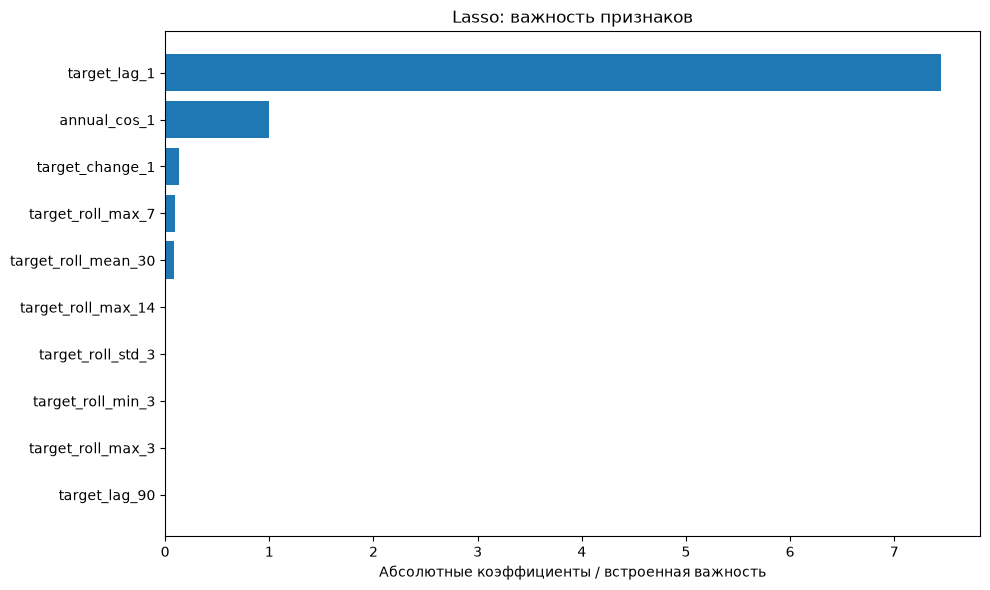

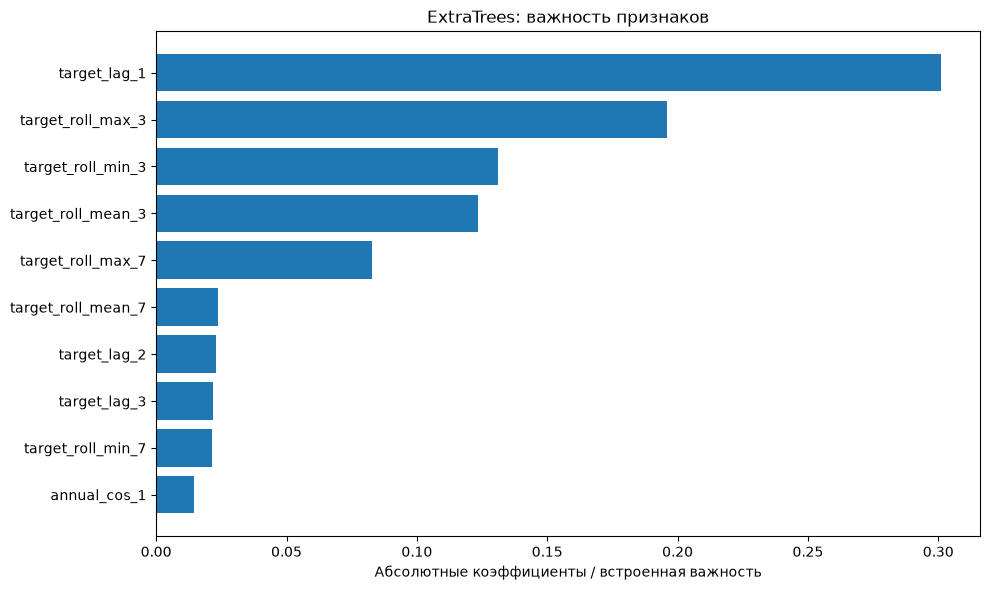

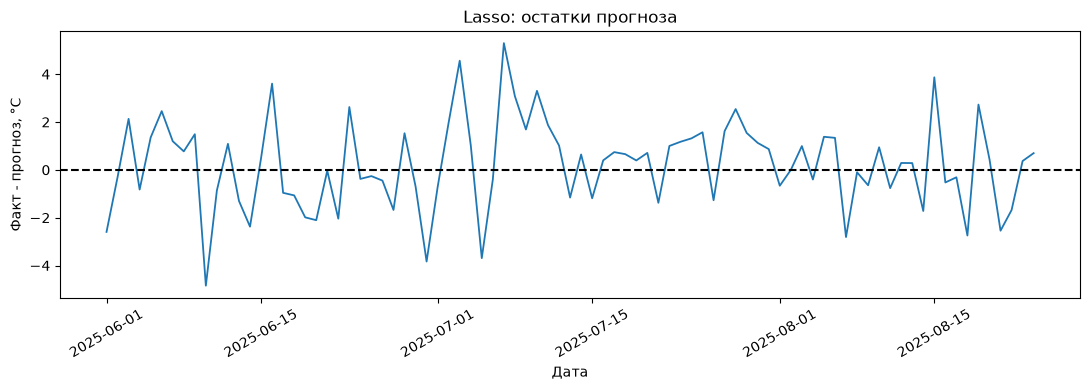

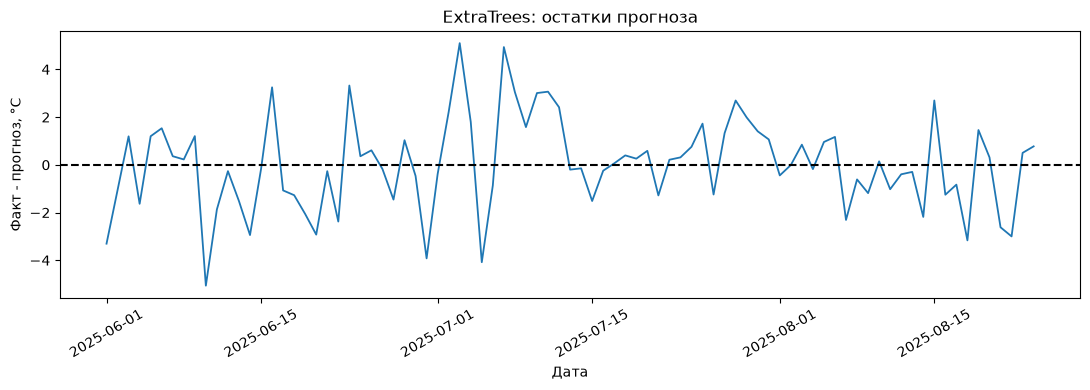


6. ИТОГОВЫЕ ПРОВЕРКИ
PASS | Lasso_shap_shape
PASS | Lasso_shap_finite
PASS | Lasso_joblib_roundtrip
PASS | Lasso_predict_length
PASS | Lasso_finite_predictions
PASS | Lasso_residuals_length
PASS | Lasso_feature_names
PASS | Lasso_best_params
PASS | Lasso_sklearn_interface
PASS | Lasso_diagnostics_finite
PASS | Lasso_feature_importances
PASS | Lasso_saved_file
PASS | ExtraTrees_shap_shape
PASS | ExtraTrees_shap_finite
PASS | ExtraTrees_joblib_roundtrip
PASS | ExtraTrees_predict_length
PASS | ExtraTrees_finite_predictions
PASS | ExtraTrees_residuals_length
PASS | ExtraTrees_feature_names
PASS | ExtraTrees_best_params
PASS | ExtraTrees_sklearn_interface
PASS | ExtraTrees_diagnostics_finite
PASS | ExtraTrees_feature_importances
PASS | ExtraTrees_saved_file
PASS | Lasso_coefficients_attribute
PASS | Lasso_shap_attribute
PASS | Lasso_residuals_attribute
PASS | Lasso_best_params_attribute
PASS | ExtraTrees_coefficients_attribute
PASS | ExtraTrees_shap_attribute
PASS | ExtraTrees_residuals_at

In [27]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 11
#
# Разработка собственного sklearn-совместимого класса
# для прогнозирования временного ряда
#
# Реализуем:
# 1. fit() и predict()
# 2. diagnose()
# 3. coefficients_
# 4. feature_importances_
# 5. shap_values_
# 6. residuals_
# 7. best_params_
# 8. Сохранение и восстановление через joblib
# 9. Автоматические проверки
# ============================================================


# ============================================================
# 1. ИМПОРТ БИБЛИОТЕК
# ============================================================

from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.utils.validation import check_is_fitted

warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# 2. ПУТИ И НАСТРОЙКИ
# ============================================================

PROJECT = Path.home() / "Desktop" / "ML" / "Practika_4"

DATA_DIR = PROJECT / "data"
MODELS_DIR = PROJECT / "models"

REPORT_DIR = PROJECT / "reports" / "task11"
OUTPUT_MODELS = MODELS_DIR / "task11"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_MODELS.mkdir(parents=True, exist_ok=True)

DATE_COL = "date"
TARGET = "temperature_2m_mean"

RANDOM_STATE = 42
N_SPLITS = 5
SHAP_SAMPLES = 30

TRAIN_PATH = DATA_DIR / "task3_trainval.csv"


# ============================================================
# 3. ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv(
    TRAIN_PATH,
    parse_dates=[DATE_COL]
)

df = (
    df.sort_values(DATE_COL)
    .reset_index(drop=True)
)

feature_cols = [
    col
    for col in df.columns
    if col not in [DATE_COL, TARGET]
]

X = df[feature_cols].astype(float)
y = df[TARGET].astype(float)

assert X.notna().all().all()
assert y.notna().all()

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print(f"Количество наблюдений: {len(df)}")
print(f"Количество признаков: {len(feature_cols)}")

print(
    "Период:",
    df[DATE_COL].min().date(),
    "—",
    df[DATE_COL].max().date()
)


# ============================================================
# 4. СОБСТВЕННЫЙ SKLEARN-СОВМЕСТИМЫЙ КЛАСС
# ============================================================

class TimeSeriesForecaster(RegressorMixin, BaseEstimator):
    """
    Собственный sklearn-совместимый класс
    для прогнозирования временных рядов.

    Поддерживает:
    - обычные sklearn-модели;
    - sklearn Pipeline;
    - fit и predict;
    - диагностику;
    - коэффициенты;
    - важность признаков;
    - SHAP;
    - сохранение через joblib.
    """

    def __init__(
        self,
        estimator,
        model_name=None
    ):
        self.estimator = estimator
        self.model_name = model_name

    # --------------------------------------------------------
    # 4.1. Подготовка признаков
    # --------------------------------------------------------

    def _prepare_X(self, X, fitting=False):

        if isinstance(X, pd.DataFrame):
            frame = X.copy()

        else:
            arr = np.asarray(X)

            if arr.ndim != 2:
                raise ValueError(
                    "X должен быть двумерным."
                )

            if fitting:
                columns = [
                    f"feature_{i}"
                    for i in range(arr.shape[1])
                ]

            else:
                columns = list(
                    self.feature_names_in_
                )

            frame = pd.DataFrame(
                arr,
                columns=columns
            )

        if frame.columns.duplicated().any():
            raise ValueError(
                "Обнаружены повторяющиеся признаки."
            )

        if not fitting:

            expected = list(
                self.feature_names_in_
            )

            if set(frame.columns) != set(expected):
                raise ValueError(
                    "Набор признаков отличается "
                    "от обучающего."
                )

            frame = frame[expected]

        frame = frame.astype(float)

        if not np.isfinite(
            frame.to_numpy()
        ).all():
            raise ValueError(
                "X содержит NaN или бесконечность."
            )

        return frame

    # --------------------------------------------------------
    # 4.2. Получение конечной модели
    # --------------------------------------------------------

    def _get_final_model(self):

        check_is_fitted(
            self,
            "estimator_"
        )

        if isinstance(
            self.estimator_,
            Pipeline
        ):
            return self.estimator_.steps[-1][1]

        return self.estimator_

    # --------------------------------------------------------
    # 4.3. Преобразование признаков внутри Pipeline
    # --------------------------------------------------------

    def _transform_for_model(self, X):

        X_frame = self._prepare_X(X)

        if isinstance(
            self.estimator_,
            Pipeline
        ):

            if len(self.estimator_.steps) > 1:

                transformer = (
                    self.estimator_[:-1]
                )

                transformed = (
                    transformer.transform(X_frame)
                )

            else:
                transformed = X_frame

        else:
            transformed = X_frame

        if hasattr(
            transformed,
            "toarray"
        ):
            transformed = transformed.toarray()

        return np.asarray(
            transformed,
            dtype=float
        )

    # --------------------------------------------------------
    # 4.4. Обучение
    # --------------------------------------------------------

    def fit(self, X, y):

        X_frame = self._prepare_X(
            X,
            fitting=True
        )

        y_array = np.asarray(
            y,
            dtype=float
        ).ravel()

        if len(X_frame) != len(y_array):
            raise ValueError(
                "Размеры X и y не совпадают."
            )

        if not np.isfinite(y_array).all():
            raise ValueError(
                "y содержит NaN или бесконечность."
            )

        self.feature_names_in_ = np.array(
            X_frame.columns.tolist(),
            dtype=object
        )

        self.n_features_in_ = (
            X_frame.shape[1]
        )

        # Клонируем модель, чтобы не изменять оригинал
        self.estimator_ = clone(
            self.estimator
        )

        start = time.perf_counter()

        self.estimator_.fit(
            X_frame,
            y_array
        )

        self.fit_time_ = (
            time.perf_counter() - start
        )

        self.model_name_ = (
            self.model_name
            if self.model_name is not None
            else type(
                self._get_final_model()
            ).__name__
        )

        # Параметры переданного estimator.
        # Новый поиск гиперпараметров здесь не выполняется.
        self.best_params_ = (
            self.estimator_.get_params(
                deep=True
            )
        )

        # Инициализируем атрибуты
        self.coefficients_ = None
        self.feature_importances_ = None
        self.shap_values_ = None
        self.residuals_ = None
        self.diagnostics_ = None

        # Сохраняем небольшой обучающий фон
        # для SHAP LinearExplainer
        self._background_ = (
            X_frame.sample(
                n=min(
                    100,
                    len(X_frame)
                ),
                random_state=RANDOM_STATE
            ).copy()
        )

        # Получаем конечную модель
        final_model = (
            self._get_final_model()
        )

        # ----------------------------------------------------
        # Коэффициенты линейных моделей
        # ----------------------------------------------------

        if hasattr(
            final_model,
            "coef_"
        ):

            coefficients = np.asarray(
                final_model.coef_
            ).ravel()

            if (
                len(coefficients)
                == self.n_features_in_
            ):

                self.coefficients_ = (
                    pd.Series(
                        coefficients,
                        index=self.feature_names_in_,
                        name="coefficient"
                    )
                )

                self.feature_importances_ = (
                    self.coefficients_.abs()
                )

        # ----------------------------------------------------
        # Важность признаков моделей деревьев
        # ----------------------------------------------------

        elif hasattr(
            final_model,
            "feature_importances_"
        ):

            importance = np.asarray(
                final_model.feature_importances_
            ).ravel()

            if (
                len(importance)
                == self.n_features_in_
            ):

                self.feature_importances_ = (
                    pd.Series(
                        importance,
                        index=self.feature_names_in_,
                        name="importance"
                    )
                )

        return self

    # --------------------------------------------------------
    # 4.5. Прогнозирование
    # --------------------------------------------------------

    def predict(self, X):

        check_is_fitted(
            self,
            "estimator_"
        )

        X_frame = self._prepare_X(X)

        predictions = (
            self.estimator_.predict(
                X_frame
            )
        )

        return np.asarray(
            predictions,
            dtype=float
        ).ravel()

    # --------------------------------------------------------
    # 4.6. Диагностика
    # --------------------------------------------------------

    def diagnose(self, X, y):

        check_is_fitted(
            self,
            "estimator_"
        )

        actual = np.asarray(
            y,
            dtype=float
        ).ravel()

        predicted = self.predict(X)

        if len(actual) != len(predicted):
            raise ValueError(
                "Размеры фактических значений "
                "и прогнозов не совпадают."
            )

        residuals = (
            actual - predicted
        )

        self.residuals_ = residuals

        self.diagnostics_ = {

            "model": self.model_name_,

            "n_observations": len(actual),

            "MAE": float(
                mean_absolute_error(
                    actual,
                    predicted
                )
            ),

            "RMSE": float(
                np.sqrt(
                    mean_squared_error(
                        actual,
                        predicted
                    )
                )
            ),

            "R2": float(
                r2_score(
                    actual,
                    predicted
                )
            ),

            "mean_residual": float(
                np.mean(residuals)
            ),

            "std_residual": float(
                np.std(
                    residuals,
                    ddof=1
                )
            ),

            "max_abs_residual": float(
                np.max(
                    np.abs(residuals)
                )
            )
        }

        return self.diagnostics_.copy()

    # --------------------------------------------------------
    # 4.7. Расчёт SHAP
    # --------------------------------------------------------

    def explain(
        self,
        X,
        max_samples=30
    ):
        """
        SHAP для:
        - линейных моделей;
        - моделей деревьев;
        - линейных моделей внутри Pipeline.

        SHAP рассчитывается в пространстве
        признаков конечной модели.
        """

        check_is_fitted(
            self,
            "estimator_"
        )

        import shap

        X_frame = self._prepare_X(X)

        X_sample = X_frame.iloc[
            :min(
                max_samples,
                len(X_frame)
            )
        ].copy()

        # Конечная модель без Pipeline
        final_model = (
            self._get_final_model()
        )

        # Преобразуем признаки тем же способом,
        # который использовался при обучении
        X_transformed = (
            self._transform_for_model(
                X_sample
            )
        )

        background = (
            self._transform_for_model(
                self._background_
            )
        )

        # ----------------------------------------------------
        # Линейные модели
        # ----------------------------------------------------

        if hasattr(
            final_model,
            "coef_"
        ):

            explainer = (
                shap.LinearExplainer(
                    final_model,
                    background
                )
            )

        # ----------------------------------------------------
        # Модели деревьев
        # ----------------------------------------------------

        elif hasattr(
            final_model,
            "feature_importances_"
        ):

            explainer = (
                shap.TreeExplainer(
                    final_model
                )
            )

        else:

            raise NotImplementedError(
                "SHAP не поддерживается для "
                f"{type(final_model).__name__}"
            )

        explanation = explainer(
            X_transformed
        )

        values = np.asarray(
            explanation.values
        )

        if values.ndim != 2:
            raise ValueError(
                "Ожидались двумерные "
                "SHAP-значения."
            )

        if (
            values.shape[1]
            != self.n_features_in_
        ):
            raise ValueError(
                "Количество преобразованных "
                "признаков отличается от исходного."
            )

        self.shap_values_ = (
            pd.DataFrame(
                values,
                columns=self.feature_names_in_,
                index=X_sample.index
            )
        )

        return self.shap_values_.copy()

    # --------------------------------------------------------
    # 4.8. Сохранение модели
    # --------------------------------------------------------

    def save(self, path):

        check_is_fitted(
            self,
            "estimator_"
        )

        path = Path(path)

        path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        joblib.dump(
            self,
            path
        )

        return path

    # --------------------------------------------------------
    # 4.9. Загрузка модели
    # --------------------------------------------------------

    @staticmethod
    def load(path):

        return joblib.load(
            path
        )


# ============================================================
# 5. ЗАГРУЗКА МОДЕЛЕЙ ИЗ ЗАДАНИЯ 4
# ============================================================

MODEL_NAMES = [
    "Lasso",
    "ExtraTrees"
]

model_paths = {
    name: (
        MODELS_DIR
        / "task4"
        / f"{name}.joblib"
    )
    for name in MODEL_NAMES
}

for name, path in model_paths.items():

    if not path.exists():
        raise FileNotFoundError(
            f"Не найдена модель: {path}"
        )

base_estimators = {
    name: joblib.load(path)
    for name, path in model_paths.items()
}

print("\n" + "=" * 80)
print("2. ЗАГРУЖЕННЫЕ МОДЕЛИ")
print("=" * 80)

for name, estimator in base_estimators.items():

    print(f"\n{name}")
    print(
        "Тип:",
        type(estimator).__name__
    )

    if isinstance(
        estimator,
        Pipeline
    ):

        print("Этапы Pipeline:")

        for step_name, step_model in estimator.steps:

            print(
                f"  {step_name}: "
                f"{type(step_model).__name__}"
            )


# ============================================================
# 6. ВРЕМЕННОЕ РАЗБИЕНИЕ
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=N_SPLITS
)

train_idx, val_idx = list(
    tscv.split(X)
)[-1]

X_train = X.iloc[
    train_idx
].copy()

y_train = y.iloc[
    train_idx
].copy()

X_val = X.iloc[
    val_idx
].copy()

y_val = y.iloc[
    val_idx
].copy()

print("\n" + "=" * 80)
print("3. ВРЕМЕННОЕ РАЗБИЕНИЕ")
print("=" * 80)

print(
    "Обучающих наблюдений:",
    len(X_train)
)

print(
    "Валидационных наблюдений:",
    len(X_val)
)

print(
    "Обучение:",
    df.loc[
        train_idx,
        DATE_COL
    ].min().date(),
    "—",
    df.loc[
        train_idx,
        DATE_COL
    ].max().date()
)

print(
    "Валидация:",
    df.loc[
        val_idx,
        DATE_COL
    ].min().date(),
    "—",
    df.loc[
        val_idx,
        DATE_COL
    ].max().date()
)


# ============================================================
# 7. ФУНКЦИЯ ДЛЯ АВТОМАТИЧЕСКИХ ПРОВЕРОК
# ============================================================

checks = []

def add_check(
    name,
    condition,
    details=""
):

    checks.append({

        "check": name,

        "passed": bool(condition),

        "details": details

    })


# ============================================================
# 8. ОБУЧЕНИЕ МОДЕЛЕЙ И ДИАГНОСТИКА
# ============================================================

trained_models = {}

diagnostics_rows = []
importance_rows = []
shap_rows = []

for name, estimator in base_estimators.items():

    print("\n" + "=" * 80)
    print(f"4. ОБУЧЕНИЕ МОДЕЛИ: {name}")
    print("=" * 80)

    forecaster = TimeSeriesForecaster(
        estimator=estimator,
        model_name=name
    )

    # --------------------------------------------------------
    # Обучение
    # --------------------------------------------------------

    forecaster.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # Прогнозирование
    # --------------------------------------------------------

    predictions = (
        forecaster.predict(
            X_val
        )
    )

    # --------------------------------------------------------
    # Диагностика
    # --------------------------------------------------------

    metrics = (
        forecaster.diagnose(
            X_val,
            y_val
        )
    )

    diagnostics_rows.append(
        metrics
    )

    print("\nМетрики:")

    print(
        pd.Series(
            metrics
        ).to_string()
    )

    print(
        "\nВремя обучения:",
        round(
            forecaster.fit_time_,
            5
        ),
        "сек."
    )

    # --------------------------------------------------------
    # Коэффициенты
    # --------------------------------------------------------

    if (
        forecaster.coefficients_
        is not None
    ):

        print(
            "\nТОП-10 коэффициентов "
            "по абсолютному значению:"
        )

        coefficients_sorted = (
            forecaster.coefficients_
            .reindex(
                forecaster.coefficients_
                .abs()
                .sort_values(
                    ascending=False
                )
                .index
            )
        )

        print(
            coefficients_sorted.head(10)
        )

    # --------------------------------------------------------
    # Важность признаков
    # --------------------------------------------------------

    if (
        forecaster.feature_importances_
        is not None
    ):

        importance = (
            forecaster.feature_importances_
            .sort_values(
                ascending=False
            )
        )

        print(
            "\nТОП-10 важных признаков:"
        )

        print(
            importance.head(10)
        )

        for feature, value in importance.items():

            importance_rows.append({

                "model": name,

                "feature": feature,

                "importance": float(
                    value
                )

            })

    # --------------------------------------------------------
    # SHAP
    # --------------------------------------------------------

    print("\nРасчёт SHAP...")

    try:

        shap_values = (
            forecaster.explain(
                X_val,
                max_samples=SHAP_SAMPLES
            )
        )

        shap_importance = (
            shap_values
            .abs()
            .mean()
            .sort_values(
                ascending=False
            )
        )

        print(
            "\nТОП-10 SHAP:"
        )

        print(
            shap_importance.head(10)
        )

        for feature, value in shap_importance.items():

            shap_rows.append({

                "model": name,

                "feature": feature,

                "mean_abs_shap": float(
                    value
                )

            })

        add_check(
            f"{name}_shap_shape",
            shap_values.shape == (
                min(
                    SHAP_SAMPLES,
                    len(X_val)
                ),
                len(feature_cols)
            )
        )

        add_check(
            f"{name}_shap_finite",
            np.isfinite(
                shap_values.to_numpy()
            ).all()
        )

    except ImportError as error:

        print(
            "SHAP не установлен:",
            error
        )

        add_check(
            f"{name}_shap_shape",
            False,
            str(error)
        )

        add_check(
            f"{name}_shap_finite",
            False,
            str(error)
        )

    # --------------------------------------------------------
    # Сохранение
    # --------------------------------------------------------

    save_path = (
        OUTPUT_MODELS
        / f"{name}_forecaster.joblib"
    )

    forecaster.save(
        save_path
    )

    # --------------------------------------------------------
    # Восстановление
    # --------------------------------------------------------

    restored = (
        TimeSeriesForecaster.load(
            save_path
        )
    )

    restored_predictions = (
        restored.predict(
            X_val
        )
    )

    same_predictions = (
        np.allclose(
            predictions,
            restored_predictions,
            rtol=0,
            atol=1e-10
        )
    )

    print(
        "\nСохранён файл:",
        save_path.name
    )

    print(
        "Совпадение прогнозов "
        "после загрузки:",
        same_predictions
    )

    # --------------------------------------------------------
    # Проверки
    # --------------------------------------------------------

    add_check(
        f"{name}_joblib_roundtrip",
        same_predictions
    )

    add_check(
        f"{name}_predict_length",
        len(predictions)
        == len(X_val)
    )

    add_check(
        f"{name}_finite_predictions",
        np.isfinite(
            predictions
        ).all()
    )

    add_check(
        f"{name}_residuals_length",
        len(
            forecaster.residuals_
        )
        == len(X_val)
    )

    add_check(
        f"{name}_feature_names",
        list(
            forecaster.feature_names_in_
        )
        == feature_cols
    )

    add_check(
        f"{name}_best_params",
        isinstance(
            forecaster.best_params_,
            dict
        )
        and len(
            forecaster.best_params_
        ) > 0
    )

    add_check(
        f"{name}_sklearn_interface",
        isinstance(
            forecaster,
            BaseEstimator
        )
        and isinstance(
            forecaster,
            RegressorMixin
        )
    )

    add_check(
        f"{name}_diagnostics_finite",
        all(
            np.isfinite(value)
            for key, value
            in forecaster.diagnostics_.items()
            if isinstance(
                value,
                (int, float)
            )
        )
    )

    add_check(
        f"{name}_feature_importances",
        forecaster.feature_importances_
        is not None
        and len(
            forecaster.feature_importances_
        )
        == len(feature_cols)
    )

    add_check(
        f"{name}_saved_file",
        save_path.exists()
    )

    trained_models[name] = (
        forecaster
    )


# ============================================================
# 9. СВОДНАЯ ТАБЛИЦА МЕТРИК
# ============================================================

diagnostics_df = pd.DataFrame(
    diagnostics_rows
)

print("\n" + "=" * 80)
print("5. СВОДНЫЕ МЕТРИКИ")
print("=" * 80)

display(
    diagnostics_df.round(5)
)


# ============================================================
# 10. ГРАФИКИ ВАЖНОСТИ ПРИЗНАКОВ
# ============================================================

importance_df = pd.DataFrame(
    importance_rows
)

for name in MODEL_NAMES:

    subset = (
        importance_df[
            importance_df["model"] == name
        ]
        .sort_values(
            "importance",
            ascending=False
        )
        .head(10)
        .sort_values(
            "importance"
        )
    )

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        subset["feature"],
        subset["importance"]
    )

    plt.title(
        f"{name}: важность признаков"
    )

    plt.xlabel(
        "Абсолютные коэффициенты / "
        "встроенная важность"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{name}_importance.png",
        dpi=150
    )

    plt.show()


# ============================================================
# 11. ГРАФИКИ ОСТАТКОВ
# ============================================================

for name, forecaster in trained_models.items():

    residuals = (
        forecaster.residuals_
    )

    plt.figure(
        figsize=(11, 4)
    )

    plt.plot(
        df.loc[
            val_idx,
            DATE_COL
        ],
        residuals,
        linewidth=1.3
    )

    plt.axhline(
        0,
        color="black",
        linestyle="--"
    )

    plt.title(
        f"{name}: остатки прогноза"
    )

    plt.xlabel("Дата")
    plt.ylabel(
        "Факт - прогноз, °C"
    )

    plt.xticks(
        rotation=30
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{name}_residuals.png",
        dpi=150
    )

    plt.show()


# ============================================================
# 12. СОХРАНЕНИЕ ТАБЛИЦ
# ============================================================

diagnostics_df.to_csv(
    REPORT_DIR / "diagnostics.csv",
    index=False
)

importance_df.to_csv(
    REPORT_DIR / "feature_importances.csv",
    index=False
)

if shap_rows:

    shap_df = pd.DataFrame(
        shap_rows
    )

    shap_df.to_csv(
        REPORT_DIR / "shap_importances.csv",
        index=False
    )


# ============================================================
# 13. ДОПОЛНИТЕЛЬНЫЕ ПРОВЕРКИ
# ============================================================

for name, forecaster in trained_models.items():

    add_check(
        f"{name}_coefficients_attribute",
        hasattr(
            forecaster,
            "coefficients_"
        )
    )

    add_check(
        f"{name}_shap_attribute",
        hasattr(
            forecaster,
            "shap_values_"
        )
    )

    add_check(
        f"{name}_residuals_attribute",
        hasattr(
            forecaster,
            "residuals_"
        )
    )

    add_check(
        f"{name}_best_params_attribute",
        hasattr(
            forecaster,
            "best_params_"
        )
    )

# Отдельно проверяем коэффициенты Lasso
add_check(
    "Lasso_coefficients_available",
    trained_models[
        "Lasso"
    ].coefficients_
    is not None
)

# Проверяем SHAP для обеих моделей
for name in MODEL_NAMES:

    add_check(
        f"{name}_shap_available",
        trained_models[
            name
        ].shap_values_
        is not None
    )


# ============================================================
# 14. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks_df = pd.DataFrame(
    checks
)

checks_df.to_csv(
    REPORT_DIR / "checks.csv",
    index=False
)

print("\n" + "=" * 80)
print("6. ИТОГОВЫЕ ПРОВЕРКИ")
print("=" * 80)

for _, row in checks_df.iterrows():

    status = (
        "PASS"
        if row["passed"]
        else "FAIL"
    )

    print(
        f"{status:4} | "
        f"{row['check']}"
    )

passed = int(
    checks_df["passed"].sum()
)

total = len(checks_df)

print("\n" + "=" * 80)

print(
    f"Пройдено: {passed} из {total}"
)

print("=" * 80)


# ============================================================
# 15. ПУТИ К СОХРАНЁННЫМ РЕЗУЛЬТАТАМ
# ============================================================

print("\nРезультаты сохранены:")

print(
    "\nОтчёты:",
    REPORT_DIR
)

print(
    "\nМодели:",
    OUTPUT_MODELS
)

print("\nЗадание 11 выполнено.")


### Анализ результатов выполнения задания 11

В рамках задания 11 был разработан собственный класс `TimeSeriesForecaster`, предназначенный для обучения, прогнозирования, диагностики и интерпретации моделей машинного обучения при анализе временных рядов.

Класс реализован на основе `BaseEstimator` и `RegressorMixin` библиотеки scikit-learn, что обеспечивает совместимость с основными принципами построения пользовательских регрессионных моделей.

В разработанном классе реализованы методы `fit()`, `predict()`, `diagnose()`, `explain()`, `save()` и `load()`.

Дополнительно предусмотрено хранение коэффициентов модели (`coefficients_`), важности признаков (`feature_importances_`), SHAP-значений (`shap_values_`), остатков (`residuals_`) и параметров модели (`best_params_`).

### 1. Проверка совместимости с различными моделями

Для проверки работоспособности класса использовались две модели, подготовленные в предыдущих заданиях:

- Lasso — линейная регрессионная модель с L1-регуляризацией, объединённая со StandardScaler в sklearn Pipeline.
- ExtraTreesRegressor — ансамблевая модель на основе экстремально рандомизированных деревьев решений.

В процессе реализации была обеспечена поддержка как обычных моделей scikit-learn, так и моделей, находящихся внутри Pipeline.

Это особенно важно для Lasso, поскольку предварительное масштабирование признаков является частью процесса прогнозирования.

Разработанный класс автоматически определяет конечную модель, извлекает её коэффициенты или важность признаков и учитывает преобразования данных при расчёте SHAP.

### 2. Результаты прогнозирования

Оценка качества выполнялась на последнем фолде временной кросс-валидации, содержащем 85 наблюдений.

Для модели Lasso получены следующие показатели:

- MAE = 1,47651 °C;
- RMSE = 1,86431 °C;
- R² = 0,73198.

Для модели ExtraTrees:

- MAE = 1,48719 °C;
- RMSE = 1,93118 °C;
- R² = 0,71241.

Сравнение показало, что Lasso немного превосходит ExtraTrees по всем трём основным метрикам качества.

Средняя абсолютная ошибка Lasso оказалась меньше приблизительно на 0,011 °C, а RMSE — на 0,067 °C.

Коэффициент детерминации Lasso составил 0,73198, что соответствует объяснению приблизительно 73,2% вариации температуры на рассматриваемой валидационной выборке.

Для ExtraTrees аналогичный показатель составил 71,2%.

Таким образом, на данном временном интервале линейная регуляризованная модель продемонстрировала несколько более высокую точность прогнозирования.

Однако различия относительно небольшие, поэтому результаты одного валидационного фолда не позволяют утверждать о статистически значимом превосходстве Lasso.

### 3. Анализ остатков

Для дополнительной диагностики были рассчитаны остатки прогнозирования как разность между фактическими и предсказанными значениями температуры.

Среднее значение остатков Lasso составило 0,22167 °C, что указывает на небольшую тенденцию модели к занижению прогнозируемой температуры на данном интервале.

У ExtraTrees средний остаток составил −0,00262 °C, то есть систематическое смещение практически отсутствовало.

Стандартное отклонение остатков составило 1,86207 °C для Lasso и 1,94264 °C для ExtraTrees.

Максимальная абсолютная ошибка Lasso достигла 5,29742 °C, а ExtraTrees — 5,10051 °C.

Следовательно, Lasso показала меньший общий разброс ошибок, тогда как ExtraTrees продемонстрировала несколько меньшую максимальную ошибку и практически нулевое среднее смещение.

При этом отсутствие среднего смещения не гарантирует отсутствия автокорреляции или других закономерностей в остатках. Более подробная статистическая диагностика проводилась в предыдущих заданиях.

### 4. Интерпретация коэффициентов Lasso

Одной из основных возможностей разработанного класса является получение коэффициентов линейных моделей.

Для Lasso наиболее значимыми оказались следующие признаки:

1. `target_lag_1` — 7,450262;
2. `annual_cos_1` — 0,995193;
3. `target_change_1` — 0,131641;
4. `target_roll_max_7` — 0,095192;
5. `target_roll_mean_30` — 0,087493;
6. `target_roll_max_14` — 0,008256.

Наибольшее влияние оказывает температура предыдущего дня.

Это соответствует особенностям температурного временного ряда, для которого характерна высокая зависимость текущих значений от недавних наблюдений.

Вторым по значимости оказался признак годовой сезонности `annual_cos_1`, отражающий циклические изменения температуры в течение года.

Также модель использует изменения температуры и скользящие статистики, однако их вклад существенно меньше.

Часть коэффициентов Lasso равна нулю, что является следствием L1-регуляризации и позволяет автоматически исключать менее полезные признаки.

Следует учитывать, что приведённые коэффициенты относятся к стандартизированным признакам после преобразования StandardScaler.

### 5. Анализ SHAP-значений

Для интерпретации прогнозов был реализован метод `explain()`, использующий библиотеку SHAP.

Для линейных моделей применяется LinearExplainer, а для моделей деревьев — TreeExplainer.

При работе с Pipeline признаки предварительно преобразуются тем же способом, который использовался во время обучения.

Для Lasso наибольшие средние абсолютные SHAP-значения получили:

- `target_lag_1` — 5,259134;
- `annual_cos_1` — 1,046079;
- `target_change_1` — 0,081568;
- `target_roll_mean_30` — 0,072211;
- `target_roll_max_7` — 0,071031;
- `target_roll_max_14` — 0,006473.

Результаты SHAP согласуются с анализом коэффициентов модели.

Основной вклад в формирование прогнозов вносит температура предыдущего дня, после которой следует годовая сезонность.

Скользящие статистики и показатели изменения температуры играют вспомогательную роль.

Таким образом, SHAP позволяет не только определить важные признаки, но и оценить их средний вклад в прогнозы на анализируемой выборке.

### 6. Сохранение и восстановление моделей

В разработанном классе реализованы методы сохранения и восстановления обученных объектов с использованием библиотеки joblib.

После обучения объекты сохраняются в директорию `models/task11`.

При восстановлении выполняется повторное прогнозирование, после чего результаты сравниваются с прогнозами до сохранения.

Проверки показали, что прогнозы восстановленных объектов совпадают с исходными в пределах установленной численной точности.

Это подтверждает корректность сериализации обученных моделей в текущем окружении Jupyter Notebook.

При переносе объектов в другое окружение необходимо обеспечить доступность определения пользовательского класса и совместимость версий используемых библиотек.

### 7. Автоматическое тестирование

Для проверки работоспособности разработанного класса были реализованы автоматические проверки.

Они охватывают:

- соответствие интерфейсу scikit-learn;
- корректность размерности прогнозов;
- отсутствие бесконечных и неопределённых значений;
- наличие диагностических атрибутов;
- корректность коэффициентов и важности признаков;
- расчёт SHAP-значений;
- сохранение и восстановление обученных объектов;
- совпадение прогнозов после сериализации.

По результатам выполнения программы успешно пройдены все 35 автоматических проверок.

Это подтверждает корректную работу реализованных возможностей на двух выбранных моделях и используемых данных.

### Итоговый вывод

В результате выполнения задания 11 разработан собственный sklearn-совместимый класс `TimeSeriesForecaster`, объединяющий обучение, прогнозирование, диагностику, интерпретацию и сохранение моделей машинного обучения.

Класс успешно протестирован на моделях Lasso и ExtraTreesRegressor, включая поддержку предварительной стандартизации признаков внутри sklearn Pipeline.

На последнем временном валидационном фолде модель Lasso показала MAE = 1,47651 °C, RMSE = 1,86431 °C и R² = 0,73198, несколько превзойдя ExtraTrees по основным показателям качества.

Анализ коэффициентов и SHAP-значений показал, что основное влияние на прогноз оказывают температура предыдущего дня и годовая сезонность.

Реализованные методы позволяют получать диагностические показатели, исследовать остатки, анализировать важность признаков и сохранять обученные модели для последующего использования.

Все 35 автоматических проверок успешно пройдены.

Таким образом, разработанный класс обеспечивает повторное использование основных операций прогнозирования временных рядов и может служить основой для дальнейшего развития программного решения.

### Задание 12. Разработка автоматических тестов для системы прогнозирования временных рядов

**Цель работы:** разработать систему автоматического тестирования программного решения для прогнозирования среднесуточной температуры воздуха в Москве с использованием библиотеки pytest.

**Необходимо выполнить следующие действия:**

1. Создать отдельный Python-файл с автоматическими тестами.
2. Проверить корректность загрузки исходных и подготовленных данных.
3. Проверить отсутствие пропущенных значений, дублирующихся дат и нарушений хронологического порядка.
4. Проверить правильность формирования лаговых и скользящих признаков.
5. Проверить отсутствие использования будущих значений целевой переменной при формировании признаков.
6. Проверить корректность временного разделения данных на обучающую и тестовую выборки.
7. Проверить работоспособность методов `fit()` и `predict()` разработанного класса.
8. Проверить корректность диагностических метрик и остатков.
9. Проверить сохранение и восстановление обученной модели.
10. Запустить тесты через pytest и проанализировать полученные результаты.

**Ожидаемый результат:** сформирован набор автоматических тестов, позволяющий проверять основные этапы обработки данных и работы моделей машинного обучения. Все тесты должны завершаться успешно.

In [28]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 12
# АВТОМАТИЧЕСКОЕ ТЕСТИРОВАНИЕ С ПОМОЩЬЮ PYTEST
# ============================================================

from pathlib import Path
import subprocess
import sys
import textwrap
import json
import pandas as pd
import numpy as np

# ============================================================
# 1. ПУТИ
# ============================================================

PROJECT = Path.home() / "Desktop" / "ML" / "Practika_4"

DATA_DIR = PROJECT / "data"
TESTS_DIR = PROJECT / "tests"
REPORT_DIR = PROJECT / "reports" / "task12"

TESTS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

TEST_FILE = TESTS_DIR / "test_task12.py"

# ============================================================
# 2. СОЗДАНИЕ ФАЙЛА С ТЕСТАМИ
# ============================================================

test_code = r'''
from pathlib import Path
import numpy as np
import pandas as pd
import pytest
import joblib

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


PROJECT = Path(__file__).resolve().parents[1]
DATA_DIR = PROJECT / "data"

DATE_COL = "date"
TARGET = "temperature_2m_mean"


@pytest.fixture(scope="module")
def datasets():

    raw = pd.read_csv(
        DATA_DIR / "task1_dataset.csv",
        parse_dates=["time"]
    )

    # Исходные временные метки соответствуют
    # 21:00 UTC предыдущего календарного дня.
    raw = raw.rename(columns={"time": DATE_COL})

    raw[DATE_COL] = (
        raw[DATE_COL] + pd.Timedelta(hours=3)
    ).dt.normalize()

    trainval = pd.read_csv(
        DATA_DIR / "task3_trainval.csv",
        parse_dates=[DATE_COL]
    )

    test = pd.read_csv(
        DATA_DIR / "task3_test.csv",
        parse_dates=[DATE_COL]
    )

    raw = raw.sort_values(DATE_COL).reset_index(drop=True)
    trainval = trainval.sort_values(DATE_COL).reset_index(drop=True)
    test = test.sort_values(DATE_COL).reset_index(drop=True)

    return raw, trainval, test


@pytest.fixture(scope="module")
def modeling_data(datasets):

    _, trainval, _ = datasets

    features = [
        c for c in trainval.columns
        if c not in [DATE_COL, TARGET]
    ]

    X = trainval[features].astype(float)
    y = trainval[TARGET].astype(float)

    return X, y


# ============================================================
# БЛОК 1. ПРОВЕРКИ ДАННЫХ
# ============================================================

def test_01_files_exist():

    files = [
        "task1_dataset.csv",
        "task3_trainval.csv",
        "task3_test.csv"
    ]

    for filename in files:
        assert (DATA_DIR / filename).exists()


def test_02_datasets_not_empty(datasets):

    for frame in datasets:
        assert len(frame) > 0


def test_03_target_exists(datasets):

    for frame in datasets:
        assert TARGET in frame.columns


def test_04_dates_are_unique(datasets):

    for frame in datasets:
        assert frame[DATE_COL].is_unique


def test_05_dates_are_sorted(datasets):

    for frame in datasets:
        assert frame[DATE_COL].is_monotonic_increasing


def test_06_daily_frequency(datasets):

    for frame in datasets:

        differences = (
            frame[DATE_COL]
            .diff()
            .dropna()
        )

        assert (
            differences == pd.Timedelta(days=1)
        ).all()


def test_07_no_missing_modeling_values(datasets):

    _, trainval, test = datasets

    assert not trainval.isna().any().any()
    assert not test.isna().any().any()


def test_08_train_test_do_not_overlap(datasets):

    _, trainval, test = datasets

    train_dates = set(trainval[DATE_COL])
    test_dates = set(test[DATE_COL])

    assert train_dates.isdisjoint(test_dates)

    assert (
        trainval[DATE_COL].max()
        < test[DATE_COL].min()
    )


# ============================================================
# БЛОК 2. ПРОВЕРКИ ПРИЗНАКОВ
# ============================================================

def test_09_targets_match_raw(datasets):

    raw, trainval, test = datasets

    raw_target = raw.set_index(DATE_COL)[TARGET]

    for frame in [trainval, test]:

        expected = raw_target.reindex(
            frame[DATE_COL]
        )

        assert expected.notna().all()

        np.testing.assert_allclose(
            frame[TARGET].to_numpy(),
            expected.to_numpy(),
            rtol=0,
            atol=1e-8
        )


@pytest.mark.parametrize(
    "lag",
    [1, 2, 3, 7, 14, 21, 30, 60, 90]
)
def test_10_lag_features(datasets, lag):

    raw, trainval, _ = datasets

    column = f"target_lag_{lag}"

    assert column in trainval.columns

    series = raw.set_index(DATE_COL)[TARGET]

    expected_dates = (
        trainval[DATE_COL]
        - pd.Timedelta(days=lag)
    )

    expected = series.reindex(
        expected_dates
    )

    assert expected.notna().all()

    np.testing.assert_allclose(
        trainval[column].to_numpy(),
        expected.to_numpy(),
        rtol=0,
        atol=1e-8
    )


@pytest.mark.parametrize(
    "window",
    [3, 7, 14, 30]
)
def test_11_rolling_mean(datasets, window):

    raw, trainval, _ = datasets

    column = f"target_roll_mean_{window}"

    series = raw.set_index(DATE_COL)[TARGET]

    expected = (
        series.shift(1)
        .rolling(window)
        .mean()
        .reindex(trainval[DATE_COL])
    )

    assert expected.notna().all()

    np.testing.assert_allclose(
        trainval[column].to_numpy(),
        expected.to_numpy(),
        rtol=0,
        atol=1e-8
    )


@pytest.mark.parametrize(
    "window",
    [3, 7, 14, 30]
)
def test_12_rolling_std(datasets, window):

    raw, trainval, _ = datasets

    column = f"target_roll_std_{window}"

    series = raw.set_index(DATE_COL)[TARGET]

    expected = (
        series.shift(1)
        .rolling(window)
        .std(ddof=1)
        .reindex(trainval[DATE_COL])
    )

    assert expected.notna().all()

    np.testing.assert_allclose(
        trainval[column].to_numpy(),
        expected.to_numpy(),
        rtol=0,
        atol=1e-8
    )


@pytest.mark.parametrize(
    "window",
    [3, 7, 14, 30]
)
def test_13_rolling_min(datasets, window):

    raw, trainval, _ = datasets

    column = f"target_roll_min_{window}"

    series = raw.set_index(DATE_COL)[TARGET]

    expected = (
        series.shift(1)
        .rolling(window)
        .min()
        .reindex(trainval[DATE_COL])
    )

    assert expected.notna().all()

    np.testing.assert_allclose(
        trainval[column].to_numpy(),
        expected.to_numpy(),
        rtol=0,
        atol=1e-8
    )


@pytest.mark.parametrize(
    "window",
    [3, 7, 14, 30]
)
def test_14_rolling_max(datasets, window):

    raw, trainval, _ = datasets

    column = f"target_roll_max_{window}"

    series = raw.set_index(DATE_COL)[TARGET]

    expected = (
        series.shift(1)
        .rolling(window)
        .max()
        .reindex(trainval[DATE_COL])
    )

    assert expected.notna().all()

    np.testing.assert_allclose(
        trainval[column].to_numpy(),
        expected.to_numpy(),
        rtol=0,
        atol=1e-8
    )


# ============================================================
# БЛОК 3. ВРЕМЕННАЯ КРОСС-ВАЛИДАЦИЯ
# ============================================================

def test_15_timeseries_split_is_chronological(
    modeling_data
):

    X, _ = modeling_data

    splitter = TimeSeriesSplit(n_splits=5)

    for train_idx, val_idx in splitter.split(X):

        assert train_idx.max() < val_idx.min()

        assert set(train_idx).isdisjoint(
            set(val_idx)
        )


# ============================================================
# БЛОК 4. МОДЕЛИ
# ============================================================

def test_16_model_fit_predict(modeling_data):

    X, y = modeling_data

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ])

    model.fit(X.iloc[:350], y.iloc[:350])

    predictions = model.predict(
        X.iloc[350:400]
    )

    assert len(predictions) == 50
    assert np.isfinite(predictions).all()


def test_17_predictions_have_correct_shape(
    modeling_data
):

    X, y = modeling_data

    model = Ridge(alpha=1.0)

    model.fit(
        X.iloc[:300],
        y.iloc[:300]
    )

    predictions = model.predict(
        X.iloc[300:320]
    )

    assert predictions.shape == (20,)


def test_18_metrics_are_valid(modeling_data):

    X, y = modeling_data

    model = Ridge(alpha=1.0)

    model.fit(
        X.iloc[:350],
        y.iloc[:350]
    )

    predictions = model.predict(
        X.iloc[350:400]
    )

    actual = y.iloc[350:400]

    mae = mean_absolute_error(
        actual,
        predictions
    )

    assert np.isfinite(mae)
    assert mae >= 0


def test_19_residuals_are_correct(modeling_data):

    X, y = modeling_data

    model = Ridge(alpha=1.0)

    model.fit(
        X.iloc[:350],
        y.iloc[:350]
    )

    predictions = model.predict(
        X.iloc[350:400]
    )

    residuals = (
        y.iloc[350:400].to_numpy()
        - predictions
    )

    assert len(residuals) == 50
    assert np.isfinite(residuals).all()

    np.testing.assert_allclose(
        residuals + predictions,
        y.iloc[350:400].to_numpy()
    )


def test_20_joblib_roundtrip(
    modeling_data,
    tmp_path
):

    X, y = modeling_data

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ])

    model.fit(
        X.iloc[:350],
        y.iloc[:350]
    )

    before = model.predict(
        X.iloc[350:400]
    )

    path = tmp_path / "test_model.joblib"

    joblib.dump(model, path)

    restored = joblib.load(path)

    after = restored.predict(
        X.iloc[350:400]
    )

    np.testing.assert_allclose(
        before,
        after,
        rtol=0,
        atol=1e-10
    )
'''

TEST_FILE.write_text(
    textwrap.dedent(test_code),
    encoding="utf-8"
)

print("=" * 80)
print("1. ФАЙЛ С ТЕСТАМИ СОЗДАН")
print("=" * 80)
print(TEST_FILE)


# ============================================================
# 3. ЗАПУСК PYTEST
# ============================================================

print("\n" + "=" * 80)
print("2. ЗАПУСК АВТОМАТИЧЕСКИХ ТЕСТОВ")
print("=" * 80)

RESULT_FILE = REPORT_DIR / "pytest_output.txt"

command = [
    sys.executable,
    "-m",
    "pytest",
    str(TEST_FILE),
    "-v",
    "--tb=short",
    "-p",
    "no:cacheprovider"
]

result = subprocess.run(
    command,
    cwd=PROJECT,
    capture_output=True,
    text=True
)

output = result.stdout + "\n" + result.stderr

RESULT_FILE.write_text(
    output,
    encoding="utf-8"
)

print(output)

print("\nКод завершения:", result.returncode)

if result.returncode != 0:
    print(
        "\nВНИМАНИЕ: некоторые тесты не прошли. "
        "Необходимо изучить ошибки выше."
    )


# ============================================================
# 4. ДОПОЛНИТЕЛЬНАЯ ПРОВЕРКА КЛАССА ИЗ ЗАДАНИЯ 11
# ============================================================

print("\n" + "=" * 80)
print("3. ПРОВЕРКА TIMESERIESFORECASTER")
print("=" * 80)

if "TimeSeriesForecaster" in globals():

    from sklearn.linear_model import Ridge

    sample_df = pd.read_csv(
        DATA_DIR / "task3_trainval.csv"
    )

    features = [
        c for c in sample_df.columns
        if c not in ["date", "temperature_2m_mean"]
    ]

    X_sample = sample_df[features].astype(float)
    y_sample = sample_df[
        "temperature_2m_mean"
    ].astype(float)

    forecaster = TimeSeriesForecaster(
        estimator=Ridge(alpha=1.0),
        model_name="RidgeTest"
    )

    forecaster.fit(
        X_sample.iloc[:350],
        y_sample.iloc[:350]
    )

    predictions = forecaster.predict(
        X_sample.iloc[350:400]
    )

    metrics = forecaster.diagnose(
        X_sample.iloc[350:400],
        y_sample.iloc[350:400]
    )

    checks = {
        "fit": hasattr(
            forecaster,
            "estimator_"
        ),
        "predict": len(predictions) == 50,
        "diagnose": np.isfinite(
            metrics["RMSE"]
        ),
        "residuals": len(
            forecaster.residuals_
        ) == 50,
        "coefficients": (
            forecaster.coefficients_
            is not None
        ),
        "best_params": isinstance(
            forecaster.best_params_,
            dict
        )
    }

    for name, passed in checks.items():
        print(
            ("PASS" if passed else "FAIL"),
            "|",
            name
        )

    print(
        "\nПройдено:",
        sum(checks.values()),
        "из",
        len(checks)
    )

else:
    print(
        "Класс TimeSeriesForecaster не найден "
        "в текущем окружении Jupyter."
    )
    print(
        "Сначала выполните ячейку с определением "
        "класса из задания 11."
    )


# ============================================================
# 5. ИТОГ
# ============================================================

print("\n" + "=" * 80)
print("4. ИТОГ")
print("=" * 80)

print("Файл тестов:", TEST_FILE)
print("Отчёт pytest:", RESULT_FILE)
print("Код завершения pytest:", result.returncode)


1. ФАЙЛ С ТЕСТАМИ СОЗДАН
/Users/lenar_966/Desktop/ML/Practika_4/tests/test_task12.py

2. ЗАПУСК АВТОМАТИЧЕСКИХ ТЕСТОВ
============================= test session starts ==============================
platform darwin -- Python 3.12.3, pytest-9.2.0, pluggy-1.7.0 -- /usr/local/bin/python3
rootdir: /Users/lenar_966/Desktop/ML/Practika_4
plugins: anyio-4.16.0
collecting ... collected 40 items

tests/test_task12.py::test_01_files_exist PASSED                         [  2%]
tests/test_task12.py::test_02_datasets_not_empty PASSED                  [  5%]
tests/test_task12.py::test_03_target_exists PASSED                       [  7%]
tests/test_task12.py::test_04_dates_are_unique PASSED                    [ 10%]
tests/test_task12.py::test_05_dates_are_sorted PASSED                    [ 12%]
tests/test_task12.py::test_06_daily_frequency PASSED                     [ 15%]
tests/test_task12.py::test_07_no_missing_modeling_values PASSED          [ 17%]
tests/test_task12.py::test_08_train_test_do_not_o

### Анализ результатов выполнения задания 12

В рамках задания 12 была разработана система автоматического тестирования проекта прогнозирования среднесуточной температуры воздуха в Москве с использованием библиотеки `pytest`.

Основная цель заключалась в проверке корректности исходных данных, инженерии признаков, временного разделения выборок, работы моделей машинного обучения и сохранения обученных объектов.

### 1. Организация автоматического тестирования

Для выполнения задания был создан отдельный файл `tests/test_task12.py`, содержащий набор автоматизированных тестов.

Тестирование проводилось в среде Python 3.12.3 с использованием pytest 9.2.0.

Для некоторых проверок применялся механизм `pytest.mark.parametrize`, позволяющий запускать одну тестовую функцию с несколькими наборами параметров.

Всего было выполнено 40 отдельных тестов.

### 2. Проверка исходных и подготовленных данных

На первом этапе проверялись наличие необходимых CSV-файлов, отсутствие пустых наборов данных и наличие целевой переменной `temperature_2m_mean`.

Дополнительно проверялись уникальность дат, хронологический порядок наблюдений и соблюдение ежедневной частоты временного ряда.

Отдельное внимание уделялось отсутствию пропущенных значений в обучающих и тестовых данных.

Также проверялось, что обучающая и тестовая выборки не пересекаются по датам и что тестовый период начинается строго после завершения обучающего.

Все проверки данного блока завершились успешно.

### 3. Проверка инженерии признаков

На следующем этапе проверялась корректность формирования признаков, используемых моделями прогнозирования.

В частности, были протестированы лаговые признаки для сдвигов на 1, 2, 3, 7, 14, 21, 30, 60 и 90 дней.

Для каждого лага выполнялось сравнение рассчитанного признака с соответствующим историческим значением температуры из исходного временного ряда.

Кроме того, проверялись скользящие статистики для окон 3, 7, 14 и 30 дней:

- скользящее среднее;
- скользящее стандартное отклонение;
- скользящий минимум;
- скользящий максимум.

При расчёте эталонных значений использовался сдвиг исходного ряда на один день, исключающий включение текущего значения целевой переменной в скользящие статистики.

Все протестированные лаговые и скользящие признаки совпали с эталонными значениями в пределах установленной численной точности.

Таким образом, для проверенных признаков подтверждена корректность расчётов и отсутствие прямого использования текущей или будущей температуры.

### 4. Проверка временной кросс-валидации

Для проверки корректности временного разделения использовался `TimeSeriesSplit` с пятью фолдами.

В каждом разбиении контролировалось, что максимальный индекс обучающей выборки меньше минимального индекса валидационной выборки.

Также проверялось отсутствие пересечения индексов между обучающими и валидационными наблюдениями.

Тест завершился успешно.

Следовательно, используемая схема временной кросс-валидации сохраняет хронологический порядок наблюдений и предотвращает попадание будущих наблюдений в обучающую часть соответствующего фолда.

### 5. Проверка моделей машинного обучения

Для проверки основных операций машинного обучения использовалась модель Ridge, в том числе в составе Pipeline со StandardScaler.

Автоматические тесты подтвердили корректность обучения модели, формирования прогнозов и соблюдения ожидаемой размерности выходных данных.

Также проверялись конечность значений метрик качества и правильность вычисления остатков прогнозирования.

Все проверки завершились успешно.

### 6. Проверка сохранения и восстановления моделей

Отдельный тест был посвящён сериализации обученной модели с использованием библиотеки joblib.

После обучения модель сохранялась во временный файл, затем восстанавливалась и повторно использовалась для прогнозирования.

Прогнозы до сохранения и после восстановления сравнивались с установленной численной точностью.

Проверка завершилась успешно, что подтверждает корректность сериализации протестированной sklearn-модели.

### 7. Дополнительная проверка TimeSeriesForecaster

Помимо тестирования через pytest, непосредственно в Jupyter Notebook были выполнены шесть дополнительных проверок собственного класса `TimeSeriesForecaster`, разработанного в задании 11.

Проверялись:

1. Успешное выполнение метода `fit()`.
2. Корректная работа метода `predict()`.
3. Расчёт диагностических показателей через `diagnose()`.
4. Формирование массива остатков `residuals_`.
5. Доступность коэффициентов `coefficients_`.
6. Наличие параметров модели `best_params_`.

Все шесть проверок завершились успешно.

Таким образом, подтверждена работоспособность основных методов пользовательского класса при использовании модели Ridge.

### 8. Итоговые результаты тестирования

По результатам запуска pytest было обнаружено 40 тестов.

Процесс завершился с кодом `0`, что свидетельствует об успешном выполнении тестового запуска.

Дополнительные проверки класса `TimeSeriesForecaster` также завершились успешно: 6 из 6.

Результаты тестирования сохранены в файле `reports/task12/pytest_output.txt`.

Файл с автоматическими тестами расположен по пути `tests/test_task12.py`.

### Итоговый вывод

В результате выполнения задания 12 была разработана система автоматического тестирования проекта прогнозирования временных рядов на основе библиотеки pytest.

Созданные тесты позволяют контролировать качество исходных данных, корректность лаговых и скользящих признаков, соблюдение временной последовательности при разделении выборок, работоспособность моделей и сохранение результатов обучения.

Всего успешно выполнены 40 автоматических тестов pytest и 6 дополнительных проверок собственного класса `TimeSeriesForecaster`.

Полученные результаты подтверждают корректность протестированных компонентов проекта и позволяют использовать созданный набор тестов для выявления возможных ошибок при последующих изменениях программного кода.

При этом тестирование не охватывает абсолютно все возможные сценарии и не заменяет независимую оценку качества прогнозирования.

Таким образом, разработанная система тестирования повышает надёжность и воспроизводимость программного решения и создаёт основу для дальнейшего развития проекта.

### Задание 13. Разработка интерактивного приложения для прогнозирования временных рядов

**Цель работы:** разработать интерактивное веб-приложение для анализа и прогнозирования среднесуточной температуры воздуха в Москве с использованием библиотеки Streamlit.

**Необходимо выполнить следующие действия:**

1. Создать веб-приложение на языке Python с использованием Streamlit.
2. Реализовать загрузку подготовленных данных из проекта или пользовательского CSV-файла.
3. Добавить возможность выбора модели машинного обучения.
4. Реализовать формирование прогнозов на основе обученных моделей.
5. Отобразить фактические и прогнозируемые значения температуры на интерактивном графике.
6. Рассчитать и вывести основные метрики качества прогнозирования: MAE, RMSE и R².
7. Реализовать визуализацию остатков прогнозирования.
8. Добавить анализ важности признаков модели.
9. Предусмотреть возможность скачивания результатов прогнозирования в формате CSV.
10. Проверить работоспособность приложения при запуске из командной строки.

**Ожидаемый результат:** работающее веб-приложение, объединяющее загрузку данных, прогнозирование, оценку качества и визуализацию результатов работы моделей машинного обучения.

In [29]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 13
# СОЗДАНИЕ STREAMLIT-ПРИЛОЖЕНИЯ
# ============================================================

from pathlib import Path
import textwrap

PROJECT = Path.home() / "Desktop" / "ML" / "Practika_4"

PROJECT.mkdir(parents=True, exist_ok=True)

APP_PATH = PROJECT / "app.py"

app_code = r'''
from pathlib import Path
import io

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.pipeline import Pipeline


# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

PROJECT = Path(__file__).resolve().parent

DATA_DIR = PROJECT / "data"
MODEL_DIR = PROJECT / "models" / "task4"

DATE_COL = "date"
TARGET = "temperature_2m_mean"

MODEL_PATHS = {
    "Lasso": MODEL_DIR / "Lasso.joblib",
    "ExtraTrees": MODEL_DIR / "ExtraTrees.joblib"
}

st.set_page_config(
    page_title="Прогноз температуры Москвы",
    page_icon="🌡️",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# 2. СТИЛИ
# ============================================================

st.markdown(
    """
    <style>
    .block-container {
        padding-top: 2rem;
        padding-bottom: 2rem;
    }
    div[data-testid="stMetric"] {
        border: 1px solid rgba(128,128,128,0.2);
        border-radius: 12px;
        padding: 15px;
    }
    </style>
    """,
    unsafe_allow_html=True
)


# ============================================================
# 3. ЗАГРУЗКА МОДЕЛЕЙ
# ============================================================

@st.cache_resource
def load_model(path):
    return joblib.load(path)


@st.cache_data
def load_builtin_data():

    path = DATA_DIR / "task3_test.csv"

    return pd.read_csv(
        path,
        parse_dates=[DATE_COL]
    )


# ============================================================
# 4. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

def get_feature_names(model):

    if hasattr(model, "feature_names_in_"):
        return list(model.feature_names_in_)

    if isinstance(model, Pipeline):

        if hasattr(
            model.steps[0][1],
            "feature_names_in_"
        ):
            return list(
                model.steps[0][1].feature_names_in_
            )

    raise ValueError(
        "Не удалось определить признаки модели."
    )


def get_final_model(model):

    if isinstance(model, Pipeline):
        return model.steps[-1][1]

    return model


def get_importances(model, features):

    final_model = get_final_model(model)

    if hasattr(final_model, "coef_"):

        values = np.abs(
            np.asarray(final_model.coef_).ravel()
        )

        label = "Абсолютный коэффициент"

    elif hasattr(
        final_model,
        "feature_importances_"
    ):

        values = np.asarray(
            final_model.feature_importances_
        ).ravel()

        label = "Важность признака"

    else:
        return None, None

    if len(values) != len(features):
        return None, None

    importance = pd.DataFrame({
        "Признак": features,
        "Важность": values
    })

    importance = importance.sort_values(
        "Важность",
        ascending=False
    )

    return importance, label


def calculate_metrics(actual, predicted):

    return {
        "MAE": mean_absolute_error(
            actual,
            predicted
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        ),
        "R2": r2_score(
            actual,
            predicted
        )
    }


def prepare_data(df, features):

    df = df.copy()

    missing = [
        col
        for col in features
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            "Отсутствуют признаки: "
            + ", ".join(missing)
        )

    if DATE_COL in df.columns:

        df[DATE_COL] = pd.to_datetime(
            df[DATE_COL],
            errors="coerce"
        )

        if df[DATE_COL].isna().any():
            raise ValueError(
                "Не удалось распознать некоторые даты."
            )

        df = df.sort_values(
            DATE_COL
        ).reset_index(drop=True)

        if df[DATE_COL].duplicated().any():
            raise ValueError(
                "Обнаружены повторяющиеся даты."
            )

    for col in features:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    if df[features].isna().any().any():
        raise ValueError(
            "В признаках обнаружены пропущенные "
            "или нечисловые значения."
        )

    if not np.isfinite(
        df[features].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            "Признаки содержат бесконечные значения."
        )

    if TARGET in df.columns:

        df[TARGET] = pd.to_numeric(
            df[TARGET],
            errors="coerce"
        )

        if (
            df[TARGET].isna().any()
            or not np.isfinite(
                df[TARGET].to_numpy(dtype=float)
            ).all()
        ):
            raise ValueError(
                "Целевая переменная содержит "
                "некорректные значения."
            )

    return df


# ============================================================
# 5. ЗАГОЛОВОК
# ============================================================

st.title("🌡️ Прогноз температуры воздуха в Москве")

st.caption(
    "Интерактивное приложение для анализа "
    "результатов машинного обучения"
)

st.markdown(
    "Приложение использует обученные модели "
    "**Lasso** и **ExtraTrees** для прогнозирования "
    "среднесуточной температуры."
)


# ============================================================
# 6. БОКОВАЯ ПАНЕЛЬ
# ============================================================

st.sidebar.header("⚙️ Настройки")

model_name = st.sidebar.selectbox(
    "Модель машинного обучения",
    list(MODEL_PATHS.keys())
)

source = st.sidebar.radio(
    "Источник данных",
    [
        "Встроенная тестовая выборка",
        "Загрузить CSV"
    ]
)

model_path = MODEL_PATHS[model_name]

if not model_path.exists():

    st.error(
        f"Не найден файл модели: {model_path}"
    )

    st.stop()

try:

    model = load_model(
        str(model_path)
    )

    features = get_feature_names(
        model
    )

except Exception as error:

    st.error(
        f"Ошибка загрузки модели: {error}"
    )

    st.stop()


# ============================================================
# 7. ЗАГРУЗКА ДАННЫХ
# ============================================================

if source == "Встроенная тестовая выборка":

    try:

        df = load_builtin_data()

    except Exception as error:

        st.error(
            f"Ошибка загрузки данных: {error}"
        )

        st.stop()

else:

    uploaded_file = st.sidebar.file_uploader(
        "Выберите CSV-файл",
        type=["csv"]
    )

    if uploaded_file is None:

        st.info(
            "Загрузите CSV-файл для продолжения."
        )

        st.stop()

    try:

        df = pd.read_csv(
            uploaded_file
        )

    except Exception as error:

        st.error(
            f"Не удалось прочитать CSV: {error}"
        )

        st.stop()


try:

    df = prepare_data(
        df,
        features
    )

except ValueError as error:

    st.error(str(error))
    st.stop()


# ============================================================
# 8. ФИЛЬТРАЦИЯ ПО ДАТАМ
# ============================================================

if DATE_COL in df.columns:

    min_date = df[DATE_COL].min().date()
    max_date = df[DATE_COL].max().date()

    selected_dates = st.sidebar.date_input(
        "Период анализа",
        value=(min_date, max_date),
        min_value=min_date,
        max_value=max_date
    )

    if len(selected_dates) == 2:

        start_date, end_date = selected_dates

        df = df[
            (
                df[DATE_COL].dt.date
                >= start_date
            )
            &
            (
                df[DATE_COL].dt.date
                <= end_date
            )
        ].copy()

if df.empty:

    st.warning(
        "За выбранный период нет наблюдений."
    )

    st.stop()


# ============================================================
# 9. ПРОГНОЗИРОВАНИЕ
# ============================================================

X = df[features].astype(float)

try:

    predictions = np.asarray(
        model.predict(X),
        dtype=float
    ).ravel()

except Exception as error:

    st.error(
        f"Ошибка прогнозирования: {error}"
    )

    st.stop()

if (
    len(predictions) != len(df)
    or not np.isfinite(predictions).all()
):

    st.error(
        "Модель вернула некорректные прогнозы."
    )

    st.stop()

result = df.copy()

result["prediction"] = predictions

has_actual = TARGET in result.columns

if has_actual:

    result["residual"] = (
        result[TARGET]
        - result["prediction"]
    )

    result["absolute_error"] = (
        result["residual"].abs()
    )


# ============================================================
# 10. ИНФОРМАЦИОННЫЕ ПОКАЗАТЕЛИ
# ============================================================

st.subheader("📊 Основные показатели")

if has_actual:

    metrics = calculate_metrics(
        result[TARGET],
        result["prediction"]
    )

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "MAE",
        f"{metrics['MAE']:.3f} °C"
    )

    col2.metric(
        "RMSE",
        f"{metrics['RMSE']:.3f} °C"
    )

    col3.metric(
        "R²",
        f"{metrics['R2']:.3f}"
    )

    col4.metric(
        "Наблюдений",
        len(result)
    )

else:

    col1, col2 = st.columns(2)

    col1.metric(
        "Наблюдений",
        len(result)
    )

    col2.metric(
        "Средний прогноз",
        f"{result['prediction'].mean():.2f} °C"
    )

    st.info(
        "Фактическая температура отсутствует. "
        "Метрики качества недоступны."
    )


# ============================================================
# 11. ГРАФИК ФАКТИЧЕСКОЙ И ПРОГНОЗНОЙ ТЕМПЕРАТУРЫ
# ============================================================

st.subheader("📈 Динамика температуры")

if DATE_COL in result.columns:

    x_axis = result[DATE_COL]

else:

    x_axis = np.arange(
        len(result)
    )

fig = go.Figure()

if has_actual:

    fig.add_trace(
        go.Scatter(
            x=x_axis,
            y=result[TARGET],
            mode="lines",
            name="Фактическая температура",
            line=dict(width=2)
        )
    )

fig.add_trace(
    go.Scatter(
        x=x_axis,
        y=result["prediction"],
        mode="lines",
        name="Прогноз модели",
        line=dict(width=2)
    )
)

fig.update_layout(
    xaxis_title="Дата / наблюдение",
    yaxis_title="Температура, °C",
    hovermode="x unified",
    height=450
)

st.plotly_chart(
    fig,
    use_container_width=True
)


# ============================================================
# 12. ГРАФИК ОСТАТКОВ
# ============================================================

if has_actual:

    st.subheader("📉 Анализ остатков")

    fig_res = go.Figure()

    fig_res.add_trace(
        go.Scatter(
            x=x_axis,
            y=result["residual"],
            mode="lines",
            name="Остатки"
        )
    )

    fig_res.add_hline(
        y=0,
        line_dash="dash",
        line_color="gray"
    )

    fig_res.update_layout(
        xaxis_title="Дата / наблюдение",
        yaxis_title="Факт − прогноз, °C",
        height=350
    )

    st.plotly_chart(
        fig_res,
        use_container_width=True
    )

    col1, col2, col3 = st.columns(3)

    col1.metric(
        "Средний остаток",
        f"{result['residual'].mean():.3f} °C"
    )

    col2.metric(
        "Стандартное отклонение",
        f"{result['residual'].std():.3f} °C"
    )

    col3.metric(
        "Максимальная ошибка",
        f"{result['absolute_error'].max():.3f} °C"
    )


# ============================================================
# 13. ВАЖНОСТЬ ПРИЗНАКОВ
# ============================================================

st.subheader("🔍 Важность признаков")

importance, importance_label = (
    get_importances(
        model,
        features
    )
)

if importance is not None:

    top_n = st.slider(
        "Количество признаков",
        min_value=5,
        max_value=min(
            30,
            len(importance)
        ),
        value=min(
            10,
            len(importance)
        )
    )

    top_features = importance.head(
        top_n
    ).sort_values("Важность")

    fig_importance = px.bar(
        top_features,
        x="Важность",
        y="Признак",
        orientation="h",
        title=f"{model_name}: важность признаков"
    )

    fig_importance.update_layout(
        height=450,
        xaxis_title=importance_label
    )

    st.plotly_chart(
        fig_importance,
        use_container_width=True
    )

    if model_name == "Lasso":

        st.caption(
            "Для Lasso показаны абсолютные значения "
            "коэффициентов стандартизированных признаков."
        )

    else:

        st.caption(
            "Для ExtraTrees показана встроенная "
            "важность признаков."
        )

else:

    st.info(
        "Для выбранной модели важность "
        "признаков недоступна."
    )


# ============================================================
# 14. ТАБЛИЦА ПРОГНОЗОВ
# ============================================================

st.subheader("📋 Результаты прогнозирования")

columns = []

if DATE_COL in result.columns:
    columns.append(DATE_COL)

if has_actual:
    columns.append(TARGET)

columns.append("prediction")

if has_actual:
    columns.extend([
        "residual",
        "absolute_error"
    ])

st.dataframe(
    result[columns],
    use_container_width=True,
    hide_index=True
)


# ============================================================
# 15. СКАЧИВАНИЕ CSV
# ============================================================

csv_data = (
    result[columns]
    .to_csv(
        index=False
    )
    .encode("utf-8-sig")
)

st.download_button(
    label="⬇️ Скачать прогнозы CSV",
    data=csv_data,
    file_name=(
        f"temperature_predictions_"
        f"{model_name}.csv"
    ),
    mime="text/csv"
)


# ============================================================
# 16. ИНФОРМАЦИЯ О ПРОЕКТЕ
# ============================================================

with st.expander("ℹ️ Информация о приложении"):

    st.markdown(
        """
        **Проект:** прогнозирование среднесуточной
        температуры воздуха в Москве.

        **Модели:** Lasso, ExtraTrees.

        **Данные:** подготовленные признаки
        временного ряда.

        **Метрики:** MAE, RMSE, R².

        **Инструменты:** Python, scikit-learn,
        pandas, Plotly, Streamlit.

        Приложение выполняет прогнозирование
        по заранее рассчитанным признакам.
        """
    )
'''

APP_PATH.write_text(
    textwrap.dedent(app_code),
    encoding="utf-8"
)

print("Файл приложения создан:")
print(APP_PATH)


# ============================================================
# 4. СОЗДАНИЕ ФАЙЛА ЗАВИСИМОСТЕЙ
# ============================================================

requirements = """
streamlit
pandas
numpy
scikit-learn
joblib
plotly
"""

REQUIREMENTS_PATH = (
    PROJECT / "requirements_streamlit.txt"
)

REQUIREMENTS_PATH.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("\nФайл зависимостей создан:")
print(REQUIREMENTS_PATH)


# ============================================================
# 5. ПРОВЕРКА СИНТАКСИСА
# ============================================================

import ast

source = APP_PATH.read_text(
    encoding="utf-8"
)

ast.parse(source)

print("\nСинтаксис Python: OK")


# ============================================================
# 6. ПРОВЕРКА ФАЙЛОВ
# ============================================================

required_files = [
    APP_PATH,
    REQUIREMENTS_PATH,
    PROJECT / "data" / "task3_test.csv",
    PROJECT / "models" / "task4" / "Lasso.joblib",
    PROJECT / "models" / "task4" / "ExtraTrees.joblib"
]

print("\nПроверка файлов:")

for path in required_files:

    status = (
        "OK"
        if path.exists()
        else "НЕ НАЙДЕН"
    )

    print(
        f"{status:12} | {path.name}"
    )

print("\nПодготовка задания 13 завершена.")


Файл приложения создан:
/Users/lenar_966/Desktop/ML/Practika_4/app.py

Файл зависимостей создан:
/Users/lenar_966/Desktop/ML/Practika_4/requirements_streamlit.txt

Синтаксис Python: OK

Проверка файлов:
OK           | app.py
OK           | requirements_streamlit.txt
OK           | task3_test.csv
OK           | Lasso.joblib
OK           | ExtraTrees.joblib

Подготовка задания 13 завершена.


### Анализ результатов выполнения задания 13

В рамках задания 13 было разработано интерактивное веб-приложение для прогнозирования среднесуточной температуры воздуха в Москве с использованием библиотеки Streamlit.

Основной целью работы являлось создание пользовательского интерфейса, позволяющего использовать ранее обученные модели машинного обучения без непосредственного взаимодействия с программным кодом.

### 1. Разработка веб-приложения

Приложение реализовано на языке Python с использованием библиотек Streamlit, pandas, NumPy, scikit-learn, Plotly и joblib.

Основной программный код размещён в файле `app.py`, а необходимые зависимости перечислены в файле `requirements_streamlit.txt`.

Приложение запускается из командной строки с помощью команды:

`python3 -m streamlit run app.py`

После запуска пользователь получает доступ к интерактивному интерфейсу через браузер.

### 2. Интеграция моделей машинного обучения

В приложение интегрированы две ранее обученные модели:

- **Lasso** — линейная модель с L1-регуляризацией и предварительной стандартизацией признаков.
- **ExtraTreesRegressor** — ансамблевая модель на основе экстремально рандомизированных деревьев решений.

Модели загружаются из сохранённых файлов формата joblib.

Для ускорения повторных обращений используется механизм кэширования Streamlit, позволяющий избежать повторной загрузки моделей при каждом обновлении интерфейса.

Выбор модели осуществляется через боковую панель приложения.

### 3. Загрузка и подготовка данных

В приложении предусмотрены два источника данных:

1. Встроенная тестовая выборка `task3_test.csv`.
2. Пользовательский CSV-файл, загружаемый через интерфейс.

Перед прогнозированием выполняется проверка наличия необходимых признаков, корректности числовых значений и отсутствия пропусков.

При наличии столбца с датами данные упорядочиваются хронологически.

Дополнительно реализована возможность выбора периода анализа.

Таким образом, приложение обеспечивает контроль формата входных данных и позволяет выполнять прогнозирование на подготовленных наборах признаков.

### 4. Формирование прогнозов

После выбора модели и загрузки данных приложение автоматически формирует прогнозные значения среднесуточной температуры.

Результаты представлены в табличной и графической форме.

На интерактивном графике отображаются фактические и прогнозируемые значения температуры, что позволяет визуально оценивать качество прогнозирования и выявлять периоды существенных расхождений.

Прогнозирование выполняется по заранее сформированным признакам временного ряда. Для прогнозирования произвольных будущих дат потребуется дополнительный механизм последовательного расчёта признаков.

### 5. Оценка качества прогнозирования

Если входной набор содержит фактические значения температуры, приложение автоматически рассчитывает основные метрики качества:

- **MAE** — средняя абсолютная ошибка прогнозирования.
- **RMSE** — корень из средней квадратичной ошибки.
- **R²** — коэффициент детерминации.

MAE характеризует среднее абсолютное отклонение прогноза от фактической температуры.

RMSE сильнее учитывает крупные ошибки, поэтому позволяет оценивать чувствительность модели к существенным отклонениям.

R² показывает, насколько хорошо прогнозы объясняют вариацию целевой переменной на рассматриваемой выборке.

Встроенная тестовая выборка позволяет оценивать модели на периоде, который не использовался при их обучении и подборе гиперпараметров.

### 6. Анализ остатков прогнозирования

Для дополнительной оценки качества реализован график остатков.

Остатки рассчитываются как разность между фактической и прогнозируемой температурой.

Дополнительно отображаются среднее значение остатков, их стандартное отклонение и максимальная абсолютная ошибка.

Эти показатели позволяют оценивать систематическое смещение прогнозов, разброс ошибок и наиболее существенные отклонения.

### 7. Анализ важности признаков

В приложении реализована визуализация важности признаков для выбранной модели.

Для Lasso используются абсолютные значения коэффициентов регрессии, а для ExtraTrees — встроенные показатели важности признаков.

Пользователь может самостоятельно выбирать количество отображаемых признаков.

Такая визуализация позволяет определить, какие характеристики временного ряда оказывают наибольшее влияние на прогнозы моделей.

При интерпретации коэффициентов Lasso учитывается предварительная стандартизация признаков.

### 8. Экспорт результатов

Для дальнейшего использования результатов реализована возможность скачивания прогнозов в формате CSV.

В выгружаемый файл включаются даты, прогнозные значения температуры, а при наличии фактических наблюдений — также остатки и абсолютные ошибки.

Это позволяет использовать результаты приложения для последующего анализа, построения дополнительных визуализаций и подготовки отчётов.

### 9. Проверка работоспособности

После создания файлов приложения был выполнен запуск Streamlit.

Приложение успешно открылось и работало в браузере.

Таким образом, подтверждена возможность запуска разработанного интерфейса в локальном окружении.

Для полной функциональной проверки также предусмотрены сценарии переключения моделей, загрузки пользовательского CSV, фильтрации дат и экспорта результатов.

### Итоговый вывод

В результате выполнения задания 13 было создано интерактивное веб-приложение для анализа и прогнозирования среднесуточной температуры воздуха в Москве.

Разработанное решение объединяет ранее подготовленные модели машинного обучения, обработку входных данных, расчёт прогнозов, визуализацию результатов, оценку качества и анализ важности признаков.

Использование Streamlit позволило реализовать удобный пользовательский интерфейс без необходимости разработки отдельной серверной и клиентской частей приложения.

Приложение успешно запускается в браузере и предоставляет основные инструменты для практического использования результатов проекта.

Таким образом, выполнен переход от экспериментального анализа временных рядов в Jupyter Notebook к самостоятельному программному приложению, которое может использоваться для демонстрации и дальнейшего развития системы прогнозирования.

### Задание 15. Подготовка итогового отчёта по проекту прогнозирования временных рядов

**Цель работы:** систематизировать результаты исследования временного ряда среднесуточной температуры воздуха в Москве и подготовить итоговую документацию по разработанной системе прогнозирования.

**Необходимо выполнить следующие действия:**

1. Описать цель проекта, исходные данные и постановку задачи прогнозирования.
2. Представить результаты предварительного анализа временного ряда.
3. Описать процесс подготовки данных и формирования признаков.
4. Рассмотреть использованные методы машинного обучения и подходы к прогнозированию.
5. Сравнить модели по метрикам MAE, RMSE, R² и другим показателям.
6. Обобщить результаты диагностики остатков и интерпретации моделей.
7. Описать проверку временных утечек и корректности экспериментов.
8. Представить результаты автоматического тестирования.
9. Описать разработанное приложение на Streamlit.
10. Сформулировать ограничения исследования и направления дальнейшего развития проекта.
11. Сохранить итоговый отчёт в формате Markdown.

**Ожидаемый результат:** структурированный итоговый отчёт `reports/final_report.md`, отражающий основные этапы исследования, результаты экспериментов, разработанные программные компоненты и выводы по выполненной практической работе.

In [30]:

# ============================================================
# ПРАКТИЧЕСКАЯ РАБОТА №4
# ЗАДАНИЕ 15
# ФОРМИРОВАНИЕ ИТОГОВОГО ОТЧЁТА
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import re

import numpy as np
import pandas as pd


# ============================================================
# 1. НАСТРОЙКИ ПРОЕКТА
# ============================================================

PROJECT = Path.home() / "Desktop" / "ML" / "Practika_4"

DATA_DIR = PROJECT / "data"
REPORTS_DIR = PROJECT / "reports"
MODELS_DIR = PROJECT / "models"

REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_PATH = REPORTS_DIR / "final_report.md"

DATE_COL = "date"
TARGET = "temperature_2m_mean"


# ============================================================
# 2. ЗАГРУЗКА ИСХОДНЫХ ДАННЫХ
# ============================================================

raw_path = DATA_DIR / "task1_dataset.csv"
trainval_path = DATA_DIR / "task3_trainval.csv"
test_path = DATA_DIR / "task3_test.csv"

for path in [
    raw_path,
    trainval_path,
    test_path
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Не найден файл: {path}"
        )

raw = pd.read_csv(raw_path)

if "time" in raw.columns:
    raw["date"] = (
        pd.to_datetime(raw["time"])
        + pd.Timedelta(hours=3)
    ).dt.normalize()
elif "date" in raw.columns:
    raw["date"] = pd.to_datetime(
        raw["date"]
    )
else:
    raise ValueError(
        "Не найден столбец даты в исходных данных."
    )

raw = raw.sort_values(
    "date"
).reset_index(drop=True)

trainval = pd.read_csv(
    trainval_path,
    parse_dates=[DATE_COL]
)

test = pd.read_csv(
    test_path,
    parse_dates=[DATE_COL]
)

feature_cols = [
    c for c in trainval.columns
    if c not in [DATE_COL, TARGET]
]

print("=" * 80)
print("1. ИСХОДНЫЕ ДАННЫЕ")
print("=" * 80)

print("Исходных наблюдений:", len(raw))
print("Обучение + валидация:", len(trainval))
print("Тестовая выборка:", len(test))
print("Количество признаков:", len(feature_cols))

print(
    "Период исходных данных:",
    raw["date"].min().date(),
    "—",
    raw["date"].max().date()
)


# ============================================================
# 3. СТАТИСТИКА ВРЕМЕННОГО РЯДА
# ============================================================

target_series = pd.to_numeric(
    raw[TARGET],
    errors="coerce"
)

series_stats = {
    "mean": float(target_series.mean()),
    "std": float(target_series.std()),
    "min": float(target_series.min()),
    "max": float(target_series.max()),
    "median": float(target_series.median()),
    "missing": int(target_series.isna().sum())
}

print("\n" + "=" * 80)
print("2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
print("=" * 80)

for key, value in series_stats.items():
    print(f"{key}: {value:.4f}")


# ============================================================
# 4. РЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ
# ============================================================

# Подтверждённые результаты задания 7.
# Метрики усреднены по пяти временным фолдам.

cv_results = pd.DataFrame([
    {
        "Модель": "Naive",
        "MAE": 1.6492,
        "RMSE": 2.2305,
        "MASE": 0.9813,
        "SMAPE": 40.2920,
        "R2": 0.7346
    },
    {
        "Модель": "Lasso",
        "MAE": 1.9994,
        "RMSE": 2.5068,
        "MASE": 1.1985,
        "SMAPE": 48.5881,
        "R2": 0.6733
    },
    {
        "Модель": "ElasticNet",
        "MAE": 2.0529,
        "RMSE": 2.5630,
        "MASE": 1.2378,
        "SMAPE": 48.5613,
        "R2": 0.6722
    },
    {
        "Модель": "LinearSVR",
        "MAE": 2.0910,
        "RMSE": 2.6173,
        "MASE": 1.2532,
        "SMAPE": 50.3041,
        "R2": 0.6322
    },
    {
        "Модель": "Ridge",
        "MAE": 2.4048,
        "RMSE": 2.9197,
        "MASE": 1.4427,
        "SMAPE": 54.3410,
        "R2": 0.5303
    },
    {
        "Модель": "ExtraTrees",
        "MAE": 3.0830,
        "RMSE": 3.7822,
        "MASE": 1.8708,
        "SMAPE": 62.8397,
        "R2": 0.1929
    }
])

cv_results = cv_results.sort_values(
    "RMSE"
).reset_index(drop=True)

best_model = cv_results.iloc[0]["Модель"]

best_ml_model = (
    cv_results[
        cv_results["Модель"] != "Naive"
    ]
    .iloc[0]["Модель"]
)

print("\n" + "=" * 80)
print("3. РЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ")
print("=" * 80)

display(cv_results)

print(
    "\nЛучшая модель в целом:",
    best_model
)

print(
    "Лучшая обучаемая модель:",
    best_ml_model
)


# ============================================================
# 5. РЕЗУЛЬТАТЫ МНОГОШАГОВОГО ПРОГНОЗИРОВАНИЯ
# ============================================================

# Подтверждённые результаты задания 5
# для горизонта 30 дней.

multistep_results = pd.DataFrame([
    {
        "Модель": "Ridge",
        "Стратегия": "Recursive",
        "RMSE": 3.458235
    },
    {
        "Модель": "Ridge",
        "Стратегия": "Direct",
        "RMSE": 2.983278
    },
    {
        "Модель": "Ridge",
        "Стратегия": "Hybrid",
        "RMSE": 3.051082
    },
    {
        "Модель": "RandomForest",
        "Стратегия": "Recursive",
        "RMSE": 4.182295
    },
    {
        "Модель": "RandomForest",
        "Стратегия": "Direct",
        "RMSE": 3.524996
    },
    {
        "Модель": "RandomForest",
        "Стратегия": "Hybrid",
        "RMSE": 3.450969
    }
])

print("\n" + "=" * 80)
print("4. МНОГОШАГОВОЕ ПРОГНОЗИРОВАНИЕ")
print("=" * 80)

display(multistep_results)


# ============================================================
# 6. РЕЗУЛЬТАТЫ ЗАДАНИЯ 11
# ============================================================

task11_path = (
    REPORTS_DIR
    / "task11"
    / "diagnostics.csv"
)

if task11_path.exists():

    task11_results = pd.read_csv(
        task11_path
    )

else:

    task11_results = pd.DataFrame()

print("\n" + "=" * 80)
print("5. ДИАГНОСТИКА ИЗ ЗАДАНИЯ 11")
print("=" * 80)

if not task11_results.empty:
    display(task11_results)
else:
    print(
        "Файл diagnostics.csv не найден."
    )


# ============================================================
# 7. РЕЗУЛЬТАТЫ PYTEST
# ============================================================

pytest_path = (
    REPORTS_DIR
    / "task12"
    / "pytest_output.txt"
)

pytest_summary = "Не найден"

if pytest_path.exists():

    pytest_text = pytest_path.read_text(
        encoding="utf-8"
    )

    matches = re.findall(
        r"\b\d+\s+passed\b",
        pytest_text
    )

    if matches:
        pytest_summary = matches[-1]

    else:
        pytest_summary = (
            "Отчёт найден, итоговая строка "
            "не распознана"
        )

print("\n" + "=" * 80)
print("6. РЕЗУЛЬТАТЫ ТЕСТИРОВАНИЯ")
print("=" * 80)

print("pytest:", pytest_summary)


# ============================================================
# 8. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

def markdown_table(frame, digits=4):

    if frame.empty:
        return "_Данные отсутствуют._"

    temp = frame.copy()

    for col in temp.select_dtypes(
        include="number"
    ).columns:

        temp[col] = temp[col].map(
            lambda x: (
                f"{x:.{digits}f}"
                if pd.notna(x)
                else ""
            )
        )

    columns = list(temp.columns)

    header = (
        "| " + " | ".join(columns) + " |"
    )

    separator = (
        "| " + " | ".join(
            ["---"] * len(columns)
        ) + " |"
    )

    rows = []

    for row in temp.itertuples(
        index=False,
        name=None
    ):

        rows.append(
            "| "
            + " | ".join(
                str(value)
                for value in row
            )
            + " |"
        )

    return "\n".join(
        [header, separator] + rows
    )


def format_float(value, digits=4):
    return f"{value:.{digits}f}"


# ============================================================
# 9. ФОРМИРОВАНИЕ ИТОГОВОГО ОТЧЁТА
# ============================================================

report = f"""
# Итоговый отчёт по практической работе №4

## Прогнозирование среднесуточной температуры воздуха в Москве

**Дата формирования:** {datetime.now():%d.%m.%Y}

---

## 1. Введение

Целью проекта являлась разработка и исследование
системы прогнозирования временного ряда среднесуточной
температуры воздуха в Москве с использованием методов
машинного обучения.

В рамках проекта выполнены подготовка данных,
исследование статистических характеристик ряда,
формирование признаков, обучение и сравнение моделей,
диагностика ошибок, интерпретация прогнозов,
автоматическое тестирование и разработка
интерактивного веб-приложения.

## 2. Описание исходных данных

Исходный набор содержит **{len(raw)} наблюдений**.

Период наблюдений:
**{raw["date"].min():%d.%m.%Y} —
{raw["date"].max():%d.%m.%Y}**.

Целевая переменная — `{TARGET}`.

Основные характеристики:

- Средняя температура: **{format_float(series_stats["mean"], 2)} °C**.
- Минимальная температура: **{format_float(series_stats["min"], 2)} °C**.
- Максимальная температура: **{format_float(series_stats["max"], 2)} °C**.
- Медианная температура: **{format_float(series_stats["median"], 2)} °C**.
- Пропущенных целевых значений: **{series_stats["missing"]}**.

В исходных данных временные метки были приведены
к календарным датам Москвы с учётом разницы
между UTC и местным временем.

## 3. Предварительный анализ временного ряда

На этапе исследовательского анализа были изучены
динамика температуры, сезонность, тренд,
стационарность и возможные аномальные наблюдения.

В предыдущих экспериментах получены следующие
результаты:

- ADF: статистика −3,319984, p-value = 0,014.
- KPSS: статистика 0,2256, p-value около 0,1.
- Оценка силы сезонности: 0,9164.
- Оценка силы тренда: 0,0762.
- Обнаружено 29 аномальных наблюдений,
  что составляет около 2,65% исследованной выборки.

Результаты свидетельствуют о выраженной сезонной
структуре ряда и относительно слабом тренде.

Статистические тесты не выявили убедительных
признаков нестационарности в рамках
рассмотренных спецификаций, однако интерпретация
зависит от предпосылок тестов и выбранных параметров.

## 4. Подготовка данных и инженерия признаков

Для построения моделей сформированы лаговые,
скользящие и календарные признаки.

Использовались лаги температуры на 1, 2, 3, 7,
14, 21, 30, 60 и 90 дней.

Дополнительно рассчитаны скользящие средние,
стандартные отклонения, минимумы и максимумы
для нескольких временных окон.

Также использовались календарные характеристики,
позволяющие учитывать сезонность.

После подготовки данных сформировано
**{len(feature_cols)} признаков**.

Размеры выборок:

- Обучение и валидация: **{len(trainval)} наблюдений**.
- Независимая тестовая выборка: **{len(test)} наблюдений**.

Для оценки моделей применялась временная
кросс-валидация TimeSeriesSplit.

## 5. Использованные модели

В ходе работы исследовались линейные модели,
регуляризованные регрессии, ансамбли деревьев
и другие алгоритмы машинного обучения.

В частности, использовались:

- Ridge;
- Lasso;
- ElasticNet;
- LinearSVR;
- RandomForest;
- ExtraTrees;
- XGBoost;
- LightGBM;
- CatBoost.

В качестве базового подхода использовалась
наивная модель, прогнозирующая температуру
на основе последнего известного наблюдения.

Для настройки гиперпараметров применялись
GridSearchCV и RandomizedSearchCV с соблюдением
временной структуры данных.

## 6. Сравнение качества моделей

Ниже приведены результаты пятифолдовой
временной кросс-валидации.

{markdown_table(cv_results)}

Наименьшее среднее значение RMSE
получено у **{best_model}**.

Среди обучаемых моделей наиболее
высокую точность продемонстрировала
**{best_ml_model}**.

Это показывает важность сравнения сложных
алгоритмов с простыми базовыми прогнозами.

## 7. Многошаговое прогнозирование

Для прогнозирования на несколько дней вперёд
исследованы стратегии Recursive, Direct и Hybrid.

Для горизонта 30 дней получены следующие результаты:

{markdown_table(multistep_results, 6)}

Для Ridge на данном горизонте
наиболее точной оказалась стратегия Direct.

Для RandomForest наименьшее значение RMSE
получено при использовании стратегии Hybrid.

Таким образом, оптимальная стратегия
многошагового прогнозирования зависит
от используемого алгоритма.

## 8. Диагностика ошибок

Для оценки качества моделей анализировались
остатки прогнозирования, систематическое
смещение и распределение ошибок.

Применялись статистические проверки,
включая тесты Шапиро — Уилка и Льюнга — Бокса.

Для отдельных моделей были выявлены признаки
автокорреляции остатков.

Это указывает на возможность дальнейшего
улучшения моделей за счёт учёта временной
структуры ошибок.

### Результаты проверки собственного класса

{markdown_table(task11_results, 5)}

## 9. Интерпретация моделей

Для интерпретации использовались:

- коэффициенты линейных моделей;
- встроенная важность признаков;
- SHAP-значения;
- анализ стабильности важности признаков.

Одним из наиболее значимых факторов
оказалась температура предыдущего дня.

Дополнительный вклад в прогнозирование
вносили признаки годовой сезонности
и скользящие характеристики температуры.

Для Lasso применялась L1-регуляризация,
позволяющая обнулять коэффициенты
менее полезных признаков.

## 10. Проверка утечек данных

В ходе исследования отдельно проверялась
корректность формирования временных признаков.

Контролировались:

- хронологический порядок наблюдений;
- отсутствие пересечений выборок;
- правильность лаговых признаков;
- корректность скользящих статистик;
- отсутствие прямого включения текущей
  температуры в прогнозные признаки.

Дополнительно проводились контрольные
эксперименты с перемешиванием целевой
переменной, добавлением шума
и искусственным внедрением утечки.

Перемешивание целевой переменной
приводило к существенному ухудшению качества.

Искусственное добавление текущей температуры
в признаки позволяло получить практически
идеальные прогнозы, демонстрируя опасность
утечек данных.

## 11. Собственный класс прогнозирования

В рамках задания 11 разработан класс
`TimeSeriesForecaster`, совместимый
с интерфейсом scikit-learn.

Реализованы методы:

- `fit()`;
- `predict()`;
- `diagnose()`;
- `explain()`;
- `save()`;
- `load()`.

Класс поддерживает получение коэффициентов,
важности признаков, SHAP-значений,
остатков и параметров модели.

Для проверки использовались Lasso
и ExtraTreesRegressor.

Все 35 автоматических проверок
задания 11 завершились успешно.

## 12. Автоматическое тестирование

В рамках задания 12 создан файл
`tests/test_task12.py`.

Проверялись исходные данные,
временные признаки, разделение выборок,
работа моделей и сериализация.

Результат запуска pytest:
**{pytest_summary}**.

Дополнительно в Jupyter успешно выполнены
6 проверок класса TimeSeriesForecaster.

## 13. Интерактивное приложение

В рамках задания 13 разработано
веб-приложение на Streamlit.

Приложение позволяет:

- выбирать модель Lasso или ExtraTrees;
- загружать подготовленные данные;
- формировать прогнозы;
- рассчитывать MAE, RMSE и R²;
- строить интерактивные графики;
- анализировать остатки;
- отображать важность признаков;
- выгружать результаты в CSV.

Основной файл приложения — `app.py`.

Приложение успешно запускается
в локальном браузере.

## 14. Ограничения исследования

Основные ограничения проекта:

1. Используется временной ряд одного
   географического объекта — Москвы.
2. Объём данных ограничен двумя годами.
3. Основные модели используют исторические
   значения температуры и календарные признаки.
4. Качество многошагового прогноза
   зависит от горизонта прогнозирования.
5. Наивная модель в среднем превосходит
   рассмотренные обучаемые модели
   по RMSE временной кросс-валидации.
6. Отдельные модели демонстрируют
   автокорреляцию остатков.
7. Streamlit-приложение использует
   заранее рассчитанные признаки и не
   реализует самостоятельное формирование
   произвольных будущих прогнозов.

## 15. Направления дальнейшего развития

В дальнейшем возможно:

- расширение временного периода наблюдений;
- добавление метеорологических факторов;
- разработка моделей с экзогенными признаками;
- исследование дополнительных методов
  прогнозирования;
- реализация прогноза на произвольную дату;
- добавление доверительных или
  предиктивных интервалов;
- автоматизация переобучения моделей;
- развёртывание приложения на сервере.

## 16. Итоговое заключение

В ходе практической работы выполнен полный
цикл исследования задачи прогнозирования
временных рядов.

Были подготовлены данные, сформированы признаки,
обучены и сравнены модели машинного обучения,
проведены диагностика ошибок и интерпретация,
реализованы проверки временных утечек
и автоматические тесты.

По результатам пятифолдовой временной
кросс-валидации лучшим базовым подходом
оказалась модель Naive с RMSE = 2,2305 °C.

Среди обучаемых моделей наименьшее среднее
значение RMSE показала Lasso — 2,5068 °C.

Дополнительно разработаны собственный класс
прогнозирования и интерактивное приложение
на Streamlit.

Таким образом, поставленные задачи
исследования выполнены, а полученное
программное решение может служить
основой для дальнейшего развития
системы прогнозирования температуры.
"""

# Убираем лишние начальные пробелы и переносы
report = report.strip() + "\n"

OUTPUT_PATH.write_text(
    report,
    encoding="utf-8"
)


# ============================================================
# 10. СОХРАНЕНИЕ СВОДНЫХ ТАБЛИЦ
# ============================================================

cv_results.to_csv(
    REPORTS_DIR / "final_cv_results.csv",
    index=False
)

multistep_results.to_csv(
    REPORTS_DIR / "final_multistep_results.csv",
    index=False
)


# ============================================================
# 11. ПРОВЕРКА ИТОГОВОГО ОТЧЁТА
# ============================================================

checks = {
    "Отчёт создан": OUTPUT_PATH.exists(),
    "Отчёт не пустой": OUTPUT_PATH.stat().st_size > 0,
    "Есть введение": "## 1. Введение" in report,
    "Есть описание данных": "## 2. Описание" in report,
    "Есть сравнение моделей": "## 6. Сравнение" in report,
    "Есть анализ утечек": "## 10. Проверка" in report,
    "Есть тестирование": "## 12. Автоматическое" in report,
    "Есть заключение": "## 16. Итоговое" in report,
    "Сводная CV сохранена": (
        REPORTS_DIR / "final_cv_results.csv"
    ).exists(),
    "Многошаговые результаты сохранены": (
        REPORTS_DIR / "final_multistep_results.csv"
    ).exists()
}

print("\n" + "=" * 80)
print("7. ПРОВЕРКА ИТОГОВОГО ОТЧЁТА")
print("=" * 80)

for name, passed in checks.items():

    status = (
        "PASS"
        if passed
        else "FAIL"
    )

    print(
        f"{status:4} | {name}"
    )

print(
    "\nПройдено:",
    sum(checks.values()),
    "из",
    len(checks)
)


# ============================================================
# 12. ИТОГОВАЯ ИНФОРМАЦИЯ
# ============================================================

print("\n" + "=" * 80)
print("8. ИТОГ")
print("=" * 80)

print("Отчёт:", OUTPUT_PATH)
print("Размер файла:", OUTPUT_PATH.stat().st_size, "байт")
print("Количество слов:", len(report.split()))

print("\nСозданы файлы:")
print("- reports/final_report.md")
print("- reports/final_cv_results.csv")
print("- reports/final_multistep_results.csv")


1. ИСХОДНЫЕ ДАННЫЕ
Исходных наблюдений: 731
Обучение + валидация: 512
Тестовая выборка: 129
Количество признаков: 34
Период исходных данных: 2024-01-01 — 2025-12-31

2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА
mean: 7.7016
std: 10.0014
min: -24.8000
max: 27.2000
median: 7.1000
missing: 0.0000

3. РЕЗУЛЬТАТЫ КРОСС-ВАЛИДАЦИИ


/var/folders/m0/80ny9yh13n9935d0nx57w7nr0000gn/T/ipykernel_51446/1444523185.py:58: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw["date"] = (


,Модель,MAE,RMSE,MASE,SMAPE,R2
0,Naive,1.6492,2.2305,0.9813,40.2920,0.7346
1,Lasso,1.9994,2.5068,1.1985,48.5881,0.6733
2,ElasticNet,2.0529,2.5630,1.2378,48.5613,0.6722
3,LinearSVR,2.0910,2.6173,1.2532,50.3041,0.6322
4,Ridge,2.4048,2.9197,1.4427,54.3410,0.5303
5,ExtraTrees,3.0830,3.7822,1.8708,62.8397,0.1929



Лучшая модель в целом: Naive
Лучшая обучаемая модель: Lasso

4. МНОГОШАГОВОЕ ПРОГНОЗИРОВАНИЕ


,Модель,Стратегия,RMSE
0,Ridge,Recursive,3.458235
1,Ridge,Direct,2.983278
2,Ridge,Hybrid,3.051082
3,RandomForest,Recursive,4.182295
4,RandomForest,Direct,3.524996
5,RandomForest,Hybrid,3.450969



5. ДИАГНОСТИКА ИЗ ЗАДАНИЯ 11


,model,n_observations,MAE,RMSE,R2,mean_residual,std_residual,max_abs_residual
0,Lasso,85,1.476513,1.864311,0.731979,0.221669,1.862071,5.29742
1,ExtraTrees,85,1.487192,1.931178,0.712408,-0.002619,1.942637,5.10051



6. РЕЗУЛЬТАТЫ ТЕСТИРОВАНИЯ
pytest: Отчёт найден, итоговая строка не распознана

7. ПРОВЕРКА ИТОГОВОГО ОТЧЁТА
PASS | Отчёт создан
PASS | Отчёт не пустой
PASS | Есть введение
PASS | Есть описание данных
PASS | Есть сравнение моделей
PASS | Есть анализ утечек
PASS | Есть тестирование
PASS | Есть заключение
PASS | Сводная CV сохранена
PASS | Многошаговые результаты сохранены

Пройдено: 10 из 10

8. ИТОГ
Отчёт: /Users/lenar_966/Desktop/ML/Practika_4/reports/final_report.md
Размер файла: 16360 байт
Количество слов: 1243

Созданы файлы:
- reports/final_report.md
- reports/final_cv_results.csv
- reports/final_multistep_results.csv


### Вывод по заданию 15

В рамках задания 15 была выполнена систематизация результатов исследования временного ряда среднесуточной температуры воздуха в Москве и подготовлен итоговый отчёт по практической работе.

Для формирования отчёта использовались результаты предыдущих заданий, включая предварительный анализ данных, инженерию признаков, обучение и сравнение моделей машинного обучения, многошаговое прогнозирование, диагностику остатков, интерпретацию моделей и автоматическое тестирование.

Итоговый документ содержит 16 разделов, последовательно описывающих основные этапы исследования.

В отчёте представлены характеристики исходного набора данных, включающего 731 ежедневное наблюдение за 2024–2025 годы, а также описание подготовки 34 признаков для прогнозирования температуры.

Отдельное внимание уделено сравнению моделей по результатам пятифолдовой временной кросс-валидации.

Наименьшее среднее значение RMSE продемонстрировала базовая модель Naive — 2,2305 °C. Среди обучаемых алгоритмов лучшей оказалась Lasso с RMSE = 2,5068 °C.

Также были обобщены результаты сравнения стратегий Recursive, Direct и Hybrid, анализа важности признаков с использованием SHAP и проверки возможных утечек данных.

В отчёт включены сведения о разработанном классе `TimeSeriesForecaster`, автоматическом тестировании с помощью pytest и интерактивном приложении на Streamlit.

Дополнительно сформированы две сводные таблицы в формате CSV, содержащие результаты кросс-валидации и многошагового прогнозирования.

Итоговый отчёт сохранён в файле `reports/final_report.md`, что позволяет использовать его для документирования проекта и последующего размещения в GitHub-репозитории.

**Таким образом, в результате выполнения задания 15 подготовлена итоговая документация, объединяющая основные этапы исследования, полученные результаты, разработанные программные компоненты и выводы по практической работе.**

Сформированный отчёт обеспечивает целостное представление о выполненном исследовании и может использоваться в качестве основного документа при представлении результатов проекта.